# Steps 1–2 · Sector landscape and competitive landscape · Underwater drones

**PW Innovation Management · Team 10 · client: Fincantieri** · notebook `03_landscape`

This notebook answers the questions of **Step 1 (general description of the sector)** and **Step 2 (competitive
landscape)** of the presentation deck. It reads only the clean tables written by `notebooks/02_clean.ipynb`
(`outputs/<env>/step1/`) and needs **no PATSTAT query** (two optional cells, switched off by default, run on TIP).

| Deck question (kick-off) | Section | Course link |
|---|---|---|
| How big is the field, is it growing, flat or declining? Which events lie behind the trend? | 1.1, 1.1.1 | Tutorial 0 nb 02 §7; IM_Theory_3 (shares control for the general growth of patenting; regulatory and historical events) |
| Where is the field in its life cycle (trajectory)? | 1.2 | lecture on technological trajectories; IM_Theory_3 *Innovation Maturity Matrix* |
| Which technologies make up the field, how is the mix shifting? | 1.3 | Tutorial 0 nb 02 §8; IM_Theory_1 (IPC/CPC) |
| Where is it happening (markets vs R&D)? | 1.4 | Tutorial 0 nb 02 §9; Tutorial 1 nb 10 §7.2; IM_Theory_1 (rights are national, inventors show where R&D is done) |
| Patent-heavy or secrecy-reliant? How do firms protect inventions? | 1.5 | IM_Theory_0 (appropriability, informal methods), IM_Theory_1 (routes, opposition), IM_Theory_2 (choices 1–4, PE vs NPE, licensing) |
| Where does knowledge come from (science, technologies, players)? Are the flows spillovers (localisation vs chance, paid or not, inventor mobility)? | 1.6 (1.6.5–1.6.7 spillovers) | IM_Theory_3 (technological perspective); IM_Theory_4 (spillovers, Jaffe, Trajtenberg & Henderson 1993); Tutorial 3 nb 31 |
| Which Sustainable Development Goals does the sector serve? Dual use? | 1.7 | IM_Theory_3 (WIPO 2024, *Mapping Innovations: Patents and the SDGs*) |
| How concentrated is the field, is it consolidating? | 2.1 | Tutorial 1 nb 11 §3–5.1 (Liston-Heyes & Pilkington, 2004) |
| Who are the incumbents and the new entrants? Which players to score? How do they patent? | 2.2–2.3 (2.2.2 patent card, 2.2.3 strategies) | Tutorial 1 nb 11 §5.2; IM_Theory_2 (IPR strategy); IM_Theory_3 (*who owns it, where, since when*) |
| Which subfields are growing fastest? | 2.4 | Tutorial 1 nb 11 §5.3; Tutorial 2 nb 21 §9 (topics from text) |
| Who leads where, who works with whom, who builds on whom? | 2.5–2.6 (2.6.1 market for technology, 2.6.2 citation network) | Patel & Pavitt (1997) RTA; IM_Theory_2 (universities, collaboration, licensing) |
| Where does the client stand? Blocking patents, partners, white spaces | 2.7 (2.7.1 FTO screen, 2.7.2 partners, 2.7.3 white spaces) | sets up Step 6 (Teece, 1986); IM_Theory_3 (objectives of landscaping) |
| Which P, E, S, T forces shape it? | 2.8 | Tutorial 1 nb 11 §5.4 (mandatory PEST table) |

**Types of information used (IM_Theory_3: *who, what, when, where, how*).** Every analysis below rests on one of
these five kinds of patent information, built in `02_clean` from the PATSTAT tables listed:

| Question | Fields (PATSTAT table) | Technique applied in the PW | Sections |
|---|---|---|---|
| **Who** | applicants and inventors (tls206/207: `person_name`, `psn_name`, `han_name`); owners after transfers (tls231 `party_new`) | the *name game*: three-layer harmonisation (normalisation, data-driven merge, verified corporate groups in `config.GROUP_ALIASES`, re-applied in Section 0.1); ultimate and current owner; type (firm / university / government / individual) | 02_clean §7–9.2; here 1.5.1–1.5.2, 2.1–2.3, 2.5–2.7 |
| **What** | CPC codes (tls224), IPC only in the broad net, WIPO fields (tls230); title and abstract (tls202/203); number of claims | sector perimeter by CPC rules; multi-label codes handled by fractional counting and main groups; text by TF-IDF + NMF topics (optional BERTopic) | Step 0; here 1.3, 2.4, 2.7.3 |
| **When** | priority, filing, publication, grant, renewal and lapse dates (tls201, tls211, tls231) | earliest priority year as the invention year; truncation after `LAST_COMPLETE_YEAR` (18-month publication lag) shaded and never read as a decline; full life cycle, residual life | 02_clean §9.1; here 1.1–1.2, 1.5.5, 2.3 |
| **Where** | priority office (origin), offices of the family (markets), applicant and inventor countries (tls206) | offices measure markets, inventor addresses measure R&D, owner country the headquarters; home bias of knowledge flows | here 1.4, 1.6.3, 2.5 |
| **How** | backward / forward citations and their categories (tls212, tls215, tls228), DOCDB families, legal events and transfers (tls231/803) | citation counts and networks, X-citations (blocking power), family links (international families), ownership changes, oppositions, licences | 02_clean §6, §9; here 1.5.3–1.5.4, 1.6, 2.2.2–2.2.3, 2.6.1–2.6.2, 2.7.1 |
| *More data* | historical and regulatory events (here); firm financials (Step 3, to add) | events marked on the trends | here 1.1.1, 2.8 |

Not available in PATSTAT and declared as a limit: the full text of claims and description (claim analysis is
needed for a real freedom-to-operate opinion), regions and cities for Chinese applicants.

**Counting rules** (same as Step 0, to be stated once in the technical appendix): unit = DOCDB family; year = earliest
priority year of the family; years after `LAST_COMPLETE_YEAR` (2022) are incomplete (18-month publication lag),
shaded in grey and never read as a decline; applicants are the harmonised groups of `02_clean` (normalisation,
data-driven merge, verified corporate groups); fractional counting splits a family equally among its applicants /
countries / CPC subclasses.

**Robustness, everywhere.** Step 0 left two open issues: block 6 has a precision of 48%, and about 80% of the
families are first filed in China, where patent subsidies inflate counts (Dang & Motohashi, 2015). Every headline
number is therefore computed on three samples: **all** families, **without block-6-only** families, and
**international** families only (filed at more than one office or via PCT: the WIPO (2024) choice discussed in
IM_Theory_3, "to control for value and national biases").

## 0 · Setup

In [1]:
import json
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats
from scipy.optimize import curve_fit

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---------------------------------------------------------------- the repository's src/ folder (config.py, pw_utils.py)
_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()   # script or notebook
SRC_DIR = next((d / "src" for d in (_here, *_here.parents) if (d / "src" / "config.py").exists()), None)
if SRC_DIR is None:
    raise FileNotFoundError("src/config.py not found: run this notebook from inside the repository (notebooks/ or src/)")
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
import config as C                         # the SAME config of Step 0 (config/sector.yaml): env, years, client, aliases

IN = C.OUT_STEP1                           # outputs/<env>/step1: the clean tables of 02_clean
OUT = C.OUT_STEP2                          # outputs/<env>/step2: figures/ and tables/ of this notebook
FIG, TAB = OUT / "figures", OUT / "tables"
EXT = C.EXT_DIR                            # external_data/: non-PATSTAT data (market reports, events, financials, sources)
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- analysis settings (design choices: justify them)
LAST = C.LAST_COMPLETE_YEAR                # 2022: last complete priority year
YEAR_MIN, YEAR_MAX = C.YEAR_MIN, C.YEAR_MAX
SPLIT_YEAR = int(C.LANDSCAPE.get("split_year", 2015))                          # incumbents: first family in the sector before 2015; entrants: from 2015
WINDOW = 3                                 # years per window when following concentration over time
PAST = (LAST - 9, LAST - 5)                # 2013-2017
RECENT = (LAST - 4, LAST)                  # 2018-2022
BASE_YEAR = LAST - 10                      # growth base of the last decade (2000 has a few dozen families: growth from it is unstable)
GRANT_MAX_YEAR = LAST - 3                  # families old enough to have been examined (granted shares)
TOP_N = int(C.LANDSCAPE.get("top_n", 15))
MIN_FAMILIES_SCORE = int(C.LANDSCAPE.get("min_families_score", 10))                    # gate for the Step 3 shortlist (Clarivate-style volume gate, Tutorial 4)
CLIENT = C.CLIENT
MAIN_SAMPLE = C.LANDSCAPE.get("main_sample", "all")                        # "all" (decided by the group) or "without block-6-only": the whole notebook on blocks 1-5
RUN_PATSTAT = bool(C.LANDSCAPE.get("run_patstat", False))   # TIP: first patent ever of the top applicants (2.2); skipped off TIP
RUN_BERTOPIC = bool(C.LANDSCAPE.get("run_bertopic", False)) # BERTopic check of the topics (2.4.2): needs bertopic and umap-learn
try:                                       # off TIP the PATSTAT client does not exist: the optional cells are skipped
    import epo.tipdata.patstat  # noqa: F401
except ImportError:
    if RUN_PATSTAT:
        print("run_patstat is on in config/sector.yaml but epo.tipdata is not installed (not on TIP): PATSTAT cells skipped")
    RUN_PATSTAT = False

NAVY, ORANGE, BLUE, GREY, MID, LIGHT, GREEN, RED = ("#002B49", "#EF7B00", "#4F7CA3", "#4A5A6A", "#8A9AAB",
                                                    "#D9E1E8", "#7A9A3A", "#A23B72")
PALETTE = [NAVY, ORANGE, BLUE, GREEN, RED, MID, "#C9A227", "#5B8E7D", "#B5651D", "#6C5B7B"]
TOPIC_PALETTE = PALETTE + ["#9FB8D0", "#F4B183", "#B7C98A", "#D79BBA", "#C7CED6", "#E6D28A"]   # 16 colours for the topic charts
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "figure.dpi": 100, "savefig.dpi": 150, "axes.prop_cycle": plt.cycler(color=PALETTE)})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
print(f"{C.SECTOR_NAME} · env {C.ENV} · reading {IN} · writing {OUT} · complete years up to {LAST}")

Underwater drones · env PROD · reading /home/jovyan/team-10-underwater-drones/outputs/prod/step1 · writing /home/jovyan/team-10-underwater-drones/outputs/prod/step2 · complete years up to 2022


In [2]:
def shade(ax, last=LAST, right=YEAR_MAX):
    """Grey band on the incomplete (truncated) years."""
    ax.axvspan(last + 0.5, right + 0.5, color="grey", alpha=0.15, lw=0, label="incomplete years")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))     # years as whole numbers (no 2007.5)

def years_axis(ax):
    """Years as whole numbers on the x axis (no 2007.5)."""
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

def label_points(ax, xs, ys, labels, fontsize=8, color="#333333", colors=None, weight=None, fontweights=None,
                 avoid_points=True, leader=True):
    """Labels next to scatter points without overlaps. Each label (in the order given: put the most important first)
    tries positions around its point, nearest first, and keeps the first one that covers no earlier label, no other
    point and stays inside the axes; further out it gets a thin leader line; a label with no free place is left out.
    Call it after tight_layout (the check is done in screen coordinates). Returns the labels drawn."""
    fig = ax.figure
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    axbb = ax.get_window_extent(rend)
    xy = np.column_stack([np.asarray(xs, float), np.asarray(ys, float)])
    pix = ax.transData.transform(xy)
    pt_boxes = [(px - 3, py - 3, px + 3, py + 3) for px, py in pix] if avoid_points else []
    near = [(5, 2, "left", "bottom"), (5, -3, "left", "top"), (-5, 2, "right", "bottom"), (-5, -3, "right", "top"),
            (0, 6, "center", "bottom"), (0, -6, "center", "top")]
    cands = [(dx * k, dy * k, ha, va, k > 1) for k in (1, 2.2, 3.6, 5.2) for dx, dy, ha, va in near]
    placed, out = [], []

    def overlaps(b, boxes):
        return any(not (b[2] < o[0] or b[0] > o[2] or b[3] < o[1] or b[1] > o[3]) for o in boxes)

    def try_place(i, lab, others):
        for dx, dy, ha, va, far in cands:
            if far and not leader:
                return None
            t = ax.annotate(lab, xy[i], xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                            fontsize=fontsize, color=(colors[i] if colors is not None else color),
                            fontweight=(fontweights[i] if fontweights is not None else weight),
                            arrowprops=dict(arrowstyle="-", color="#9aa5b1", lw=0.6, shrinkA=0, shrinkB=2) if far else None)
            bb = t.get_window_extent(rend)
            b = (bb.x0 - 1, bb.y0 - 1, bb.x1 + 1, bb.y1 + 1)
            inside = b[0] >= axbb.x0 and b[2] <= axbb.x1 and b[1] >= axbb.y0 and b[3] <= axbb.y1
            if inside and not overlaps(b, placed) and not overlaps(b, others):
                placed.append(b)
                return t
            t.remove()
        return None

    for i, ((px, py), lab) in enumerate(zip(pix, labels)):
        if not np.isfinite(px) or not np.isfinite(py) or lab is None or lab == "":
            continue
        others = [b for j, b in enumerate(pt_boxes) if j != i]
        # 1) full label clear of points and labels; 2) the short form ("T3" of "T3: ..."); 3) allowed over points
        t = try_place(i, lab, others)
        if t is None and ":" in str(lab):
            t = try_place(i, str(lab).split(":")[0], others)
        if t is None and others:
            t = try_place(i, lab, [])
        if t is not None:
            out.append(t)
    return out

_SMALL = {"OF", "AND", "THE", "FOR", "DE", "DU", "LA", "DI", "IN", "ON", "AT"}
_WORDS3 = {"SEA", "NEW", "OIL", "GAS", "SUN", "BAY", "ONE", "TOP", "CO", "LTD", "INC", "JI", "AN", "XI", "HAI", "SHI"}
_ACRONYMS = {"TKMS", "CSSC", "SGCC", "CNOOC", "KIOST", "CRRC", "CGN", "CGG", "SLB", "TGS", "ECA", "FNV", "LIG", "IHI",
             "BAE", "ENI", "NEC", "US", "UK", "AUV", "ROV", "UUV", "IP", "SPA", "AS", "ASA", "AB", "SA", "AG"}

def nice_name(name, width=30):
    """Applicant names for charts: title case, known acronyms kept (CSSC, IHI, BAE, US), cut at `width` with an ellipsis."""
    words = []
    for w in str(name).split():
        core = w.strip("()").upper()
        if core in _SMALL and words:
            words.append(w.lower())
        elif core in _ACRONYMS or (len(core) <= 3 and core.isalpha() and core not in _WORDS3) or any(ch.isdigit() for ch in core):
            words.append(w.upper())
        else:
            words.append(w.title())
    out = " ".join(words).replace("L3HARRIS", "L3Harris")
    return out if len(out) <= width else out[:width - 1].rstrip() + "…"

def save(fig, name):
    """Save a figure for the deck / appendix (png in outputs/<env>/step2/figures)."""
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

def save_table(df, name, **kw):
    """Save a table for the technical appendix (csv in outputs/<env>/step2/tables)."""
    df.to_csv(TAB / f"{name}.csv", **kw)

def cagr(first, last, years):
    return (last / first) ** (1 / years) - 1 if first > 0 and years > 0 else np.nan

def pct(x, d=1):
    return f"{100 * x:.{d}f}%"

def short(df, n=45):
    """Shorter index labels for display (some PATSTAT names are 200 characters long)."""
    return df.rename(index=lambda s: s if not isinstance(s, str) or len(s) <= n else s[:n - 1] + "…")

KEY = {}     # headline numbers, saved at the end in key_numbers.json (every number of the deck traceable to here)

### 0.1 Data

All tables come from `02_clean`. `applicants.csv` already carries the harmonised group name (`applicant`), the type
and the country of each applicant of each family, and the fractional weights (each family sums to 1).
The **type of an applicant** is taken from `applicants_profile.csv` (one type per group), because `psn_sector`
can differ between the spellings of the same group (e.g. CSSC appears as *firm* and as *unknown*).

In [3]:
fam = pd.read_csv(IN / "families.csv", low_memory=False)
apps = pd.read_csv(IN / "applications.csv", low_memory=False)
appl = pd.read_csv(IN / "applicants.csv", low_memory=False)
prof = pd.read_csv(IN / "applicants_profile.csv", low_memory=False)
inv = pd.read_csv(IN / "inventors.csv", low_memory=False)
fcpc = pd.read_csv(IN / "family_cpc.csv", low_memory=False)
fsub = pd.read_csv(IN / "family_subclass.csv", low_memory=False)
fwipo = pd.read_csv(IN / "family_wipo_fields.csv", low_memory=False)
fwd = pd.read_csv(IN / "citations_forward.csv", low_memory=False)
bench_f = pd.read_csv(IN / "benchmark_families_per_year.csv")
bench_a = pd.read_csv(IN / "benchmark_applications_per_year.csv")
legal = pd.read_csv(IN / "legal_events.csv.gz", low_memory=False,
                    usecols=["docdb_family_id", "event_auth", "event_publn_date", "event_code", "event_descr", "ev_opposition", "ev_licence",
                             "ev_transfer", "ev_litigation", "ev_revocation", "ev_lapse", "ev_renewal_fee", "ev_withdrawal_refusal"])

# re-apply the corporate groups of config.GROUP_ALIASES: aliases added to config.py after the last run of 02_clean
# (e.g. Thyssenkrupp → TKMS, Aramco, CGG, SLB, US Navy) take effect here without re-running it on TIP. Idempotent:
# names already grouped by 02_clean are left as they are. Re-running 02_clean gives the same result.
from pw_utils import to_group, wilson
regroup = {a: to_group(a) for a in appl["applicant"].dropna().unique()}
merged_names = {a: g for a, g in regroup.items() if a != g}
if merged_names:
    appl["applicant"] = appl["applicant"].map(regroup).fillna(appl["applicant"])
    appl = appl.sort_values("weight", ascending=False)
    appl = (appl.groupby(["docdb_family_id", "applicant"], as_index=False)
            .agg({**{c: "first" for c in appl.columns if c not in ["docdb_family_id", "applicant", "weight", "country_weight", "raw_names"]},
                  "weight": "sum", "country_weight": "sum",
                  "raw_names": lambda s: " | ".join(sorted(set(" | ".join(s.dropna().astype(str)).split(" | "))))}))
    appl["first_year_in_sector"] = appl.groupby("applicant")["family_year"].transform("min")
    prof["applicant"] = prof["applicant"].map(lambda a: regroup.get(a, a))
    prof = prof.sort_values("families", ascending=False).drop_duplicates("applicant")
print(f"corporate groups re-applied from config.py: {len(merged_names)} names merged"
      + (f" (e.g. {', '.join(f'{a} → {g}' for a, g in list(merged_names.items())[:4])})" if merged_names else ""))

# one type per applicant group: the profile of 02_clean, else the most frequent KNOWN type of the group's rows
# ('unknown' only if no row says otherwise); the client group is a firm by definition
def group_type(s):
    known = s[s.ne("unknown") & s.notna()]
    return known.mode().iat[0] if len(known) else "unknown"

fallback_type = appl.groupby("applicant")["applicant_type"].agg(group_type)
appl["type"] = appl["applicant"].map(prof.set_index("applicant")["type"]).fillna(appl["applicant"].map(fallback_type))
appl.loc[appl["applicant"].eq(CLIENT), "type"] = "firm"
if CLIENT not in set(appl["applicant"]):
    print(f"WARNING: {CLIENT} not found among the applicants: check GROUP_ALIASES in config.py")
if merged_names:   # co-assignment flags of 02_clean counted the merged names as different owners: recompute them
    ng = appl.groupby("docdb_family_id")["applicant"].nunique()
    tset = appl.groupby("docdb_family_id")["type"].agg(set)
    fam["n_applicant_groups"] = fam["docdb_family_id"].map(ng).fillna(fam["n_applicant_groups"])
    fam["co_assigned"] = fam["n_applicant_groups"].gt(1)
    fam["firm_univ_collab"] = fam["docdb_family_id"].map(tset.apply(lambda t: "firm" in t and "university" in t)).fillna(False)
appl["year"] = appl["family_year"]
for col in ["is_truncated", "granted_any", "via_pct", "is_international", "has_ep", "active_proxy",
            "fwd_window_complete", "has_en_abstract"]:
    fam[col] = fam[col].astype(str).str.lower().eq("true")

# life-cycle dates of 02_clean §9.1 (status today, residual life): present only after re-running 02_clean
HAS_LIFE = {"family_status", "family_residual_life_years"} <= set(fam.columns) and {"status", "grant_date"} <= set(apps.columns)
if HAS_LIFE:
    for col in ["priority_date", "first_publn_date", "first_grant_date", "family_expiry_date", "family_end_date", "ep_grant_date"]:
        if col in fam: fam[col] = pd.to_datetime(fam[col], errors="coerce")
    for col in ["appln_filing_date", "priority_date", "first_publn_date", "grant_date", "expiry_date", "end_date"]:
        if col in apps: apps[col] = pd.to_datetime(apps[col], errors="coerce")
print("life-cycle dates available:", HAS_LIFE, "" if HAS_LIFE else "(re-run 02_clean to add them: Section 1.5.5 and the players table use them)")

# ---------------------------------------------------------------- the three samples of every headline number
fam["b6_only"] = fam["block_combo"].eq("b6")
SAMPLES = {
    "all": fam["docdb_family_id"],
    "without block-6-only": fam.loc[~fam["b6_only"], "docdb_family_id"],
    "international": fam.loc[fam["is_international"], "docdb_family_id"],
}
SAMPLES = {k: set(v) for k, v in SAMPLES.items()}

# MAIN_SAMPLE: the families the whole notebook works on. Block 6 alone has a strict precision of 48% (96% with the broad
# rule: mostly components and vehicles whose crew is not stated, Step 0 7.1); "without block-6-only" re-runs every
# section on blocks 1-5 (precision 88%). Any other choice must be stated in the appendix.
assert MAIN_SAMPLE in SAMPLES, f"MAIN_SAMPLE must be one of {list(SAMPLES)}"
if MAIN_SAMPLE != "all":
    keep = SAMPLES[MAIN_SAMPLE]
    fam, apps, appl, inv = (t[t["docdb_family_id"].isin(keep)].copy() for t in (fam, apps, appl, inv))
    fcpc, fsub, fwipo, legal = (t[t["docdb_family_id"].isin(keep)].copy() for t in (fcpc, fsub, fwipo, legal))
    fwd = fwd[fwd["docdb_family_id"].isin(keep)].copy()
    fwd["citing_in_sector"] = fwd["citing_family_id"].isin(keep)
    SAMPLES = {k: v & keep for k, v in SAMPLES.items()}
KEY["main_sample"] = MAIN_SAMPLE
KEY["families_block6_only"] = int(fam["b6_only"].sum())
print(f"MAIN SAMPLE: {MAIN_SAMPLE} ({len(fam):,} families; block-6-only among them: {fam['b6_only'].sum():,})")

print(f"{len(fam):,} families, {len(apps):,} applications, {appl['applicant'].nunique():,} applicant groups, "
      f"{len(fcpc):,} family-CPC rows")
pd.DataFrame({"families": {k: len(v) for k, v in SAMPLES.items()},
              "share of all": {k: pct(len(v) / len(fam)) for k, v in SAMPLES.items()}})

corporate groups re-applied from config.py: 0 names merged
life-cycle dates available: True 
MAIN SAMPLE: all (15,694 families; block-6-only among them: 3,786)
15,694 families, 20,005 applications, 5,066 applicant groups, 58,244 family-CPC rows


,families,share of all
all,15694,100.0%
without block-6-only,11908,75.9%
international,1297,8.3%


# STEP 1 · General description of the sector

## 1.1 Volume: how big is the sector, and is it growing?

Families per priority year (the PW unit) next to applications per filing year (how much protection is sought).
The gap between the two is the average number of applications per invention. Growth is compared with **all
patents** and with the neighbouring field **B63 (ships and marine technology)**: a sector that grows is special only
if it grows faster than patenting as a whole (IM_Theory_3: *"why shares: they control for the general growth of
patent filings"*).

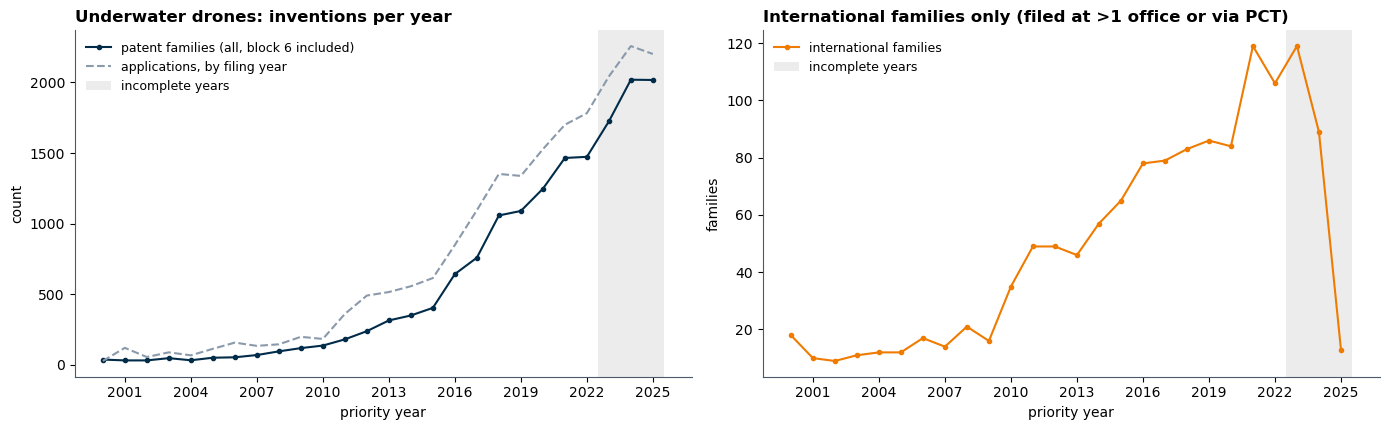

,2000,2005,2010,2015,2018,2020,2021,2022,2023,2024,2025
families · all,38,51,137,404,1058,1247,1465,1473,1724,2019,2017
families · without block-6-only,31,37,103,287,861,1005,1131,1137,1277,1501,1410
families · international,18,12,35,65,83,84,119,106,119,89,13
applications (filing year),28,114,184,615,1352,1527,1700,1782,2042,2257,2201


In [4]:
years = np.arange(YEAR_MIN, YEAR_MAX + 1)
vol = pd.DataFrame(index=years)
for name, ids in SAMPLES.items():
    vol[f"families · {name}"] = fam[fam["docdb_family_id"].isin(ids)].groupby("family_year").size()
vol["applications (filing year)"] = apps[apps["in_appln_window"]].groupby("appln_filing_year").size()
vol = vol.fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
ax.plot(vol.index, vol["families · all"], marker="o", ms=3, color=NAVY, label="patent families (all, block 6 included)")
ax.plot(vol.index, vol["applications (filing year)"], ls="--", color=MID, label="applications, by filing year")
shade(ax); ax.legend(frameon=False, fontsize=9); ax.set(title="Underwater drones: inventions per year", xlabel="priority year", ylabel="count")
ax = axes[1]
ax.plot(vol.index, vol["families · international"], marker="o", ms=3, color=ORANGE, label="international families")
shade(ax); ax.legend(frameon=False, fontsize=9)
ax.set(title="International families only (filed at >1 office or via PCT)", xlabel="priority year", ylabel="families")
plt.tight_layout(); save(fig, "s1_volume"); plt.show()
vol.loc[[2000, 2005, 2010, 2015, 2018, 2020, 2021, 2022, 2023, 2024, 2025]].T

**Growth versus patenting overall.** Compound annual growth rate (CAGR) on complete years only, in two windows:
the whole period (2000–2022) and the last decade (2012–2022). The index chart puts the three series at 100 in 2012.
The second table is the measure of Tutorial 0 (nb 02 §7.2), at both levels: growth (%) from the first year to the
last complete year, *(count in 2022 − count in 2000) / count in 2000*. The sector had only a few dozen families in
2000, so this percentage is huge and unstable: we report it for comparability with the tutorial and read the CAGR
from 2012 (and the 3-year averages below) as the headline.

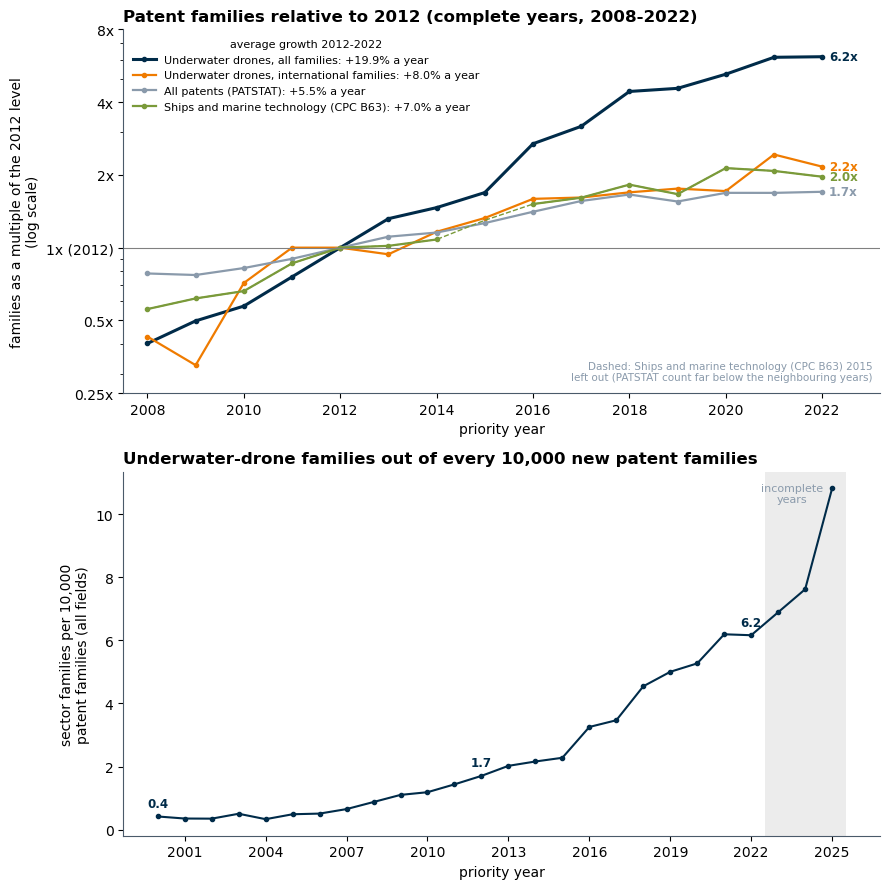

,families 2012,families 2022,CAGR 2000-2022,CAGR 2012-2022
Underwater drones (all),239,"1,473",18.1%,19.9%
Underwater drones (without b6-only),183,"1,137",17.8%,20.0%
Underwater drones (international),49,106,8.4%,8.0%
all patents,"1,403,316","2,389,326",4.5%,5.5%
neighbour B63 (ships),"5,074","9,973",8.2%,7.0%


In [5]:
b = bench_f.set_index("year")
series = {"Underwater drones (all)": vol["families · all"], "Underwater drones (without b6-only)": vol["families · without block-6-only"],
          "Underwater drones (international)": vol["families · international"],
          "all patents": b["all patents"], "neighbour B63 (ships)": b["neighbour B63"]}
rows = {}
for name, s in series.items():
    rows[name] = {"families 2012": s.loc[2012], f"families {LAST}": s.loc[LAST],
                  f"CAGR 2000-{LAST}": cagr(s.loc[2000], s.loc[LAST], LAST - 2000),
                  f"CAGR 2012-{LAST}": cagr(s.loc[2012], s.loc[LAST], LAST - 2012)}
growth = pd.DataFrame(rows).T
ba = bench_a.set_index("year")
t0_series = {("families", "Underwater drones"): vol["families · all"], ("families", "all patents"): b["all patents"],
             ("applications", "Underwater drones"): vol["applications (filing year)"]}
if "all patents" in ba.columns:
    t0_series[("applications", "all patents")] = ba["all patents"]
growth_t0 = pd.DataFrame({k: {f"count in {YEAR_MIN}": v.loc[YEAR_MIN], f"count in {LAST}": v.loc[LAST],
                              f"growth {YEAR_MIN}-{LAST} (%)": (v.loc[LAST] / v.loc[YEAR_MIN] - 1) * 100}
                          for k, v in t0_series.items()}).T
growth_t0.index.names = ["level", "scope"]
save_table(growth_t0, "growth_tutorial0")
KEY["growth_2000_last_pct_families_sector"] = float(growth_t0.loc[("families", "Underwater drones"), f"growth {YEAR_MIN}-{LAST} (%)"])
display(growth_t0.style.format({f"count in {YEAR_MIN}": "{:,.0f}", f"count in {LAST}": "{:,.0f}",
                                f"growth {YEAR_MIN}-{LAST} (%)": "{:+,.0f}%"}).set_caption("Tutorial 0 measure: growth from the first year, both levels"))
KEY["families_total"] = int(len(fam)); KEY["families_complete_years"] = int((fam.family_year <= LAST).sum())
KEY["cagr_2012_last_sector"] = float(growth.loc["Underwater drones (all)", f"CAGR 2012-{LAST}"])
KEY["cagr_2012_last_all_patents"] = float(growth.loc["all patents", f"CAGR 2012-{LAST}"])
KEY["cagr_2012_last_B63"] = float(growth.loc["neighbour B63 (ships)", f"CAGR 2012-{LAST}"])

# the index stops at the last complete year (LAST): truncated years would show a fake collapse of the growth
idx = pd.DataFrame({k: v.loc[2008:LAST] / v.loc[2012] * 100 for k, v in series.items() if "b6" not in k})
# a benchmark year far below its neighbours is a data gap in PATSTAT, not a trend (see the check below): the point
# is dropped and the line bridges it with a dashed segment; growth rates use the end years only, so they do not change
gaps_ = {}
for k in ("all patents", "neighbour B63 (ships)"):
    s_ = idx[k]
    around_ = pd.concat([s_.shift(1), s_.shift(-1), s_.shift(2), s_.shift(-2)], axis=1).median(axis=1)
    bad_ = list(s_[(s_ / around_) < 0.75].index)
    if bad_:
        gaps_[k] = bad_
        idx.loc[bad_, k] = np.nan
KEY["benchmark_gap_years"] = {k: [int(y) for y in v] for k, v in gaps_.items()}
# the two panels are stacked (one above the other): the figure fits the half-slide frame of the deck
# Top: each series as a multiple of its own 2012 level (1x = 2012), so series of very different size share one axis;
# log scale, so equal slopes mean equal growth rates. Bottom: the sector out of every 10,000 patent families.
fig, axes = plt.subplots(2, 1, figsize=(9, 9))
mult = idx / 100
short_ = {"Underwater drones (all)": "Underwater drones, all families",
          "Underwater drones (international)": "Underwater drones, international families",
          "all patents": "All patents (PATSTAT)", "neighbour B63 (ships)": "Ships and marine technology (CPC B63)"}
for k, c in zip(mult.columns, [NAVY, ORANGE, MID, GREEN]):
    s_ = mult[k]
    if k in gaps_:
        axes[0].plot(s_.interpolate(limit_area="inside").index, s_.interpolate(limit_area="inside"), color=c, lw=1, ls="--")
    g_ = growth.loc[k, f"CAGR 2012-{LAST}"]
    axes[0].plot(s_.index, s_, marker="o", ms=3, color=c, lw=2.2 if k.startswith("Underwater drones (all)") else 1.6,
                 label=f"{short_.get(k, k)}: {g_:+.1%} a year")
    axes[0].annotate(f"{s_.loc[LAST]:.1f}x", (LAST, s_.loc[LAST]), xytext=(5, 0), textcoords="offset points",
                     va="center", fontsize=8.5, color=c, fontweight="bold")
axes[0].set_yscale("log"); axes[0].axhline(1, color="grey", lw=0.8)
axes[0].set_yticks([0.25, 0.5, 1, 2, 4, 8])
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: "1x (2012)" if v == 1 else f"{v:g}x"))
axes[0].yaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_xlim(2007.5, LAST + 1.2)
axes[0].set(title=f"Patent families relative to 2012 (complete years, 2008-{LAST})",
            xlabel="priority year", ylabel="families as a multiple of the 2012 level\n(log scale)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left", title="average growth 2012-" + str(LAST), title_fontsize=8)
if gaps_:
    axes[0].text(0.99, 0.03, "Dashed: " + "; ".join(f"{short_.get(k, k)} {', '.join(map(str, v))}" for k, v in gaps_.items())
                 + "\nleft out (PATSTAT count far below the neighbouring years)", transform=axes[0].transAxes, fontsize=7.5,
                 color=MID, ha="right", va="bottom")
per10k = b["sector share of all (per mille)"] * 10        # per mille -> per 10,000
axes[1].plot(per10k.index, per10k, marker="o", ms=3, color=NAVY)
shade(axes[1]); axes[1].text(LAST + 1.5, axes[1].get_ylim()[1] * 0.97, "incomplete\nyears", ha="center", va="top",
                             fontsize=8, color=MID)
for y_ in (2000, 2012, LAST):
    axes[1].annotate(f"{per10k.loc[y_]:.1f}", (y_, per10k.loc[y_]), xytext=(0, 7), textcoords="offset points",
                     ha="center", fontsize=8.5, color=NAVY, fontweight="bold")
axes[1].set(title="Underwater-drone families out of every 10,000 new patent families",
            xlabel="priority year", ylabel="sector families per 10,000\npatent families (all fields)")
plt.tight_layout(); save(fig, "s1_growth_vs_benchmarks"); plt.show()
growth.style.format({c: "{:.1%}" for c in growth.columns if "CAGR" in c} | {c: "{:,.0f}" for c in growth.columns if "families" in c})

**Reading.** The sector grows much faster than patenting overall and than its neighbouring field: its share of all
families rises year after year, so underwater drones are *gaining weight* in technology, not just riding the general
boom of (Chinese) patenting. The international series grows far less: most of the boom is domestic Chinese filing
(Section 1.4). Report both series side by side in the deck.

**Dating, PCT and robust growth.** Three checks behind the headline growth:

- **dating**: the same patents counted by priority, filing and first-publication year. Dating by publication shifts
  the curve about 18 months to the right and makes the recent years look complete; dating by priority places each
  invention at its origin; the family curve is lower because every invention counts once;
- **PCT**: families and applications that use the PCT route (an international filing intention);
- **robust growth**: the sector had a few dozen families in 2000, so growth between two end years is huge and unstable.
  The table adds the growth of **3-year averages** and the CAGR from `BASE_YEAR`, and the share of the sector in all
  patents at **both levels** (families and applications), the most robust measure of "gaining weight". A sanity check
  prints any benchmark year far from its neighbours (a data problem, not a trend).

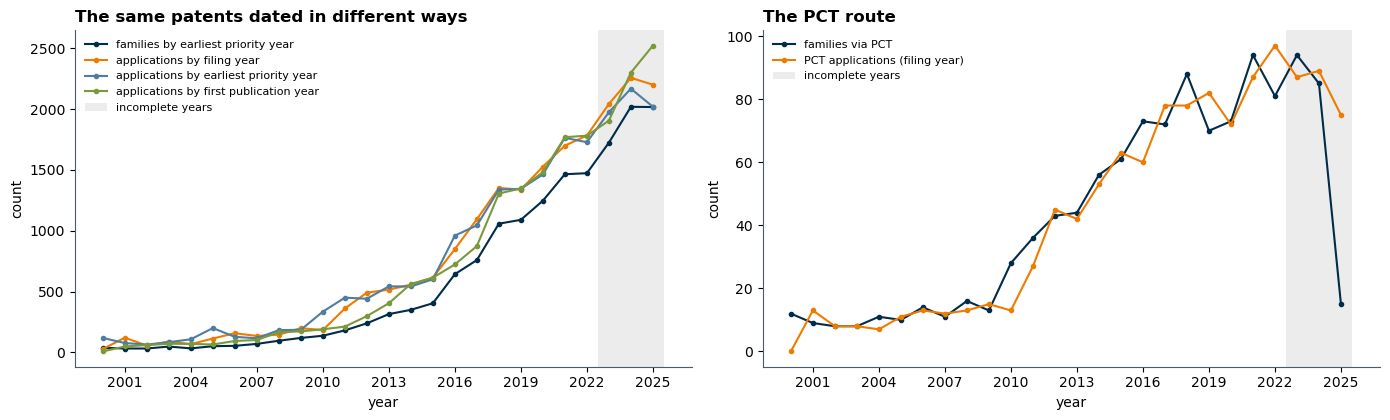

CHECK benchmark 'neighbour B63': 2015 is 3,567, 0.54× the median of the surrounding years


,growth of 3-year averages 2000-2002 → 2020-2022,CAGR 2012-2022
Underwater drones (all),+4002.9%,+19.9%
Underwater drones (without b6-only),+4206.6%,+20.0%
Underwater drones (international),+735.1%,+8.0%
all patents,+158.8%,+5.5%
neighbour B63 (ships),+477.0%,+7.0%


,families (‰ of all patent families),applications (‰ of all applications)
year,,
2012,0.170,0.220
2017,0.347,0.352
2022,0.616,0.535


In [6]:
per_year = lambda df, col: df.groupby(col).size().reindex(years, fill_value=0)
apps_w = apps[apps["in_appln_window"].astype(str).str.lower().eq("true")]
prio_col = "earliest_filing_year" if "earliest_filing_year" in apps_w else "family_year"
dating = {"families by earliest priority year": vol["families · all"],
          "applications by filing year": vol["applications (filing year)"],
          "applications by earliest priority year": per_year(apps_w[apps_w[prio_col].between(YEAR_MIN, YEAR_MAX)], prio_col)}
if "earliest_publn_year" in apps_w:
    dating["applications by first publication year"] = per_year(apps_w[apps_w["earliest_publn_year"].between(YEAR_MIN, YEAR_MAX)], "earliest_publn_year")
pct_fam = per_year(fam[fam["via_pct"]], "family_year")
pct_app = per_year(apps_w[apps_w["is_pct"].astype(str).str.lower().eq("true")], "appln_filing_year")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for (lab_, s), c in zip(dating.items(), [NAVY, ORANGE, BLUE, GREEN]):
    axes[0].plot(s.index, s.values, marker="o", ms=3, color=c, label=lab_)
axes[0].set(title="The same patents dated in different ways", xlabel="year", ylabel="count")
axes[1].plot(pct_fam.index, pct_fam.values, marker="o", ms=3, color=NAVY, label="families via PCT")
axes[1].plot(pct_app.index, pct_app.values, marker="o", ms=3, color=ORANGE, label="PCT applications (filing year)")
axes[1].set(title="The PCT route", xlabel="year", ylabel="count")
for ax in axes:
    shade(ax); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); save(fig, "s1_dating_pct"); plt.show()

rows = {}
for name, s in series.items():
    s = s.astype(float).reindex(years)
    a3, b3 = s.loc[YEAR_MIN:YEAR_MIN + 2].mean(), s.loc[LAST - 2:LAST].mean()
    rows[name] = {f"growth of 3-year averages {YEAR_MIN}-{YEAR_MIN + 2} → {LAST - 2}-{LAST}": b3 / a3 - 1 if a3 else np.nan,
                  f"CAGR {BASE_YEAR}-{LAST}": cagr(s.loc[BASE_YEAR], s.loc[LAST], LAST - BASE_YEAR)}
growth_robust = pd.DataFrame(rows).T
share_levels = pd.DataFrame({"families (‰ of all patent families)": b["sector share of all (per mille)"]})
if "sector share of all (per mille)" in bench_a.columns:
    share_levels["applications (‰ of all applications)"] = bench_a.set_index("year")["sector share of all (per mille)"]
elif {"all patents"} <= set(bench_a.columns):
    share_levels["applications (‰ of all applications)"] = vol["applications (filing year)"] / bench_a.set_index("year")["all patents"] * 1000
for col in [c for c in bench_f.columns if c == "all patents" or str(c).startswith("neighbour")]:
    s = bench_f.set_index("year")[col].astype(float).loc[YEAR_MIN:LAST]
    around = pd.concat([s.shift(1), s.shift(-1), s.shift(2), s.shift(-2)], axis=1).median(axis=1)
    for y_, r_ in (s / around)[((s / around) < 0.75) | ((s / around) > 1.25)].dropna().items():
        print(f"CHECK benchmark '{col}': {y_} is {s.loc[y_]:,.0f}, {r_:.2f}× the median of the surrounding years")
save_table(growth_robust, "growth_robust"); save_table(share_levels, "share_of_all_patents_levels")
display(growth_robust.style.format("{:+.1%}", na_rep="–"))
share_levels.loc[[BASE_YEAR, BASE_YEAR + 5, LAST]].round(3)

### 1.1.1 Events behind the trend (historical and regulatory context)

Patent series react to the economy and to policy (IM_Theory_3: *"you can add more data: regulatory and historical
events"*). The events below are marked on the families per year, split by origin, because Chinese filings respond to
Chinese policy and the rest of the world to markets. The **oil & gas share** (families classified in E21B drilling,
G01V geophysics or F16L pipelines) follows the offshore market, the historical origin of underwater robotics. The
table compares the average families per year in the three years before each event with the three years from it.
Correlation, not causation: the events are context for the reading, and the dates must be checked on the sources
listed in the appendix before they go in the deck.

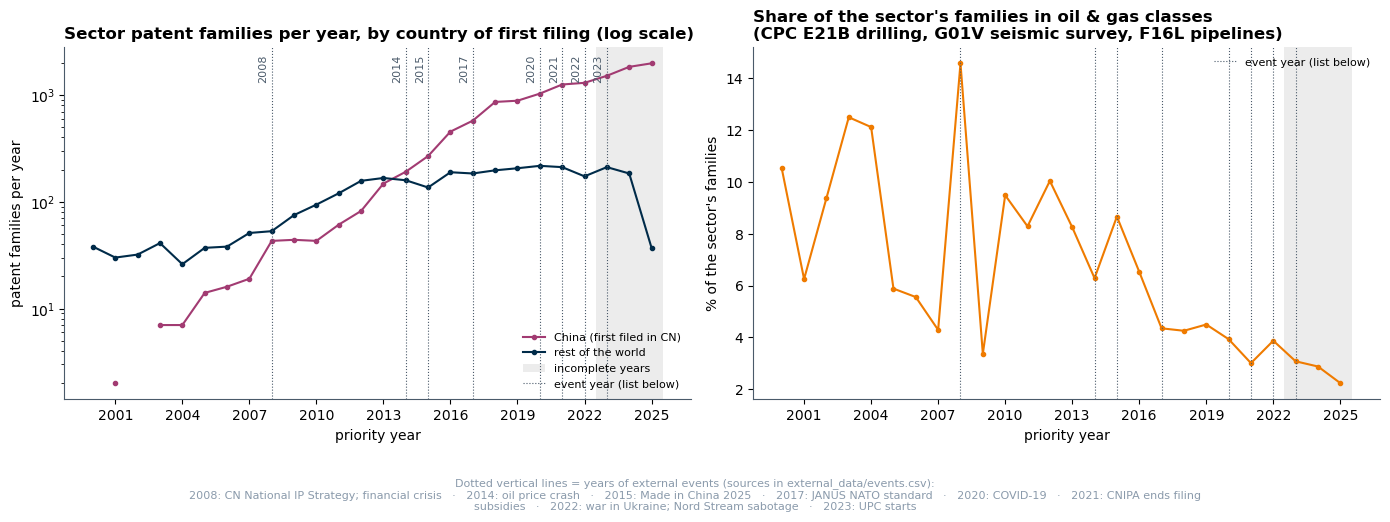

,event,scope,China: after / before,rest: after / before,oil & gas share before,oil & gas share after
year,,,,,,
2008,CN National IP Strategy; financial crisis,CN / world,2.65×,1.76×,5.2%,9.1%
2014,oil price crash,offshore,3.14×,1.09×,8.9%,7.2%
2015,Made in China 2025,CN,3.08×,1.05×,8.2%,6.5%
2017,JANUS NATO standard,standards,2.54×,1.21×,7.2%,4.4%
2020,COVID-19,world,1.54×,1.02×,4.4%,3.6%
2021,CNIPA ends filing subsidies,CN,– (incomplete years),– (incomplete years),4.2%,– (incomplete years)
2022,war in Ukraine; Nord Stream sabotage,defence / seabed security,– (incomplete years),– (incomplete years),3.8%,– (incomplete years)
2023,UPC starts,EU,– (incomplete years),– (incomplete years),3.6%,– (incomplete years)


In [7]:
EVENTS = [   # (priority year, short label, scope) – VERIFY each date and source before using it in the deck
    (2008, "Financial crisis; China National IP Strategy (Jun)", "world / CN"),
    (2014, "Oil price crash (H2 2014)", "offshore"),
    (2015, "Made in China 2025 (May): marine equipment a priority", "CN"),
    (2020, "COVID-19", "world"),
    (2021, "CNIPA ends subsidies for patent filings (Jun)", "CN"),
    (2022, "War in Ukraine (Feb); Nord Stream sabotage (Sep)", "defence / seabed security"),
    (2023, "Unitary Patent and UPC start (1 Jun)", "EU"),
]
if (EXT / "events.csv").exists():   # verified dates and sources (external_data/events.csv): one label per year
    ev_ext = pd.read_csv(EXT / "events.csv")
    ev_ext = ev_ext[ev_ext.in_chart.eq("yes")]
    EVENTS = [(int(y), "; ".join(g.short_label), " / ".join(g.scope.unique()))
              for y, g in ev_ext.groupby("year")]
    unverified = ev_ext[ev_ext.verified.astype(str).str.startswith("no")]
    if len(unverified):
        print("Events still without a source:", "; ".join(f"{r.year} {r.event[:40]}" for r in unverified.itertuples()))
OIL_GAS = {"E21B", "G01V", "F16L"}
yr = fam[fam.family_year.between(2000, YEAR_MAX)]
by_origin = pd.DataFrame({"China (first filed in CN)": yr[yr.first_office.eq("CN")].groupby("family_year").size(),
                          "rest of the world": yr[~yr.first_office.eq("CN")].groupby("family_year").size()}).fillna(0)
og_fam = set(fsub.loc[fsub.subclass.isin(OIL_GAS), "docdb_family_id"])
oil_share = yr.assign(og=yr.docdb_family_id.isin(og_fam)).groupby("family_year")["og"].mean()

ev_rows = []
for y, lab, scope in EVENTS:
    if y + 2 > LAST:     # not enough complete years after the event
        ev_rows.append({"year": y, "event": lab, "scope": scope, "China: after / before": np.nan, "rest: after / before": np.nan,
                        "oil & gas share before": oil_share.loc[y - 3:y - 1].mean(), "oil & gas share after": np.nan})
        continue
    bef, aft = by_origin.loc[y - 3:y - 1].mean(), by_origin.loc[y:y + 2].mean()
    ev_rows.append({"year": y, "event": lab, "scope": scope,
                    "China: after / before": aft.iloc[0] / bef.iloc[0] if bef.iloc[0] else np.nan,
                    "rest: after / before": aft.iloc[1] / bef.iloc[1] if bef.iloc[1] else np.nan,
                    "oil & gas share before": oil_share.loc[y - 3:y - 1].mean(), "oil & gas share after": oil_share.loc[y:y + 2].mean()})
events_tab = pd.DataFrame(ev_rows).set_index("year")
KEY["oil_gas_share_2011_2013"] = float(oil_share.loc[2011:2013].mean()); KEY["oil_gas_share_2020_2022"] = float(oil_share.loc[2020:2022].mean())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ax = axes[0]
ax.plot(by_origin.index, by_origin.iloc[:, 0].replace(0, np.nan), color=RED, marker="o", ms=3, label=by_origin.columns[0])
ax.plot(by_origin.index, by_origin.iloc[:, 1], color=NAVY, marker="o", ms=3, label=by_origin.columns[1])
ax.set_yscale("log"); ax.set(title="Sector patent families per year, by country of first filing (log scale)",
                              xlabel="priority year", ylabel="patent families per year")
ax2 = axes[1]
ax2.plot(oil_share.index, oil_share * 100, color=ORANGE, marker="o", ms=3, label="share in oil & gas classes")
ax2.set(title="Share of the sector's families in oil & gas classes\n(CPC E21B drilling, G01V seismic survey, F16L pipelines)",
        xlabel="priority year", ylabel="% of the sector's families")
for a in axes:
    shade(a)
    for i, (y, lab, _) in enumerate(EVENTS):
        a.axvline(y, color=GREY, lw=0.8, ls=":")
        if a is ax:   # vertical labels at the top: neighbouring years do not overlap
            a.text(y - 0.15, 0.98, f"{y}", transform=a.get_xaxis_transform(), rotation=90, fontsize=8,
                   color=GREY, ha="right", va="top")
import textwrap
from matplotlib.lines import Line2D
ev_handle = Line2D([], [], color=GREY, lw=0.8, ls=":")
h_, l_ = ax.get_legend_handles_labels()
ax.legend(h_ + [ev_handle], l_ + ["event year (list below)"], frameon=False, fontsize=8, loc="lower right")
ax2.legend([ev_handle], ["event year (list below)"], frameon=False, fontsize=8, loc="upper right")
# the dotted lines mark the years of external events (external_data/events.csv, each with source and URL)
ev_txt = "   ·   ".join(f"{y}: {lab}" for y, lab, _ in EVENTS)
fig.text(0.5, 0.005, "Dotted vertical lines = years of external events (sources in external_data/events.csv):\n"
         + textwrap.fill(ev_txt, 190), ha="center", va="bottom", fontsize=8, color=MID)
plt.tight_layout(rect=(0, 0.11, 1, 1)); save(fig, "s1_events"); plt.show()
events_tab.style.format({"China: after / before": "{:.2f}×", "rest: after / before": "{:.2f}×",
                         "oil & gas share before": "{:.1%}", "oil & gas share after": "{:.1%}"}, na_rep="– (incomplete years)")

### 1.1.2 Patents vs market: does technology run ahead of demand?

Patent counts measure *inventive activity*, not sales: a technology can be patented years before a market exists
(technology push) or a market can grow on mature, unpatented designs (IM_Theory_3: landscapes answer *technology*
and *economic* questions, and the second needs non-patent data). We compare the growth of the families with the
market estimates of commercial reports (`external_data/market_size.csv`, sources and access date in the file).

Three cautions, to say on the slide: (i) the reports disagree (we show the **range**, not one number); (ii) their
CAGRs are **forecasts** for 2024-2035, while the patent CAGR is **observed** over `BASE_YEAR`-`LAST`: the comparison
is between two speeds, not a causal link; (iii) the scope differs (underwater drones vs UUV vs AUV only).

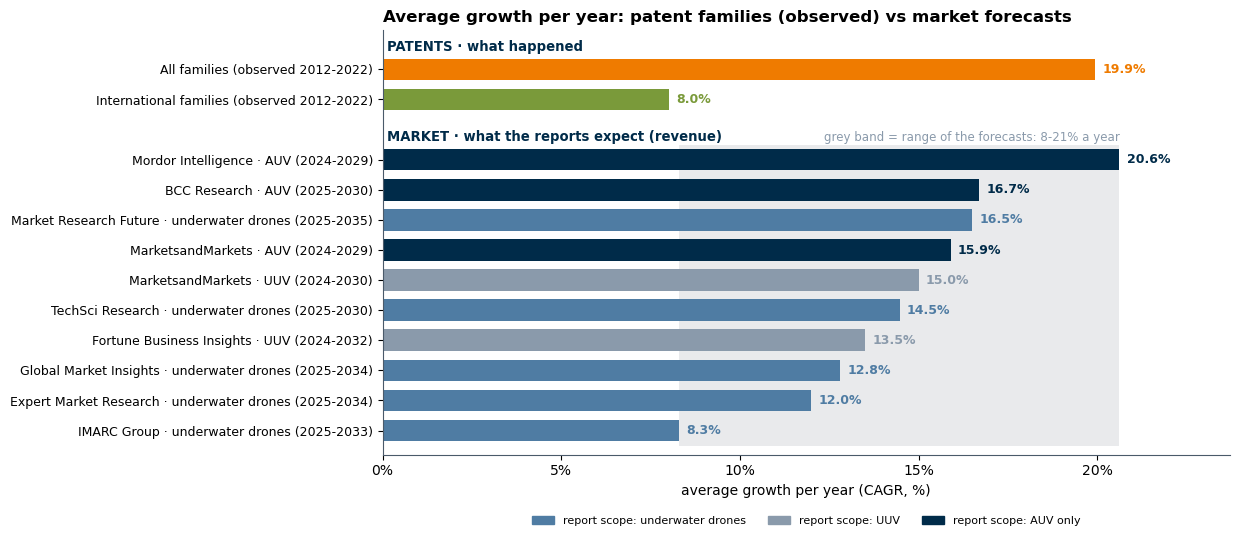

Underwater drone market 2024: 4.2-5.1 bn USD (5 reports); forecast CAGR 8.3%-16.5% (median 12.8%). patent families all: 19.9%/yr; patent families without block-6-only: 20.0%/yr; patent families international: 8.0%/yr
  all: patents grow faster than the range of the underwater-drone forecasts
  without block-6-only: patents grow faster than the range of the underwater-drone forecasts
  international: patents grow slower than the range of the underwater-drone forecasts


,"2024 size, min (USD bn)","2024 size, max (USD bn)",sources,forecast CAGR min,forecast CAGR median,forecast CAGR max
scope,,,,,,
AUV,–,–,–,15.9%,16.7%,20.6%
UUV,3.34,4.80,2.000000,13.5%,14.3%,15.0%
underwater drones,4.20,5.13,5.000000,8.3%,12.8%,16.5%


In [8]:
if (EXT / "market_size.csv").exists():
    mk = pd.read_csv(EXT / "market_size.csv")
    mk_use = mk[mk.use_in_range.eq("yes") & mk.unit.eq("USD bn")]
    base = mk_use[mk_use.estimate_or_forecast.eq("estimate") & mk_use.year.astype(str).eq("2024") & mk_use.segment.eq("all")]
    drones = base[base.scope.eq("underwater drones")]        # the scope of our sector: headline numbers
    cg = mk_use.dropna(subset=["cagr"]).drop_duplicates(["source", "scope", "cagr"])
    cg = cg[pd.to_numeric(cg.cagr, errors="coerce").notna()].assign(cagr=lambda d: d.cagr.astype(float))
    pat_cagr = {name: cagr(vol[f"families · {name}"].get(BASE_YEAR, np.nan), vol[f"families · {name}"].get(LAST, np.nan), LAST - BASE_YEAR)
                for name in SAMPLES}
    mkt_tab = (base.groupby("scope")["value"].agg(["min", "max", "count"])
               .rename(columns={"min": "2024 size, min (USD bn)", "max": "2024 size, max (USD bn)", "count": "sources"}))
    mkt_tab = mkt_tab.join(cg.groupby("scope")["cagr"].agg(["min", "median", "max"])
                           .rename(columns={"min": "forecast CAGR min", "median": "forecast CAGR median", "max": "forecast CAGR max"}), how="outer")
    cg_d = cg[cg.scope.eq("underwater drones")]
    KEY["market_2024_min"], KEY["market_2024_max"] = float(drones.value.min()), float(drones.value.max())
    KEY["market_cagr_min"], KEY["market_cagr_max"], KEY["market_cagr_median"] = float(cg_d.cagr.min()), float(cg_d.cagr.max()), float(cg_d.cagr.median())
    KEY.update({f"patent_cagr_{BASE_YEAR}_{LAST}_{k.replace(' ', '_')}": float(v) for k, v in pat_cagr.items()})
    save_table(mkt_tab, "market_size_range"); save_table(cg, "market_cagr_by_source", index=False)

    # One bar chart, one unit: average growth per year (CAGR, %). Top block: what patents DID (observed, 2012-LAST);
    # bottom block: what the market is EXPECTED to do (revenue forecasts of the reports). Values are written on the bars.
    cg_ = cg.sort_values("cagr", ascending=False)
    rows_ = [(f"All families (observed {BASE_YEAR}-{LAST})", pat_cagr["all"], ORANGE),
             (f"International families (observed {BASE_YEAR}-{LAST})", pat_cagr["international"], GREEN)]
    rows_ += [(f"{r.source} · {r.scope} ({r.cagr_period})", r.cagr,
               {"underwater drones": BLUE, "UUV": MID, "AUV": NAVY}.get(r.scope, GREY)) for r in cg_.itertuples()]
    ypos = list(range(2)) + [i + 3 for i in range(len(cg_))]          # a blank row between the two blocks
    fig, ax = plt.subplots(figsize=(12.5, 0.30 * len(ypos) + 1.9))
    for (lab_, v, c), y_ in zip(rows_, ypos):
        ax.barh(y_, v * 100, color=c, height=0.72, zorder=2)
        ax.text(v * 100 + 0.2, y_, f"{v:.1%}", va="center", fontsize=9, color=c, fontweight="bold")
    ax.set_yticks(ypos, [r[0] for r in rows_], fontsize=9); ax.set_ylim(ypos[-1] + 0.8, -1.3)
    lo_, hi_ = cg_.cagr.min() * 100, cg_.cagr.max() * 100
    # grey band only behind the MARKET block: it is the spread of the forecasts, not a property of the patents
    ax.fill_betweenx([ypos[2] - 0.5, ypos[-1] + 0.5], lo_, hi_, color=GREY, alpha=0.12, lw=0, zorder=0)
    ax.text(hi_, 2.25, f"grey band = range of the forecasts: {lo_:.0f}-{hi_:.0f}% a year", ha="right", va="center",
            fontsize=8.5, color=MID)
    tr_ = ax.get_yaxis_transform()     # x in axes units, y in data units
    ax.text(0.005, -0.75, "PATENTS · what happened", transform=tr_, ha="left", va="center", fontsize=9.5,
            fontweight="bold", color=NAVY)
    ax.text(0.005, 2.25, "MARKET · what the reports expect (revenue)", transform=tr_, ha="left", va="center",
            fontsize=9.5, fontweight="bold", color=NAVY)
    ax.set_xlim(0, max(v for _, v, _ in rows_) * 100 * 1.15)
    ax.set(title="Average growth per year: patent families (observed) vs market forecasts",
           xlabel="average growth per year (CAGR, %)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
    from matplotlib.patches import Patch
    ax.legend([Patch(color=BLUE), Patch(color=MID), Patch(color=NAVY)],
              ["report scope: underwater drones", "report scope: UUV", "report scope: AUV only"],
              frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
    plt.tight_layout(); save(fig, "s1_patents_vs_market"); plt.show()
    print(f"Underwater drone market 2024: {KEY['market_2024_min']:.1f}-{KEY['market_2024_max']:.1f} bn USD ({len(drones)} reports); "
          f"forecast CAGR {KEY['market_cagr_min']:.1%}-{KEY['market_cagr_max']:.1%} (median {KEY['market_cagr_median']:.1%}). "
          + "; ".join(f"patent families {name}: {v:.1%}/yr" for name, v in pat_cagr.items()))
    for name, v in pat_cagr.items():
        side = "faster than" if v > KEY["market_cagr_max"] else ("slower than" if v < KEY["market_cagr_min"] else "within")
        print(f"  {name}: patents grow {side} the range of the underwater-drone forecasts")
    display(mkt_tab.style.format({c: "{:.1%}" for c in mkt_tab.columns if "CAGR" in c} | {c: "{:.2f}" for c in mkt_tab.columns if "USD" in c}, na_rep="–"))
else:
    print(f"{EXT / 'market_size.csv'} not found: section skipped (see external_data/README.md)")

**Reading.** If the patent families of all origins grow faster than any market forecast while the international
ones grow at market speed, the gap is the Chinese filing boom (1.4), not demand: inventive activity runs ahead of
sales in China, and in line with sales elsewhere. A market of about 4-5 bn USD growing 8-17% a year is the
economic counterpart of the technological trajectory of 1.2 (growth phase, no inflection yet). The AUV segment, the
one closest to the client's acquisitions (Graal Tech), has the highest forecasts. The client itself sizes the wider
underwater market at 155 bn EUR cumulated over 2026-2030 (broader scope, not comparable with the drone reports).

## 1.2 Life cycle: where is the sector on its technological trajectory?

Technologies typically follow an **S-curve**: slow emergence, fast growth, then saturation as a dominant design
emerges and effort moves from product to process innovation (Utterback & Abernathy, 1975; lecture on
technological trajectories). Two complementary measures:

1. a **logistic fit** of the cumulative number of families, $N(t)=K/(1+e^{-r(t-t_0)})$: $t_0$ is the inflection year
   (fastest growth), $K$ the saturation level. Fitted on complete years only; a fit whose inflection lies beyond the
   data means *no inflection observed yet* (the sector is still in the growth phase), and $K$ is then not reliable;
2. the **Innovation Maturity Matrix** of the WIPO (2024) SDG report (IM_Theory_3): for each subfield, its
   *intensity* (number of families) and its *relative recency*
   $R=\sum_i w_i\, i/(n\sum_i w_i)$ ($i$ = year index, $w_i$ = families of year $i$), divided by the $R$ of the whole
   sector. Many and recent = *current hot topics*; few and recent = *emerging*; older = *mature*.

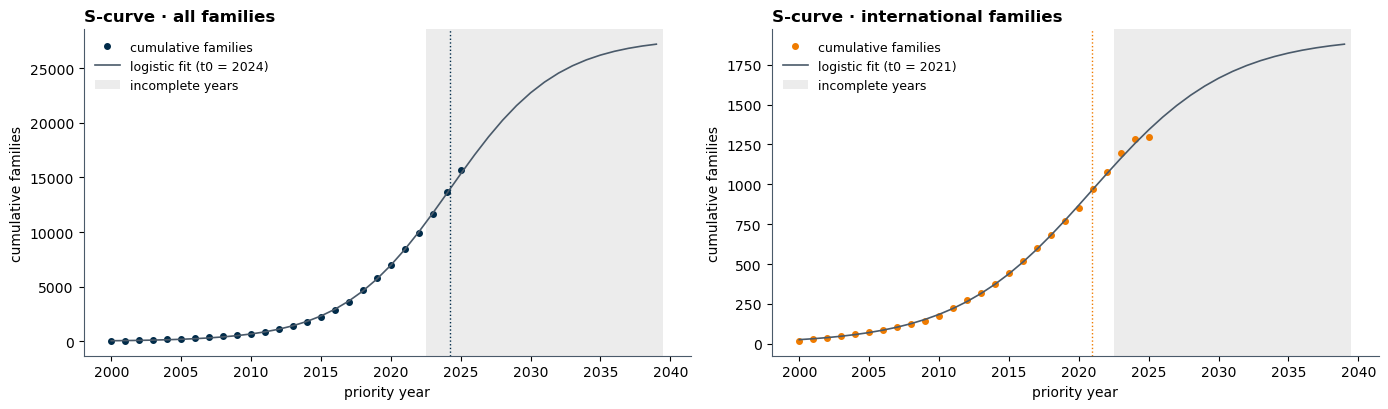

,"K (saturation, families)",r (growth rate),t0 (inflection year),R2 on annual counts,share of K reached,inflection observed
all,"27,765",0.26,2024.2,0.99,36%,False
without block-6-only,"19,237",0.28,2023.4,0.99,40%,False
international,"1,925",0.21,2020.9,0.95,56%,True
"all, up to 2023 (sensitivity)","26,961",0.26,2024.0,0.99,43%,False
"all, including 2023-2025 (lower bound)","30,973",0.25,2024.9,0.99,51%,True


In [9]:
def logistic(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))

def fit_s_curve(yearly, last=LAST):
    s = yearly.loc[:last].cumsum()
    t = s.index.values.astype(float); y = s.values.astype(float)
    p0 = [y[-1] * 2, 0.3, t[-1]]
    bounds = ([y[-1], 0.01, t[0]], [y[-1] * 50, 2.0, t[-1] + 30])
    p, _ = curve_fit(logistic, t, y, p0=p0, bounds=bounds, maxfev=20000)
    # fit quality on the ANNUAL counts: an R2 on a cumulative series is always close to 1 and says nothing
    obs = yearly.loc[:last].values.astype(float); fit = logistic(t, *p) - logistic(t - 1, *p)
    r2 = 1 - np.sum((obs - fit) ** 2) / np.sum((obs - obs.mean()) ** 2)
    return {"K (saturation, families)": p[0], "r (growth rate)": p[1], "t0 (inflection year)": p[2], "R2 on annual counts": r2,
            "share of K reached": y[-1] / p[0], "inflection observed": p[2] <= last}

life = {}
for name in SAMPLES:
    life[name] = fit_s_curve(vol[f"families · {name}"])
life[f"all, up to {LAST + 1} (sensitivity)"] = fit_s_curve(vol["families · all"], last=LAST + 1)
life["all, including 2023-2025 (lower bound)"] = fit_s_curve(vol["families · all"], last=YEAR_MAX)
life = pd.DataFrame(life).T
KEY["s_curve_t0_all"] = float(life.loc["all", "t0 (inflection year)"])
KEY["s_curve_t0_international"] = float(life.loc["international", "t0 (inflection year)"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, name, c in zip(axes, ["all", "international"], [NAVY, ORANGE]):
    s = vol[f"families · {name}"].cumsum()
    p = life.loc[name, ["K (saturation, families)", "r (growth rate)", "t0 (inflection year)"]].astype(float).values
    tt = np.arange(YEAR_MIN, YEAR_MAX + 15)
    ax.plot(s.index, s.values, "o", ms=4, color=c, label="cumulative families")
    ax.plot(tt, logistic(tt, *p), color=GREY, lw=1.2, label=f"logistic fit (t0 = {p[2]:.0f})")
    ax.axvline(p[2], color=c, ls=":", lw=1)
    shade(ax, right=YEAR_MAX + 14); ax.set(title=f"S-curve · {name} families", xlabel="priority year", ylabel="cumulative families")
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); save(fig, "s1_s_curve"); plt.show()
life.style.format({"K (saturation, families)": "{:,.0f}", "r (growth rate)": "{:.2f}", "t0 (inflection year)": "{:.1f}",
                   "R2 on annual counts": "{:.2f}", "share of K reached": "{:.0%}"})

**Reading and caveat.** Read $t_0$ and the share of $K$ reached, not $K$ itself: extrapolating a logistic from a
curve that has not bent yet is fragile (Ernst, 1997, warns that patent S-curves identify the *phase*, not the
final size). If the international curve bends earlier than the domestic one, the *quality* frontier of the sector is
maturing while the volume keeps growing.

**A process-innovation proxy.** In the Utterback–Abernathy model, the mature phase shifts effort from *product* to
*process* innovation. A cheap proxy is the share of families whose English title describes a *method / process*
rather than a device. It is only a proxy (Chinese titles often read "...method and system"), so read the trend, not
the level.

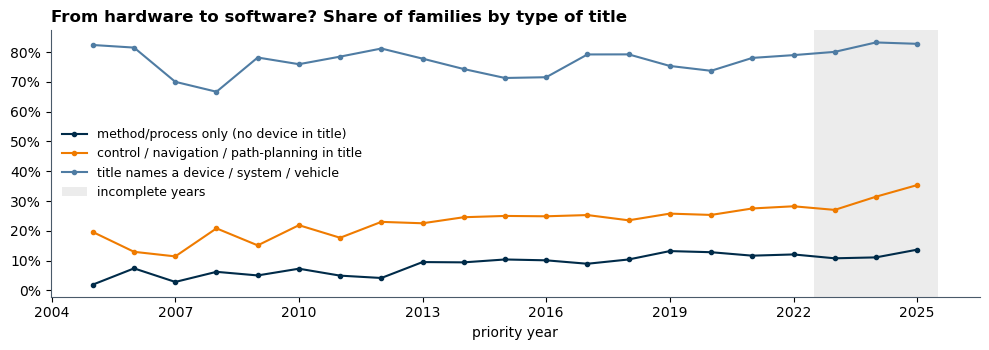

,is_method_title,is_control_title,is_product_title
family_year,,,
2005,0.020,0.196,0.824
2010,0.073,0.219,0.759
2015,0.104,0.250,0.713
2018,0.104,0.235,0.792
2020,0.128,0.253,0.737
2022,0.121,0.282,0.790


In [10]:
title = fam["title_en"].fillna(fam["title"]).fillna("").str.lower()
fam["is_method_title"] = title.str.contains(r"\bmethod\b|\bprocess\b") & ~title.str.contains(r"\b(?:device|apparatus|vehicle|robot|system)\b")
fam["is_control_title"] = title.str.contains(r"control|navigat|path|planning|positioning|tracking|localization|formation")
fam["is_product_title"] = title.str.contains(r"\b(?:device|apparatus|system|equipment|vehicle|robot|machine)\b")
proc = fam[fam.family_year.between(2005, YEAR_MAX)].groupby("family_year")[["is_method_title", "is_control_title", "is_product_title"]].mean()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(proc.index, proc["is_method_title"] * 100, marker="o", ms=3, color=NAVY, label="method/process only (no device in title)")
ax.plot(proc.index, proc["is_control_title"] * 100, marker="o", ms=3, color=ORANGE, label="control / navigation / path-planning in title")
ax.plot(proc.index, proc["is_product_title"] * 100, marker="o", ms=3, color=BLUE, label="title names a device / system / vehicle")
shade(ax); ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.legend(frameon=False, fontsize=9)
ax.set(title="From hardware to software? Share of families by type of title", xlabel="priority year")
plt.tight_layout(); save(fig, "s1_process_proxy"); plt.show()
proc.reindex([y for y in (2005, 2010, 2015, 2018, 2020, 2022) if y in proc.index]).round(3)   # years missing in small samples (TEST) are skipped

## 1.3 Technology mix: which technologies make up the field, and how is the mix shifting?

### 1.3.1 CPC subclasses (fractional counting)

Each family is split equally across its CPC subclasses (`family_subclass.csv`), so the shares sum to 100%.
The **Y tagging section** (Y02/Y04/Y10) marks cross-cutting themes (climate, smart grids), not technologies: the mix
uses `weight_tech` of `02_clean`, which leaves them out (otherwise a tag would look like a fast-growing technology);
Y tags are used only where a theme is the point (Y02E energy in the PEST). The application level (every filing split
over its subclasses) is shown next to the family level.
Many subclasses are co-classifications: they show which neighbouring technologies the sector draws on (navigation,
control, AI, sonar...). **The official titles below must be checked on the CPC scheme before they go in the deck**
(https://www.cooperativepatentclassification.org): they are short versions.

In [11]:
CPC_TITLES = {   # short titles: VERIFY against the official CPC scheme before using them in the deck
    "B63G": "Offensive/defensive arrangements on vessels; submarines (incl. unmanned underwater vessels)",
    "B63C": "Launching/docking vessels; life-saving; equipment for working under water; searching for underwater objects",
    "G05D": "Control of non-electric variables (incl. position/course of vehicles, G05D 1)",
    "B63B": "Ships or other waterborne vessels; equipment for shipping",
    "G01C": "Measuring distances, levels or bearings; surveying; navigation",
    "B63H": "Marine propulsion or steering",
    "G01S": "Radio/acoustic direction-finding, navigation, ranging and locating (incl. sonar)",
    "G05B": "Control or regulating systems in general",
    "B25J": "Manipulators; robots",
    "Y02A": "Technologies for adaptation to climate change (tagging)",
    "G06F": "Electric digital data processing",
    "Y02T": "Climate change mitigation technologies related to transportation (tagging)",
    "G06N": "Computing arrangements based on specific computational models (AI, neural networks)",
    "G01N": "Investigating or analysing materials (chemical or physical properties)",
    "G06T": "Image data processing or generation",
    "Y02E": "GHG emission reduction in energy generation, transmission, distribution (tagging)",
    "G01V": "Geophysics; detecting masses or objects",
    "G06V": "Image or video recognition or understanding",
    "H04B": "Transmission (incl. underwater acoustic communication)",
    "G01M": "Testing of machines or structures",
    "H02J": "Supplying or distributing electric power; energy storage systems",
    "E21B": "Earth or rock drilling; obtaining oil, gas or water from wells",
    "B08B": "Cleaning in general",
    "H04N": "Pictorial communication (cameras, video)",
    "Y02P": "Climate change mitigation in the production of goods (tagging)",
    "H01M": "Batteries and fuel cells", "B60L": "Electric propulsion of vehicles",
    "F16L": "Pipes and pipe-line systems", "B64U": "Unmanned aerial vehicles", "A01K": "Animal husbandry; fishing",
    "G08G": "Traffic control systems", "H04W": "Wireless communication networks", "G06Q": "Business methods",
    "E02F": "Dredging; soil shifting", "B66C": "Cranes", "G01D": "Measuring not specially adapted to a variable",
}
CPC_TITLES.update({   # fuller official titles (still: verify on the CPC scheme)
    "B63G": "Offensive or defensive arrangements on vessels; mine-laying; mine-sweeping; submarines; aircraft carriers",
    "B63C": "Launching, hauling-out or dry-docking of vessels; life-saving in water; equipment for dwelling or working underwater; means for searching for or salvaging underwater objects",
    "G05D": "Systems for controlling or regulating non-electric variables",
    "G05B": "Control or regulating systems in general; monitoring or testing arrangements for such systems",
    "G01S": "Radio direction-finding; radio navigation; determining distance or velocity by use of radio waves; locating or presence-detecting by reflection of waves; analogous arrangements using other waves (sonar)",
    "G01C": "Measuring distances, levels or bearings; surveying; navigation; gyroscopic instruments; photogrammetry",
    "G01V": "Geophysics; gravitational measurements; detecting masses or objects; tags",
    "B25J": "Manipulators; chambers provided with manipulation devices",
    "B08B": "Cleaning in general; prevention of fouling in general",
    "G06N": "Computing arrangements based on specific computational models",
    "G06T": "Image data processing or generation, in general",
    "H02J": "Circuit arrangements or systems for supplying or distributing electric power; systems for storing electric energy",
    "H01M": "Processes or means, e.g. batteries, for the direct conversion of chemical energy into electrical energy",
})
CPC_ROLE = {   # our own short reading of each subclass in this sector (not an official definition)
    "B63G": "submarines and unmanned underwater vehicles", "B63C": "underwater work, launch and recovery",
    "B63B": "hulls and ship equipment", "B63H": "propulsion and steering", "G05D": "navigation, path and depth control",
    "G05B": "control systems", "G01S": "sonar and positioning", "G01C": "navigation and surveying", "B25J": "manipulator arms",
    "G06N": "AI / machine learning", "G06T": "underwater image processing", "G06V": "vision / recognition", "G06F": "computing, simulation",
    "H04B": "underwater communication", "H02J": "charging and power supply", "B08B": "hull and net cleaning",
    "H01M": "batteries and fuel cells", "G01N": "water and material sensing", "G01V": "geophysical survey",
    "E21B": "oil & gas wells", "F16L": "pipelines and cables",
}
sub = fsub.merge(fam[["docdb_family_id", "family_year", "is_international", "b6_only"]], on="docdb_family_id")
sub_c = sub[sub["family_year"] <= LAST]
sub_t, sub_tc = sub.dropna(subset=["weight_tech"]), sub_c.dropna(subset=["weight_tech"])   # technologies only (no Y tags)
asub = pd.read_csv(IN / "application_subclass.csv", low_memory=False)
asub = asub[~asub.subclass.str.startswith("Y")].merge(apps[["appln_id", "appln_filing_year"]], on="appln_id")
asub = asub[asub.appln_filing_year <= LAST]
asub["weight_tech"] = 1 / asub.groupby("appln_id")["subclass"].transform("size")

def share_by(df, key, weight="weight", top=12):
    s = df.groupby(key)[weight].sum().sort_values(ascending=False)
    s = s / s.sum()
    out = s.head(top); out.loc["Other"] = s.iloc[top:].sum()
    return out

top_idx = share_by(sub_tc, "subclass", "weight_tech").index
mix = pd.DataFrame({"families · all": share_by(sub_tc, "subclass", "weight_tech"),
                    "families · without b6-only": share_by(sub_tc[~sub_tc.b6_only], "subclass", "weight_tech").reindex(top_idx),
                    "families · international": share_by(sub_tc[sub_tc.is_international], "subclass", "weight_tech").reindex(top_idx),
                    "applications": (asub.groupby("subclass")["weight_tech"].sum() / asub["weight_tech"].sum()).reindex(top_idx)})
mix.loc["Other", "applications"] = 1 - mix["applications"].drop("Other").sum()
mix["CPC title (official, verify)"] = [CPC_TITLES.get(i, "") for i in mix.index]
mix["role in the sector (our reading)"] = [CPC_ROLE.get(i, "") for i in mix.index]
y_share = sub_c.loc[sub_c.subclass.str.startswith("Y"), "weight"].sum() / sub_c["weight"].sum()
KEY["y_tag_share_of_cpc_weight"] = float(y_share)
cpc_mix = mix   # kept under its own name: "mix" is reused in 2.2.3
save_table(mix, "cpc_mix")
print(f"share of the family-subclass weight in the Y tagging section (left out of the mix): {y_share:.1%}")
mix.style.format({c: "{:.1%}" for c in mix.columns if c.startswith(("families", "applications"))}, na_rep="–")

share of the family-subclass weight in the Y tagging section (left out of the mix): 7.2%


,families · all,families · without b6-only,families · international,applications,"CPC title (official, verify)",role in the sector (our reading)
subclass,,,,,,
B63G,17.1%,19.7%,26.2%,19.6%,Offensive or defensive arrangements on vessels; mine-laying; mine-sweeping; submarines; aircraft carriers,submarines and unmanned underwater vehicles
B63C,15.0%,17.7%,9.6%,13.3%,"Launching, hauling-out or dry-docking of vessels; life-saving in water; equipment for dwelling or working underwater; means for searching for or salvaging underwater objects","underwater work, launch and recovery"
G05D,8.2%,8.2%,3.7%,6.7%,Systems for controlling or regulating non-electric variables,"navigation, path and depth control"
B63B,7.0%,7.1%,12.0%,8.5%,Ships or other waterborne vessels; equipment for shipping,hulls and ship equipment
B63H,4.4%,5.0%,3.6%,4.2%,Marine propulsion or steering,propulsion and steering
G01S,4.4%,3.6%,3.9%,4.3%,Radio direction-finding; radio navigation; determining distance or velocity by use of radio waves; locating or presence-detecting by reflection of waves; analogous arrangements using other waves (sonar),sonar and positioning
G01C,4.1%,3.3%,1.8%,3.5%,"Measuring distances, levels or bearings; surveying; navigation; gyroscopic instruments; photogrammetry",navigation and surveying
B25J,3.7%,3.8%,2.1%,3.2%,Manipulators; chambers provided with manipulation devices,manipulator arms
G05B,2.8%,2.9%,–,2.1%,Control or regulating systems in general; monitoring or testing arrangements for such systems,control systems


**How is the mix shifting?** Share of each subclass per year (stacked to 100%), and the change in share between the
past window (2013–2017) and the recent one (2018–2022), in percentage points. Rising shares of G05D/G06N/G06F/G06V
would mean that the frontier moves from the vehicle (hull, propulsion: B63) to its *brain* (control, AI, vision).

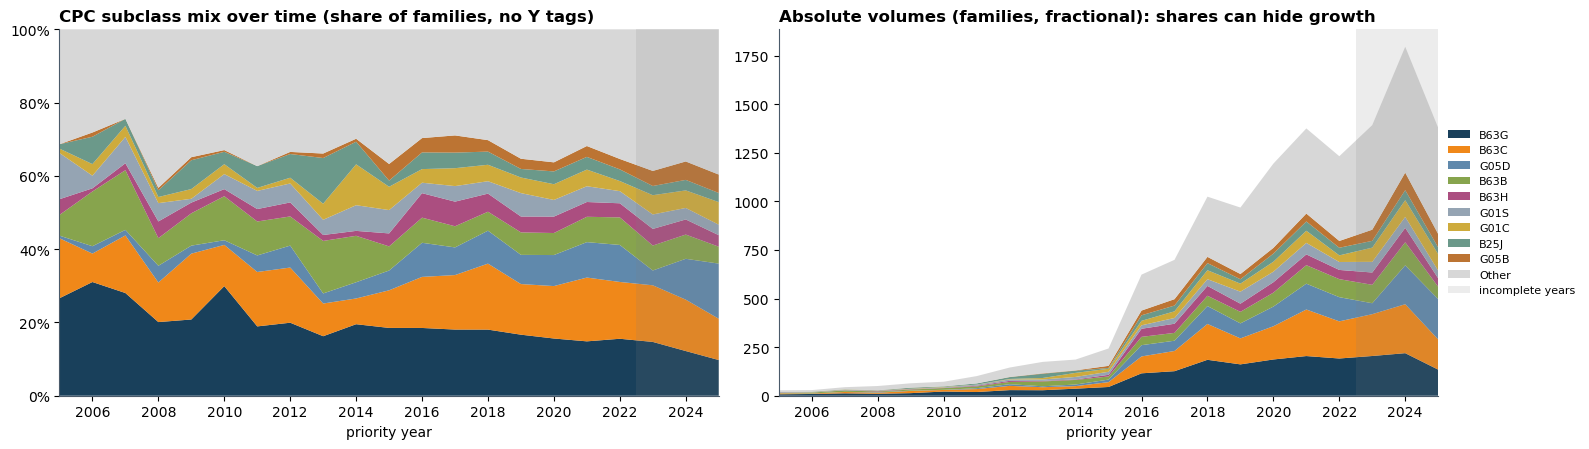

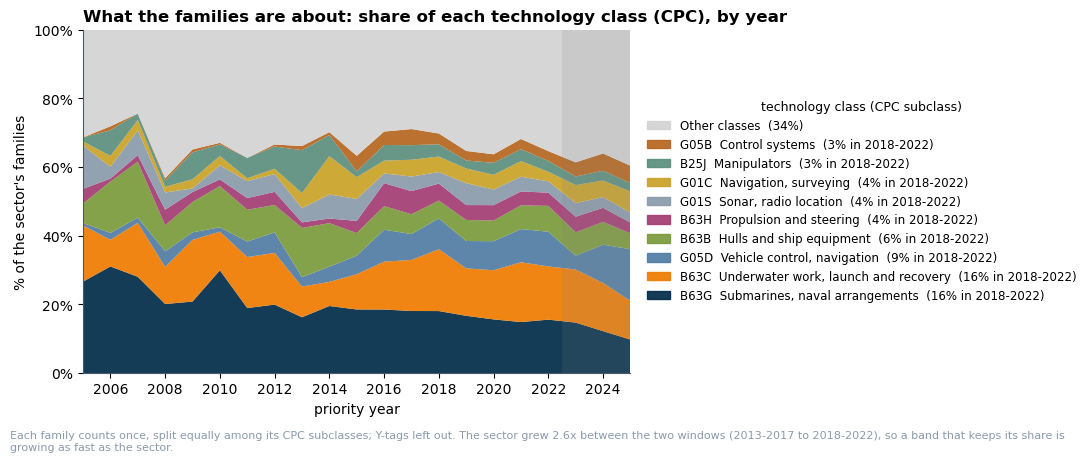

,share 2013-2017,share 2018-2022,change (pp)
subclass,,,
B63G,18.2%,16.0%,-2.2
B25J,5.0%,3.2%,-1.7
B63B,7.7%,6.4%,-1.2
G01C,5.3%,4.1%,-1.2
B63H,5.3%,4.3%,-1.0
E21B,1.6%,0.6%,-1.0
H04W,0.3%,0.7%,+0.4
G06T,1.0%,1.5%,+0.5
G06N,0.3%,1.2%,+1.0


In [12]:
top_sub = share_by(sub_tc, "subclass", "weight_tech", top=9).index.drop("Other")
yearly_abs = (sub_t[sub_t.family_year.between(2005, YEAR_MAX)]
              .assign(subclass=lambda d: d["subclass"].where(d["subclass"].isin(top_sub), "Other"))
              .pivot_table(index="family_year", columns="subclass", values="weight_tech", aggfunc="sum", fill_value=0))[list(top_sub) + ["Other"]]
yearly_mix = yearly_abs.div(yearly_abs.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
cols = PALETTE[:len(top_sub)] + ["lightgrey"]
axes[0].stackplot(yearly_mix.index, yearly_mix.T.values, labels=yearly_mix.columns, colors=cols, alpha=0.9)
axes[0].set(title="CPC subclass mix over time (share of families, no Y tags)", xlabel="priority year", ylim=(0, 100), xlim=(2005, YEAR_MAX))
axes[0].yaxis.set_major_formatter(PercentFormatter(100))
axes[1].stackplot(yearly_abs.index, yearly_abs.T.values, labels=yearly_abs.columns, colors=cols, alpha=0.9)
axes[1].set(title="Absolute volumes (families, fractional): shares can hide growth", xlabel="priority year", xlim=(2005, YEAR_MAX))
for ax in axes: shade(ax)
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8, frameon=False)
plt.tight_layout(); save(fig, "s1_cpc_mix_over_time"); plt.show()

# One clear panel for the deck: share of the sector's families by technology class, with plain names and the share in the
# recent window next to each name. Each family counts once, split equally among its CPC subclasses (Y tags left out).
CPC_PLAIN = {"B63G": "Submarines, naval arrangements", "B63C": "Underwater work, launch and recovery", "G05D": "Vehicle control, navigation",
             "B63B": "Hulls and ship equipment", "B63H": "Propulsion and steering", "G01S": "Sonar, radio location",
             "G01C": "Navigation, surveying", "B25J": "Manipulators", "G05B": "Control systems", "G06F": "Computing, simulation",
             "G01N": "Material analysis", "G06T": "Image processing", "G06N": "AI, neural networks", "G06V": "Image recognition"}
_rec = sub_tc[sub_tc.family_year.between(*RECENT)].groupby("subclass")["weight_tech"].sum()
_rec = _rec / _rec.sum()
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.stackplot(yearly_mix.index, yearly_mix.T.values, colors=cols, alpha=0.92)
shade(ax); ax.set(xlim=(2005, YEAR_MAX), ylim=(0, 100), xlabel="priority year",
                  ylabel="% of the sector's families",
                  title="What the families are about: share of each technology class (CPC), by year")
ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.margins(x=0)
from matplotlib.patches import Patch
_names = [(f"{c}  {CPC_PLAIN.get(c, '')}  ({_rec.get(c, 0):.0%} in {RECENT[0]}-{RECENT[1]})" if c != "Other"
           else f"Other classes  ({1 - _rec.reindex(top_sub).sum():.0%})") for c in yearly_mix.columns]
ax.legend([Patch(color=c_, alpha=0.92) for c_ in cols][::-1], _names[::-1], fontsize=8.5, frameon=False,
          loc="center left", bbox_to_anchor=(1.01, 0.5), title="technology class (CPC subclass)", title_fontsize=9)
fig.text(0.01, 0.005, "Each family counts once, split equally among its CPC subclasses; Y-tags left out. The sector grew 2.6x between the two windows "
         f"({PAST[0]}-{PAST[1]} to {RECENT[0]}-{RECENT[1]}), so a band that keeps its share is growing as fast as the sector.",
         fontsize=8, color=MID, ha="left", va="bottom", wrap=True)
plt.tight_layout(rect=(0, 0.05, 1, 1)); save(fig, "s1_tech_mix_clear"); plt.show()

def window_share(df, key, period, weight="weight"):
    d = df[df.family_year.between(*period)]
    s = d.groupby(key)[weight].sum()
    return s / s.sum()

shift = pd.DataFrame({f"share {PAST[0]}-{PAST[1]}": window_share(sub_t, "subclass", PAST, "weight_tech"),
                      f"share {RECENT[0]}-{RECENT[1]}": window_share(sub_t, "subclass", RECENT, "weight_tech")}).fillna(0)
shift["change (pp)"] = (shift.iloc[:, 1] - shift.iloc[:, 0]) * 100
shift = shift[shift.iloc[:, 1] >= 0.005].sort_values("change (pp)")
pd.concat([shift.head(6), shift.tail(6)]).style.format({shift.columns[0]: "{:.1%}", shift.columns[1]: "{:.1%}", "change (pp)": "{:+.1f}"})

### 1.3.2 WIPO technology sectors and fields (Schmoch, 2008)

A coarser view, comparable across sectors and countries: of 100 families, how many are in each of the 5 WIPO
technology sectors, and how does it change over time?

In [13]:
w = fwipo.merge(fam[["docdb_family_id", "family_year"]], on="docdb_family_id")
w_c = w[w.family_year <= LAST]
wsec = pd.DataFrame({"all years": share_by(w_c, "techn_sector", top=5).drop("Other"),
                     f"{PAST[0]}-{PAST[1]}": window_share(w, "techn_sector", PAST),
                     f"{RECENT[0]}-{RECENT[1]}": window_share(w, "techn_sector", RECENT)})
wfield = pd.DataFrame({"all years": share_by(w_c, "techn_field", top=10),
                       f"{PAST[0]}-{PAST[1]}": window_share(w, "techn_field", PAST),
                       f"{RECENT[0]}-{RECENT[1]}": window_share(w, "techn_field", RECENT)}).loc[lambda d: d.index != "Other"]
aw = pd.read_csv(IN / "application_wipo_fields.csv").merge(fwipo[["techn_field_nr", "techn_sector"]].drop_duplicates(), on="techn_field_nr")
aw = aw.merge(apps[["appln_id", "appln_filing_year"]], on="appln_id")
aw = aw[aw.appln_filing_year <= LAST]
wsec["applications (all years)"] = aw.groupby("techn_sector")["weight"].sum() / aw["weight"].sum()
for t in (wsec, wfield):
    t["change (pp)"] = (t[f"{RECENT[0]}-{RECENT[1]}"] - t[f"{PAST[0]}-{PAST[1]}"]) * 100
save_table(wsec, "wipo_sectors"); save_table(wfield, "wipo_fields")
display(wsec.style.format({c: ("{:+.1f}" if c == "change (pp)" else "{:.1%}") for c in wsec.columns}))
wfield.sort_values("all years", ascending=False).style.format({c: ("{:+.1f}" if c == "change (pp)" else "{:.1%}") for c in wfield.columns}, na_rep="–")

,all years,2013-2017,2018-2022,applications (all years),change (pp)
techn_sector,,,,,
Chemistry,1.6%,1.4%,1.6%,1.7%,+0.2
Electrical engineering,13.5%,10.8%,15.2%,12.6%,+4.5
Instruments,27.2%,27.9%,27.4%,25.4%,-0.5
Mechanical engineering,54.7%,56.8%,53.2%,56.1%,-3.6
Other fields,3.1%,3.1%,2.6%,4.3%,-0.5


,all years,2013-2017,2018-2022,change (pp)
techn_field,,,,
Transport,44.1%,44.7%,43.7%,-1.0
Measurement,14.6%,14.8%,14.1%,-0.6
Control,11.8%,12.5%,12.5%,-0.0
Handling,5.5%,6.5%,4.9%,-1.6
Computer technology,5.3%,3.2%,6.7%,+3.5
"Electrical machinery, apparatus, energy",3.9%,3.5%,4.0%,+0.5
Civil engineering,2.8%,2.7%,2.5%,-0.2
Mechanical elements,2.0%,2.1%,1.9%,-0.2
Telecommunications,1.7%,1.7%,1.7%,-0.0


### 1.3.3 Recombination: are inventions combining more technologies?

The number of distinct CPC subclasses per family is a simple measure of how many technologies an invention
combines (a bridge to the lecture *Innovation as recombination*, 14 Dec, and to the novel-recombination ingredient of
the Step 4 future score). A rising trend means the field becomes more systemic (vehicle + sensing + software).
Read the **trend, not the two end points**, and compare with the international families: the mean can fall simply
because new, narrower filers enter (many university filings have one or two subclasses), not because technologies
stop combining.

In [14]:
rec = fam[fam.family_year.between(2005, LAST)].groupby("family_year")["n_subclasses"].agg(["mean", "median"])
rec["share with ≥3 subclasses"] = fam[fam.family_year.between(2005, LAST)].groupby("family_year")["n_subclasses"].apply(lambda s: (s >= 3).mean())
rec["mean (international families)"] = fam[fam.family_year.between(2005, LAST) & fam.is_international].groupby("family_year")["n_subclasses"].mean()
save_table(rec, "recombination")
rec.reindex([y for y in (2005, 2010, 2015, 2018, 2020, 2022) if y in rec.index]).round(2)

,mean,median,share with ≥3 subclasses,mean (international families)
family_year,,,,
2005,2.18,2.0,0.24,2.17
2010,2.44,2.0,0.18,2.54
2015,2.00,2.0,0.15,2.91
2018,1.85,2.0,0.18,3.29
2020,2.15,2.0,0.30,3.25
2022,2.16,2.0,0.28,3.27


## 1.4 Geography: where is protection sought, who owns the technology, where is the R&D done?

Three different questions, three different fields (IM_Theory_1 and IM_Theory_3, *who / where*):

| Question | Field | Note |
|---|---|---|
| Where is the invention first filed (origin)? | `first_office` (priority office) | home market of the applicant |
| Where is protection sought (markets)? | offices of the family (`offices`) | *"the countries in the family are the courts where the owner will be able to sue"* (IM_Theory_2) |
| Who owns it? | applicant country (fractional) | headquarters, sometimes a holding |
| Where is the R&D done? | inventor country (fractional) | *"inventor addresses show where the research is actually done"* (IM_Theory_1) |

Missing countries: `02_clean` falls back on the national filing office when the person's country is missing
(Tutorial 1 nb 10 §7.2: otherwise China and Japan disappear). `country_source` says which.

**Caution.** In PATSTAT the country is missing **not at random**: Chinese applicants and inventors almost never carry
one. The fallback is a sound proxy for the *owner's* country, but it makes applicant and inventor countries nearly
identical *by construction*, so the inventors − owners gap below **cannot** reveal foreign R&D centres on its own.
The "stated only" columns keep only rows with a declared country (mostly foreign): read them as the profile of the
*non-Chinese* part of the sector, not as a correction.

The last two columns repeat the shares at **application level** (Tutorial 0 nb 02 §9.2: every filing counts, so an
invention filed in many offices weighs more). China's share is lower there than at family level because Chinese
inventions are filed almost only at home, while foreign owners file the same invention in several offices.

In [15]:
fam_c = fam[fam.family_year <= LAST]
origin = fam_c["first_office"].value_counts(normalize=True).head(10)
offices = fam_c["offices"].str.split().explode()
markets = (offices.value_counts() / len(fam_c)).head(12)

app_ctry = appl[appl.family_year <= LAST].groupby("country")["country_weight"].sum()
inv_ctry = inv.merge(fam[["docdb_family_id", "family_year"]], on="docdb_family_id").query("family_year <= @LAST").groupby("country")["country_weight"].sum()
geo = pd.DataFrame({"applicant share (owners)": app_ctry / app_ctry.sum(), "inventor share (R&D)": inv_ctry / inv_ctry.sum()}).fillna(0)
geo["gap (pp, inventors − owners)"] = (geo.iloc[:, 1] - geo.iloc[:, 0]) * 100
geo = geo.sort_values("applicant share (owners)", ascending=False).head(14)
KEY["share_first_filed_CN"] = float((fam_c.first_office == "CN").mean())
KEY["share_international"] = float(fam_c.is_international.mean())

display(pd.DataFrame({"first filing office (share of families)": origin}).style.format("{:.1%}"))
display(pd.DataFrame({"families with an application at the office": markets}).style.format("{:.1%}"))
def stated_shares(df, entity):
    d = df[df["country"].notna() & df["country_source"].eq("person")].drop_duplicates(["docdb_family_id", entity])
    w = 1 / d.groupby("docdb_family_id")[entity].transform("size")
    s = w.groupby(d["country"]).sum()
    return s / s.sum()

inv_c = inv.merge(fam[["docdb_family_id", "family_year"]], on="docdb_family_id").query("family_year <= @LAST")
inv_key = "inventor" if "inventor" in inv_c.columns else ("person_id" if "person_id" in inv_c.columns else inv_c.columns[1])
geo["applicants, stated only"] = stated_shares(appl[appl.family_year <= LAST], "applicant").reindex(geo.index)
geo["inventors, stated only"] = stated_shares(inv_c, inv_key).reindex(geo.index)
# application level, as in Tutorial 0 nb 02 §9.2: each application split among its persons with a country (stated, or
# the national filing office when missing: same fallback as above); applications still without one are excluded and
# reported (Tutorial 0: "watch out for missing values")
apps_c = apps.loc[apps["appln_filing_year"] <= LAST, "appln_id"]
for role, fname in [("applicant", "applicant_countries_by_application.csv"), ("inventor", "inventor_countries_by_application.csv")]:
    if (IN / fname).exists():
        ac = pd.read_csv(IN / fname, low_memory=False)
        ac = ac[ac.appln_id.isin(apps_c)]
        s_ = ac.groupby("country")["weight"].sum()
        geo[f"{role} share (applications)"] = (s_ / s_.sum()).reindex(geo.index)
        miss = 1 - ac.appln_id.nunique() / len(apps_c)
        KEY[f"applications_without_{role}_country"] = float(miss)
        print(f"Applications (filing year ≤ {LAST}) with no {role} country, even after the office fallback: {miss:.1%} (excluded from the application-level shares)")
src_share = pd.DataFrame({"applicants": appl.loc[appl.family_year <= LAST, "country_source"].value_counts(normalize=True),
                          "inventors": inv_c["country_source"].value_counts(normalize=True)})
KEY["applicant_rows_country_from_office"] = float(src_share.loc["filing_office", "applicants"]) if "filing_office" in src_share.index else np.nan
save_table(geo, "geography_owners_inventors")
display(src_share.style.format("{:.1%}", na_rep="–").set_caption("Where the country comes from (share of rows)"))
geo.style.format({"applicant share (owners)": "{:.1%}", "inventor share (R&D)": "{:.1%}", "gap (pp, inventors − owners)": "{:+.2f}",
                  "applicants, stated only": "{:.1%}", "inventors, stated only": "{:.1%}",
                  "applicant share (applications)": "{:.1%}", "inventor share (applications)": "{:.1%}"}, na_rep="–")

,first filing office (share of families)
first_office,
CN,73.5%
KR,7.3%
US,5.9%
WO,2.7%
RU,2.4%
JP,1.8%
GB,1.3%
DE,1.1%
FR,0.8%


,families with an application at the office
offices,
CN,74.7%
US,11.8%
WO,9.4%
KR,7.9%
EP,5.5%
JP,3.0%
AU,2.7%
RU,2.7%
GB,1.9%


Applications (filing year ≤ 2022) with no applicant country, even after the office fallback: 1.1% (excluded from the application-level shares)
Applications (filing year ≤ 2022) with no inventor country, even after the office fallback: 1.8% (excluded from the application-level shares)


,applicants,inventors
country_source,,
filing_office,66.8%,82.0%
person,33.2%,17.9%
unknown,0.0%,0.2%


,applicant share (owners),inventor share (R&D),"gap (pp, inventors − owners)","applicants, stated only","inventors, stated only",applicant share (applications),inventor share (applications)
country,,,,,,,
CN,74.5%,74.5%,+0.06,11.6%,12.3%,58.7%,59.0%
KR,7.3%,7.4%,+0.08,26.6%,19.6%,5.9%,6.1%
US,6.0%,5.8%,-0.26,22.6%,25.6%,10.7%,10.2%
RU,2.4%,2.5%,+0.07,8.7%,10.1%,1.9%,1.9%
JP,2.1%,2.1%,-0.00,2.6%,2.5%,3.2%,2.8%
GB,1.2%,1.1%,-0.15,4.4%,4.7%,3.6%,3.1%
DE,1.2%,1.2%,-0.08,4.6%,5.1%,3.4%,3.1%
FR,1.1%,1.1%,+0.01,4.2%,4.8%,2.9%,2.8%
NO,0.9%,0.9%,+0.06,3.3%,4.0%,2.6%,2.5%


**Filing offices: the IP5, at both levels.** Application level: each application is at one office, shares sum to
100%. Family level: a family usually has several offices, so the share of families "with an application at the
office" does not sum to 100%; the first office (origin) does.

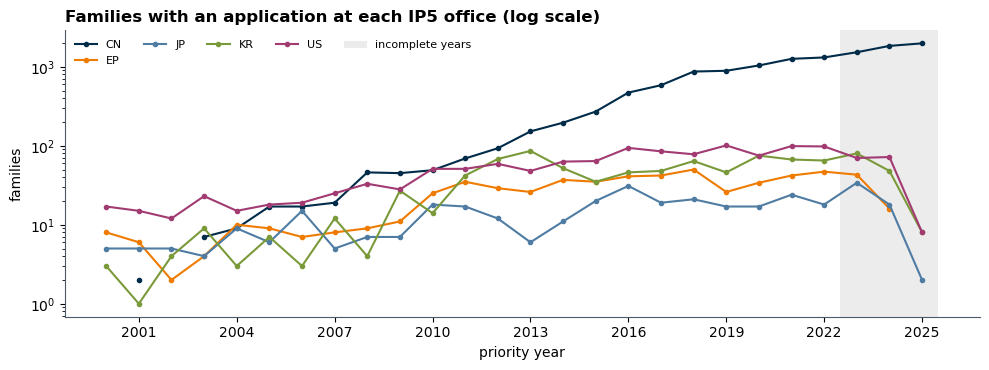

,% of families with an application at the office,"% of families, by first office",% of applications
CN,74.7%,73.5%,55.8%
US,11.8%,5.9%,10.2%
KR,7.9%,7.3%,5.8%
JP,3.0%,1.8%,2.4%
EP,5.5%,0.7%,4.3%
WO,9.4%,2.7%,6.7%
Other,10.9%,8.1%,14.8%
Total,–,100.0%,100.0%


In [16]:
IP5 = ("CN", "US", "KR", "JP", "EP")
pool_office = lambda s: s.where(s.isin(IP5 + ("WO",)), "Other")
fam_off = (apps[["docdb_family_id", "appln_auth"]].drop_duplicates().assign(office=lambda d: pool_office(d.appln_auth.astype(str).str.strip()))
           .drop_duplicates(["docdb_family_id", "office"]))
fam_off_c = fam_off[fam_off.docdb_family_id.isin(fam_c.docdb_family_id)]
app_ok = apps_w[apps_w.appln_filing_year <= LAST].assign(office=lambda d: pool_office(d.appln_auth.astype(str).str.strip()))
office_tab = pd.DataFrame({
    "% of families with an application at the office": fam_off_c.groupby("office").size() / len(fam_c) * 100,
    "% of families, by first office": pool_office(fam_c["first_office"].astype(str).str.strip()).value_counts(normalize=True) * 100,
    "% of applications": app_ok["office"].value_counts(normalize=True) * 100}).fillna(0)
office_tab = office_tab.loc[[o for o in IP5 + ("WO", "Other") if o in office_tab.index]]
office_tab.loc["Total"] = [np.nan, office_tab.iloc[:, 1].sum(), office_tab.iloc[:, 2].sum()]
KEY["share_applications_IP5"] = float(office_tab.loc[[o for o in IP5 if o in office_tab.index], "% of applications"].sum() / 100)
save_table(office_tab, "offices_ip5")
ip5_lines = (fam_off.merge(fam[["docdb_family_id", "family_year"]], on="docdb_family_id").query("office in @IP5")
             .groupby(["office", "family_year"]).size().unstack(0).reindex(years, fill_value=0))
fig, ax = plt.subplots(figsize=(10, 3.8))
for o in ip5_lines.columns:
    ax.plot(ip5_lines.index, ip5_lines[o], marker="o", ms=3, label=o)
shade(ax); ax.set_yscale("log"); ax.legend(frameon=False, fontsize=8, ncol=5)
ax.set(title="Families with an application at each IP5 office (log scale)", xlabel="priority year", ylabel="families")
plt.tight_layout(); save(fig, "s1_ip5_offices"); plt.show()
office_tab.style.format("{:.1f}%", na_rep="–")

**Origin over time.** The share of China among first filings, and the internationalisation rate by origin.
Internationalisation is the cleanest *value* signal available for every family: filing abroad is costly (fees,
translations, attorneys multiplied by every country, IM_Theory_1), so applicants do it only for inventions they
expect to be worth it. A low international share for Chinese families is consistent with subsidy-driven domestic
filing (Dang & Motohashi, 2015) and with university portfolios that "stop at the national filing" (IM_Theory_2).

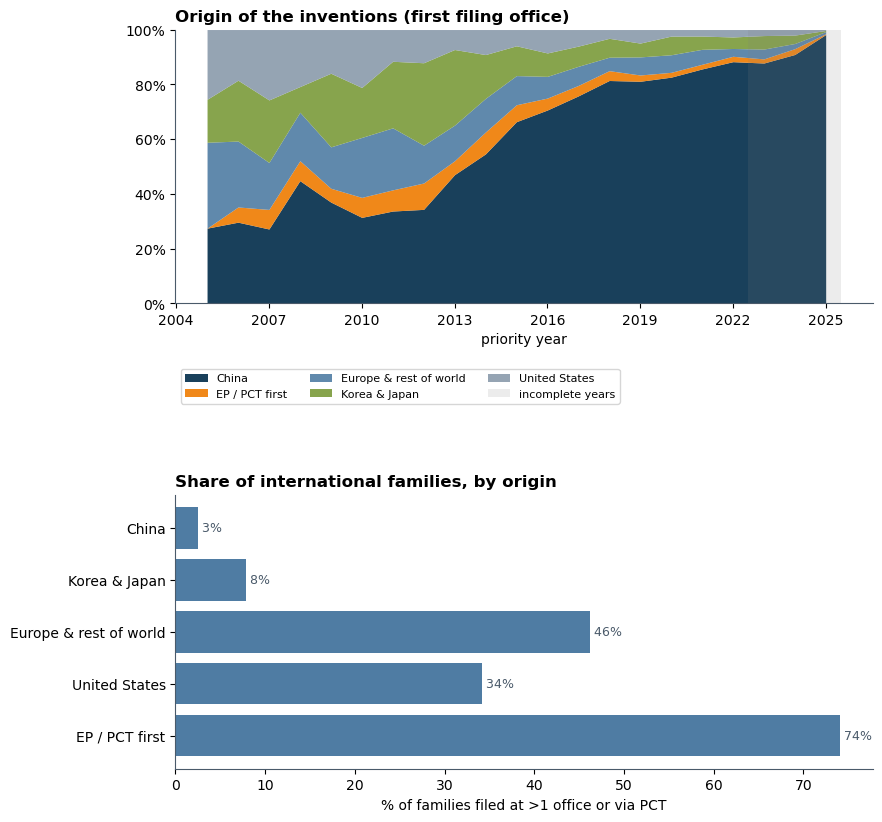

,families,international,mean_offices,granted
origin_group,,,,
China,7303,2.5%,1.03,61.3%
Korea & Japan,900,7.9%,1.19,75.4%
Europe & rest of world,807,46.2%,2.64,83.0%
United States,589,34.1%,1.98,80.6%
EP / PCT first,335,74.0%,3.26,59.7%


In [17]:
fam["origin_group"] = np.where(fam.first_office.eq("CN"), "China", np.where(fam.first_office.isin(["US"]), "United States",
                       np.where(fam.first_office.isin(["KR", "JP"]), "Korea & Japan",
                       np.where(fam.first_office.isin(["EP", "WO"]), "EP / PCT first", "Europe & rest of world"))))
fam_c = fam[fam.family_year <= LAST]
og = fam[fam.family_year.between(2005, YEAR_MAX)].groupby(["family_year", "origin_group"]).size().unstack(fill_value=0)
og_share = og.div(og.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(2, 1, figsize=(9, 9.6), gridspec_kw={"hspace": 0.7})     # stacked for the deck
og_share.plot.area(ax=axes[0], color=[NAVY, ORANGE, BLUE, GREEN, MID][:og_share.shape[1]], alpha=0.9, lw=0)
shade(axes[0]); axes[0].set(title="Origin of the inventions (first filing office)", xlabel="priority year", ylim=(0, 100))
axes[0].yaxis.set_major_formatter(PercentFormatter(100)); axes[0].legend(fontsize=8, frameon=True, loc="upper left", bbox_to_anchor=(0, -0.22), ncol=3)
intl = fam_c.groupby("origin_group").agg(families=("docdb_family_id", "size"), international=("is_international", "mean"),
                                         mean_offices=("n_offices", "mean"), granted=("granted_any", "mean")).sort_values("families", ascending=False)
axes[1].barh(intl.index[::-1], intl["international"][::-1] * 100, color=BLUE)
for y, v in enumerate(intl["international"][::-1] * 100):
    axes[1].text(v, y, f" {v:.0f}%", va="center", fontsize=9, color=GREY)
axes[1].set(title="Share of international families, by origin", xlabel="% of families filed at >1 office or via PCT")
save(fig, "s1_origin_internationalisation"); plt.show()
intl.style.format({"international": "{:.1%}", "mean_offices": "{:.2f}", "granted": "{:.1%}"})

**Where do the inventions go?** Origin (rows) × destination office (columns): share of the families of each origin
that have an application at each office. It shows which markets each bloc protects, i.e. where it expects to sell
or to sue (IM_Theory_2, *choice 2: when and where to file*).

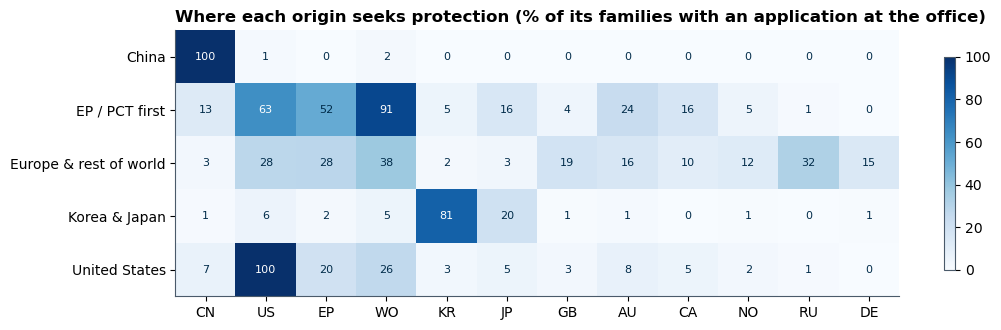

In [18]:
flows = fam_c[["docdb_family_id", "origin_group", "offices"]].assign(office=lambda d: d.offices.str.split()).explode("office")
dest = ["CN", "US", "EP", "WO", "KR", "JP", "GB", "AU", "CA", "NO", "RU", "DE"]
od = flows[flows.office.isin(dest)].pivot_table(index="origin_group", columns="office", values="docdb_family_id", aggfunc="nunique", fill_value=0)
od = od.div(fam_c.groupby("origin_group").size(), axis=0).reindex(columns=dest, fill_value=0)   # offices absent in the sample = 0
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(od.values * 100, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(dest)), dest); ax.set_yticks(range(len(od)), od.index)
for i in range(od.shape[0]):
    for j in range(od.shape[1]):
        v = od.iat[i, j] * 100
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 55 else NAVY)
ax.set_title("Where each origin seeks protection (% of its families with an application at the office)")
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); save(fig, "s1_origin_destination"); plt.show()

**The same flows, simplified for the deck: China vs United States vs Europe.** For each origin, the share of its
families that also reach each market. Europe = first filed at the EPO / via PCT or at a European national office.

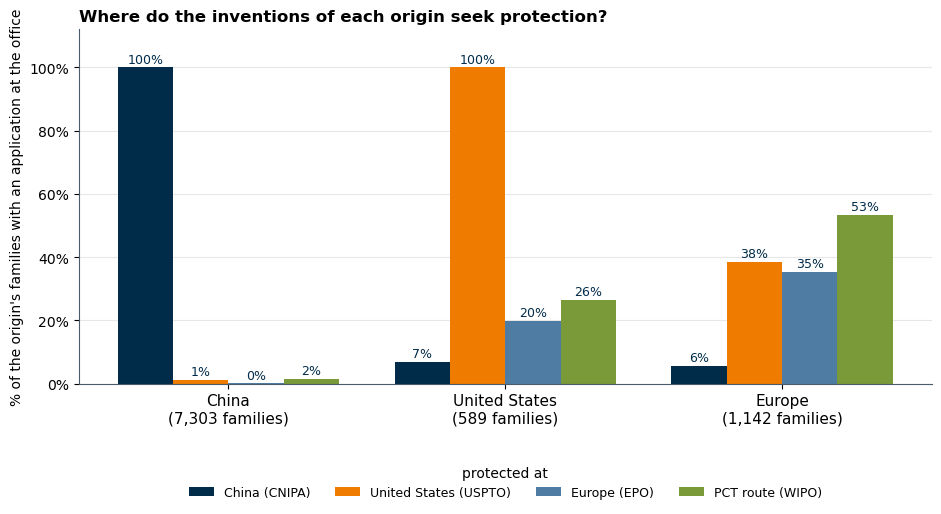

,China (CNIPA),United States (USPTO),Europe (EPO),PCT route (WIPO)
China,100.0,1.0,0.0,2.0
United States,7.0,100.0,20.0,26.0
Europe,6.0,38.0,35.0,53.0


In [19]:
_eu = fam_c.origin_group.isin(["EP / PCT first", "Europe & rest of world"])
_grp = {"China": fam_c.origin_group.eq("China"), "United States": fam_c.origin_group.eq("United States"), "Europe": _eu}
_mk = [("CN", "China (CNIPA)"), ("US", "United States (USPTO)"), ("EP", "Europe (EPO)"), ("WO", "PCT route (WIPO)")]
_off = fam_c.offices.str.split()
rows = {g: {lab: _off[m].apply(lambda o: code in o).mean() * 100 for code, lab in _mk} for g, m in _grp.items()}
rows_n = {g: int(m.sum()) for g, m in _grp.items()}
_df = pd.DataFrame(rows).T
save_table(_df.round(1), "origin_vs_market_cn_us_eu")
fig, ax = plt.subplots(figsize=(11, 4.6)); w = 0.2
_cols = [NAVY, ORANGE, BLUE, GREEN]
for k, lab in enumerate(_df.columns):
    pos = np.arange(len(_df)) + (k - 1.5) * w
    ax.bar(pos, _df[lab], width=w, color=_cols[k], label=lab, zorder=2)
    for x_, v in zip(pos, _df[lab]):
        ax.text(x_, v + 1.5, f"{v:.0f}%", ha="center", fontsize=9, color=NAVY)
ax.set_xticks(range(len(_df)), [f"{g}\n({rows_n[g]:,} families)" for g in _df.index], fontsize=11)
ax.set_ylim(0, 112); ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.grid(axis="y", alpha=0.3, zorder=0)
ax.set_title("Where do the inventions of each origin seek protection?")
ax.set_ylabel("% of the origin's families with an application at the office")
ax.legend(title="protected at", ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=9)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
save(fig, "s1_origin_vs_markets"); plt.show()
_df.round(0)

## 1.5 Appropriability: is the field patent-heavy, or does it rely on secrecy?

**Theory (IM_Theory_0, IM_Theory_2).** Firms protect inventions with *formal* methods (patents) or *informal* ones
(secrecy, complexity, lead time, complementary assets). Patenting pays when the invention is easy to copy once on
the market and infringement can be detected; secrecy is best for what cannot be seen from the product. Large firms
use formal methods more than small ones; and in **defence**, public procurement is itself an appropriability
mechanism (the government commits to buy from the innovator, IM_Theory_0). Cohen, Nelson & Walsh (2000) and
Arundel (2001) find that in most manufacturing industries secrecy and lead time are rated *more* effective than
patents.

Patent data cannot observe secrecy directly, so we triangulate with five pieces of evidence:

1. **market leaders vs patent leaders**: if the firms that lead the market hold few patents, they appropriate in other ways;
2. **who patents**: a sector dominated by universities and public bodies (non-practicing entities, IM_Theory_2)
   patents for reasons other than exclusion (evaluation, subsidies, technology transfer);
3. **how much protection each patent buys**: internationalisation, grants, renewals (does the owner keep paying?);
4. **post-grant use**: oppositions, licences, transfers, litigation (IM_Theory_1–2: the right is *probabilistic*, its
   value is tested in court and in the market for technology);
5. **comparison with the neighbouring field and with the literature**.

### 1.5.1 Market leaders vs patent leaders

The market leaders of UUVs (Kongsberg, Teledyne, Saab, General Dynamics, L3Harris: about 58% of the market
according to MarkNtel, Step 0 literature note; the only public share figure found, see `external_data/market_players.csv`
for the flagship products of each one) against the patent leaders of the sector (families 2000–2025, all years: the same counts as the Step 0 guide).
The leaders are matched on the harmonised groups (`GROUP_ALIASES`: subsidiaries included). **Before using this as
evidence, check the recall of the query on their flagship products** (e.g. HUGIN, REMUS, Bluefin, Sabertooth,
Seaeye): a miss of the query would look like "few patents". Cite the source of the market shares in the deck.

In [20]:
grp = appl.groupby("applicant").agg(families=("docdb_family_id", "nunique"),
                                                              fractional=("weight", "sum"), country=("country", lambda s: s.mode().iat[0] if s.notna().any() else None))
grp["type"] = grp.index.map(prof.set_index("applicant")["type"])
grp["rank"] = grp["families"].rank(ascending=False, method="min").astype(int)
market_leaders = ["KONGSBERG", "TELEDYNE", "SAAB", "GENERAL DYNAMICS (BLUEFIN)", "L3HARRIS", "HUNTINGTON INGALLS (HYDROID)",
                  "EXAIL (ECA)", "OCEANEERING", "TKMS (ATLAS ELEKTRONIK)", "NAVAL GROUP", "BAE SYSTEMS", "HANWHA", CLIENT]
firm_rank = grp[grp.type.isin(["firm", "unknown"])]["families"].rank(ascending=False, method="min")
grp["rank among firms"] = firm_rank.reindex(grp.index)
ml = grp.reindex(market_leaders)[["families", "country", "type", "rank", "rank among firms"]]
if (EXT / "market_players.csv").exists():
    _mp = pd.read_csv(EXT / "market_players.csv").dropna(subset=["group_alias"]).set_index("group_alias")
    ml["flagship products"] = ml.index.map(_mp["flagship_products"])
save_table(ml, "market_vs_patent_leaders")
ml.loc[:, "families"] = ml["families"].fillna(0)
top_patent = grp.sort_values("families", ascending=False).head(8)[["families", "country", "type", "rank"]]
display(top_patent)
ml

,families,country,type,rank
applicant,,,,
HARBIN ENGINEERING UNIVERSITY,1226,CN,university,1
CHINESE ACADEMY OF SCIENCES,804,CN,university,2
CHINA STATE SHIPBUILDING (CSSC),697,CN,firm,3
NORTHWESTERN POLYTECHNICAL UNIVERSITY,575,CN,university,4
ZHEJIANG UNIVERSITY,381,CN,university,5
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,223,CN,university,6
TIANJIN UNIVERSITY,199,CN,university,7
DALIAN MARITIME UNIVERSITY,165,CN,university,8


,families,country,type,rank,rank among firms,flagship products
applicant,,,,,,
KONGSBERG,10,NO,firm,214,73.0,"HUGIN, Munin (AUV)"
TELEDYNE,9,US,firm,231,87.0,"Gavia (AUV), Slocum (glider)"
SAAB,12,SE,firm,179,56.0,"Seaeye Falcon, Sabertooth (ROV / hybrid)"
GENERAL DYNAMICS (BLUEFIN),4,US,firm,499,225.0,Bluefin-9 / -12 / -21 (AUV)
L3HARRIS,7,US,firm,289,112.0,Iver (AUV)
HUNTINGTON INGALLS (HYDROID),2,US,firm,862,444.0,REMUS (AUV)
EXAIL (ECA),14,FR,firm,154,48.0,A18 (AUV)
OCEANEERING,45,US,firm,48,10.0,NaN
TKMS (ATLAS ELEKTRONIK),96,DE,firm,18,4.0,NaN


### 1.5.2 Who patents? Practicing vs non-practicing entities

Share of the sector's families (fractional) by type of owner, by origin, over time. Universities and public research
organisations are NPEs: they patent to transfer knowledge (licences, spin-offs) and to be evaluated, not to protect
their own products (IM_Theory_2). A sector where NPEs own most patents has a patent count that overstates the
*commercial* inventive activity, and acquisition targets must be searched among the firms.

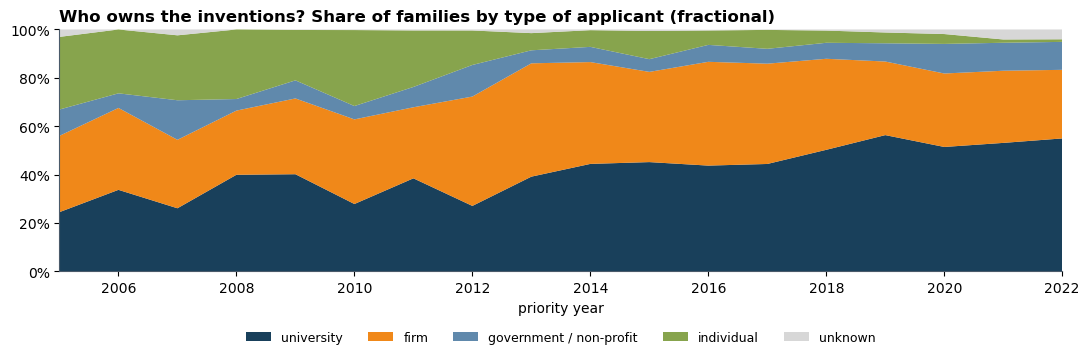

type,firm,government / non-profit,hospital,individual,university,unknown
origin_group,,,,,,
China,27.5%,7.2%,0.0%,3.2%,61.3%,0.9%
EP / PCT first,60.4%,5.8%,0.0%,15.3%,9.8%,8.7%
Europe & rest of world,49.9%,12.7%,0.0%,16.4%,15.4%,5.7%
Korea & Japan,53.8%,21.1%,0.0%,9.3%,13.7%,2.0%
United States,52.6%,12.8%,0.0%,24.2%,5.2%,5.2%
ALL,34.2%,9.2%,0.0%,6.5%,48.2%,1.9%


In [21]:
types = appl[appl.family_year <= LAST].merge(fam[["docdb_family_id", "origin_group"]], on="docdb_family_id")
tshare = types.pivot_table(index="origin_group", columns="type", values="weight", aggfunc="sum", fill_value=0)
tshare = tshare.div(tshare.sum(axis=1), axis=0)
tshare.loc["ALL"] = types.groupby("type")["weight"].sum() / types["weight"].sum()
ty = appl[appl.family_year.between(2005, LAST)].pivot_table(index="family_year", columns="type", values="weight", aggfunc="sum", fill_value=0)
ty = ty.div(ty.sum(axis=1), axis=0) * 100
KEY["share_university"] = float(tshare.loc["ALL"].get("university", 0)); KEY["share_firm"] = float(tshare.loc["ALL"].get("firm", 0))

fig, ax = plt.subplots(figsize=(11, 3.8))
order = [c for c in ["university", "firm", "government / non-profit", "individual", "unknown"] if c in ty.columns]
ax.stackplot(ty.index, ty[order].T.values, labels=order, colors=[NAVY, ORANGE, BLUE, GREEN, "lightgrey"], alpha=0.9)
ax.set(title="Who owns the inventions? Share of families by type of applicant (fractional)", xlabel="priority year", ylim=(0, 100))
ax.yaxis.set_major_formatter(PercentFormatter(100)); years_axis(ax); ax.margins(x=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=len(order), fontsize=9, frameon=False)
plt.tight_layout(); save(fig, "s1_owner_types"); plt.show()
tshare.style.format("{:.1%}")

**"Unknown"** applicants are names PATSTAT could not classify (`psn_sector` empty): in this sector they are mostly
small Chinese technology companies (… TECHNOLOGY, … INTELLIGENT TECHNOLOGY). Treat them as firms in the deck only
after checking the largest ones by hand (`applicants_to_review.csv`).

### 1.5.3 How much protection does each patent buy?

By origin and by type of owner: share granted (families with priority ≤ 2019, so that most have been examined:
Tutorial 4, *the time window*), internationalisation, mean number of offices, share still alive (`active_proxy`,
the WIPO *active family* notion of IM_Theory_3), forward citations within 5 years (complete windows only). Renewal-fee
events are **left out on purpose**: INPADOC records them very differently by office (almost none for China), so the
comparison would measure data coverage, not behaviour (the life cycle of 1.5.5 uses grants, lapses and expiry instead). The two IM_Theory_2 hypotheses tested here: universities rarely go abroad (small
budgets), and Chinese families are cheaper, narrower and less renewed.

In [22]:
fam_types = types.groupby("docdb_family_id")["type"].agg(lambda s: s.value_counts().index[0])
fam["main_type"] = fam["docdb_family_id"].map(fam_types).fillna("unknown")
fam_c = fam[fam.family_year <= LAST]

def protection_profile(d):
    return pd.Series({"families": len(d), f"granted (≤{GRANT_MAX_YEAR})": d.loc[d.family_year <= GRANT_MAX_YEAR, "granted_any"].mean(),
                      "international": d["is_international"].mean(), "mean offices": d["n_offices"].mean(),
                      "has EP": d["has_ep"].mean(), "active today": d.loc[d.family_year <= GRANT_MAX_YEAR, "active_proxy"].mean(),
                      "fwd cits 5y (complete)": d.loc[d.fwd_window_complete, "fwd_cits_5y"].mean(),
                      "NPL share of backward cits": (d["bwd_npl_cits"].sum() / (d["bwd_npl_cits"].sum() + d["bwd_pat_cits_pub"].sum())),
                      "in force today": d["family_status"].eq("in force").mean() if HAS_LIFE else np.nan,
                      "residual life (median, yrs)": d["family_residual_life_years"].median() if HAS_LIFE else np.nan})

prot = pd.concat({"origin": fam_c.groupby("origin_group").apply(protection_profile),
                  "owner type": fam_c.groupby("main_type").apply(protection_profile)})
prot.loc[("sector", "all"), :] = protection_profile(fam_c)
save_table(prot, "protection_profile")
prot.style.format({"families": "{:,.0f}", f"granted (≤{GRANT_MAX_YEAR})": "{:.0%}", "international": "{:.0%}", "mean offices": "{:.2f}",
                   "has EP": "{:.0%}", "active today": "{:.0%}",
                   "fwd cits 5y (complete)": "{:.2f}", "NPL share of backward cits": "{:.1%}", "in force today": "{:.0%}",
                   "residual life (median, yrs)": "{:.1f}"}, na_rep="–")

### 1.5.4 Post-grant life: oppositions, licences, transfers, litigation

From the INPADOC legal events (`02_clean` §9). At the EPO about **4% of granted patents were opposed** in 2008-2017, falling to about 2-3% in recent years (EPO Annual Reports; `external_data/ip_system_facts.csv`; the course slides round it to 5%, IM_Theory_1):
a sector well above it is litigious (patents block competitors), well below it is not (patents are not fought
over, consistent with weak appropriation through patents). Licences and transfers are the *market for technology*
(IM_Theory_2, choice 4). The flags come from regular expressions on the event descriptions (`02_clean` §9):
the last table lists the descriptions behind each flag, read it before quoting a number. Two flags are refined here:
**UPC opt-outs** are kept apart. They are not litigation but a strategic choice (IM_Theory_1, *Unitary Patent*):
the owner keeps its EP patent out of the Unified Patent Court, so it cannot be revoked centrally in one action.
Opting out is typical of owners who value their patents and fear central attacks.

In [23]:
ev = legal.copy()
for c in ["ev_opposition", "ev_licence", "ev_transfer", "ev_litigation", "ev_revocation"]:
    ev[c] = ev[c].astype(str).str.lower().eq("true")
# Refined flags (the check table below shows why): the 02_clean "litigation" regex matches the UPC opt-outs, and the
# "revocation" regex matches "INVALIDATED EUROPEAN PATENT", which national offices publish when an EP patent is not
# validated there (no translation / fee), not a court revocation.
d_ = ev["event_descr"].fillna("").str.upper()
ev["ev_upc_opt_out"] = d_.str.contains("OPT-OUT") & ~d_.str.contains("WITHDRAWAL OF OPT-OUT")
# US assignments also record the routine transfer from the inventors to their employer: keep a version without them
ev["ev_transfer_non_US"] = ev["ev_transfer"] & ev["event_auth"].ne("US")
ev["ev_litigation"] = ev["ev_litigation"] & ~d_.str.contains("OPT-OUT")
ev["ev_revocation"] = ev["ev_revocation"] & ~d_.str.contains("INVALIDATED EUROPEAN PATENT|INVALIDATION OF EXTENSION")
ev_fam = ev.groupby("docdb_family_id")[["ev_opposition", "ev_licence", "ev_transfer", "ev_litigation", "ev_revocation", "ev_upc_opt_out", "ev_transfer_non_US"]].any()
ep_granted = set(apps.loc[(apps.appln_auth == "EP") & apps.is_granted.astype(str).str.lower().eq("true"), "docdb_family_id"])
ep_opp = set(ev.loc[(ev.event_auth == "EP") & ev.ev_opposition, "docdb_family_id"])
post = pd.DataFrame({
    "families with the event": ev_fam.sum(),
    "share of all families": ev_fam.sum() / len(fam),
    "share of international families": ev_fam.reindex(list(SAMPLES["international"])).fillna(False).astype(bool).mean(),
})
opp_rate = len(ep_opp & ep_granted) / max(len(ep_granted), 1)
KEY["ep_opposition_rate"] = float(opp_rate)
opp_lo, opp_hi = wilson(len(ep_opp & ep_granted), len(ep_granted))
KEY["ep_opposition_ci95"] = [float(opp_lo), float(opp_hi)]
print(f"EP-granted families: {len(ep_granted):,}; opposed at the EPO: {len(ep_opp & ep_granted):,} = {opp_rate:.1%} "
      f"(95% Wilson CI {opp_lo:.1%}–{opp_hi:.1%}; EPO average about 4% (2008-17), 2-3% recently: EPO Annual Reports) → "
      + ("consistent with the average" if opp_lo <= 0.05 <= opp_hi else "the interval excludes 5%: read a difference"))
save_table(post, "post_grant_events")
display(post.style.format({"families with the event": "{:,.0f}", "share of all families": "{:.2%}", "share of international families": "{:.2%}"}))
# CHECK the flags before quoting them: the most frequent event descriptions behind each flag (regex of 02_clean)
check = {c: ev.loc[ev[c], "event_descr"].value_counts().head(3).to_dict() for c in ["ev_opposition", "ev_litigation", "ev_revocation", "ev_licence", "ev_upc_opt_out"]}
pd.DataFrame([(k, d, n) for k, v in check.items() for d, n in v.items()], columns=["flag", "event description (tls803)", "events"])

EP-granted families: 324; opposed at the EPO: 8 = 2.5% (95% Wilson CI 1.3%–4.8%; EPO average about 4% (2008-17), 2-3% recently: EPO Annual Reports) → the interval excludes 5%: read a difference


,families with the event,share of all families,share of international families
ev_opposition,15,0.10%,0.93%
ev_licence,111,0.71%,2.78%
ev_transfer,"1,907",12.15%,63.69%
ev_litigation,4,0.03%,0.23%
ev_revocation,20,0.13%,1.31%
ev_upc_opt_out,124,0.79%,9.25%
ev_transfer_non_US,"1,030",6.56%,18.97%


,flag,event description (tls803),events
0,ev_opposition,OPPOSITION FILED,20
1,ev_opposition,OPPOSITION FILED AGAINST PATENT,11
2,ev_opposition,NOTICE OF OPPOSITION AND REQUEST TO FILE OBSERVATION + T...,10
3,ev_litigation,CLAIM OR COUNTERCLAIM FOR REVOCATION BEFORE THE COURT (S...,2
4,ev_litigation,PUBLIC NOTIFICATION,1
5,ev_litigation,CASE FILE PENDING WITH FEDERAL PATENT COURT,1
6,ev_revocation,LT: INVALIDATION OF EUROPEAN PATENT OR PATENT EXTENSION,9
7,ev_revocation,PARTY DATA CHANGE RECORDED,3
8,ev_revocation,REVOCATION ON COMPTROLLER'S INITIATIVE (SECTION 73/PATEN...,3
9,ev_licence,INTENTION TO LICENSE DECLARED,55


### 1.5.5 How long does protection last? The life cycle of the patents

From the dates of `02_clean` §9.1 (IM_Theory_1: filing → publication at 18 months → grant → opposition window →
yearly renewals → lapse or expiry at 20 years). Three questions:

1. **status by cohort**: of the families of each priority year, how many are still in force, pending or dead
   today? A cohort that dies young was not worth renewing (renewal models: owners pay only for valuable patents);
2. **speed of the procedure by office**: months from filing to first publication, years from filing to grant;
3. **residual life** of the families in force: how many years of protection are left (IM_Theory_3, *size and
   obsolescence* of competitors' portfolios; for the client: how long a target's patents still protect).

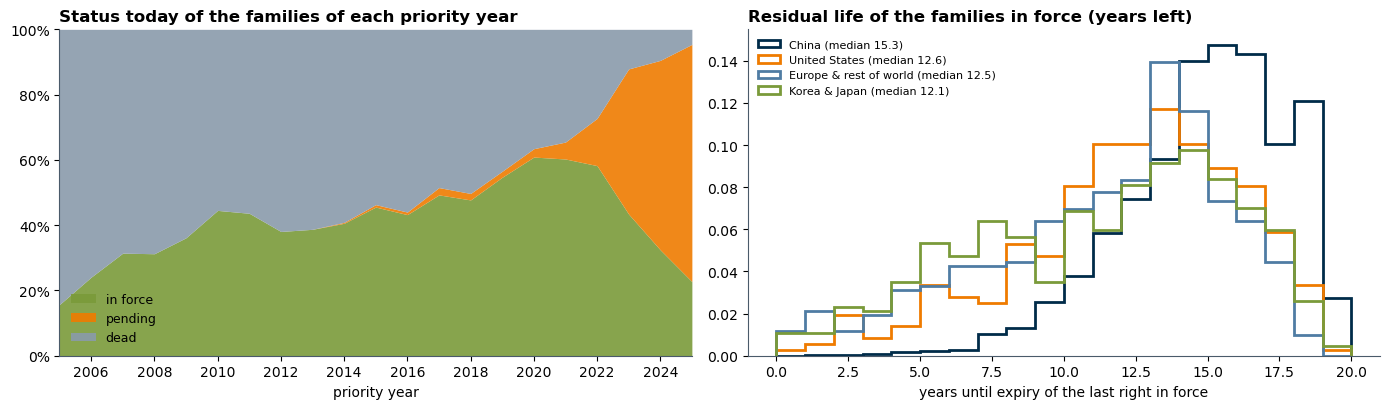

In [24]:
if HAS_LIFE:
    st = fam[fam.family_year.between(2005, YEAR_MAX)].pipe(lambda d: pd.crosstab(d.family_year, d.family_status, normalize="index")) * 100
    st = st[[c for c in ["in force", "pending", "dead"] if c in st.columns]]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    st.plot.area(ax=axes[0], color=[GREEN, ORANGE, MID][:st.shape[1]], alpha=0.9, lw=0)
    axes[0].set(title="Status today of the families of each priority year", xlabel="priority year", ylim=(0, 100))
    axes[0].yaxis.set_major_formatter(PercentFormatter(100)); axes[0].legend(frameon=False, fontsize=9, loc="lower left")
    years_axis(axes[0]); axes[0].margins(x=0)
    inforce = fam[fam.family_status.eq("in force")]
    for grp_, c in [("China", NAVY), ("United States", ORANGE), ("Europe & rest of world", BLUE), ("Korea & Japan", GREEN)]:
        d = inforce.loc[inforce.origin_group.eq(grp_), "family_residual_life_years"].dropna()
        if len(d) > 20:
            axes[1].hist(d, bins=np.arange(0, 21, 1), histtype="step", lw=2, color=c, density=True, label=f"{grp_} (median {d.median():.1f})")
    axes[1].set(title="Residual life of the families in force (years left)", xlabel="years until expiry of the last right in force")
    axes[1].legend(frameon=False, fontsize=8)
    plt.tight_layout(); save(fig, "s1_life_cycle"); plt.show()
    a_ = apps[~apps.appln_auth.eq("WO")].copy()
    a_["months_filing_to_publn"] = pd.to_numeric(a_.get("months_filing_to_publn"), errors="coerce")
    a_["years_filing_to_grant"] = pd.to_numeric(a_.get("years_filing_to_grant"), errors="coerce")
    speed = a_.groupby("appln_auth").agg(applications=("appln_id", "size"), granted=("is_granted", lambda s: s.astype(str).str.lower().eq("true").mean()),
                                         months_to_publication=("months_filing_to_publn", "median"), years_to_grant=("years_filing_to_grant", "median"),
                                         in_force_today=("status", lambda s: s.eq("in force").mean()),
                                         ended_refused=("status", lambda s: s.eq("ended: refused").mean()),
                                         ended_lapsed=("status", lambda s: s.eq("ended: lapsed").mean()))
    _c = fam[fam.family_year <= LAST]     # complete years only: 2023-2025 families are still being examined, not "in force"
    KEY["share_families_in_force"] = float(_c.family_status.eq("in force").mean())
    KEY["share_families_pending"] = float(_c.family_status.eq("pending").mean())
    KEY["share_families_dead"] = float(_c.family_status.eq("dead").mean())
    KEY["share_families_in_force_all_years"] = float(fam.family_status.eq("in force").mean())
    KEY["median_residual_life_in_force"] = float(inforce.family_residual_life_years.median())
    speed.sort_values("applications", ascending=False).head(10).style.format({"applications": "{:,.0f}", "granted": "{:.0%}", "months_to_publication": "{:.1f}",
                                                                             "years_to_grant": "{:.1f}", "in_force_today": "{:.0%}", "ended_refused": "{:.0%}", "ended_lapsed": "{:.0%}"})
else:
    print("Life-cycle dates not in this edition of the step1 tables: re-run 02_clean (Section 9.1) and then this notebook.")

### 1.5.7 Standard-essential patents (SEPs): is the sector exposed?

A **standard-essential patent** covers a technology that any product compliant with a standard must use (4G/5G,
Wi-Fi, video coding...). Owners declare them to the standard body (ETSI, IEEE, ITU) and must license them on
**FRAND** terms (fair, reasonable and non-discriminatory). In SEP-intensive industries (telecom, automotive
connectivity) they are the main source of high-value and high-risk patents. Declarations are **not in PATSTAT**
(they sit in the ETSI IPR database and similar), so the landscape can only measure the **exposure**:

- families in the CPC groups where standardised technologies sit: wireless networks (H04W), digital transmission and
  network protocols (H04L), multiplexing (H04J), radio transmission systems (H04B7), video coding and distribution
  (H04N19, H04N21);
- kept apart, **underwater communication** (H04B11 acoustic, H04B13 through water, H04B10 optical): its standards
  (e.g. NATO JANUS, STANAG 4748) are open and royalty-free, so they do not create SEPs;
- titles that name a standard (LTE, 5G, 3GPP, 802.11/Wi-Fi, Bluetooth, ZigBee, LoRa, NB-IoT, AIS, JANUS, STANAG).

In [25]:
SEP_GROUPS = ("H04W", "H04L", "H04J", "H04B7/", "H04N19/", "H04N21/")
UW_COMM = ("H04B11/", "H04B13/", "H04B10/")
STD_RX = r"\b(?:LTE|5G|4G|3GPP|802\.11|WI-?FI|WIFI|BLUETOOTH|ZIGBEE|LORA|NB-?IOT|AIS|JANUS|STANAG|GSM|GPRS|CDMA)\b"
mgs = fcpc[["docdb_family_id", "main_group"]].drop_duplicates()
sep_fam = set(mgs.loc[mgs.main_group.str.startswith(SEP_GROUPS), "docdb_family_id"])
uw_fam = set(mgs.loc[mgs.main_group.str.startswith(UW_COMM), "docdb_family_id"])
title_txt = fam["title_en"].fillna(fam.get("title", pd.Series("", index=fam.index))).fillna("").str.upper()
std_fam = set(fam.loc[title_txt.str.contains(STD_RX, regex=True), "docdb_family_id"])
fam["sep_exposed"] = fam.docdb_family_id.isin(sep_fam)
fam_c = fam[fam.family_year <= LAST]

sep_tab = pd.DataFrame({
    "families": [len(sep_fam), len(uw_fam), len(std_fam), len(fam)],
    "share of sector": [len(sep_fam) / len(fam), len(uw_fam) / len(fam), len(std_fam) / len(fam), 1.0],
    "international": [fam.loc[fam.docdb_family_id.isin(s), "is_international"].mean() for s in [sep_fam, uw_fam, std_fam]] + [fam.is_international.mean()],
}, index=["standardised telecom groups (SEP-exposed)", "underwater communication (open standards)", "title names a standard", "sector"])
sep_trend = fam[fam.family_year.between(2008, LAST)].groupby("family_year")["sep_exposed"].mean() * 100
sep_owners = (appl[appl.docdb_family_id.isin(sep_fam)].groupby("applicant")["weight"].sum().sort_values(ascending=False).head(10)
              .to_frame("SEP-exposed families (fractional)"))
sep_owners["country"] = sep_owners.index.map(appl.groupby("applicant")["country"].agg(lambda s: s.mode().iat[0] if s.notna().any() else None))
std_hits = title_txt[fam.docdb_family_id.isin(std_fam)].str.findall(STD_RX).explode().value_counts().head(10)
KEY["sep_exposed_share"] = float(len(sep_fam) / len(fam))

print(f"SEP-exposed families: {len(sep_fam):,} ({pct(len(sep_fam) / len(fam))}); share {sep_trend.loc[2008:2012].mean():.1f}% in 2008-12 "
      f"→ {sep_trend.loc[LAST - 4:LAST].mean():.1f}% in {LAST - 4}-{LAST}. Standards named in titles: {std_hits.to_dict()}")
display(sep_tab.style.format({"families": "{:,.0f}", "share of sector": "{:.1%}", "international": "{:.0%}"}))
short(sep_owners).style.format({"SEP-exposed families (fractional)": "{:.1f}"})

SEP-exposed families: 341 (2.2%); share 0.5% in 2008-12 → 2.6% in 2018-2022. Standards named in titles: {'5G': 7, 'BLUETOOTH': 4, 'WIFI': 1, 'ZIGBEE': 1, '4G': 1}


,families,share of sector,international
standardised telecom groups (SEP-exposed),341,2.2%,7%
underwater communication (open standards),249,1.6%,12%
title names a standard,14,0.1%,7%
sector,"15,694",100.0%,8%


,SEP-exposed families (fractional),country
applicant,,
HARBIN ENGINEERING UNIVERSITY,23.0,CN
CHINESE ACADEMY OF SCIENCES,17.0,CN
CHINA STATE SHIPBUILDING (CSSC),10.5,CN
HOHAI UNIVERSITY,9.0,CN
NORTHWESTERN POLYTECHNICAL UNIVERSITY,8.0,CN
ZHEJIANG UNIVERSITY,7.0,CN
TIANJIN UNIVERSITY,7.0,CN
LEE JEONG YONG,7.0,KR
HANGZHOU DIANZI UNIVERSITY,5.0,CN


**Reading.** If the exposed share is small and made of domestic, non-declared families, the sector is **not
SEP-intensive**: value and risk come from proprietary platform patents (vehicle, docking, navigation, energy), not
from standards. The residual exposure is in the radio, satellite and network links of the surface segment (USV, buoys,
docking stations): there the client will **pay** FRAND royalties through the communication modules it buys, not
collect them. To state in the appendix: no declaration database was queried; a real SEP check would match the
exposed families against the ETSI IPR database.

### 1.5.8 Which patents matter more? Family size, grants and forward citations

The three attributes of `tls201` that signal value (Tutorial 1 nb 10 §3.7–3.9): **family size** (in how many offices
the owner pays for protection), **grant**, and **forward citations** (`nb_citing_docdb_fam`: how many later families
cite it). Citations need time to arrive, so recent families are cited less *by construction*: per priority year we
show the mean, the median and the share of families **cited at least once**, and the 5-year window count (`fwd_cits_5y`)
only for families whose window is complete. The distribution is very skewed: a few families collect most citations.

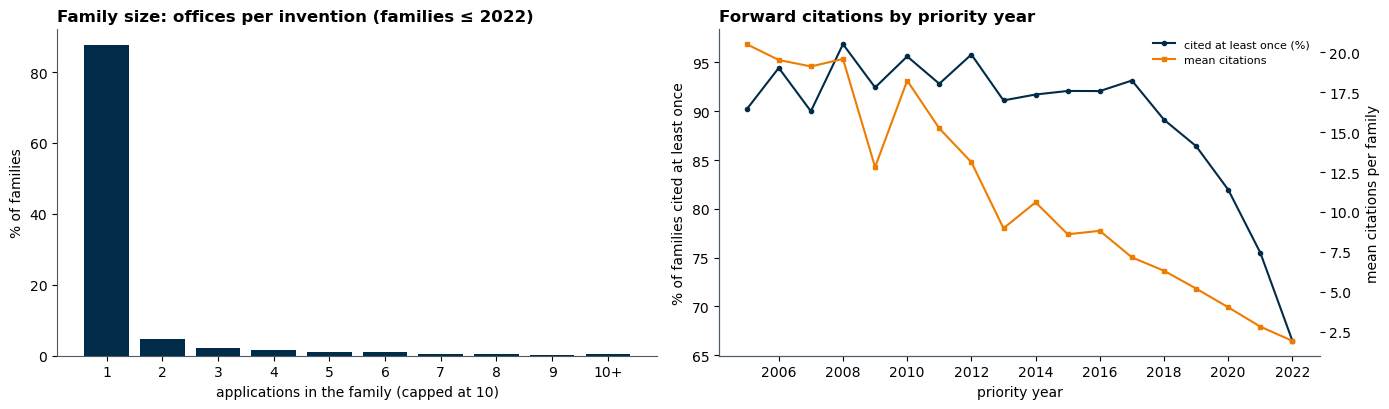

83.8% of the families are cited at least once; the top 1% of families collect 12.5% of all forward citations (counted in nb_citing_docdb_fam).


,mean,median
origin,,
first filed in CN,1.05,1.00
rest of the world,2.23,1.00


,families,mean,median,cited_at_least_once,"mean, 5-year window (complete windows only)"
family_year,,,,,
2005,51,20.51,12.0,90%,5.06
2006,54,19.52,16.0,94%,4.11
2007,70,19.11,13.0,90%,4.63
2008,96,19.58,13.0,97%,5.38
2009,119,12.81,10.0,92%,3.96
2010,137,18.23,13.0,96%,6.76
2011,181,15.23,9.0,93%,5.50
2012,239,13.11,9.0,96%,6.10
2013,315,8.97,6.0,91%,4.68


In [26]:
fz = fam[fam.family_year <= LAST]
size_cap = fz["docdb_family_size"].clip(upper=10)
size_dist = size_cap.value_counts(normalize=True).sort_index()
size_dist.index = [str(int(i)) if i < 10 else "10+" for i in size_dist.index]
size_by_origin = (fz.assign(size=size_cap, origin=np.where(fz.first_office.eq("CN"), "first filed in CN", "rest of the world"))
                  .groupby("origin")["size"].describe()[["mean", "50%"]].rename(columns={"50%": "median"}))
cit_col = "nb_citing_docdb_fam" if "nb_citing_docdb_fam" in fz else "fwd_cits"
cit = fz.groupby("family_year").agg(families=("docdb_family_id", "size"), mean=(cit_col, "mean"), median=(cit_col, "median"),
                                     cited_at_least_once=(cit_col, lambda c: (c > 0).mean()))
if {"fwd_cits_5y", "fwd_window_complete"} <= set(fz.columns):
    w5 = fz[fz.fwd_window_complete.astype(str).str.lower().eq("true")]
    cit["mean, 5-year window (complete windows only)"] = w5.groupby("family_year")["fwd_cits_5y"].mean()
top1 = fz[cit_col].sort_values(ascending=False)
KEY["share_citations_top1pct_families"] = float(top1.head(max(1, len(top1) // 100)).sum() / top1.sum()) if top1.sum() else np.nan
KEY["share_families_cited_at_least_once"] = float((fz[cit_col] > 0).mean())
save_table(size_dist.rename("share of families"), "family_size_distribution"); save_table(cit, "forward_citations_by_year")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(size_dist.index, size_dist.values * 100, color=NAVY)
axes[0].set(title="Family size: offices per invention (families ≤ 2022)", xlabel="applications in the family (capped at 10)", ylabel="% of families")
ax2 = axes[1]; cc = cit.loc[2005:LAST]
ax2.plot(cc.index, cc["cited_at_least_once"] * 100, marker="o", ms=3, color=NAVY, label="cited at least once (%)")
ax2.set(title="Forward citations by priority year", xlabel="priority year", ylabel="% of families cited at least once"); ax2.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax3 = ax2.twinx(); ax3.plot(cc.index, cc["mean"], marker="s", ms=3, color=ORANGE, label="mean citations"); ax3.set_ylabel("mean citations per family")
h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = ax3.get_legend_handles_labels(); ax2.legend(h1 + h2, l1 + l2, frameon=False, fontsize=8)
plt.tight_layout(); save(fig, "s1_family_size_citations"); plt.show()
print(f"{KEY['share_families_cited_at_least_once']:.1%} of the families are cited at least once; the top 1% of families "
      f"collect {KEY['share_citations_top1pct_families']:.1%} of all forward citations (counted in {cit_col}).")
display(size_by_origin.style.format("{:.2f}").set_caption("Family size (capped at 10) by origin"))
cit.loc[2005:YEAR_MAX].style.format({"families": "{:,.0f}", "mean": "{:.2f}", "median": "{:.1f}", "cited_at_least_once": "{:.0%}",
                                     "mean, 5-year window (complete windows only)": "{:.2f}"}, na_rep="–")

### 1.5.6 Argued paragraph (draft, to complete with sources)

Fill the brackets with the numbers printed above (also in `key_numbers.json`) and check every claim on a source:

> *Underwater drones are a sector where patents measure **research effort** more than **market power**. Patent
> leadership is held by Chinese universities and state groups ([share]% of families owned by universities), while the
> firms that lead the market hold few families (Kongsberg [n], Saab [n], Teledyne [n]). [x]% of the families are
> filed in one office only, and Chinese families go abroad in [y]% of cases against [z]% for US-origin ones. Market
> leaders appropriate value mainly through **secrecy, system complexity and lead time**, and through
> **public procurement** in defence (IM_Theory_0; Cohen et al., 2000; Arundel, 2001): naval programmes can also be
> covered by secrecy orders, which keeps them out of patent data altogether. Patents are rarely fought over
> (EPO opposition rate [o]% vs about 4% on average at the EPO, 2-3% in recent years). For the client this means two things: patent counts
> overstate Chinese and academic players, so Step 3 must weigh quality (citations, internationalisation), and the
> valuable know-how of a target sits partly outside its patent portfolio (people, software, contracts).*

In [27]:
# numbers for the brackets of the paragraph (all computed above)
own_t = tshare.loc["ALL"]
print(f"[share]  universities {own_t.get('university', 0):.0%} + public bodies {own_t.get('government / non-profit', 0):.0%} "
      f"| firms {own_t.get('firm', 0):.0%} | unknown {own_t.get('unknown', 0):.0%}")
print("[n]  families of the market leaders:", {k: int(v) for k, v in ml["families"].dropna().items()})
print(f"[x]  families filed in one office only: {(fam_c.n_offices == 1).mean():.0%}")
print(f"[y] / [z]  international share, China origin {intl.loc['China', 'international']:.0%}"
      + (f" vs US origin {intl.loc['United States', 'international']:.0%}" if "United States" in intl.index else ""))
print(f"[o]  EPO opposition rate {opp_rate:.1%} (95% CI {opp_lo:.1%}–{opp_hi:.1%})")

[share]  universities 48% + public bodies 9% | firms 34% | unknown 2%
[n]  families of the market leaders: {'KONGSBERG': 10, 'TELEDYNE': 9, 'SAAB': 12, 'GENERAL DYNAMICS (BLUEFIN)': 4, 'L3HARRIS': 7, 'HUNTINGTON INGALLS (HYDROID)': 2, 'EXAIL (ECA)': 14, 'OCEANEERING': 45, 'TKMS (ATLAS ELEKTRONIK)': 96, 'NAVAL GROUP': 22, 'BAE SYSTEMS': 41, 'HANWHA': 101, 'FINCANTIERI': 3}
[x]  families filed in one office only: 89%
[y] / [z]  international share, China origin 3% vs US origin 34%
[o]  EPO opposition rate 2.5% (95% CI 1.3%–4.8%)


## 1.6 Where does knowledge come from? Science, technologies and players the sector builds on

The third question of the technological perspective (IM_Theory_3: *"where knowledge comes from: citations to
patents and to science"*). Backward citations are the prior art an invention builds on: citations to **non-patent
literature (NPL)**, mostly scientific papers, measure the **science linkage** of the field; citations to **patents**
show which technologies and which players feed it. Forward citations show where the sector's knowledge goes next.
This is also the first bridge to the economic perspective: a source of knowledge is a potential partner, licensor or
target, and a knowledge flow across countries is a spillover (IM_Theory_4).

Data from `02_clean` §6: `citations_backward.csv` (family → cited family, distinct pairs), `citations_forward.csv`,
`cited_citing_cpc.csv` (CPC subclasses of the families outside the sector), NPL counts in `families.csv`.

Caveats to state in the appendix: citation practice differs by office (Chinese and Korean search reports cite little
NPL and few foreign documents), so every comparison is repeated on **international families**; the most recent years
may have incomplete search reports; examiners add most citations, so they measure *relatedness* more than the
inventor's own learning (Alcácer & Gittelman, 2006).

In [28]:
bwd = pd.read_csv(IN / "citations_backward.csv")
bwd = bwd[bwd.docdb_family_id.isin(set(fam.docdb_family_id))].copy()
bwd["cited_in_sector"] = bwd["cited_in_sector"].astype(str).str.lower().eq("true") & bwd["cited_family_id"].isin(set(fam.docdb_family_id))
ccc = pd.read_csv(IN / "cited_citing_cpc.csv")
for c in ["bwd_npl_cits", "bwd_cits"]:
    fam[c] = pd.to_numeric(fam[c], errors="coerce").fillna(0)
fam["cites_science"] = fam["bwd_npl_cits"].gt(0)
fam["cites_anything"] = (fam["bwd_npl_cits"] + fam["bwd_cits"]).gt(0)
fam_c = fam[fam.family_year <= LAST]
in_sector = set(fam["docdb_family_id"])
fam_year = fam.set_index("docdb_family_id")["family_year"]
fam_origin = fam.set_index("docdb_family_id")["origin_group"]
period = lambda y: np.where(pd.Series(y).between(*PAST), f"{PAST[0]}–{PAST[1]}",
                            np.where(pd.Series(y).between(*RECENT), f"{RECENT[0]}–{RECENT[1]}", None))

### 1.6.1 Science linkage: does the field build on science, and more and more?

Share of families citing at least one non-patent document, among the families with any recorded prior art (families
without a search report would lower the share for reasons that have nothing to do with science). The NPL share is
NPL references / (NPL references + cited patent families).

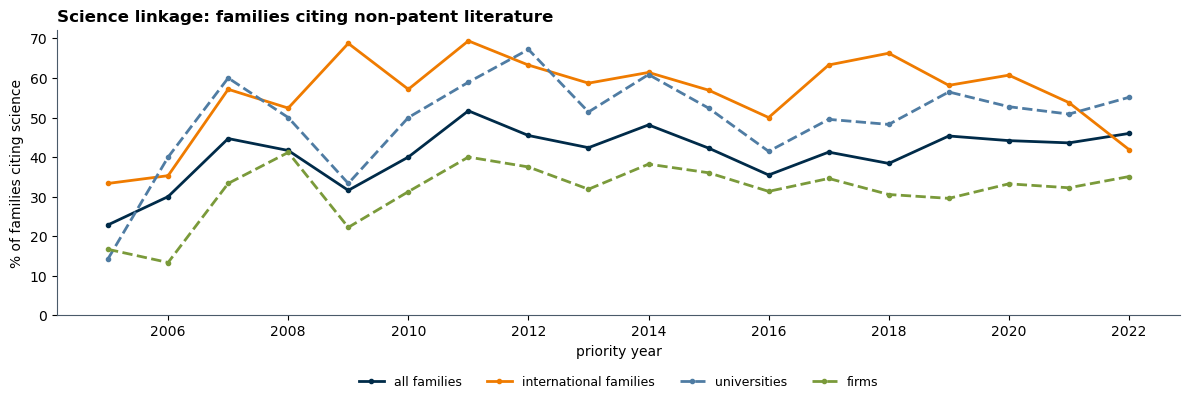

,cite science (≥1 NPL),title
subclass,,
G01C,80.9%,"Measuring distances, levels or bearings; surveying; navigation; gyroscopic instruments; photogrammetry"
G05B,79.9%,Control or regulating systems in general; monitoring or testing arrangements for such systems
G05D,76.5%,Systems for controlling or regulating non-electric variables
G01S,59.1%,Radio direction-finding; radio navigation; determining distance or velocity by use of radio waves; locating or presence-detecting by reflection of waves; analogous arrangements using other waves (sonar)
Y02A,50.1%,Technologies for adaptation to climate change (tagging)
B63G,30.4%,Offensive or defensive arrangements on vessels; mine-laying; mine-sweeping; submarines; aircraft carriers
B63B,28.5%,Ships or other waterborne vessels; equipment for shipping
B63H,28.2%,Marine propulsion or steering
B25J,27.8%,Manipulators; chambers provided with manipulation devices


In [29]:
def science(d):
    d = d[d["cites_anything"]]
    npl, pat = d["bwd_npl_cits"].sum(), d["bwd_cits"].sum()
    return pd.Series({"families with prior art": len(d), "cite science (≥1 NPL)": d["cites_science"].mean() if len(d) else np.nan,
                      "NPL share of references": npl / (npl + pat) if npl + pat else np.nan})

d = fam_c[fam_c.family_year >= 2005]
sci_year = pd.DataFrame({"all families": d.groupby("family_year").apply(lambda g: science(g)["cite science (≥1 NPL)"]),
                         "international families": d[d.is_international].groupby("family_year").apply(lambda g: science(g)["cite science (≥1 NPL)"]),
                         "universities": d[d.main_type.eq("university")].groupby("family_year").apply(lambda g: science(g)["cite science (≥1 NPL)"]),
                         "firms": d[d.main_type.eq("firm")].groupby("family_year").apply(lambda g: science(g)["cite science (≥1 NPL)"])})
sci_grp = pd.concat({"origin": fam_c.groupby("origin_group").apply(science),
                     "owner type": fam_c.groupby("main_type").apply(science),
                     "origin (international only)": fam_c[fam_c.is_international].groupby("origin_group").apply(science)})
sci_grp.loc[("sector", "all"), :] = science(fam_c)

# science linkage of the main subfields (CPC subclasses, fractional counting)
top_sub = fsub.groupby("subclass")["weight"].sum().sort_values(ascending=False).head(10).index
fs = fsub[fsub.subclass.isin(top_sub)].merge(fam_c[["docdb_family_id", "cites_science", "cites_anything"]], on="docdb_family_id")
fs = fs[fs.cites_anything]
sci_sub = (fs.assign(w_sci=fs.weight * fs.cites_science).groupby("subclass")[["w_sci", "weight"]].sum()
           .pipe(lambda t: (t.w_sci / t.weight).rename("cite science (≥1 NPL)")).sort_values(ascending=False).to_frame())
sci_sub["title"] = sci_sub.index.map(lambda s: CPC_TITLES.get(s, ""))

KEY["share_cite_science"] = float(sci_grp.loc[("sector", "all"), "cite science (≥1 NPL)"])
KEY["npl_share_refs"] = float(sci_grp.loc[("sector", "all"), "NPL share of references"])

fig, ax = plt.subplots(figsize=(12, 4.2))
for col, c, ls in zip(sci_year.columns, [NAVY, ORANGE, BLUE, GREEN], ["-", "-", "--", "--"]):
    ax.plot(sci_year.index, sci_year[col] * 100, color=c, ls=ls, lw=2, marker="o", ms=3, label=col)
ax.set(ylabel="% of families citing science", xlabel="priority year", ylim=(0, None),
       title="Science linkage: families citing non-patent literature")
years_axis(ax)
ax.legend(frameon=False, ncol=4, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.17))
plt.tight_layout(); save(fig, "1_6_science_linkage"); plt.show()
display(sci_grp.style.format({"families with prior art": "{:,.0f}", "cite science (≥1 NPL)": "{:.1%}", "NPL share of references": "{:.1%}"}, na_rep="–"))
sci_sub.style.format({"cite science (≥1 NPL)": "{:.1%}"})

### 1.6.2 Which technologies does the sector draw on?

Each backward link (citing family → cited patent family) is classified as **inside the sector** (the cited family is
itself an underwater-drone family) or **outside**. Outside links are spread over the CPC subclasses of the cited family
(fractional: 1 / number of its subclasses), giving the technologies the sector imports knowledge from. Comparing the
past window with the recent one shows whether the sector is turning to new sources (e.g. computing and AI).

In [30]:
b = bwd.merge(fam[["docdb_family_id", "family_year", "origin_group", "is_international"]], on="docdb_family_id")
b = b[b.family_year <= LAST]
b["period"] = period(b["family_year"].values)
self_feed = pd.DataFrame({"links": b.groupby("period").size(), "share inside the sector": b.groupby("period")["cited_in_sector"].mean()})
self_feed.loc["all years"] = [len(b), b["cited_in_sector"].mean()]

out_links = b[~b.cited_in_sector]
cw = ccc.assign(w=1 / ccc.groupby("docdb_family_id")["subclass"].transform("size"))
ext = out_links.merge(cw.rename(columns={"docdb_family_id": "cited_family_id"}), on="cited_family_id")
coverage = out_links["cited_family_id"].isin(set(ccc.docdb_family_id)).mean()
ext_mix = ext.groupby(["period", "subclass"])["w"].sum().unstack(0).fillna(0)
ext_mix = ext_mix / ext_mix.sum()
ext_mix["all years"] = ext.groupby("subclass")["w"].sum() / ext["w"].sum()
p_lab, r_lab = f"{PAST[0]}–{PAST[1]}", f"{RECENT[0]}–{RECENT[1]}"
if {p_lab, r_lab} <= set(ext_mix.columns):
    ext_mix["change (pp)"] = (ext_mix[r_lab] - ext_mix[p_lab]) * 100
ext_top = ext_mix.sort_values("all years", ascending=False).head(TOP_N)
ext_top.insert(0, "title", ext_top.index.map(lambda s: CPC_TITLES.get(s, "")))
KEY["share_backward_inside_sector"] = float(b["cited_in_sector"].mean())
KEY["top_external_source"] = str(ext_top.index[0]) if len(ext_top) else None

print(f"backward patent links: {len(b):,} | inside the sector: {pct(b['cited_in_sector'].mean())} | "
      f"outside links with CPC of the cited family: {pct(coverage)}")
display(self_feed.style.format({"links": "{:,.0f}", "share inside the sector": "{:.1%}"}))
num = [c for c in ext_top.columns if c != "title"]
ext_top.style.format({c: ("{:+.2f}" if c == "change (pp)" else "{:.1%}") for c in num}, na_rep="–")

backward patent links: 74,665 | inside the sector: 27.2% | outside links with CPC of the cited family: 66.5%


,links,share inside the sector
period,,
2013–2017,"18,231",24.4%
2018–2022,"47,075",31.5%
all years,"74,665",27.2%


period,title,2013–2017,2018–2022,all years,change (pp)
subclass,,,,,
B63B,Ships or other waterborne vessels; equipment for shipping,8.4%,6.9%,7.8%,-1.51
B63G,Offensive or defensive arrangements on vessels; mine-laying; mine-sweeping; submarines; aircraft carriers,8.1%,6.1%,7.1%,-2.06
G01S,Radio direction-finding; radio navigation; determining distance or velocity by use of radio waves; locating or presence-detecting by reflection of waves; analogous arrangements using other waves (sonar),5.4%,5.1%,5.2%,-0.28
E21B,"Earth or rock drilling; obtaining oil, gas or water from wells",5.5%,2.2%,4.4%,-3.28
B63C,"Launching, hauling-out or dry-docking of vessels; life-saving in water; equipment for dwelling or working underwater; means for searching for or salvaging underwater objects",4.1%,4.2%,4.3%,+0.08
G01V,Geophysics; gravitational measurements; detecting masses or objects; tags,4.9%,2.6%,4.0%,-2.32
B63H,Marine propulsion or steering,3.3%,4.5%,4.0%,+1.16
G05D,Systems for controlling or regulating non-electric variables,2.1%,5.1%,3.7%,+2.99
G01C,"Measuring distances, levels or bearings; surveying; navigation; gyroscopic instruments; photogrammetry",2.2%,4.1%,3.1%,+1.87


### 1.6.3 Whose knowledge, and from which countries?

Inside the sector we know who owns the cited families, so the knowledge flows can be followed between players and
countries. **Self-citations** (citing and cited family share an applicant group) measure cumulative, internal learning;
they are excluded from the ranking of knowledge sources, which counts the citations each group *receives from others*
(fractional over the owners of the cited family). The origin × origin matrix shows the **home bias** of knowledge
flows: read each row as "where the knowledge cited by families of this origin comes from".

links inside the sector: 20,329 | self-citations: 14.0% | citations received by the client from others: 4.0


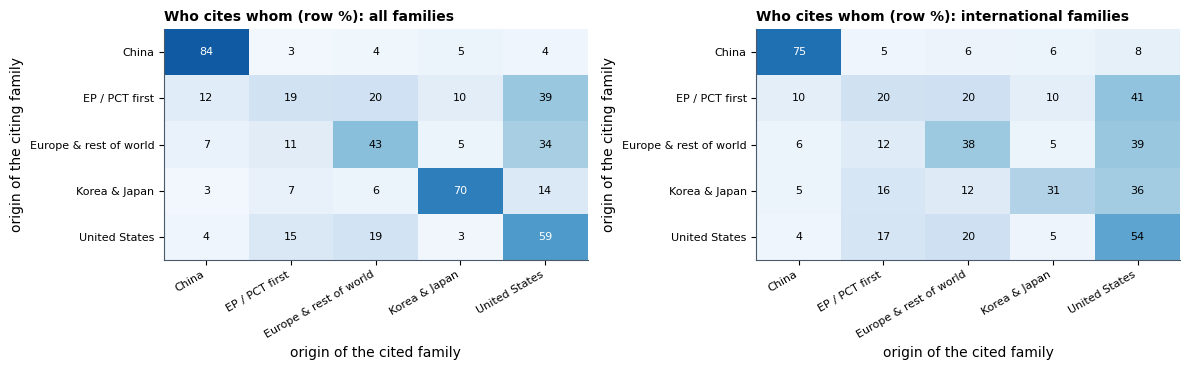

,citations received from others,families,citations per family,type,country,is client
applicant,,,,,,
HARBIN ENGINEERING UNIVERSITY,1632.5,1205.7,1.35,university,CN,False
CHINESE ACADEMY OF SCIENCES,929.5,785.0,1.18,university,CN,False
ZHEJIANG UNIVERSITY,567.3,357.5,1.59,university,CN,False
CHINA STATE SHIPBUILDING (CSSC),523.5,658.6,0.79,firm,CN,False
NORTHWESTERN POLYTECHNICAL UNIVERSITY,494.0,567.2,0.87,university,CN,False
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,270.0,201.7,1.34,university,CN,False
HOHAI UNIVERSITY,262.0,151.2,1.73,university,CN,False
TIANJIN UNIVERSITY,235.8,187.7,1.26,university,CN,False
OCEAN UNIVERSITY OF CHINA,223.5,148.2,1.51,university,CN,False


In [31]:
own = appl[["docdb_family_id", "applicant", "weight"]]
ins = b[b.cited_in_sector][["docdb_family_id", "cited_family_id", "origin_group", "is_international", "family_year"]].copy()
grp_sets = own.groupby("docdb_family_id")["applicant"].agg(set).to_dict()
ins["self"] = [bool(grp_sets.get(a, set()) & grp_sets.get(c, set())) for a, c in zip(ins.docdb_family_id, ins.cited_family_id)]
ins["cited_origin"] = ins["cited_family_id"].map(fam_origin)
KEY["share_self_citations"] = float(ins["self"].mean()) if len(ins) else np.nan

flows_k = pd.crosstab(ins["origin_group"], ins["cited_origin"], normalize="index")
flows_k_int = pd.crosstab(ins.loc[ins.is_international, "origin_group"], ins.loc[ins.is_international, "cited_origin"], normalize="index")

src = (ins[~ins["self"]].merge(own.rename(columns={"docdb_family_id": "cited_family_id"}), on="cited_family_id")
       .groupby("applicant")["weight"].sum().rename("citations received from others").sort_values(ascending=False))
fam_n = appl.groupby("applicant")["weight"].sum()
sources = src.head(TOP_N).to_frame()
sources["families"] = fam_n.reindex(sources.index)
sources["citations per family"] = sources.iloc[:, 0] / sources["families"]
sources["type"] = sources.index.map(prof.set_index("applicant")["type"]) if "type" in prof.columns else ""
sources["country"] = sources.index.map(appl.groupby("applicant")["country"].agg(lambda s: s.mode().iat[0] if s.notna().any() else None))
sources["is client"] = sources.index == CLIENT
client_src = src.get(CLIENT, 0.0)

print(f"links inside the sector: {len(ins):,} | self-citations: {pct(ins['self'].mean()) if len(ins) else '–'} | "
      f"citations received by the client from others: {client_src:.1f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, m, t in zip(axes, [flows_k, flows_k_int], ["all families", "international families"]):
    im = ax.imshow(m.values * 100, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(m.shape[1]), m.columns, rotation=30, ha="right", fontsize=8); ax.set_yticks(range(m.shape[0]), m.index, fontsize=8)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{100 * m.values[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if m.values[i, j] > 0.55 else "black")
    ax.set_title(f"Who cites whom (row %): {t}", fontsize=10); ax.set_xlabel("origin of the cited family"); ax.set_ylabel("origin of the citing family")
plt.tight_layout(); save(fig, "1_6_knowledge_flows"); plt.show()
short(sources).style.format({"citations received from others": "{:.1f}", "families": "{:.1f}", "citations per family": "{:.2f}"}, na_rep="–")

### 1.6.4 Where does the sector's knowledge go?

Forward citations, inside a complete 5-year window: the share coming from **outside** the sector says how far the
sector's inventions travel (a hint of *generality*, an ingredient of the Step 4 future score), and the CPC
subclasses of the citing families say which industries use them.

In [32]:
fw = fwd.merge(fam[["docdb_family_id", "origin_group", "fwd_window_complete"]], on="docdb_family_id")
fw = fw[fw.within_5y.astype(str).str.lower().eq("true") & fw.fwd_window_complete]
fw["citing_in_sector"] = fw["citing_in_sector"].astype(str).str.lower().eq("true")
fw_out = fw[~fw.citing_in_sector]
use = fw_out.merge(cw.rename(columns={"docdb_family_id": "citing_family_id"}), on="citing_family_id")
use_mix = (use.groupby("subclass")["w"].sum() / use["w"].sum()).sort_values(ascending=False).head(10).to_frame("share of outside citations")
use_mix.insert(0, "title", use_mix.index.map(lambda s: CPC_TITLES.get(s, "")))
reach = pd.DataFrame({"forward citations (5y)": fw.groupby("origin_group").size(),
                      "share from outside the sector": 1 - fw.groupby("origin_group")["citing_in_sector"].mean()})
reach.loc["all"] = [len(fw), 1 - fw["citing_in_sector"].mean()]
KEY["share_forward_from_outside"] = float(1 - fw["citing_in_sector"].mean()) if len(fw) else np.nan

display(reach.style.format({"forward citations (5y)": "{:,.0f}", "share from outside the sector": "{:.1%}"}))
use_mix.style.format({"share of outside citations": "{:.1%}"})

,forward citations (5y),share from outside the sector
origin_group,,
China,"12,067",54.9%
EP / PCT first,"1,957",70.6%
Europe & rest of world,"1,712",62.8%
Korea & Japan,"1,492",60.9%
United States,"4,012",72.1%
all,"21,240",60.6%


,title,share of outside citations
subclass,,
G05D,Systems for controlling or regulating non-electric variables,6.4%
B63B,Ships or other waterborne vessels; equipment for shipping,6.3%
G01S,Radio direction-finding; radio navigation; determining distance or velocity by use of radio waves; locating or presence-detecting by reflection of waves; analogous arrangements using other waves (sonar),6.1%
B63G,Offensive or defensive arrangements on vessels; mine-laying; mine-sweeping; submarines; aircraft carriers,4.8%
G01C,"Measuring distances, levels or bearings; surveying; navigation; gyroscopic instruments; photogrammetry",4.7%
B63C,"Launching, hauling-out or dry-docking of vessels; life-saving in water; equipment for dwelling or working underwater; means for searching for or salvaging underwater objects",4.1%
E21B,"Earth or rock drilling; obtaining oil, gas or water from wells",3.5%
B25J,Manipulators; chambers provided with manipulation devices,3.5%
G01N,Investigating or analysing materials (chemical or physical properties),3.5%


### 1.6.5 From knowledge flows to spillovers: are citations more local than chance?

A citation is a **knowledge flow**; it is a **spillover** only if the cited owner was not (fully) paid, which patents
do not say (IM_Theory_4). The proxy is **localisation**: a licence works at any distance, unpaid knowledge travels with
people and stays close, so citations *more local than chance* point to spillovers (Jaffe, Trajtenberg & Henderson,
1993; Tutorial 3, nb 31). Counting local citations is not enough: if most inventors sit in one country, most
citations are "local" anyway. Two benchmarks, on the citations between **different** applicant groups inside the
sector (self-citations out):

- **chance** (Tutorial 3): for each citation, the share of the sector's families of the citing year that have an
  inventor where the cited family has one; averaged over the citations;
- **JTH control** A\*: for each citing family A, a random family of the **same priority year and main CPC subclass**
  that does not cite B and is not owned by B's group; the share of controls located where B is.

Locations are the inventors' countries (the country is filled with the filing office when missing, 1.4: both sides
are treated the same way) and, for European inventors once `02_clean` is re-run, the **NUTS 2 / NUTS 3** regions of
their address. Results are split by the origin of the cited family (China dominates the counts), by the time
between the two families (JTH: localisation is strongest soon after B) and, when `citation_pairs.csv` exists, by who
added the citation: if local knowledge travels through people, **applicant** citations should be more local than
**examiner** citations.

**Why no maps and no distance test.** Tutorial 3 (nb 31 §4–8) draws inventors and flows on a map of Europe and tests
distance in km. We do not: NUTS codes exist only for European inventors, while most of this sector is invented in
China (1.4). A map of Europe would show a minor part of the field as if it were the whole, and the distance test had
too few citations with European inventors on both sides (37 on PROD) to say anything. Localisation is therefore read
at country level and, where available, NUTS 2 / NUTS 3, against chance and matched controls.

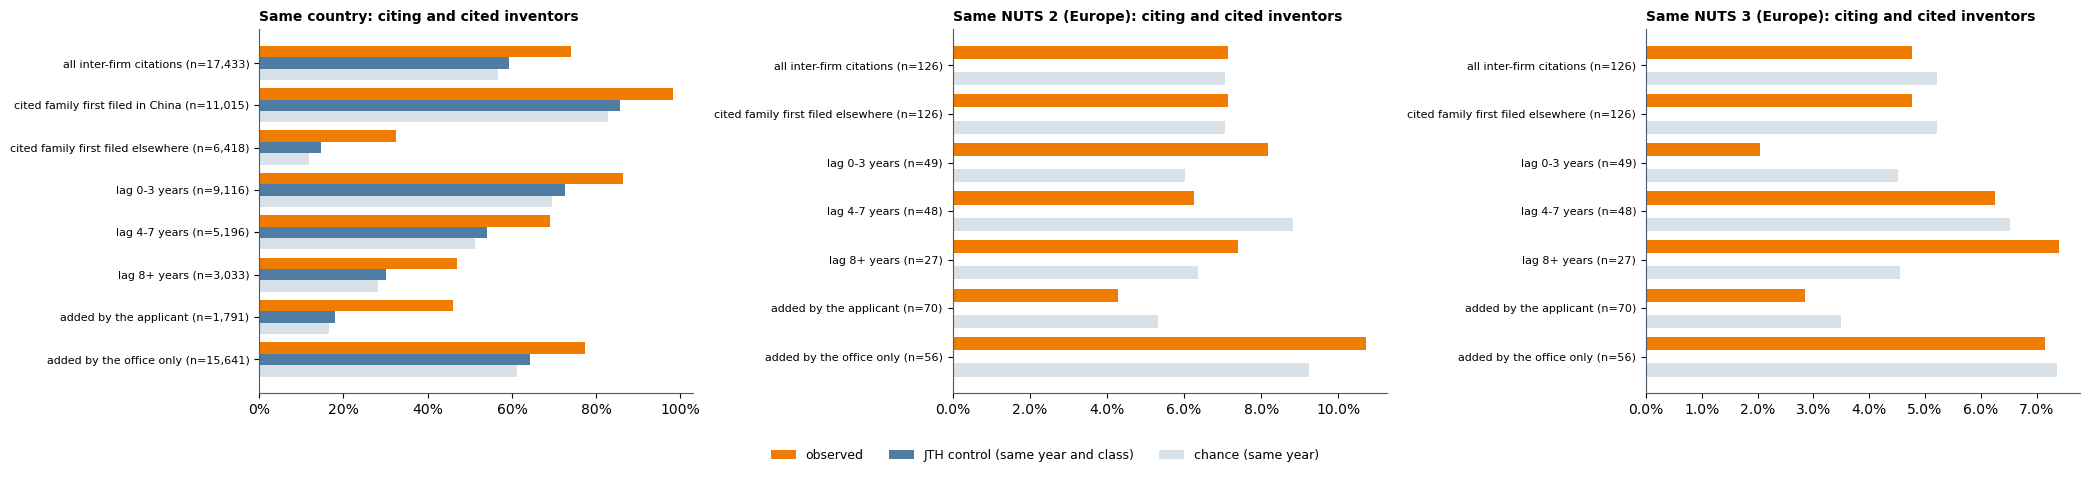

inter-firm citations inside the sector: 17,475 (self-citations removed: 2,854); with a JTH control: 88%. NUTS levels: available


In [33]:
rng_sp = np.random.default_rng(42)
inv_loc = inv.dropna(subset=["country"]).copy()
loc_sets = {"country": inv_loc.groupby("docdb_family_id")["country"].agg(frozenset).to_dict()}
if "nuts" in inv.columns and inv["nuts"].notna().any():
    nu = inv.dropna(subset=["nuts"]).assign(nuts=lambda d: d["nuts"].astype(str).str.strip())
    loc_sets["NUTS 2 (Europe)"] = nu[nu.nuts.str.len() >= 4].groupby("docdb_family_id")["nuts"].agg(lambda s: frozenset(x[:4] for x in s)).to_dict()
    loc_sets["NUTS 3 (Europe)"] = nu[nu.nuts.str.len() >= 5].groupby("docdb_family_id")["nuts"].agg(lambda s: frozenset(x[:5] for x in s)).to_dict()
fy = fam.set_index("docdb_family_id")["family_year"]
main_sub = (fsub.dropna(subset=["weight_tech"]).sort_values(["docdb_family_id", "weight_tech"], ascending=[True, False])
            .drop_duplicates("docdb_family_id").set_index("docdb_family_id")["subclass"])
cites = set(zip(bwd.docdb_family_id, bwd.cited_family_id))
pairs = ins[~ins["self"]][["docdb_family_id", "cited_family_id", "family_year", "origin_group"]].copy()
pairs["cited_year"] = pairs["cited_family_id"].map(fy)
pairs["lag"] = pairs["family_year"] - pairs["cited_year"]
pairs["cited_origin"] = pairs["cited_family_id"].map(fam_origin)
cp_path = IN / "citation_pairs.csv"
if cp_path.exists():
    cpo = pd.read_csv(cp_path)[["docdb_family_id", "cited_family_id", "by_applicant", "by_office"]]
    pairs = pairs.merge(cpo, on=["docdb_family_id", "cited_family_id"], how="left")

# pools for the JTH control: families of the same year and main subclass
pool = fam[["docdb_family_id", "family_year"]].assign(sub=lambda d: d.docdb_family_id.map(main_sub)).dropna()
pool_by = pool.groupby(["family_year", "sub"])["docdb_family_id"].agg(list).to_dict()
grp_of = appl.groupby("docdb_family_id")["applicant"].agg(set).to_dict()

def control_for(a, b):
    cand_ = pool_by.get((fy.get(a), main_sub.get(a)), [])
    for _ in range(20):
        if not cand_:
            return np.nan
        c = cand_[rng_sp.integers(len(cand_))]
        if c not in (a, b) and (c, b) not in cites and not (grp_of.get(c, set()) & grp_of.get(b, set())):
            return c
    return np.nan

pairs["control"] = [control_for(a, b) for a, b in zip(pairs.docdb_family_id, pairs.cited_family_id)]

def localisation(df, level):
    """observed, chance and JTH-control shares of citations whose citing (or control) family shares a location with the cited one."""
    L = loc_sets[level]
    d = df[df.docdb_family_id.isin(L) & df.cited_family_id.isin(L)]
    if d.empty:
        return pd.Series({"citations": 0})
    same = [bool(L[a] & L[b]) for a, b in zip(d.docdb_family_id, d.cited_family_id)]
    # chance: share of the families of the citing year located where the cited family is
    by_year = pd.Series(L).rename("loc").to_frame().join(fy).dropna().groupby("family_year")["loc"].agg(list).to_dict()
    cache = {}
    def chance(y, S):
        key = (y, S)
        if key not in cache:
            fams_ = by_year.get(y, [])
            cache[key] = np.mean([bool(x & S) for x in fams_]) if fams_ else np.nan
        return cache[key]
    ch = [chance(y, L[b]) for y, b in zip(d.family_year, d.cited_family_id)]
    dc = d.dropna(subset=["control"])
    dc = dc[dc.control.isin(L)]
    ctrl = [bool(L[int(c)] & L[b]) for c, b in zip(dc.control, dc.cited_family_id)]
    obs = float(np.mean(same)); chn = float(np.nanmean(ch)); con = float(np.mean(ctrl)) if ctrl else np.nan
    lo, hi = wilson(int(np.sum(same)), len(same))
    return pd.Series({"citations": len(d), "observed": obs, "observed 95% CI": f"{lo:.0%}–{hi:.0%}", "chance": chn,
                      "JTH control": con, "observed / chance": obs / chn if chn else np.nan,
                      "observed / control": obs / con if con else np.nan})

subsets = {"all inter-firm citations": pairs,
           "cited family first filed in China": pairs[pairs.cited_origin.eq("China")],
           "cited family first filed elsewhere": pairs[~pairs.cited_origin.eq("China")],
           "lag 0-3 years": pairs[pairs.lag.between(0, 3)], "lag 4-7 years": pairs[pairs.lag.between(4, 7)],
           "lag 8+ years": pairs[pairs.lag >= 8]}
if "by_applicant" in pairs.columns:
    subsets["added by the applicant"] = pairs[pairs.by_applicant.fillna(False).astype(bool)]
    subsets["added by the office only"] = pairs[pairs.by_office.fillna(False).astype(bool) & ~pairs.by_applicant.fillna(False).astype(bool)]
loc_tab = pd.concat({lvl: pd.DataFrame({k: localisation(v, lvl) for k, v in subsets.items()}).T for lvl in loc_sets})
save_table(loc_tab, "spillovers_localisation")
KEY["localisation_country_obs_over_chance"] = float(loc_tab.loc[("country", "all inter-firm citations"), "observed / chance"])
KEY["localisation_country_obs_over_control"] = float(loc_tab.loc[("country", "all inter-firm citations"), "observed / control"])

plot_rows = [r for r in ["all inter-firm citations", "cited family first filed in China", "cited family first filed elsewhere",
                         "lag 0-3 years", "lag 4-7 years", "lag 8+ years", "added by the applicant", "added by the office only"] if r in subsets]
fig, axes = plt.subplots(1, len(loc_sets), figsize=(7 * len(loc_sets), 4.6), squeeze=False)
for ax, lvl in zip(axes[0], loc_sets):
    t = loc_tab.loc[lvl].reindex(plot_rows)
    t = t[t["citations"].fillna(0) > 0]          # subsets with no citation at this level (e.g. China at NUTS) left out
    y_ = np.arange(len(t))
    ax.barh(y_ - 0.27, t["observed"].astype(float) * 100, 0.27, color=ORANGE, label="observed")
    ax.barh(y_, t["JTH control"].astype(float) * 100, 0.27, color=BLUE, label="JTH control (same year and class)")
    ax.barh(y_ + 0.27, t["chance"].astype(float) * 100, 0.27, color=LIGHT, label="chance (same year)")
    ax.set_yticks(y_, [f"{r} (n={int(n):,})" for r, n in zip(t.index, t["citations"].fillna(0))], fontsize=8); ax.invert_yaxis()
    ax.xaxis.set_major_formatter(PercentFormatter(100)); ax.set_title(f"Same {lvl}: citing and cited inventors", fontsize=10)
h_, l_ = axes[0][0].get_legend_handles_labels()
fig.legend(h_, l_, frameon=False, fontsize=9, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.05, 1, 1)); save(fig, "s1_spillovers_localisation"); plt.show()
# deck version: the country panel alone (NUTS levels have too few European citations to say anything on a slide)
t = loc_tab.loc["country"].reindex(plot_rows); t = t[t["citations"].fillna(0) > 0]; y_ = np.arange(len(t))
fig, ax = plt.subplots(figsize=(8.5, 5.4))
ax.barh(y_ - 0.27, t["observed"].astype(float) * 100, 0.27, color=ORANGE, label="observed")
ax.barh(y_, t["JTH control"].astype(float) * 100, 0.27, color=BLUE, label="JTH control (same year and class)")
ax.barh(y_ + 0.27, t["chance"].astype(float) * 100, 0.27, color=LIGHT, label="chance (same year)")
ax.set_yticks(y_, [f"{r} (n={int(n):,})" for r, n in zip(t.index, t["citations"].fillna(0))], fontsize=9); ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(100)); ax.set_xlim(0, 105)
ax.set_title("Citing and cited inventors in the same country", fontsize=11)
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper center", bbox_to_anchor=(0.4, -0.08))
plt.tight_layout(); save(fig, "s1_spillovers_country"); plt.close(fig)
print(f"inter-firm citations inside the sector: {len(pairs):,} (self-citations removed: {int(ins['self'].sum()):,}); "
      f"with a JTH control: {pairs['control'].notna().mean():.0%}. NUTS levels: "
      + ("available" if len(loc_sets) > 1 else "after the re-run of 02_clean (nuts of TLS206)"))
loc_tab.style.format({"citations": "{:,.0f}", "observed": "{:.1%}", "chance": "{:.1%}", "JTH control": "{:.1%}",
                      "observed / chance": "{:.2f}×", "observed / control": "{:.2f}×"}, na_rep="–")

### 1.6.6 Paid or not? Separating market transactions from possible spillovers

The slide's question, *did X's owner get paid for it?*, on the data we have: a citation pair is a **possible market
transaction** when the cited family has a **licence** recorded, when it was **transferred to the citing group**
(ownership events of `02_clean` §9.2), or when the two groups **co-own** other families of the sector (joint work,
usually under contract). Every other inter-firm citation leaves no trace of payment: a **possible spillover**. If
localisation is a sign of unpaid exchange, it should be stronger in the second group. Caveats: most licences and
contracts are never recorded (so "no trace" is an upper bound of spillovers), and Chinese legal events rarely carry
names.

In [34]:
lic_fams_sp = set(legal.loc[legal.ev_licence.astype(str).str.lower().eq("true"), "docdb_family_id"])
pairs["citing groups"] = pairs.docdb_family_id.map(grp_of); pairs["cited groups"] = pairs.cited_family_id.map(grp_of)
coown = appl.groupby("docdb_family_id")["applicant"].agg(lambda s: sorted(set(s)))
co_pairs = {(a, b) for gs in coown for a in gs for b in gs if a != b}
oe_path = IN / "ownership_events.csv"
moved_to = {}
if oe_path.exists():
    oe = pd.read_csv(oe_path)
    oe = oe[oe["is_real_change"].astype(bool) & oe["new_owner"].notna()]
    moved_to = oe.groupby("docdb_family_id")["new_owner"].agg(set).to_dict()

def paid_flag(r):
    cg = r["citing groups"] if isinstance(r["citing groups"], set) else set()
    dg = r["cited groups"] if isinstance(r["cited groups"], set) else set()
    if r["cited_family_id"] in lic_fams_sp:
        return "licence recorded on the cited family"
    if moved_to.get(r["cited_family_id"], set()) & cg:
        return "cited family transferred to the citing group"
    if any((a, b) in co_pairs for a in cg for b in dg):
        return "the two groups co-own families"
    return "no trace of payment (possible spillover)"

pairs["paid?"] = pairs.apply(paid_flag, axis=1)
paid_tab = pairs["paid?"].value_counts().rename("citations").to_frame()
paid_tab["share"] = paid_tab["citations"] / paid_tab["citations"].sum()
loc_paid = pd.DataFrame({k: localisation(pairs[pairs["paid?"].eq(k) if k != "possible market transaction (any trace)" else
                                                ~pairs["paid?"].str.startswith("no trace")], "country")
                         for k in ["no trace of payment (possible spillover)", "possible market transaction (any trace)"]}).T
save_table(paid_tab, "spillovers_paid_or_not"); save_table(loc_paid, "spillovers_localisation_paid_or_not")
KEY["share_citations_no_payment_trace"] = float(paid_tab.loc["no trace of payment (possible spillover)", "share"]) if "no trace of payment (possible spillover)" in paid_tab.index else np.nan
display(paid_tab.style.format({"citations": "{:,.0f}", "share": "{:.1%}"}))
loc_paid.style.format({"citations": "{:,.0f}", "observed": "{:.1%}", "chance": "{:.1%}", "JTH control": "{:.1%}",
                       "observed / chance": "{:.2f}×", "observed / control": "{:.2f}×"}, na_rep="–")

,citations,share
paid?,,
no trace of payment (possible spillover),"16,583",94.9%
the two groups co-own families,729,4.2%
licence recorded on the cited family,145,0.8%
cited family transferred to the citing group,18,0.1%


,citations,observed,observed 95% CI,chance,JTH control,observed / chance,observed / control
no trace of payment (possible spillover),"16,541",73.2%,73%–74%,56.1%,58.9%,1.30×,1.24×
possible market transaction (any trace),892,88.3%,86%–90%,66.2%,69.1%,1.33×,1.28×


### 1.6.7 Labour mobility: inventors who change organisation

The slide's example of a spillover: *an engineer moves to a rival with what she learned*. An inventor (harmonised
PATSTAT person, `psn_id`, else the name) who files first for one applicant group and later for **another**, without
the two groups co-owning a family, is a **candidate mover**. Homonyms are the main risk (common Chinese names): only
inventors with at most `MAX_GROUPS_MOVER` groups and `MAX_FAMILIES_MOVER` families are kept, and the result is a lower
bound read as a pattern, not a census. Two questions: **who gains and who loses inventors** (universities → firms is
technology transfer through people), and **does knowledge follow the mover** — after the move, does the new group cite
the old group's families more than a comparable group does?

In [35]:
MAX_GROUPS_MOVER, MAX_FAMILIES_MOVER = 3, 40
iv = inv.merge(appl[["docdb_family_id", "applicant", "type"]], on="docdb_family_id").merge(fam[["docdb_family_id", "family_year"]], on="docdb_family_id")
iv["pid"] = np.where(pd.to_numeric(iv["psn_id"], errors="coerce").fillna(0) > 0, "psn:" + iv["psn_id"].astype(str), "name:" + iv["inventor"].astype(str))
iv = iv[iv.type.ne("individual")]                        # inventors filing for themselves are not employees
stats_ = iv.groupby("pid").agg(n_groups=("applicant", "nunique"), n_fam=("docdb_family_id", "nunique"))
keep_pid = stats_[(stats_.n_groups.between(2, MAX_GROUPS_MOVER)) & (stats_.n_fam <= MAX_FAMILIES_MOVER)].index
spans = (iv[iv.pid.isin(keep_pid)].groupby(["pid", "applicant"])["family_year"].agg(["min", "max"]).reset_index()
         .sort_values(["pid", "min"]))
moves = []
for pid, d in spans.groupby("pid"):
    d = d.reset_index(drop=True)
    for i in range(len(d) - 1):
        a_, b_ = d.loc[i], d.loc[i + 1]
        if b_["min"] > a_["min"] and (a_["applicant"], b_["applicant"]) not in co_pairs:
            moves.append({"pid": pid, "from": a_["applicant"], "to": b_["applicant"], "year_left": a_["max"], "year_joined": b_["min"]})
moves = pd.DataFrame(moves)
gtype = appl.groupby("applicant")["type"].agg(lambda s: s.mode().iat[0])
gctry = appl.groupby("applicant")["country"].agg(lambda s: s.mode().iat[0] if s.notna().any() else None)
if len(moves):
    moves["from type"], moves["to type"] = moves["from"].map(gtype), moves["to"].map(gtype)
    moves["from country"], moves["to country"] = moves["from"].map(gctry), moves["to"].map(gctry)
    mob_types = pd.crosstab(moves["from type"], moves["to type"], margins=True)
    flows_m = moves.groupby(["from", "to"]).size().sort_values(ascending=False).head(15).rename("movers").reset_index()
    gains = pd.DataFrame({"inventors gained": moves.groupby("to").size(), "inventors lost": moves.groupby("from").size()}).fillna(0)
    gains["net"] = gains["inventors gained"] - gains["inventors lost"]
    cross_border = (moves["from country"] != moves["to country"]).mean()

    # does knowledge follow the mover? new group citing the old group's families after the move, vs a control old group
    fam_of = appl.groupby("applicant")["docdb_family_id"].agg(set).to_dict()
    cites_df = pd.DataFrame(list(cites), columns=["a", "b"]).assign(ya=lambda d: d.a.map(fy))
    size_ = appl.groupby("applicant")["docdb_family_id"].nunique().sort_values()
    ranks = {g: i for i, g in enumerate(size_.index)}; ordered = list(size_.index)
    def cites_after(new_g, old_g, year):
        new_f, old_f = fam_of.get(new_g, set()), fam_of.get(old_g, set())
        d = cites_df[cites_df.a.isin(new_f) & (cites_df.ya >= year)]
        return bool(d.b.isin(old_f).any())
    follow = []
    for r in moves.drop_duplicates(["from", "to"]).itertuples():
        i = ranks.get(r._2)                               # r._2 = "from"
        ctrl_g = next((ordered[j] for j in (i + 1, i - 1, i + 2, i - 2) if 0 <= j < len(ordered) and ordered[j] not in (r._2, r.to)), None)
        follow.append({"mover pair cites": cites_after(r.to, r._2, r.year_joined),
                       "control pair cites": cites_after(r.to, ctrl_g, r.year_joined) if ctrl_g else np.nan})
    follow = pd.DataFrame(follow)
    KEY["inventor_moves"] = int(len(moves)); KEY["moves_cross_border"] = float(cross_border)
    KEY["follow_rate_movers"] = float(follow["mover pair cites"].mean()); KEY["follow_rate_controls"] = float(follow["control pair cites"].mean())
    save_table(moves, "inventor_moves", index=False); save_table(gains.sort_values("net"), "inventor_gains_losses")
    print(f"candidate movers: {moves.pid.nunique():,} inventors, {len(moves):,} moves; across borders: {cross_border:.0%}")
    print(f"after the move the new group cites the old group's families in {follow['mover pair cites'].mean():.1%} of the mover pairs, "
          f"vs {follow['control pair cites'].mean():.1%} for a control group of the same size → "
          + ("knowledge follows the movers" if follow['mover pair cites'].mean() > 1.5 * follow['control pair cites'].mean() else "no clear sign"))
    display(mob_types)
    display(short(gains.sort_values("inventors gained", ascending=False).head(10)))
    flows_m
else:
    print("no candidate mover found with the current filters")

candidate movers: 2,516 inventors, 2,818 moves; across borders: 0%
after the move the new group cites the old group's families in 15.5% of the mover pairs, vs 10.9% for a control group of the same size → no clear sign


to type,firm,government / non-profit,university,unknown,All
from type,,,,,
firm,393,155,293,31,872
government / non-profit,97,129,137,3,366
university,386,223,905,37,1551
unknown,5,3,14,7,29
All,881,510,1349,78,2818


,inventors gained,inventors lost,net
CHINA STATE SHIPBUILDING (CSSC),109.0,147.0,-38.0
HARBIN ENGINEERING UNIVERSITY,85.0,208.0,-123.0
CHINESE ACADEMY OF SCIENCES,63.0,122.0,-59.0
YICHANG INSTITUTE OF TESTING TECHNOLOGY,59.0,5.0,54.0
SHENYANG INSTITUTE OF AUTOMATION (CAS),42.0,25.0,17.0
NORTHWESTERN POLYTECHNICAL UNIVERSITY,36.0,76.0,-40.0
ZHEJIANG UNIVERSITY,33.0,47.0,-14.0
DALIAN MARITIME UNIVERSITY,27.0,23.0,4.0
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,27.0,32.0,-5.0
SHANGHAI JIAO TONG UNIVERSITY,24.0,36.0,-12.0


### 1.6.8 Reading (draft, check the numbers printed above)

> *The sector is [science-based / technology-based]: [s]% of the families with prior art cite scientific literature,
> [rising / stable] over time and much higher for universities than for firms. Only [i]% of the patent prior art comes
> from the sector itself: underwater drones are built by **recombining** knowledge from navigation, control, sonar,
> batteries and, increasingly, computing ([external subclass] gains [x] pp). Knowledge flows show a strong home bias
> (Chinese families cite mostly Chinese prior art), while international families draw on [US / European] sources.
> The main knowledge sources outside China are [names]: for the client they are natural partners or licensors in the
> subfields where it is weak (Step 3 and Step 6).*
>
> *Spillovers (1.6.5–1.6.7).* Citations between different organisations are [1.3]× more often in the same country as
> the cited inventors than chance (and [1.26]× more than JTH controls of the same year and class): knowledge does
> travel locally. The effect is strongest for the knowledge coming from outside China ([2.8]× chance): foreign
> knowledge is picked up mostly by inventors of the same country, i.e. national innovation systems. [95]% of the
> inter-firm citations leave no trace of payment; the few traceable market links (co-ownership, licences) are local too,
> so in this sector localisation reflects collaboration as much as unpaid leakage. Inventor mobility is mostly
> university → university and university → firm inside China; after a move the new employer cites the old one
> [1.5]× more often than a comparable organisation: knowledge follows people.
> *Caveats:* country-level only until the NUTS re-run; the country is partly filled from the filing office; PATSTAT
> person ids are country-specific, so moves across borders are not detected; homonyms (common names) inflate moves.

## 1.7 Sustainable Development Goals: which SDGs does the sector serve?

IM_Theory_3 and WIPO (2024), *Mapping Innovations: Patents and the Sustainable Development Goals*: patents measure the
inventive effort that goes to each goal, years before products; the mapping is **multi-label** (one technology can
serve several SDGs, so counts by SDG do not add up to the total) and leaves out SDGs 8, 10, 16 and 17, which have no
patentable technology area. WIPO's mapping rests on proprietary PatentSight definitions, so we build **our own
transparent approximation**: each SDG gets a rule made of CPC codes (Y02 climate tags, aquaculture, renewables,
water treatment...) and keywords in titles and abstracts, written below and to be checked on a labelled sample.

Two choices to state in the appendix. (i) **Dual use**: a large part of underwater drones is defence, which would sit
under SDG 16 (peace, justice and strong institutions) but is outside the WIPO mapping by construction; we measure it
apart, because the same vehicle that protects seabed infrastructure also monitors the ocean, a point for the client's
ESG story. (ii) Keywords work on the English text only (titles and abstracts translated by PATSTAT where available),
so the shares are lower bounds for families with no English abstract.

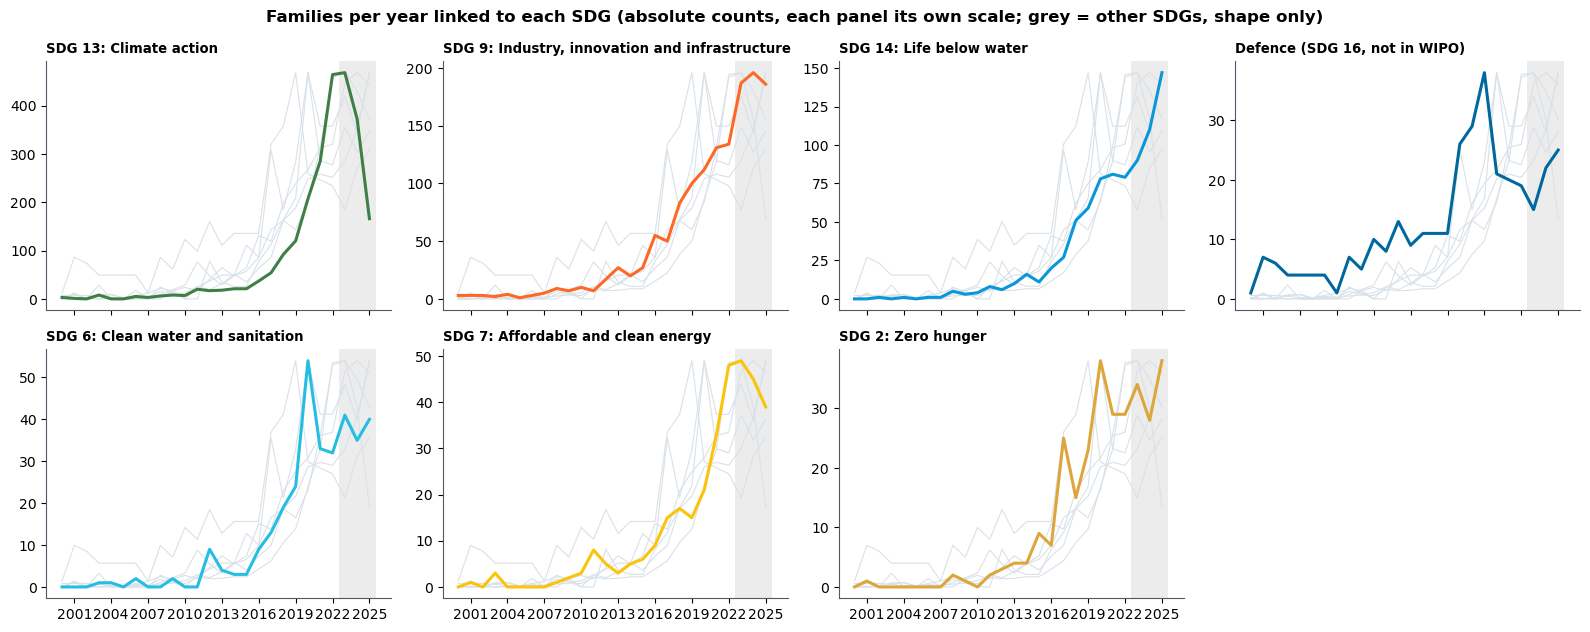

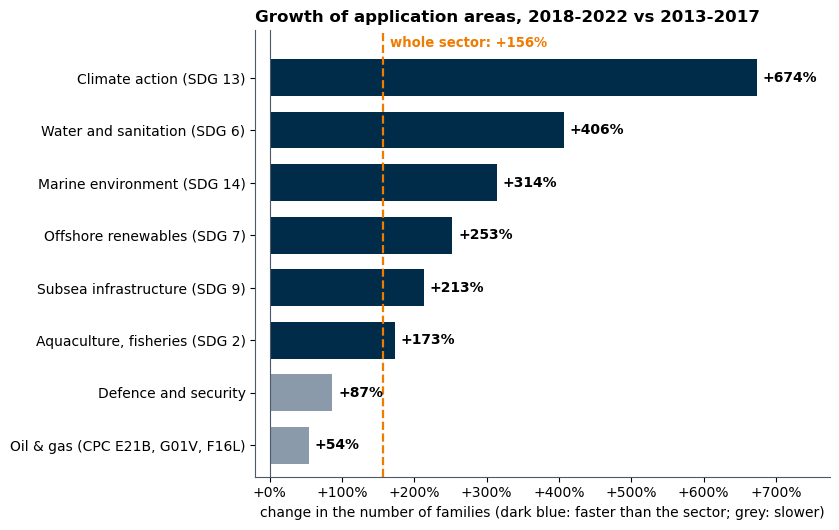

Oil & gas (CPC E21B, G01V, F16L)    0.54
Defence and security                0.87
Aquaculture, fisheries (SDG 2)      1.73
Subsea infrastructure (SDG 9)       2.13
Offshore renewables (SDG 7)         2.53
Marine environment (SDG 14)         3.14
Water and sanitation (SDG 6)        4.06
Climate action (SDG 13)             6.74
family_year  2005  2008  2011  2014  2017  2020  2022
Oil & gas     5.9  14.6   8.3   6.3   4.3   3.9   3.9
Defence       7.8   7.3   4.4   3.1   3.4   1.7   1.3
families linked to at least one SDG: 26.9% | defence: 2.7% | defence AND an SDG (dual use): 65 families


,name,families,share of sector,growth 2013-2017 → 2018-2022,international,university-owned,first filed in China,top owners,growth vs sector (pp)
SDG,,,,,,,,,
2,"Zero hunger (aquaculture, fisheries)",192,1.9%,+173%,16%,43%,73%,Harbin Engineering Unive (6); Shanghai Ocean Universit (5); Chinese Academy Of Scien (4),+17
6,Clean water and sanitation,209,2.1%,+406%,7%,39%,82%,Guangdong University Of (10); China Construction Third (5); Shanghai Ocean Universit (5),+250
7,Affordable and clean energy (offshore renewables),195,2.0%,+253%,14%,43%,69%,Shanghai Jiao Tong Unive (9); Korea Institute Of Robot (6); China Huaneng Group (6),+96
9,"Industry, innovation and infrastructure (subsea infrastructure)",813,8.2%,+213%,13%,38%,76%,Harbin Engineering Unive (39); China State Shipbuilding (37); Chinese Academy Of Scien (29),+57
13,Climate action (Y02 climate-change tags),"1,397",14.1%,+674%,10%,56%,82%,Harbin Engineering Unive (86); Northwestern Polytechnic (83); Chinese Academy Of Scien (71),+517
14,Life below water (marine environment and ocean science),462,4.7%,+314%,10%,51%,81%,Harbin Engineering Unive (38); Chinese Academy Of Scien (18); Zhejiang University (12),+158
16*,"Defence / security (SDG 16, not mapped by WIPO)",269,2.7%,+87%,27%,25%,38%,Us Navy (12); Tkms (Atlas Elektronik) (12); Hanwha (11),-70


In [36]:
SDG_RULES = {   # sdg: (name, CPC prefixes, keyword regex on lower-case title + abstract) – design choices, see the appendix
    2: ("Zero hunger (aquaculture, fisheries)", ("A01K61", "A01K63", "A01K69", "A01K71", "A01K73", "A01K74", "A01K75", "A01K79", "A01K80"),
        r"aquacultur|mariculture|fish[\s-]+farm|net[\s-]+cage|fishing[\s-]+net|marine[\s-]+ranch|fishery|fisheries"),
    6: ("Clean water and sanitation", ("C02F", "E03B", "E03F"),
        r"water[\s-]+quality|drinking[\s-]+water|sewage|waste[\s-]?water|water[\s-]+supply|water[\s-]+treatment|\bsewer"),
    7: ("Affordable and clean energy (offshore renewables)", ("Y02E10", "F03D", "F03B"),
        r"offshore[\s-]+wind|wind[\s-]+(?:turbine|farm|power)|tidal|wave[\s-]+energy|marine[\s-]+energy|hydropower|hydro[\s-]+turbine"),
    9: ("Industry, innovation and infrastructure (subsea infrastructure)", ("E02B", "E02D", "F16L1"),
        r"pipeline|submarine[\s-]+cable|subsea[\s-]+cable|power[\s-]+cable|bridge|\bpier|\bdam\b|tunnel|harbou?r|offshore[\s-]+platform|mooring|jacket[\s-]+structure"),
    13: ("Climate action (Y02 climate-change tags)", ("Y02",), r"climate[\s-]+change|carbon[\s-]+(?:capture|storage|sequestration)|greenhouse"),
    14: ("Life below water (marine environment and ocean science)", ("G01N33/18",),
         r"marine[\s-]+(?:environment|ecolog|organism|pollution|debris|litter|biolog|life)|ocean[\s-]+(?:observ|monitor)|oceanograph"
         r"|seabed[\s-]+(?:survey|mapping|exploration)|biodiversity|\bcoral|oil[\s-]+spill|garbage|plastic[\s-]+waste|plankton|water[\s-]+sampl"
         r"|ecolog\w*[\s-]+monitor|hydrolog"),
}
DEFENCE = (("F41", "F42"), r"military|weapon|torpedo|\bmines?\b|mine[\s-]+(?:hunting|countermeasure|clearance|sweeping)|naval[\s-]+(?:warfare|combat)"
           r"|anti[\s-]?submarine|warfare|warship|\bdefen[cs]e[\s-]+(?:system|application)|target[\s-]+strike|\bsonar[\s-]+countermeasure")

sdg_txt = (fam["title_en"].fillna(fam["title"]).fillna("") + " " + fam["abstract_en"].fillna("")).str.lower()
cpc_clean = fcpc.assign(c=fcpc["cpc"].astype(str).str.replace(" ", ""))
def by_cpc(prefixes):
    return set(cpc_clean.loc[cpc_clean["c"].str.startswith(prefixes), "docdb_family_id"])
def by_kw(rx):
    return set(fam.loc[sdg_txt.str.contains(rx, regex=True), "docdb_family_id"])

sdg_sets = {k: by_cpc(c) | by_kw(rx) for k, (_, c, rx) in SDG_RULES.items()}
defence_set = by_cpc(DEFENCE[0]) | by_kw(DEFENCE[1])
for k, s in sdg_sets.items():
    fam[f"sdg{k}"] = fam["docdb_family_id"].isin(s)
fam["sdg_any"] = fam[[f"sdg{k}" for k in SDG_RULES]].any(axis=1)
fam["defence"] = fam["docdb_family_id"].isin(defence_set)
fam_c = fam[fam.family_year <= LAST]

own_type = appl.groupby("docdb_family_id")["type"].agg(lambda s: s.value_counts().index[0])
rows = []
for k, (name, _, _) in list(SDG_RULES.items()) + [("16*", ("Defence / security (SDG 16, not mapped by WIPO)", None, None))]:
    col = f"sdg{k}" if k != "16*" else "defence"
    d = fam_c[fam_c[col]]
    past_n, rec_n_ = d.family_year.between(*PAST).sum(), d.family_year.between(*RECENT).sum()
    owners_ = appl[appl.docdb_family_id.isin(d.docdb_family_id)].groupby("applicant")["weight"].sum().sort_values(ascending=False)
    rows.append({"SDG": k, "name": name, "families": len(d), "share of sector": len(d) / len(fam_c),
                 f"growth {PAST[0]}-{PAST[1]} → {RECENT[0]}-{RECENT[1]}": rec_n_ / past_n - 1 if past_n else np.nan,
                 "international": d["is_international"].mean(), "university-owned": own_type.reindex(d.docdb_family_id).eq("university").mean(),
                 "first filed in China": d["first_office"].eq("CN").mean(),
                 "top owners": "; ".join(f"{str(a).title()[:24]} ({v:.0f})" for a, v in owners_.head(3).items())})
sdg_tab = pd.DataFrame(rows).set_index("SDG")
sector_g = fam_c.family_year.between(*RECENT).sum() / fam_c.family_year.between(*PAST).sum() - 1
sdg_tab["growth vs sector (pp)"] = (sdg_tab[sdg_tab.columns[3]] - sector_g) * 100
overlap_def = (fam_c["defence"] & fam_c["sdg_any"]).sum()
KEY.update({"sdg_any_share": float(fam_c["sdg_any"].mean()), "sdg14_share": float(fam_c["sdg14"].mean()),
            "defence_share": float(fam_c["defence"].mean()), "defence_and_sdg_overlap": int(overlap_def)})
save_table(sdg_tab, "sdg_mapping")

_SDGC = {2: "#DDA63A", 6: "#26BDE2", 7: "#FCC30B", 9: "#FD6925", 13: "#3F7E44", 14: "#0A97D9"}
yr_sdg = fam[fam.family_year.between(2000, YEAR_MAX)].groupby("family_year")[[f"sdg{k}" for k in SDG_RULES] + ["defence"]].sum()
order_ = yr_sdg.loc[:LAST].sum().sort_values(ascending=False).index
fig, axes = plt.subplots(2, 4, figsize=(16, 6.4), sharex=True)
for ax, col in zip(axes.flat, order_):
    scale = yr_sdg[col].max()
    for other in yr_sdg.columns:            # the other SDGs, rescaled to this panel (shape only), as in WIPO's small multiples
        ax.plot(yr_sdg.index, yr_sdg[other] / max(yr_sdg[other].max(), 1) * scale, color=LIGHT, lw=0.8)
    ax.plot(yr_sdg.index, yr_sdg[col], color=_SDGC.get(int(col[3:]), NAVY) if col != "defence" else "#00689D", lw=2.2)
    k = col.replace("sdg", "")
    ax.set_title(f"SDG {k}: {SDG_RULES[int(k)][0].split(' (')[0]}" if col != "defence" else "Defence (SDG 16, not in WIPO)",
                 fontsize=9.5)
    shade(ax)
axes.flat[-1].axis("off")
fig.suptitle("Families per year linked to each SDG (absolute counts, each panel its own scale; grey = other SDGs, shape only)", fontweight="bold")
plt.tight_layout(); save(fig, "s1_sdg_shares"); plt.show()

# Application areas that grow or shrink, against the sector. Growth of the families of each area between the two windows
# of the notebook (PAST -> RECENT), compared with the sector's own growth: an area that grows slower than the sector LOSES
# share even if its absolute number rises (defence: more families, but a smaller part of the sector). Oil & gas is
# defined by CPC (E21B drilling, G01V seismic survey, F16L pipelines; Step 1.1.1); the other areas are the SDG rules above.
gcol = sdg_tab.columns[3]
og_c = fam_c[fam_c.docdb_family_id.isin(og_fam)]
areas = {"Oil & gas (CPC E21B, G01V, F16L)": (len(og_c[og_c.family_year.between(*RECENT)]) / max(len(og_c[og_c.family_year.between(*PAST)]), 1) - 1)}
short_area = {"2": "Aquaculture, fisheries (SDG 2)", "6": "Water and sanitation (SDG 6)", "7": "Offshore renewables (SDG 7)",
              "9": "Subsea infrastructure (SDG 9)", "13": "Climate action (SDG 13)", "14": "Marine environment (SDG 14)",
              "16*": "Defence and security"}
for k_, r_ in sdg_tab.iterrows():
    areas[short_area.get(str(k_), r_["name"])] = r_[gcol]
ap = pd.Series(areas).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 5.4))
cols_ = [RED if v < sector_g else (ORANGE if v < sector_g * 1.0001 else NAVY) for v in ap.values]
cols_ = [("#C0392B" if v < 0 else (MID if v < sector_g else NAVY)) for v in ap.values]
ax.barh(ap.index, ap.values * 100, color=cols_, height=0.7)
for y_, v_ in enumerate(ap.values):
    ax.text(v_ * 100 + (8 if v_ >= 0 else -8), y_, f"{v_:+.0%}", va="center", ha="left" if v_ >= 0 else "right", fontsize=10, fontweight="bold")
ax.axvline(sector_g * 100, color=ORANGE, ls="--", lw=1.6)
ax.text(sector_g * 100 + 10, len(ap) - 0.35, f"whole sector: {sector_g:+.0%}", color=ORANGE, fontsize=9.5, fontweight="bold", va="center")
ax.axvline(0, color=GREY, lw=0.8)
ax.set_xlim(min(ap.min() * 100 - 60, -20), ap.max() * 100 * 1.15); ax.set_ylim(-0.6, len(ap) - 0.1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0f}%"))
ax.set(title=f"Growth of application areas, {RECENT[0]}-{RECENT[1]} vs {PAST[0]}-{PAST[1]}",
       xlabel="change in the number of families (dark blue: faster than the sector; grey: slower)")
plt.tight_layout(); save(fig, "s1_application_shift"); plt.show()
share_app = pd.DataFrame({"Oil & gas": fam_c.assign(x=fam_c.docdb_family_id.isin(og_fam)).groupby("family_year")["x"].mean() * 100,
                          "Defence": fam_c.groupby("family_year")["defence"].mean() * 100}).loc[2005:]
for _p, _lo, _hi in [("2011_2013", 2011, 2013), ("2020_2022", 2020, 2022)]:
    KEY[f"defence_share_{_p}"] = float(share_app.loc[_lo:_hi, "Defence"].mean())
KEY["oil_gas_growth_windows"] = float(areas["Oil & gas (CPC E21B, G01V, F16L)"]); KEY["sector_growth_windows"] = float(sector_g)
print(ap.round(2).to_string()); print(share_app.loc[[2005, 2008, 2011, 2014, 2017, 2020, 2022]].round(1).T)
print(f"families linked to at least one SDG: {fam_c['sdg_any'].mean():.1%} | defence: {fam_c['defence'].mean():.1%} | "
      f"defence AND an SDG (dual use): {overlap_def:,} families")
sdg_tab.style.format({"families": "{:,.0f}", "share of sector": "{:.1%}", sdg_tab.columns[3]: "{:+.0%}", "international": "{:.0%}",
                      "university-owned": "{:.0%}", "first filed in China": "{:.0%}", "growth vs sector (pp)": "{:+.0f}"}, na_rep="–")

**Deck figure: every application area, then and now.** One chart instead of three (bubbles, maturity matrix, growth bars):
for each area the families of the first window (grey) next to the second window (colour), with the growth as label. The area
that is both large and growing fastest (climate action) is the one that, in the WIPO maturity matrix, is the only "current hot topic".

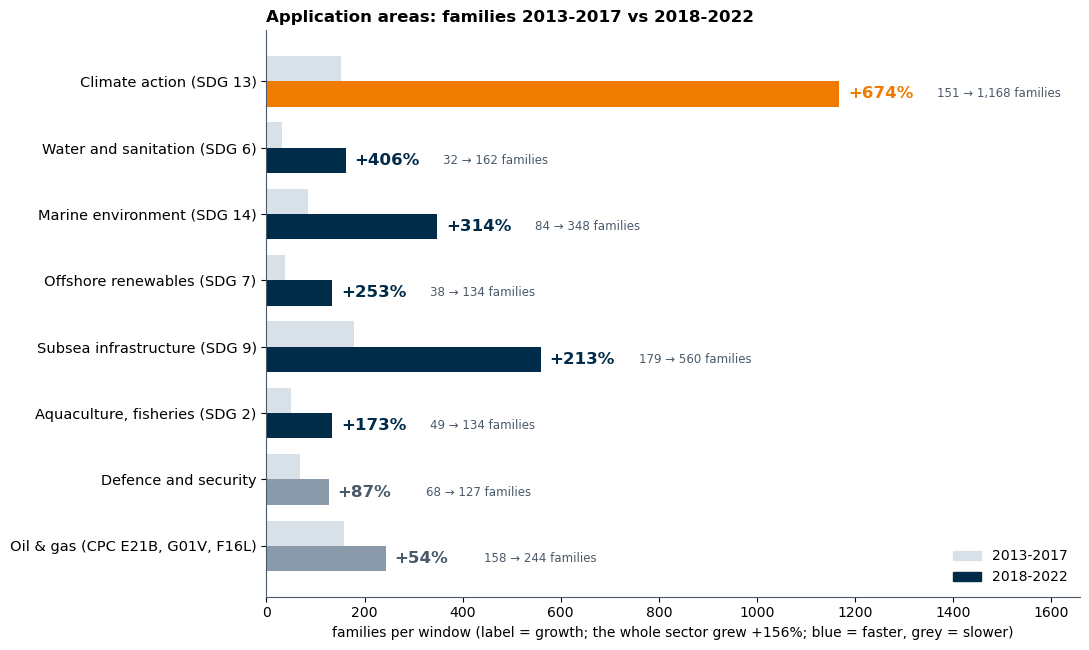

,past,recent,g
label,,,
Climate action (SDG 13),151.0,1168.0,6.74
Water and sanitation (SDG 6),32.0,162.0,4.06
Marine environment (SDG 14),84.0,348.0,3.14
Offshore renewables (SDG 7),38.0,134.0,2.53
Subsea infrastructure (SDG 9),179.0,560.0,2.13
"Aquaculture, fisheries (SDG 2)",49.0,134.0,1.73
Defence and security,68.0,127.0,0.87
"Oil & gas (CPC E21B, G01V, F16L)",158.0,244.0,0.54


In [37]:
def then_now_chart(rows, title, fname, sector_growth_ratio, figsize=(11, 6.6), highlight_top=True):
    """rows = [(label, families in the first window, families in the second window)]; bars sorted by growth; label = growth.
    Dark blue = grows faster than the whole sector, grey-blue = slower, orange = the fastest of the chart."""
    d = pd.DataFrame(rows, columns=["label", "past", "recent"]).set_index("label")
    d["g"] = d.recent / d.past.replace(0, np.nan) - 1
    d = d.sort_values("g", ascending=False, na_position="first")
    n = len(d); y = np.arange(n)[::-1]; h = 0.38
    top = d["g"].idxmax() if d["g"].notna().any() else None
    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(y + h / 2, d.past, height=h, color=LIGHT, zorder=2, label=f"{PAST[0]}-{PAST[1]}")
    rc = [ORANGE if (highlight_top and i == top) else (NAVY if (g_ >= sector_growth_ratio) else MID) for i, g_ in zip(d.index, d["g"])]
    ax.barh(y - h / 2, d.recent, height=h, color=rc, zorder=2)
    xmax = max(d.recent.max(), d.past.max())
    for y_, (i, r) in zip(y, d.iterrows()):
        txt = "new" if pd.isna(r["g"]) else f"{r['g']:+.0%}"
        ax.text(r.recent + xmax * 0.015, y_ - h / 2, txt, va="center", fontsize=12, fontweight="bold",
                color=ORANGE if (highlight_top and i == top) else (NAVY if (pd.isna(r["g"]) or r["g"] >= sector_growth_ratio) else GREY))
        ax.text(r.recent + xmax * 0.17, y_ - h / 2, f"{r.past:,.0f} → {r.recent:,.0f} families", va="center", fontsize=8.5, color=GREY)
    ax.set_yticks(y, list(d.index), fontsize=10.5); ax.set_xlim(0, xmax * 1.42)
    ax.set_xlabel(f"families per window (label = growth; the whole sector grew {sector_growth_ratio:+.0%}; blue = faster, grey = slower)")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=LIGHT), plt.Rectangle((0, 0), 1, 1, color=NAVY)],
              labels=[f"{PAST[0]}-{PAST[1]}", f"{RECENT[0]}-{RECENT[1]}"], frameon=False, loc="lower right", fontsize=10)
    ax.set_title(title, loc="left", fontweight="bold")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    plt.tight_layout(); save(fig, fname); plt.show()
    return d

_wn = lambda col, w: float(fam_c.loc[fam_c.family_year.between(*w), col].sum())
area_rows = [(short_area[str(k_)], _wn(f"sdg{k_}", PAST), _wn(f"sdg{k_}", RECENT)) for k_ in SDG_RULES]
area_rows.append((short_area["16*"], _wn("defence", PAST), _wn("defence", RECENT)))
area_rows.append(("Oil & gas (CPC E21B, G01V, F16L)", float(og_c.family_year.between(*PAST).sum()), float(og_c.family_year.between(*RECENT).sum())))
ar = then_now_chart(area_rows, f"Application areas: families {PAST[0]}-{PAST[1]} vs {RECENT[0]}-{RECENT[1]}", "s1_sdg_then_now", sector_g)
KEY["sdg_fastest_area"] = str(ar["g"].idxmax()) if ar["g"].notna().any() else None
save_table(ar.rename(columns={"g": "growth"}), "application_areas_then_now")
ar.round(2)

**The SDG charts of the WIPO report, on our sector.** The same four views as IM_Theory_3 (WIPO 2024, figures 1–5),
rebuilt on the underwater-drone families: (1) the SDG "fan" (families per goal, multi-label; grey = goals our rules do
not map, SDG 16 shows the defence families, outside the WIPO mapping); (2) the **Innovation Maturity Matrix** of the
SDGs (intensity = families up to 2022, log scale; relative recency normalised so that all SDG-linked families of the
sector have recency 1, as in WIPO); (3) **one SDG, many technologies**: each goal as a circle whose inner circles are its
main CPC subclasses (fractional families, Y tags excluded); overlaps are counted in every goal they serve.

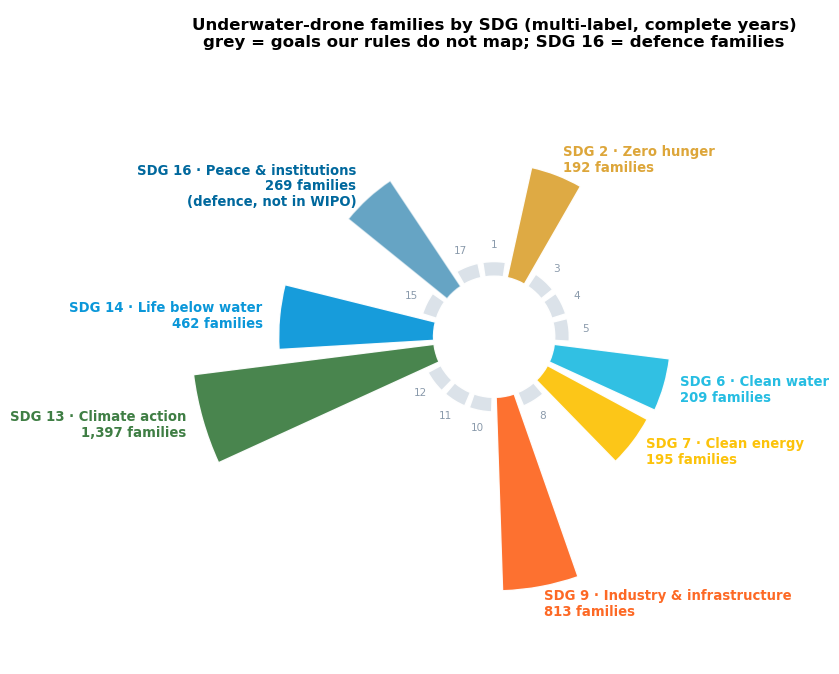

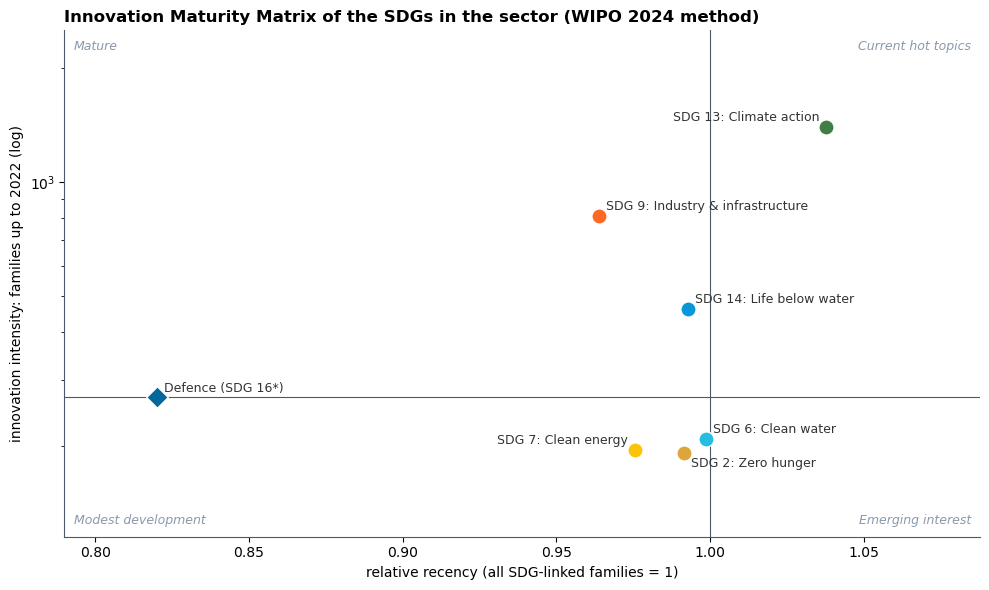

,intensity,relative recency,quadrant,sector recency (all families = 1)
SDG 2,192,0.992,modest development,1.051
SDG 6,209,0.999,modest development,1.059
SDG 7,195,0.976,modest development,1.034
SDG 9,813,0.964,mature,1.022
SDG 13,"1,397",1.038,current hot topic,1.100
SDG 14,462,0.993,mature,1.053
Defence (SDG 16*),269,0.820,mature,0.869


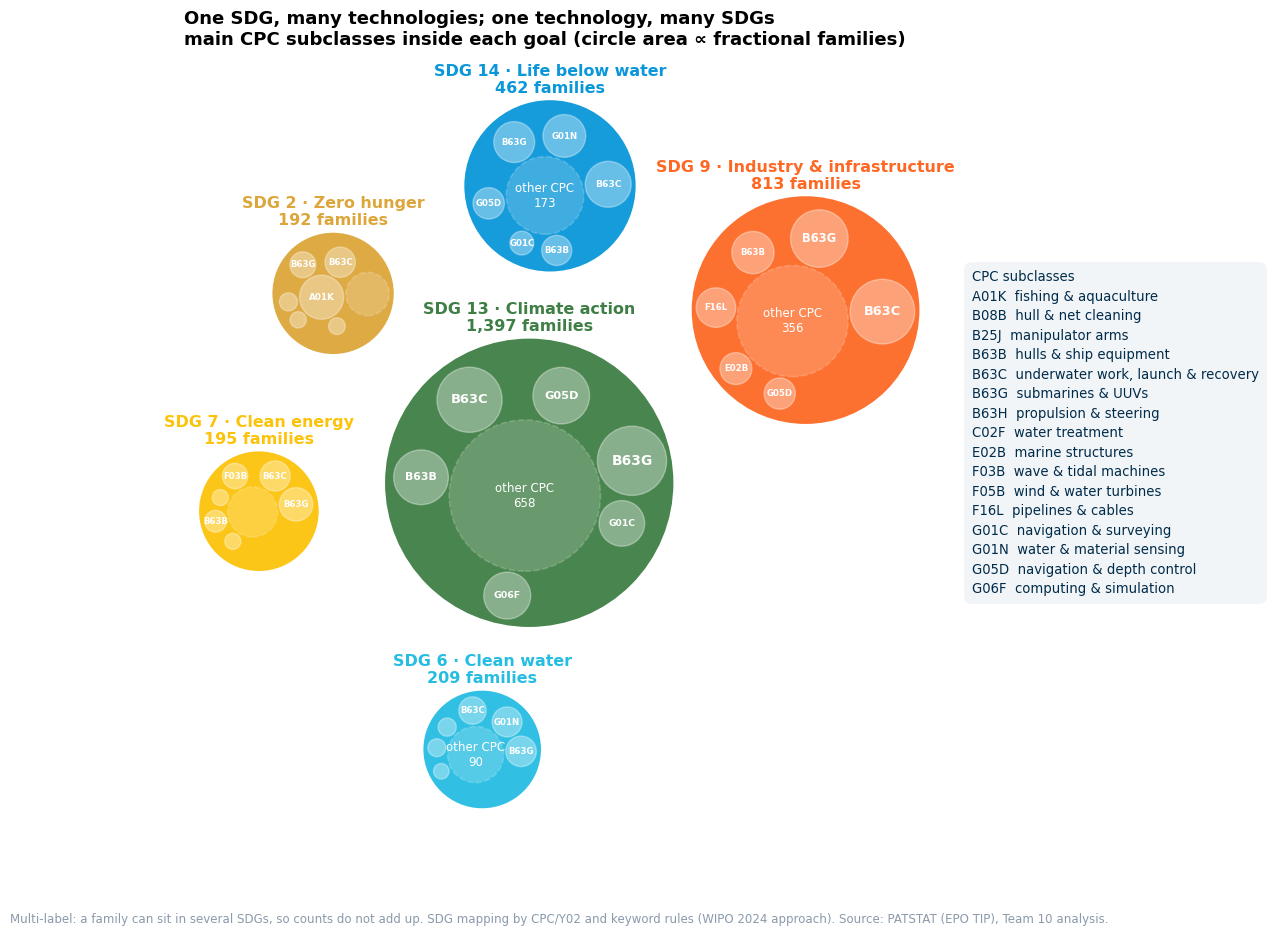

SDG 2,SDG 6,SDG 7,SDG 9,SDG 13,SDG 14
A01K (): 56,B63G (submarines and unmanned un): 27,B63G (submarines and unmanned un): 32,"B63C (underwater work, launch an): 120",B63G (submarines and unmanned un): 138,"B63C (underwater work, launch an): 61"
"B63C (underwater work, launch an): 26",G01N (water and material sensing): 26,"B63C (underwater work, launch an): 26",B63G (submarines and unmanned un): 95,"B63C (underwater work, launch an): 122",G01N (water and material sensing): 53
B63G (submarines and unmanned un): 19,"B63C (underwater work, launch an): 22",F03B (): 18,B63B (hulls and ship equipment): 51,"G05D (navigation, path and depth): 92",B63G (submarines and unmanned un): 48
B08B (hull and net cleaning): 9,C02F (): 10,B63B (hulls and ship equipment): 14,F16L (pipelines and cables): 45,B63B (hulls and ship equipment): 86,"G05D (navigation, path and depth): 28"
B25J (manipulator arms): 8,"G05D (navigation, path and depth): 9",B63H (propulsion and steering): 7,E02B (): 29,"G06F (computing, simulation): 63",B63B (hulls and ship equipment): 26
B63B (hulls and ship equipment): 8,B25J (manipulator arms): 7,F05B (): 7,"G05D (navigation, path and depth): 28",G01C (navigation and surveying): 60,G01C (navigation and surveying): 16
other: 54,other: 90,other: 72,other: 356,other: 658,other: 173


In [38]:
SDG_COLORS = {1: "#E5243B", 2: "#DDA63A", 3: "#4C9F38", 4: "#C5192D", 5: "#FF3A21", 6: "#26BDE2", 7: "#FCC30B", 8: "#A21942",
              9: "#FD6925", 10: "#DD1367", 11: "#FD9D24", 12: "#BF8B2E", 13: "#3F7E44", 14: "#0A97D9", 15: "#56C02B", 16: "#00689D", 17: "#19486A"}
SDG_NAMES = {1: "No poverty", 2: "Zero hunger", 3: "Good health", 4: "Quality education", 5: "Gender equality", 6: "Clean water",
             7: "Clean energy", 8: "Decent work", 9: "Industry & infrastructure", 10: "Reduced inequalities", 11: "Sustainable cities",
             12: "Responsible consumption", 13: "Climate action", 14: "Life below water", 15: "Life on land", 16: "Peace & institutions", 17: "Partnerships"}
counts17 = {g: int(fam_c[f"sdg{g}"].sum()) if g in SDG_RULES else (int(fam_c["defence"].sum()) if g == 16 else 0) for g in range(1, 18)}

# (1) the fan
fig = plt.figure(figsize=(10, 8.5)); ax = fig.add_subplot(111, polar=True)
theta = np.pi / 2 - np.linspace(0, 2 * np.pi, 17, endpoint=False)       # SDG 1 at the top, clockwise as in WIPO
vmax = max(counts17.values())
for g, t in zip(range(1, 18), theta):
    v = counts17[g]; mapped_ = g in SDG_RULES or g == 16
    h = 0.15 + 0.85 * np.sqrt(v / vmax) if v else 0.06
    ax.bar(t, h, width=2 * np.pi / 17 * 0.82, bottom=0.25,
           color=SDG_COLORS[g] if mapped_ else LIGHT, edgecolor="white", alpha=0.6 if g == 16 else 0.95)
    r_lab = 0.25 + h + 0.07
    cos_ = np.cos(t)
    ha_ = "left" if cos_ > 0.15 else ("right" if cos_ < -0.15 else "center")
    if mapped_:                                # horizontal labels at the tip of the bar: goal, name, families
        lab = f"SDG {g} · {SDG_NAMES[g]}\n{v:,} families" + ("\n(defence, not in WIPO)" if g == 16 else "")
        ax.text(t, r_lab, lab, ha=ha_, va="center", fontsize=9.5, fontweight="bold", color=SDG_COLORS[g], linespacing=1.15)
    else:
        ax.text(t, r_lab, f"{g}", ha="center", va="center", fontsize=7.5, color=MID)
ax.set_ylim(0, 1.35); ax.axis("off")
ax.set_title("Underwater-drone families by SDG (multi-label, complete years)\n"
             "grey = goals our rules do not map; SDG 16 = defence families", y=0.93, loc="center")
save(fig, "s1_sdg_fan"); plt.show()

# (2) Innovation Maturity Matrix of the SDGs
def rel_rec(yearly, start=YEAR_MIN, end=LAST):
    w_ = yearly.reindex(range(start, end + 1), fill_value=0).values.astype(float)
    i_ = np.arange(1, len(w_) + 1)
    return (w_ * i_).sum() / (len(w_) * w_.sum()) if w_.sum() else np.nan

R_all_sdg = rel_rec(fam_c[fam_c["sdg_any"]].groupby("family_year").size())
mm = pd.DataFrame({f"SDG {g}" if g != "def" else "Defence (SDG 16*)": {
    "intensity": int(fam_c[c].sum()), "relative recency": rel_rec(fam_c[fam_c[c]].groupby("family_year").size()) / R_all_sdg, "g": g}
    for g, c in [(k, f"sdg{k}") for k in SDG_RULES] + [("def", "defence")]}).T
mm["relative recency"] = mm["relative recency"].astype(float); mm["intensity"] = mm["intensity"].astype(float)
med_i = mm["intensity"].median()
mm["quadrant"] = np.where(mm["relative recency"] >= 1, np.where(mm["intensity"] >= med_i, "current hot topic", "emerging interest"),
                          np.where(mm["intensity"] >= med_i, "mature", "modest development"))
mm["sector recency (all families = 1)"] = [rel_rec(fam_c[fam_c[c]].groupby("family_year").size()) / rel_rec(fam_c.groupby("family_year").size())
                                           for c in [f"sdg{k}" for k in SDG_RULES] + ["defence"]]
save_table(mm.drop(columns="g"), "sdg_maturity_matrix")
fig, ax = plt.subplots(figsize=(10, 6))
mm_cols = [SDG_COLORS[g] if g != "def" else SDG_COLORS[16] for g in mm["g"]]
for (name, r), col in zip(mm.iterrows(), mm_cols):
    ax.scatter(r["relative recency"], r["intensity"], s=120, color=col, edgecolor="white", zorder=3, marker="o" if r["g"] != "def" else "D")
ax.axvline(1, color=GREY, lw=0.8); ax.axhline(med_i, color=GREY, lw=0.8); ax.set_yscale("log")
x0, x1 = mm["relative recency"].min() - 0.03, mm["relative recency"].max() + 0.05
ax.set_xlim(x0, x1)
ax.set_ylim(mm.intensity.min() * 0.6, mm.intensity.max() * 1.8)
for txt_, (x_, y_, ha_, va_) in {"Mature": (0.01, 0.98, "left", "top"), "Current hot topics": (0.99, 0.98, "right", "top"),
                                 "Modest development": (0.01, 0.02, "left", "bottom"), "Emerging interest": (0.99, 0.02, "right", "bottom")}.items():
    ax.text(x_, y_, txt_, fontsize=9, color=MID, ha=ha_, va=va_, transform=ax.transAxes, style="italic")
ax.set(title="Innovation Maturity Matrix of the SDGs in the sector (WIPO 2024 method)", xlabel="relative recency (all SDG-linked families = 1)",
       ylabel="innovation intensity: families up to 2022 (log)")
plt.tight_layout()
mm_sorted = mm.sort_values("intensity", ascending=False)
label_points(ax, mm_sorted["relative recency"], mm_sorted["intensity"],
             [n + (f": {SDG_NAMES[g]}" if g != "def" else "") for n, g in zip(mm_sorted.index, mm_sorted["g"])], fontsize=9)
save(fig, "s1_sdg_maturity_matrix"); plt.show()
display(mm.drop(columns="g").style.format({"intensity": "{:,.0f}", "relative recency": "{:.3f}", "sector recency (all families = 1)": "{:.3f}"}))

# (3) one SDG, many technologies: packed circles (one bubble per goal, inner circles = its main CPC subclasses)
CPC_SHORT = {"B63C": "underwater work, launch & recovery", "B63G": "submarines & UUVs", "B63B": "hulls & ship equipment",
             "B63H": "propulsion & steering", "G05D": "navigation & depth control", "G06F": "computing & simulation",
             "G01C": "navigation & surveying", "G01N": "water & material sensing", "F16L": "pipelines & cables", "E02B": "marine structures",
             "A01K": "fishing & aquaculture", "B08B": "hull & net cleaning", "B25J": "manipulator arms", "C02F": "water treatment",
             "F03B": "wave & tidal machines", "F05B": "wind & water turbines"}

def pack(radii, gap=0.0):
    """Greedy circle packing: each circle goes to the free tangent position closest to the origin;
    the cluster is then re-centred on its smallest enclosing circle (grid search). Returns positions and enclosing radius."""
    pos = []
    for i, r in enumerate(radii):
        if i == 0:
            pos.append((0.0, 0.0)); continue
        best = None
        for j, (xj, yj) in enumerate(pos):
            for ang in np.linspace(0, 2 * np.pi, 180, endpoint=False):
                x_, y_ = xj + (radii[j] + r + gap) * np.cos(ang), yj + (radii[j] + r + gap) * np.sin(ang)
                if all(np.hypot(x_ - xk, y_ - yk) >= radii[k] + r + gap - 1e-9 for k, (xk, yk) in enumerate(pos)):
                    d = np.hypot(x_, y_)
                    if best is None or d < best[0]:
                        best = (d, x_, y_)
        pos.append(best[1:])
    pos = np.array(pos); best = None
    for cx in np.linspace(pos[:, 0].min(), pos[:, 0].max(), 40):
        for cy in np.linspace(pos[:, 1].min(), pos[:, 1].max(), 40):
            R_ = max(np.hypot(x_ - cx, y_ - cy) + r for (x_, y_), r in zip(pos, radii))
            if best is None or R_ < best[0]:
                best = (R_, cx, cy)
    R_, cx, cy = best
    return pos - np.array([cx, cy]), R_

sub_sdg = sub_tc.merge(fam_c[["docdb_family_id"] + [f"sdg{k}" for k in SDG_RULES]], on="docdb_family_id")
groups = {}
for k in SDG_RULES:
    s = sub_sdg[sub_sdg[f"sdg{k}"]].groupby("subclass")["weight_tech"].sum().sort_values(ascending=False)
    top = s.head(6); other = s.iloc[6:].sum()
    groups[k] = list(top.items()) + ([("other", other)] if other > 0 else [])
bub = []
for k, ch in groups.items():
    ch = sorted(ch, key=lambda t: -t[1]); radii = [np.sqrt(v) for _, v in ch]
    pos_, R_ = pack(radii, gap=0.8)
    bub.append(dict(k=k, items=ch, radii=radii, pos=pos_, R=R_ + 1.5, tot=int(fam_c[f"sdg{k}"].sum())))
bub.sort(key=lambda g: -g["R"])
gpos, _ = pack([g["R"] + 7 for g in bub], gap=9)          # room for the title above each goal
fig, ax = plt.subplots(figsize=(13, 10)); ax.set_aspect("equal"); ax.axis("off")
for g, (gx, gy) in zip(bub, gpos):
    c_ = SDG_COLORS[g["k"]]
    ax.add_patch(plt.Circle((gx, gy), g["R"], color=c_, alpha=0.95, lw=0))
    ax.text(gx, gy + g["R"] + 1.5, f"SDG {g['k']} · {SDG_NAMES[g['k']]}\n{g['tot']:,} families", ha="center", va="bottom",
            fontsize=11.5, fontweight="bold", color=c_)
    for (code, v), r, (x_, y_) in zip(g["items"], g["radii"], g["pos"]):
        X, Y = gx + x_, gy + y_
        if code == "other":
            ax.add_patch(plt.Circle((X, Y), r, facecolor="white", alpha=0.18, edgecolor="white", lw=1.2, ls="--"))
            if r > 9:
                ax.text(X, Y, f"other CPC\n{v:.0f}", ha="center", va="center", fontsize=8.5, color="white")
            continue
        ax.add_patch(plt.Circle((X, Y), r, facecolor="white", alpha=0.35, edgecolor="white", lw=1))
        if r >= 3.6:                                        # codes only where they fit; names in the legend
            ax.text(X, Y, code, ha="center", va="center", fontsize=max(6.2, min(11, r * 0.85)), color="white", fontweight="bold")
ax.set_xlim(min(gx - g["R"] for g, (gx, gy) in zip(bub, gpos)) - 5, max(gx + g["R"] for g, (gx, gy) in zip(bub, gpos)) + 5)
ax.set_ylim(min(gy - g["R"] for g, (gx, gy) in zip(bub, gpos)) - 5, max(gy + g["R"] for g, (gx, gy) in zip(bub, gpos)) + 16)
fig.subplots_adjust(right=0.74)
ax.set_title("One SDG, many technologies; one technology, many SDGs\nmain CPC subclasses inside each goal (circle area ∝ fractional families)",
             fontsize=13, fontweight="bold", loc="left")
used_ = sorted({c for g in bub for c, _ in g["items"] if c != "other"})
fig.text(0.75, 0.5, "CPC subclasses\n" + "\n".join(f"{c}  {CPC_SHORT.get(c, CPC_ROLE.get(c, ''))[:34]}" for c in used_),
         fontsize=9.5, va="center", color=NAVY, linespacing=1.5, bbox=dict(boxstyle="round,pad=0.6", fc="#F2F5F8", ec="none"))
fig.text(0.01, 0.01, "Multi-label: a family can sit in several SDGs, so counts do not add up. SDG mapping by CPC/Y02 and keyword rules "
         "(WIPO 2024 approach). Source: PATSTAT (EPO TIP), Team 10 analysis.", fontsize=8.5, color=MID)
save(fig, "s1_sdg_technologies"); plt.show()
sdg_tech = pd.DataFrame({f"SDG {k}": [f"{lab_} ({CPC_ROLE.get(lab_, '')[:26]}): {v:.0f}" if lab_ != "other" else f"other: {v:.0f}" for lab_, v in ch]
                         + [""] * (7 - len(ch)) for k, ch in groups.items()})
save_table(sdg_tech, "sdg_technologies")
sdg_tech.style.hide(axis="index")

**Who serves which SDG?** The SDG profile of the market leaders and of the client (share of each player's families
linked to each goal), and a random sample to validate the rules: `sdg_label_sample.csv` (20 families per SDG + 20 with
no SDG) goes to two labellers; once `labels/sdg_labels.csv` exists (columns `docdb_family_id, sdg, is_correct`), the
cell prints the precision of each rule with its Wilson interval, as in Step 0.

In [39]:
sdg_cols = [f"sdg{k}" for k in SDG_RULES] + ["defence"]
pl_sdg = (links_sdg := appl[["docdb_family_id", "applicant"]].drop_duplicates().merge(fam[["docdb_family_id"] + sdg_cols + ["sdg_any"]], on="docdb_family_id"))
prof_sdg = pl_sdg[pl_sdg.applicant.isin(market_leaders)].groupby("applicant")[sdg_cols + ["sdg_any"]].mean().reindex(market_leaders)
prof_sdg.insert(0, "families", pl_sdg.groupby("applicant")["docdb_family_id"].nunique().reindex(market_leaders))
sector_row = fam_c[sdg_cols + ["sdg_any"]].mean(); sector_row["families"] = len(fam_c)
prof_sdg.loc["SECTOR (all families)"] = sector_row
prof_sdg.columns = ["families"] + [f"SDG {c[3:]}" if c.startswith("sdg") and c != "sdg_any" else ("any SDG" if c == "sdg_any" else "defence") for c in prof_sdg.columns[1:]]
save_table(prof_sdg, "sdg_profile_leaders")

rng = np.random.default_rng(C.SEED if hasattr(C, "SEED") else 42)
samp = []
for k in SDG_RULES:
    ids = fam.loc[fam[f"sdg{k}"], "docdb_family_id"].to_numpy()
    samp += [(i, k) for i in rng.choice(ids, size=min(20, len(ids)), replace=False)]
none_ids = fam.loc[~fam["sdg_any"], "docdb_family_id"].to_numpy()
samp += [(i, "none") for i in rng.choice(none_ids, size=min(20, len(none_ids)), replace=False)]
samp = pd.DataFrame(samp, columns=["docdb_family_id", "sdg"]).merge(fam[["docdb_family_id", "family_year", "title_en", "abstract_en"]], on="docdb_family_id")
samp["is_correct"] = ""
samp.to_csv(OUT / "sdg_label_sample.csv", index=False)
lab_path = C.LABEL_DIR / "sdg_labels.csv"
if lab_path.exists():
    lab = pd.read_csv(lab_path).dropna(subset=["is_correct"])
    prec = lab.groupby("sdg")["is_correct"].agg(["sum", "count"])
    prec["precision"] = prec["sum"] / prec["count"]
    prec[["ci_low", "ci_high"]] = [wilson(int(s), int(n)) for s, n in zip(prec["sum"], prec["count"])]
    display(prec.style.format({"precision": "{:.0%}", "ci_low": "{:.0%}", "ci_high": "{:.0%}"}))
else:
    print(f"validation: label {OUT / 'sdg_label_sample.csv'} and save it as {lab_path} to get the precision of each rule")
short(prof_sdg).style.format({c: "{:.0%}" for c in prof_sdg.columns if c != "families"} | {"families": "{:,.0f}"}, na_rep="–")

validation: label /home/jovyan/team-10-underwater-drones/outputs/prod/step2/sdg_label_sample.csv and save it as /home/jovyan/team-10-underwater-drones/labels/sdg_labels.csv to get the precision of each rule


,families,SDG 2,SDG 6,SDG 7,SDG 9,SDG 13,SDG 14,defence,any SDG
applicant,,,,,,,,,
KONGSBERG,10,0%,0%,0%,20%,10%,0%,0%,30%
TELEDYNE,9,0%,0%,11%,0%,11%,0%,0%,11%
SAAB,12,0%,0%,0%,8%,0%,0%,33%,8%
GENERAL DYNAMICS (BLUEFIN),4,0%,0%,0%,0%,25%,0%,0%,25%
L3HARRIS,7,0%,0%,0%,0%,14%,0%,14%,14%
HUNTINGTON INGALLS (HYDROID),2,0%,0%,0%,0%,0%,0%,0%,0%
EXAIL (ECA),14,0%,0%,7%,21%,7%,0%,0%,29%
OCEANEERING,45,4%,0%,11%,11%,9%,2%,0%,24%
TKMS (ATLAS ELEKTRONIK),96,1%,1%,0%,5%,6%,3%,17%,14%


**Reading (draft).** *About [x]% of the sector's families serve at least one SDG, mostly SDG 13 (climate tags),
SDG 9 (inspection of subsea infrastructure) and SDG 14 (ocean monitoring); [growing faster / slower] than the sector.
Defence covers [d]% of the families and overlaps with the SDGs in [n] of them: the same platforms serve security and
environmental monitoring. For the client this supports an ESG narrative (dual use, ocean monitoring through WSense)
and points to the SDG niches where its portfolio is absent.*

# STEP 2 · Competitive landscape

## 2.1 Concentration: how concentrated is the field, and is it consolidating?

**Unit.** The applicant is the harmonised group of `02_clean` (three traceable layers, `applicants_audit.csv`):
without harmonisation a large firm splits into many small ones and every concentration measure is wrong
(Tutorial 1 nb 11 §2). **Counts.** *Inventive* concentration: the share of families held by each applicant
(full counting: a co-owned family counts for each owner, as in Tutorial 1), not market shares.

The six measures of Liston-Heyes & Pilkington (2004), Tutorial 1 nb 11 §3: CR4, CR8, Herfindahl–Hirschman (HH),
its numbers-equivalent 1/HH, coefficient of variation, Gini, Lotka slope.

In [40]:
def concentration_ratio(x, k):
    x = np.sort(np.asarray(x))[::-1]; return x[:k].sum() / x.sum()

def herfindahl(x):
    s = np.asarray(x, dtype=float) / np.sum(x); return float(np.sum(s ** 2))

def lorenz_curve(x):
    x = np.sort(np.asarray(x, dtype=float))
    return np.arange(0, len(x) + 1) / len(x), np.concatenate([[0], np.cumsum(x) / x.sum()])

def gini(x):
    f, p = lorenz_curve(x)
    return (0.5 - np.sum(np.diff(f) * (p[1:] + p[:-1]) / 2)) / 0.5

def lotka(x):
    f = pd.Series(x).value_counts().sort_index()
    if len(f) < 3:
        return np.nan, np.nan
    fit = stats.linregress(np.log(f.index.astype(float)), np.log(f.values.astype(float)))
    return fit.slope, fit.pvalue

def six_measures(x):
    x = np.asarray(x, dtype=float)
    L, p = lotka(np.round(x).astype(int)) if np.allclose(x, np.round(x)) else (np.nan, np.nan)
    return {"applicants": len(x), "families (sum)": x.sum(), "CR4": concentration_ratio(x, 4), "CR8": concentration_ratio(x, 8),
            "HH": herfindahl(x), "1/HH": 1 / herfindahl(x), "CV": x.std(ddof=1) / x.mean(), "Gini": gini(x),
            "Lotka L": L, "Lotka p": p}

links = appl[["docdb_family_id", "applicant", "type", "country", "weight", "family_year"]].drop_duplicates(["docdb_family_id", "applicant"])
links_c = links[links.family_year <= LAST]

conc = {}
for name, ids in SAMPLES.items():
    d = links_c[links_c.docdb_family_id.isin(ids)]
    conc[name] = six_measures(d.groupby("applicant")["docdb_family_id"].nunique())
conc["all · firms only (strict)"] = six_measures(links_c[links_c.type == "firm"].groupby("applicant")["docdb_family_id"].nunique())
conc["all · firms (incl. unclassified)"] = six_measures(links_c[links_c.type.isin(["firm", "unknown"])].groupby("applicant")["docdb_family_id"].nunique())
conc["all · fractional counts"] = six_measures(links_c.groupby("applicant")["weight"].sum())
conc = pd.DataFrame(conc).T
KEY["HH_all"] = float(conc.loc["all", "HH"]); KEY["CR4_all"] = float(conc.loc["all", "CR4"])
KEY["one_over_HH_all"] = float(conc.loc["all", "1/HH"])
# the compact table of Tutorial 1 (LANDSCAPE.py: firms, patents, CR4, HH, 1/HH), for the appendix
fpa = links_c.groupby("applicant")["docdb_family_id"].nunique()
tab_field_conc = pd.Series({"firms (applicants)": len(fpa), "patents (sum over firms)": int(fpa.sum()), "CR4 (%)": concentration_ratio(fpa, 4) * 100,
                            "HH": herfindahl(fpa), "1/HH": 1 / herfindahl(fpa)}, name=C.SECTOR_NAME).round(3).to_frame()
save_table(tab_field_conc, "tab_field_concentration"); save_table(conc, "concentration")
display(tab_field_conc)
conc.style.format({"applicants": "{:,.0f}", "families (sum)": "{:,.0f}", "CR4": "{:.1%}", "CR8": "{:.1%}", "HH": "{:.4f}",
                   "1/HH": "{:,.1f}", "CV": "{:.2f}", "Gini": "{:.2f}", "Lotka L": "{:.2f}", "Lotka p": "{:.3f}"}, na_rep="–")

,Underwater drones
firms (applicants),3893.000
patents (sum over firms),11865.000
CR4 (%),17.252
HH,0.010
1/HH,97.382


,applicants,families (sum),CR4,CR8,HH,1/HH,CV,Gini,Lotka L,Lotka p
all,"3,893","11,865",17.3%,22.2%,0.0103,97.4,6.24,0.63,-1.12,0.000
without block-6-only,"3,221","9,262",17.7%,22.9%,0.0111,90.2,5.89,0.61,-1.13,0.000
international,"1,226","1,996",7.7%,11.3%,0.0036,279.5,1.84,0.35,-1.72,0.000
all · firms only (strict),"1,561","4,060",14.2%,19.5%,0.0093,107.5,3.68,0.55,-1.33,0.000
all · firms (incl. unclassified),"1,816","4,363",13.2%,18.1%,0.0081,123.8,3.70,0.53,-1.35,0.000
all · fractional counts,"3,893","9,913",20.3%,25.8%,0.0139,71.8,7.30,0.75,–,–


**Reading.** HH is far below 0.15 (the usual antitrust threshold for a *moderately* concentrated market): the
production of inventions is dispersed, with about 100 "equal-sized" applicants (1/HH). Three things to say on the
slide: (i) the Gini is high even when HH is low: many applicants with one or two families and a few very large
portfolios (Lotka slope flatter than the −2 of Lotka's law means more big portfolios than chance); (ii) the large
portfolios belong to universities, so firms-only concentration tells a different story about who could be bought;
(iii) among **international** families concentration is even lower: the value frontier is contested by many
players, a fragmented market for an acquirer.

### 2.1.1 Is the field consolidating? (the cell missing in Tutorial 1)

A field consolidates when fewer applicants account for more inventions over time: HH and CR4 rising, 1/HH falling.
Computed on windows of `WINDOW` = 3 priority years (one year alone is too small), for all families and for
international ones.

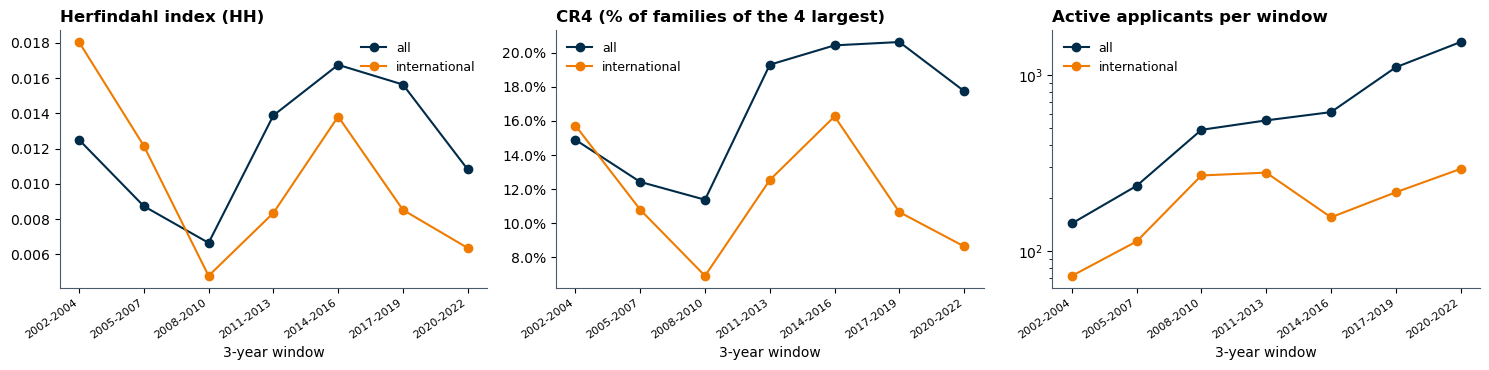

sample,window,mid,applicants,HH,1/HH,CR4,top-4 applicants
all,2002-2004,2003,143,0.0125,80.0,14.9%,"Us Navy, Chinese Academy Of Sci, Tkms (Atlas Elektronik, Honeywell Internationa"
all,2005-2007,2006,234,0.0087,114.4,12.4%,"Chinese Academy Of Sci, Tkms (Atlas Elektronik, Us Navy, Korea Ocean Research A"
all,2008-2010,2009,487,0.0067,150.3,11.4%,"Harbin Engineering Uni, Chinese Academy Of Sci, Tkms (Atlas Elektronik, Ihi"
all,2011-2013,2012,551,0.0139,72.0,19.3%,"Chinese Academy Of Sci, Samsung Heavy Industri, Harbin Engineering Uni, Kiost"
all,2014-2016,2015,614,0.0168,59.7,20.4%,"Harbin Engineering Uni, Chinese Academy Of Sci, China State Shipbuildi, Zhejiang University"
all,2017-2019,2018,1104,0.0156,63.9,20.6%,"Harbin Engineering Uni, Chinese Academy Of Sci, Northwestern Polytechn, China State Shipbuildi"
all,2020-2022,2021,1537,0.0108,92.4,17.8%,"Harbin Engineering Uni, Northwestern Polytechn, Chinese Academy Of Sci, China State Shipbuildi"
international,2002-2004,2003,72,0.0181,55.4,15.7%,"Tkms (Atlas Elektronik, Blohm Christian, Lambertus Detlef, Oceaneering"
international,2005-2007,2006,113,0.0122,82.2,10.8%,"Tkms (Atlas Elektronik, Institut Francais De R, Cgg (Viridien), Ifremer Institut Franc"
international,2008-2010,2009,268,0.0048,209.1,6.9%,"Tkms (Atlas Elektronik, Eni, Slb (Schlumberger), Kalwa Joerg"


In [41]:
def windows(end=LAST, size=WINDOW, n=8):
    """n consecutive windows of `size` years, the last one ending at the last complete year. Only FULL windows are kept:
    a shorter first window (e.g. 2000-2001) has fewer families and would inflate HH and CR4."""
    raw = [(e - size + 1, e) for e in range(end, end - size * n, -size)][::-1]
    return [w_ for w_ in raw if w_[0] >= YEAR_MIN]

rows = []
for sample in ["all", "international"]:
    d0 = links[links.docdb_family_id.isin(SAMPLES[sample])]
    for a, b_ in windows():
        d = d0[d0.family_year.between(a, b_)]
        x = d.groupby("applicant")["docdb_family_id"].nunique()
        if len(x) < 5:
            continue
        rows.append({"sample": sample, "window": f"{a}-{b_}", "mid": (a + b_) / 2, "applicants": len(x),
                     "HH": herfindahl(x), "1/HH": 1 / herfindahl(x), "CR4": concentration_ratio(x, 4),
                     "top-4 applicants": ", ".join(x.sort_values(ascending=False).head(4).index.str.title().str[:22])})
cons = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for sample, c in [("all", NAVY), ("international", ORANGE)]:
    d = cons[cons["sample"] == sample]
    axes[0].plot(d["mid"], d["HH"], marker="o", color=c, label=sample)
    axes[1].plot(d["mid"], d["CR4"] * 100, marker="o", color=c, label=sample)
    axes[2].plot(d["mid"], d["applicants"], marker="o", color=c, label=sample)
axes[0].set(title="Herfindahl index (HH)", xlabel="3-year window (mid year)")
axes[1].set(title="CR4 (% of families of the 4 largest)", xlabel="3-year window (mid year)"); axes[1].yaxis.set_major_formatter(PercentFormatter(100))
axes[2].set(title="Active applicants per window", xlabel="3-year window (mid year)"); axes[2].set_yscale("log")
w_ticks = cons[cons["sample"] == "all"]
for ax in axes:
    ax.legend(frameon=False, fontsize=9)
    ax.set_xticks(w_ticks["mid"], w_ticks["window"], rotation=35, ha="right", fontsize=8)   # windows, not 2007.5
    ax.set_xlabel("3-year window")
plt.tight_layout(); save(fig, "s2_concentration_over_time"); plt.show()
cons.style.format({"HH": "{:.4f}", "1/HH": "{:,.1f}", "CR4": "{:.1%}", "mid": "{:.0f}"}).hide(axis="index")

In [42]:
# Is the field consolidating? The sentence is computed from the table above: copy it into the slide.
a_ = cons[cons["sample"] == "all"].reset_index(drop=True)
first_w, peak_w, last_w, prev_w = a_.iloc[0], a_.loc[a_["HH"].idxmax()], a_.iloc[-1], a_.iloc[-2]
chg = last_w["HH"] / prev_w["HH"] - 1
trend = "consolidating" if chg > 0.10 else "de-concentrating" if chg < -0.10 else "stable"
save_table(cons, "concentration_over_time", index=False)
print(f"HH {first_w['HH']:.4f} ({first_w['window']}) → peak {peak_w['HH']:.4f} ({peak_w['window']}) → {last_w['HH']:.4f} ({last_w['window']}); "
      f"CR4 {first_w['CR4']:.1%} → {peak_w['CR4']:.1%} at the HH peak → {last_w['CR4']:.1%}; active applicants {first_w['applicants']:,} → {last_w['applicants']:,}.")
print(f"In the last window the field is {trend} (HH {chg:+.0%} against the previous window); active applicants "
      f"{last_w['applicants'] / prev_w['applicants'] - 1:+.0%}.")
KEY["HH_first_window"], KEY["HH_peak_window"], KEY["HH_last_window"] = float(first_w["HH"]), float(peak_w["HH"]), float(last_w["HH"])
KEY["HH_trend_last_window"] = trend

HH 0.0125 (2002-2004) → peak 0.0168 (2014-2016) → 0.0108 (2020-2022); CR4 14.9% → 20.4% at the HH peak → 17.8%; active applicants 143 → 1,537.
In the last window the field is de-concentrating (HH -31% against the previous window); active applicants +39%.


### 2.1.2 Concentration by country, and the Lorenz curves

The comparative design of Liston-Heyes & Pilkington (2004) on our sector: the measures computed separately on the
applicants of each country (applicant country, complete years), then countries ranked under each measure and the
agreement between rankings measured with Kendall's tau-b. Countries with at least 30 applicants only.

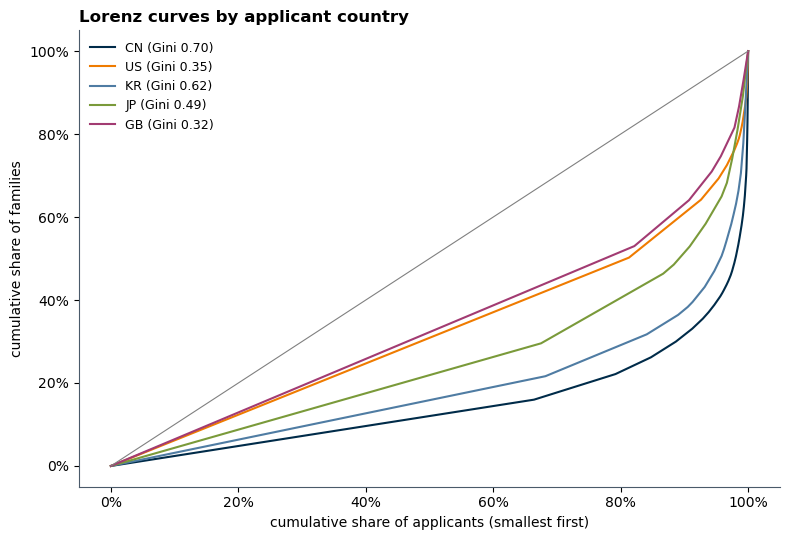

,applicants,families (sum),CR4,CR8,HH,1/HH,CV,Gini,Lotka L,Lotka p
CN,"1,941","8,075",25.3%,32.6%,0.021,46.9,6.36,0.70,-0.99,0.000
US,690,"1,117",14.2%,19.2%,0.010,104.3,2.37,0.35,-1.39,0.000
KR,264,832,33.7%,43.8%,0.037,26.8,2.98,0.62,-1.00,0.000
RU,138,278,23.7%,35.3%,0.024,42.0,1.52,0.44,-1.39,0.000
JP,120,274,31.8%,41.6%,0.033,30.0,1.74,0.49,-1.18,0.000
GB,140,217,20.7%,29.0%,0.018,54.9,1.25,0.32,-1.58,0.001
FR,82,193,41.5%,48.2%,0.052,19.4,1.81,0.50,-1.15,0.003
DE,60,179,59.8%,68.2%,0.212,4.7,3.45,0.63,-0.71,0.047
NO,87,136,24.3%,34.6%,0.025,40.2,1.09,0.32,-1.71,0.001
CA,51,66,19.7%,31.8%,0.026,38.9,0.56,0.19,-2.38,0.010


,CV,CR4,CR8,HH,Lotka L,Gini
CV,1.00,0.36,0.28,0.10,0.76,0.82
CR4,0.36,1.00,0.87,0.74,0.48,0.49
CR8,0.28,0.87,1.00,0.82,0.39,0.41
HH,0.10,0.74,0.82,1.00,0.24,0.23
Lotka L,0.76,0.48,0.39,0.24,1.00,0.91
Gini,0.82,0.49,0.41,0.23,0.91,1.00


In [43]:
by_ctry = {}
for ctry, d in links_c.groupby("country"):
    x = d.groupby("applicant")["docdb_family_id"].nunique()
    if len(x) >= 30:
        by_ctry[ctry] = six_measures(x)
by_ctry = pd.DataFrame(by_ctry).T.sort_values("families (sum)", ascending=False)
MEAS = ["CV", "CR4", "CR8", "HH", "Lotka L", "Gini"]
scores = by_ctry[MEAS].copy(); scores["Lotka L"] = -scores["Lotka L"].abs()
tau = pd.DataFrame(index=MEAS, columns=MEAS, dtype=float)
for a in MEAS:
    for b_ in MEAS:
        tau.loc[a, b_] = stats.kendalltau(scores[a], scores[b_], nan_policy="omit")[0]

fig, ax = plt.subplots(figsize=(8, 5.5))
for ctry, c in zip(["CN", "US", "KR", "JP", "GB"], PALETTE):
    x = links_c[links_c.country == ctry].groupby("applicant")["docdb_family_id"].nunique()
    if len(x):
        f_, p_ = lorenz_curve(x); ax.plot(f_, p_, color=c, label=f"{ctry} (Gini {gini(x):.2f})")
ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
ax.set(title="Lorenz curves by applicant country", xlabel="cumulative share of applicants (smallest first)", ylabel="cumulative share of families")
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); save(fig, "s2_lorenz_by_country"); plt.show()
display(by_ctry.style.format({"applicants": "{:,.0f}", "families (sum)": "{:,.0f}", "CR4": "{:.1%}", "CR8": "{:.1%}", "HH": "{:.3f}",
                              "1/HH": "{:,.1f}", "CV": "{:.2f}", "Gini": "{:.2f}", "Lotka L": "{:.2f}", "Lotka p": "{:.3f}"}, na_rep="–"))
tau.round(2)

## 2.2 The players: incumbents, entrants and the shortlist for Step 3

**Top applicants** with type, country, size, momentum and a first look at quality. Definitions (all design choices):

- **incumbent**: first family in the sector before `SPLIT_YEAR` (2015); **entrant**: from 2015 on;
- **momentum**: share of the sector's families in 2018–2022 minus share in 2013–2017 (percentage points);
- **influence preview**: forward citations within 5 years divided by the mean of the families of the same priority
  year (Tutorial 4 §5.1; complete 5-year windows only), averaged over the applicant's families: 1 = average;
- **international share**: share of the applicant's families filed at more than one office or via PCT;
- **families in force** and **residual life** (after re-running `02_clean` §9.1): how much of the portfolio still
  protects today, and for how many years (median over the families in force).

In [44]:
fam["fwd5_norm"] = np.nan
ok = fam.fwd_window_complete
fam.loc[ok, "fwd5_norm"] = fam.loc[ok, "fwd_cits_5y"] / fam.loc[ok].groupby("family_year")["fwd_cits_5y"].transform("mean").replace(0, np.nan)
fl = links.merge(fam[["docdb_family_id", "is_international", "granted_any", "fwd5_norm", "n_offices", "b6_only"]], on="docdb_family_id")

tot_past = fam.family_year.between(*PAST).sum(); tot_rec = fam.family_year.between(*RECENT).sum()
g = fl.groupby("applicant")
rec_n = fl[fl.family_year.between(*RECENT)].groupby("applicant")["docdb_family_id"].nunique().reindex(g.size().index, fill_value=0)
past_n = fl[fl.family_year.between(*PAST)].groupby("applicant")["docdb_family_id"].nunique().reindex(g.size().index, fill_value=0)
players = pd.DataFrame({
    "type": g["type"].first(), "country": g["country"].agg(lambda s: s.mode().iat[0] if s.notna().any() else None),
    "families": g["docdb_family_id"].nunique(), "fractional": g["weight"].sum(),
    "first year": g["family_year"].min(), "last year": g["family_year"].max(),
    f"families {RECENT[0]}-{RECENT[1]}": fl[fl.family_year.between(*RECENT)].groupby("applicant")["docdb_family_id"].nunique(),
    f"families since {SPLIT_YEAR}": fl[fl.family_year >= SPLIT_YEAR].groupby("applicant")["docdb_family_id"].nunique(),
    # both windows aligned on ALL applicants: a player with no recent family gets a negative momentum, not a blank
    "momentum (pp)": (rec_n / tot_rec - past_n / tot_past) * 100,
    "international share": g["is_international"].mean(), "mean offices": g["n_offices"].mean(),
    "granted share": g["granted_any"].mean(), "influence (fwd5, 1 = avg)": g["fwd5_norm"].mean(),
}).fillna({f"families {RECENT[0]}-{RECENT[1]}": 0, f"families since {SPLIT_YEAR}": 0})
players["share of sector"] = players["families"] / len(fam)
# how much of each portfolio comes only from block 6 (strict precision 48%): a high share means the rank is fragile
players["block-6-only share"] = g["b6_only"].mean()
if HAS_LIFE:   # portfolio still alive today, and how long it still protects (IM_Theory_3: size and obsolescence)
    fl2 = links[["docdb_family_id", "applicant"]].merge(fam[["docdb_family_id", "family_status", "family_residual_life_years"]], on="docdb_family_id")
    players["families in force"] = fl2[fl2.family_status.eq("in force")].groupby("applicant")["docdb_family_id"].nunique()
    players["families in force"] = players["families in force"].fillna(0)
    players["residual life (median yrs)"] = fl2.groupby("applicant")["family_residual_life_years"].median()
players["status"] = np.where(players["first year"] < SPLIT_YEAR, "incumbent", "entrant")
players["is client"] = players.index == CLIENT
players = players.sort_values("families", ascending=False)
players.to_csv(OUT / "players_all.csv")

FMT_P = {"families": "{:,.0f}", "fractional": "{:,.1f}", "first year": "{:.0f}", "last year": "{:.0f}",
         f"families {RECENT[0]}-{RECENT[1]}": "{:,.0f}", "momentum (pp)": "{:+.2f}", "international share": "{:.0%}",
         "mean offices": "{:.2f}", "granted share": "{:.0%}", "influence (fwd5, 1 = avg)": "{:.2f}", "share of sector": "{:.2%}",
         "block-6-only share": "{:.0%}", "families in force": "{:,.0f}", "residual life (median yrs)": "{:.1f}", f"families since {SPLIT_YEAR}": "{:,.0f}", "years active": "{:.0f}"}
cols_show = ["type", "country", "families", "share of sector", "first year", "status", f"families {RECENT[0]}-{RECENT[1]}",
             "momentum (pp)", "international share", "influence (fwd5, 1 = avg)", "block-6-only share"] + (["families in force", "residual life (median yrs)"] if HAS_LIFE else [])
short(players.head(TOP_N)[cols_show]).style.format(FMT_P, na_rep="–")

,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)",block-6-only share,families in force,residual life (median yrs)
applicant,,,,,,,,,,,,,
HARBIN ENGINEERING UNIVERSITY,university,CN,"1,226",7.81%,2004,incumbent,508,-1.25,1%,1.19,19%,565,14.2
CHINESE ACADEMY OF SCIENCES,university,CN,804,5.12%,2001,incumbent,329,-1.04,2%,0.69,19%,378,14.0
CHINA STATE SHIPBUILDING (CSSC),firm,CN,697,4.44%,2007,incumbent,208,-0.12,0%,0.92,36%,290,15.9
NORTHWESTERN POLYTECHNICAL UNIVERSITY,university,CN,575,3.66%,2010,incumbent,290,+1.91,0%,1.28,28%,281,14.8
ZHEJIANG UNIVERSITY,university,CN,381,2.43%,2006,incumbent,165,+0.06,4%,1.34,20%,186,15.1
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,university,CN,223,1.42%,2013,incumbent,100,+0.24,5%,1.66,23%,106,15.2
TIANJIN UNIVERSITY,university,CN,199,1.27%,2005,incumbent,85,+1.06,2%,1.03,18%,75,15.9
DALIAN MARITIME UNIVERSITY,university,CN,165,1.05%,2013,incumbent,91,+1.03,2%,0.99,23%,62,14.4
HOHAI UNIVERSITY,university,CN,158,1.01%,2010,incumbent,54,-0.52,4%,1.11,25%,77,15.3


The overall ranking is a ranking of **Chinese universities**. For an acquirer that is not the relevant competitive
set: a university cannot be bought (it can be a *partner*, licensor or source of spin-offs, IM_Theory_2). The deck
table should therefore show three views: top firms worldwide, top firms outside China, and top universities /
public research organisations (potential partners).

In [45]:
firms = players[players.type.isin(["firm", "unknown"])]
display(short(firms.head(TOP_N)[cols_show]).style.format(FMT_P, na_rep="–").set_caption("Top firms (incl. unclassified companies)"))
display(short(firms[firms.country != "CN"].head(TOP_N)[cols_show]).style.format(FMT_P, na_rep="–").set_caption("Top firms outside China"))
short(players[players.type.isin(["university", "government / non-profit"])].head(10)[cols_show]).style.format(FMT_P, na_rep="–").set_caption("Top universities and public research organisations")

,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)",block-6-only share,families in force,residual life (median yrs)
applicant,,,,,,,,,,,,,
CHINA STATE SHIPBUILDING (CSSC),firm,CN,697,4.44%,2007,incumbent,208,-0.12,0%,0.92,36%,290,15.9
CNOOC,firm,CN,102,0.65%,2007,incumbent,35,-0.30,0%,0.52,55%,39,12.6
HANWHA,firm,KR,101,0.64%,2003,incumbent,41,-0.61,0%,0.46,12%,66,13.6
TKMS (ATLAS ELEKTRONIK),firm,DE,96,0.61%,2000,incumbent,18,-0.57,95%,0.80,16%,49,8.3
STATE GRID (SGCC),firm,CN,96,0.61%,2015,entrant,36,+0.04,1%,2.34,25%,29,14.9
SAMSUNG HEAVY INDUSTRIES,firm,KR,91,0.58%,2010,incumbent,1,-2.61,2%,0.27,60%,42,7.2
DEEPINFAR OCEAN TECHNOLOGY,firm,CN,75,0.48%,2013,incumbent,31,-0.40,8%,0.44,7%,38,14.8
CRRC,firm,CN,69,0.44%,2018,entrant,48,+0.76,7%,–,19%,28,14.3
CHINA HUANENG GROUP,firm,CN,57,0.36%,2020,entrant,16,+0.25,4%,–,25%,22,16.2


,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)",block-6-only share,families in force,residual life (median yrs)
applicant,,,,,,,,,,,,,
HANWHA,firm,KR,101,0.64%,2003,incumbent,41,-0.61,0%,0.46,12%,66,13.6
TKMS (ATLAS ELEKTRONIK),firm,DE,96,0.61%,2000,incumbent,18,-0.57,95%,0.80,16%,49,8.3
SAMSUNG HEAVY INDUSTRIES,firm,KR,91,0.58%,2010,incumbent,1,-2.61,2%,0.27,60%,42,7.2
OCEANEERING,firm,US,45,0.29%,2000,incumbent,10,-0.65,76%,1.16,2%,21,10.3
BAE SYSTEMS,firm,GB,41,0.26%,2001,incumbent,18,+0.20,34%,0.83,7%,14,14.7
LIG NEX1,firm,KR,31,0.20%,2010,incumbent,16,+0.01,0%,0.27,39%,29,12.2
IHI,firm,JP,30,0.19%,2008,incumbent,8,-0.32,10%,0.81,67%,27,8.5
CGG (VIRIDIEN),firm,FR,28,0.18%,2005,incumbent,2,-0.49,89%,2.32,7%,15,7.3
FUGRO,firm,NL,27,0.17%,2005,incumbent,3,-0.72,81%,2.25,4%,21,11.3


,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)",block-6-only share,families in force,residual life (median yrs)
applicant,,,,,,,,,,,,,
HARBIN ENGINEERING UNIVERSITY,university,CN,"1,226",7.81%,2004,incumbent,508,-1.25,1%,1.19,19%,565,14.2
CHINESE ACADEMY OF SCIENCES,university,CN,804,5.12%,2001,incumbent,329,-1.04,2%,0.69,19%,378,14.0
NORTHWESTERN POLYTECHNICAL UNIVERSITY,university,CN,575,3.66%,2010,incumbent,290,+1.91,0%,1.28,28%,281,14.8
ZHEJIANG UNIVERSITY,university,CN,381,2.43%,2006,incumbent,165,+0.06,4%,1.34,20%,186,15.1
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,university,CN,223,1.42%,2013,incumbent,100,+0.24,5%,1.66,23%,106,15.2
TIANJIN UNIVERSITY,university,CN,199,1.27%,2005,incumbent,85,+1.06,2%,1.03,18%,75,15.9
DALIAN MARITIME UNIVERSITY,university,CN,165,1.05%,2013,incumbent,91,+1.03,2%,0.99,23%,62,14.4
HOHAI UNIVERSITY,university,CN,158,1.01%,2010,incumbent,54,-0.52,4%,1.11,25%,77,15.3
OCEAN UNIVERSITY OF CHINA,university,CN,157,1.00%,2008,incumbent,67,+0.13,2%,1.40,18%,103,14.4


**Start-ups.** The kick-off asks for the applicant type *firm / start-up / university*, but `psn_sector` has no
start-up category. Offline proxy (to verify by hand on company websites / Crunchbase): a **young firm** is a firm
whose first family in the sector is from 2015 on, with **3 to 30 families, active in at least 2 different years and
still active in the last two complete years**, not part of a large group in `GROUP_ALIASES` (without these filters
the proxy flags more than a thousand single-family filers). On TIP, the optional cell below refines it with the year of the **first patent ever, in any field**
(Tutorial 1 nb 11 §5.0: "they never patented before").

Read the list with care: the proxy also catches **large incumbents of other industries** that enter the sector late
(power grids, oil majors, rail-equipment makers). They are *diversifying entrants*, not start-ups, and they are a
finding in themselves (who is moving into underwater drones, and from where). The first-patent-ever refinement
separates the two groups.

In [46]:
big_groups = set(C.GROUP_ALIASES.values())
players["years active"] = links.groupby("applicant")["family_year"].nunique().reindex(players.index).fillna(0).astype(int)
players["young firm (start-up candidate)"] = (players.type.isin(["firm", "unknown"]) & players["first year"].between(SPLIT_YEAR, LAST)
                                              & players["families"].between(3, 30) & (players["years active"] >= 2)
                                              & (players["last year"] >= LAST - 1) & ~players.index.isin(big_groups))
young = players[players["young firm (start-up candidate)"]].head(15)
players.to_csv(OUT / "players_all.csv")
print(f"{players['young firm (start-up candidate)'].sum():,} young firms (entered {SPLIT_YEAR}-{LAST}, 3-30 families, still active); the largest:")
short(young[["country", "families", "first year", "years active", "international share", "influence (fwd5, 1 = avg)"]]).style.format(FMT_P, na_rep="–")

122 young firms (entered 2015-2022, 3-30 families, still active); the largest:


,country,families,first year,years active,international share,"influence (fwd5, 1 = avg)"
applicant,,,,,,
GUANGDONG POWER GRID,CN,26,2020,5,0%,–
KUNMING HAIWEI ELECTROMECHANICAL TECHNOLOGY …,CN,24,2019,7,0%,–
ARTIFICIAL INTELLIGENCE ROBOT,KR,20,2017,5,5%,0.14
QINGDAO PENGPAI OCEAN EXPLORATION TECHNOLOGY,CN,19,2019,6,0%,–
SHENGDONG RUDONG OFFSHORE WIND POWER GENERAT…,CN,19,2022,3,0%,–
TIANJIN HANHAI LANFAN MARINE TECHNOLOGY,CN,19,2017,7,0%,1.05
SHENZHEN CHASING INNOVATION TECHNOLOGY,CN,17,2016,8,18%,1.46
FOSHAN SHUNDE YITUO ELECTRICAL,CN,16,2022,3,0%,–
HEBEI HANGUANG INDUSTRY,CN,16,2019,6,0%,–


In [47]:
if RUN_PATSTAT:   # TIP only: first patent ever (any field) of the top applicants, from their PATSTAT names
    try:
        from epo.tipdata.patstat import PatstatClient
        from epo.tipdata.patstat.database.models import TLS201_APPLN, TLS206_PERSON, TLS207_PERS_APPLN
        from sqlalchemy import func
        patstat = PatstatClient(env=C.ENV); db = patstat.orm()
        raw = appl.drop_duplicates("applicant").set_index("applicant")["raw_names"].dropna()
        names = {n.strip(): grp_name for grp_name, s in raw.loc[raw.index.isin(players.head(300).index)].items() for n in s.split("|")}
        q = (db.query(TLS206_PERSON.psn_name, func.min(TLS201_APPLN.earliest_filing_year).label("first_patent_year"))
             .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
             .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
             .filter(TLS206_PERSON.psn_name.in_(list(names)), TLS207_PERS_APPLN.applt_seq_nr > 0,
                     TLS201_APPLN.earliest_filing_year.between(1900, YEAR_MAX))
             .group_by(TLS206_PERSON.psn_name))
        first_ever = patstat.df(q).assign(applicant=lambda d: d.psn_name.map(names)).groupby("applicant")["first_patent_year"].min()
        players["first patent ever"] = first_ever
        # refinement of the start-up proxy: a "young firm" that patented in other fields before SPLIT_YEAR is a
        # diversifying entrant (an incumbent of another industry), not a start-up
        players["diversifying entrant"] = players["young firm (start-up candidate)"] & players["first patent ever"].lt(SPLIT_YEAR)
        players.loc[players["diversifying entrant"], "young firm (start-up candidate)"] = False
        print(f"First patent ever found for {first_ever.size} groups; {int(players['diversifying entrant'].sum())} 'young firms' "
              f"had patented before {SPLIT_YEAR} in other fields (diversifying entrants); start-up candidates left: "
              f"{int(players['young firm (start-up candidate)'].sum())}")
        players.to_csv(OUT / "players_all.csv")
    except Exception as e:      # a failing optional query must not stop the notebook
        print(f"first-patent-ever query failed ({type(e).__name__}: {str(e)[:150]}): start-up flag left as the offline proxy")
else:
    print("run_patstat off (config/sector.yaml) or not on TIP: first-patent-ever not queried")

First patent ever found for 300 groups; 12 'young firms' had patented before 2015 in other fields (diversifying entrants); start-up candidates left: 110


### 2.2.1 Shortlist for Step 3 (present score)

The players worth scoring: **firms** (including unclassified companies) with at least `MIN_FAMILIES_SCORE` families
in the sector (a volume gate, as in Clarivate and Tutorial 4), plus the client as a reference point. Saved as
`shortlist_step3.csv`. The choice of gate is a design decision to justify in the appendix.

In [48]:
shortlist = players[(players.type.isin(["firm", "unknown"]) & (players.families >= MIN_FAMILIES_SCORE)) | players["is client"]]
shortlist.to_csv(OUT / "shortlist_step3.csv")
KEY["shortlist_size"] = int(len(shortlist))
print(f"{len(shortlist)} applicants in the shortlist ({(shortlist.country != 'CN').sum()} outside China); client included: {CLIENT in shortlist.index}")
short(shortlist.head(25)[cols_show]).style.format(FMT_P, na_rep="–")

87 applicants in the shortlist (36 outside China); client included: True


,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)",block-6-only share,families in force,residual life (median yrs)
applicant,,,,,,,,,,,,,
CHINA STATE SHIPBUILDING (CSSC),firm,CN,697,4.44%,2007,incumbent,208,-0.12,0%,0.92,36%,290,15.9
CNOOC,firm,CN,102,0.65%,2007,incumbent,35,-0.30,0%,0.52,55%,39,12.6
HANWHA,firm,KR,101,0.64%,2003,incumbent,41,-0.61,0%,0.46,12%,66,13.6
TKMS (ATLAS ELEKTRONIK),firm,DE,96,0.61%,2000,incumbent,18,-0.57,95%,0.80,16%,49,8.3
STATE GRID (SGCC),firm,CN,96,0.61%,2015,entrant,36,+0.04,1%,2.34,25%,29,14.9
SAMSUNG HEAVY INDUSTRIES,firm,KR,91,0.58%,2010,incumbent,1,-2.61,2%,0.27,60%,42,7.2
DEEPINFAR OCEAN TECHNOLOGY,firm,CN,75,0.48%,2013,incumbent,31,-0.40,8%,0.44,7%,38,14.8
CRRC,firm,CN,69,0.44%,2018,entrant,48,+0.76,7%,–,19%,28,14.3
CHINA HUANENG GROUP,firm,CN,57,0.36%,2020,entrant,16,+0.25,4%,–,25%,22,16.2


### 2.2.2 Patent information card: who owns it, where it is protected, since when

Patent *data* become patent *information* when they are organised to answer a question (IM_Theory_3). For a single
invention the three questions are **who owns it** (applicant at filing, field 71, and owner today, field 73),
**where it is protected** (every office of the family with its status) and **since when / until when** (priority,
filing, publication, grant, opposition deadline, expiry). `patent_card(x)` accepts a `docdb_family_id` or an
`appln_id` (for an application it prints its family and highlights that application) and returns the tables as a
dict, so the cards of Step 3 competitors can be exported. It reads only the clean tables of `02_clean`. Columns that
are missing (for example the life-cycle dates before `02_clean` is re-run) are simply left out.

Caveats to report: status is rebuilt from PATSTAT legal events up to the last event date (`AS_OF`), it is not the
official register; for EP patents PATSTAT shows the countries where the patent **lapsed**, not the full list of
validation countries (EPO Register); for many Chinese transfers the new owner is not named.

In [49]:
def _opt(name):
    p = IN / name
    return pd.read_csv(p, low_memory=False) if p.exists() else None


app_appl = _opt("application_applicants.csv")
cur_own = _opt("current_owners.csv")
fam_own = _opt("family_current_owners.csv")
own_ev = _opt("ownership_events.csv")
AS_OF_CARD = (pd.to_datetime(legal["event_publn_date"], errors="coerce").max()
              if "event_publn_date" in legal.columns else None)


def _d(x):
    """Date or number as a short string, '–' if missing."""
    if x is None or (not isinstance(x, str) and pd.isna(x)):
        return "–"
    if isinstance(x, (float, np.floating)):
        return f"{x:.1f}"
    s = str(x)
    return s[:10] if len(s) >= 10 and s[4:5] == "-" else s


def patent_card(x, show=True, max_rows=30):
    """Who owns it, where it is protected, since when: card of one DOCDB family (or of the family of one appln_id)."""
    x = int(x)
    appln = None
    if x in set(fam["docdb_family_id"]):
        fid = x
    elif x in set(apps["appln_id"]):
        appln, fid = x, int(apps.loc[apps["appln_id"].eq(x), "docdb_family_id"].iloc[0])
    else:
        raise KeyError(f"{x} is neither a docdb_family_id nor an appln_id of the sector")
    f = fam[fam["docdb_family_id"].eq(fid)].iloc[0]
    out = {}

    # ---------------------------------------------------------------- WHO
    who = appl[appl["docdb_family_id"].eq(fid)][[c for c in ["applicant", "applicant_type", "country", "weight", "raw_names"]
                                                  if c in appl.columns]].copy()
    if fam_own is not None:
        now = fam_own[fam_own["docdb_family_id"].eq(fid)]
        out["current_owners"] = now[["current_owner", "weight"]].reset_index(drop=True)
    else:
        now = None
    if own_ev is not None:
        ev = own_ev[own_ev["docdb_family_id"].eq(fid) & own_ev["is_real_change"].astype(bool)]
        out["ownership_changes"] = ev[[c for c in ["appln_id", "event_auth", "date", "category", "party_old", "new_owner",
                                                   "event_descr"] if c in ev.columns]].sort_values("date").reset_index(drop=True)
        sec = own_ev[own_ev["docdb_family_id"].eq(fid) & own_ev["category"].isin(["security", "licence"])]
        out["security_and_licences"] = sec[[c for c in ["appln_id", "event_auth", "date", "category", "party_new"]
                                            if c in sec.columns]].reset_index(drop=True)
    out["applicants_at_filing"] = who.reset_index(drop=True)

    # ---------------------------------------------------------------- WHERE
    where_cols = ["appln_id", "appln_auth", "appln_kind", "appln_filing_date", "first_publn_date", "grant_date", "grant_kind",
                  "status", "end_type", "end_date", "opposition_deadline", "pct_national_phase_deadline", "expiry_date",
                  "residual_life_years", "max_renewal_year_appln", "n_lapsed_countries"]
    where = apps[apps["docdb_family_id"].eq(fid)][[c for c in where_cols if c in apps.columns]].drop_duplicates("appln_id")
    if "is_granted" in apps.columns and "grant_date" not in where.columns:
        where = where.merge(apps[["appln_id", "is_granted"]].drop_duplicates("appln_id"), on="appln_id", how="left")
    if cur_own is not None:
        where = where.merge(cur_own[[c for c in ["appln_id", "current_owners", "n_owner_changes"] if c in cur_own.columns]],
                            on="appln_id", how="left")
    where = where.sort_values([c for c in ["appln_filing_date", "appln_id"] if c in where.columns])
    if appln is not None:
        where.insert(0, "", np.where(where["appln_id"].eq(appln), "►", ""))
    out["applications"] = where.reset_index(drop=True)

    # ---------------------------------------------------------------- SINCE WHEN
    when_fields = [("priority date", "priority_date"), ("priority year (counting year)", "family_year"),
                   ("first filing", "first_filing_date"), ("first publication", "first_publn_date"),
                   ("first grant", "first_grant_date"), ("first granting office", "first_grant_office"),
                   ("years priority → first grant", "years_priority_to_first_grant"), ("EP grant", "ep_grant_date"),
                   ("EP opposition deadline", "ep_opposition_deadline"), ("expiry of the family", "family_expiry_date"),
                   ("residual life (years)", "family_residual_life_years"), ("end of the family", "family_end_date")]
    out["since_when"] = pd.DataFrame([(lab, _d(f[c])) for lab, c in when_fields if c in f.index], columns=["", "value"])

    if show:
        title = f.get("title_en") if isinstance(f.get("title_en"), str) else f.get("title")
        status = f.get("family_status", "– (re-run 02_clean)")
        print("═" * 100)
        print(f"DOCDB family {fid}" + (f"  (card opened from appln_id {appln})" if appln else ""))
        print(f"Title: {title if isinstance(title, str) else '–'}")
        print(f"Status: {status} | offices: {f.get('offices', '–')} | in force in {_d(f.get('n_in_force_offices'))} of "
              f"{_d(f.get('n_offices'))} offices | international: {bool(f.get('is_international'))} | "
              f"forward citations: {_d(f.get('fwd_cits'))} | status as of: {_d(AS_OF_CARD)}")
        print("─" * 100, "\nWHO OWNS IT")
        print("At filing (field 71):", " | ".join(f"{r.applicant} ({r.applicant_type}, {r.country})" for r in who.itertuples()) or "–")
        if now is not None:
            changed = bool(f.get("owner_changed", False))
            print("Today (field 73):   ", " | ".join(now["current_owner"].astype(str)) or "–",
                  "  ← owner changed" if changed else "  (no change of owner recorded)")
            if len(out.get("ownership_changes", [])):
                display(out["ownership_changes"].head(max_rows))
            if len(out.get("security_and_licences", [])):
                print("Security interests / licences recorded:")
                display(out["security_and_licences"].head(max_rows))
        else:
            print("Today: – (re-run 02_clean for Section 9.2)")
        print("─" * 100, "\nWHERE IT IS PROTECTED")
        display(out["applications"].head(max_rows))
        if "n_lapsed_countries" in where.columns and where["appln_auth"].eq("EP").any():
            print("EP: PATSTAT lists the countries where the patent lapsed, not every validation country.")
        print("─" * 100, "\nSINCE WHEN / UNTIL WHEN")
        display(out["since_when"].set_index(""))
    return out


# demo: the client's widest family and the most cited family of the first non-client firm of the shortlist
client_fams = appl.loc[appl["applicant"].eq(CLIENT), "docdb_family_id"].unique()
if len(client_fams):
    demo = fam[fam["docdb_family_id"].isin(client_fams)].sort_values(["n_offices", "fwd_cits"], ascending=False)
    card_client = patent_card(demo["docdb_family_id"].iloc[0])
rival = next((a for a in shortlist.index if a != CLIENT), None)
if rival is not None:
    rf = appl.loc[appl["applicant"].eq(rival), "docdb_family_id"].unique()
    demo = fam[fam["docdb_family_id"].isin(rf)].sort_values(["fwd_cits", "n_offices"], ascending=False)
    card_rival = patent_card(demo["docdb_family_id"].iloc[0])

════════════════════════════════════════════════════════════════════════════════════════════════════
DOCDB family 66867675
Title: VALVE SYSTEM FOR AN ELECTROCHEMICAL POWER SOURCE, IN PARTICULAR FOR AN UNDERWATER VESSEL, AND ITS ELECTROCHEMICAL POWER SOURCE
Status: in force | offices: EP FI IT US | in force in 3 of 4 offices | international: True | forward citations: 0 | status as of: 2026-08-21
──────────────────────────────────────────────────────────────────────────────────────────────────── 
WHO OWNS IT
At filing (field 71): FINCANTIERI (firm, IT)
Today (field 73):    FINCANTIERI   (no change of owner recorded)
──────────────────────────────────────────────────────────────────────────────────────────────────── 
WHERE IT IS PROTECTED


,appln_id,appln_auth,appln_kind,appln_filing_date,first_publn_date,grant_date,grant_kind,status,end_type,end_date,opposition_deadline,pct_national_phase_deadline,expiry_date,residual_life_years,max_renewal_year_appln,n_lapsed_countries,current_owners,n_owner_changes
0,514954101,IT,A,2019-03-15,2020-09-15,NaT,NaN,pending,NaN,NaT,NaN,NaN,2039-03-15,NaN,NaN,0,FINCANTIERI,0
1,527751109,EP,A,2020-03-13,2020-09-16,2023-05-24,B1,in force,NaN,NaT,2024-02-24,NaN,2040-03-13,13.560575,7.0,25,FINCANTIERI,0
2,537906252,US,A,2020-03-13,2020-09-17,2021-12-28,B2,in force,NaN,NaT,NaN,NaN,2040-03-13,13.560575,4.0,0,FINCANTIERI,0
3,596057404,FI,T,2020-03-13,2023-07-21,2023-07-21,T3,in force,NaN,NaT,NaN,NaN,2040-03-13,13.560575,NaN,0,FINCANTIERI,0


EP: PATSTAT lists the countries where the patent lapsed, not every validation country.
──────────────────────────────────────────────────────────────────────────────────────────────────── 
SINCE WHEN / UNTIL WHEN


,value
,
priority date,2019-03-15
priority year (counting year),2019
first filing,2019-03-15
first publication,2020-09-15
first grant,2021-12-28
first granting office,US
years priority → first grant,2.8
EP grant,2023-05-24
EP opposition deadline,2024-02-24


════════════════════════════════════════════════════════════════════════════════════════════════════
DOCDB family 57817628
Title: Underwater docking, recycling and laying device for AUV
Status: in force | offices: CN | in force in 1 of 1 offices | international: False | forward citations: 50 | status as of: 2026-08-21
──────────────────────────────────────────────────────────────────────────────────────────────────── 
WHO OWNS IT
At filing (field 71): CHINA STATE SHIPBUILDING (CSSC) (firm, CN)
Today (field 73):    CHINA STATE SHIPBUILDING (CSSC)   (no change of owner recorded)
──────────────────────────────────────────────────────────────────────────────────────────────────── 
WHERE IT IS PROTECTED


,appln_id,appln_auth,appln_kind,appln_filing_date,first_publn_date,grant_date,grant_kind,status,end_type,end_date,opposition_deadline,pct_national_phase_deadline,expiry_date,residual_life_years,max_renewal_year_appln,n_lapsed_countries,current_owners,n_owner_changes
0,474323519,CN,A,2016-10-14,2017-01-11,2018-01-26,B,in force,NaN,NaT,NaN,NaN,2036-10-14,10.149213,NaN,0,CHINA STATE SHIPBUILDING (CSSC),0


──────────────────────────────────────────────────────────────────────────────────────────────────── 
SINCE WHEN / UNTIL WHEN


,value
,
priority date,2016-10-14
priority year (counting year),2016
first filing,2016-10-14
first publication,2017-01-11
first grant,2018-01-26
first granting office,CN
years priority → first grant,1.3
EP grant,–
EP opposition deadline,–


To export the cards of the Step 3 competitors (one sheet per table), for example:
`cards = {fid: patent_card(fid, show=False) for fid in some_family_ids}`.

### 2.2.3 How do the competitors patent? A benchmark of patenting strategies

The same volume can hide very different strategies (IM_Theory_2, *choice of the IPR strategy*; Tutorial 4). For every
player of the shortlist, and for the client, the indicators below describe **how** it patents:

| Dimension | Indicators | Reading |
|---|---|---|
| Scale and momentum | families, recent families, momentum | how much it invests, and whether it accelerates |
| Geographic scope | international share, mean offices, PCT, EP, US, China-only share | how much it pays to protect the market abroad (value signal) |
| Strength | granted share (≤ 2019), alive share, X-citations received per family | how solid and how *blocking* the portfolio is |
| Quality | forward citations (5y, complete window) per family | technological influence |
| Knowledge base | share citing science, co-assigned share | science-based? open to partners? |
| Focus | number of CPC subclasses, concentration (HH) of its subclass mix | specialist or generalist |
| Market for technology | families acquired (owner today ≠ applicant at filing) | grows by buying patents |

A simple rule turns the indicators into **archetypes** (checked in this order): *buyer* (≥ 3 acquired families or
≥ 10% of the portfolio), *global selective* (≥ 50% international), *domestic volume* (< 15% international and above the
shortlist median in families), *specialist* (HH ≥ 0.25), otherwise *mixed*. The thresholds are design choices to
report in the appendix.

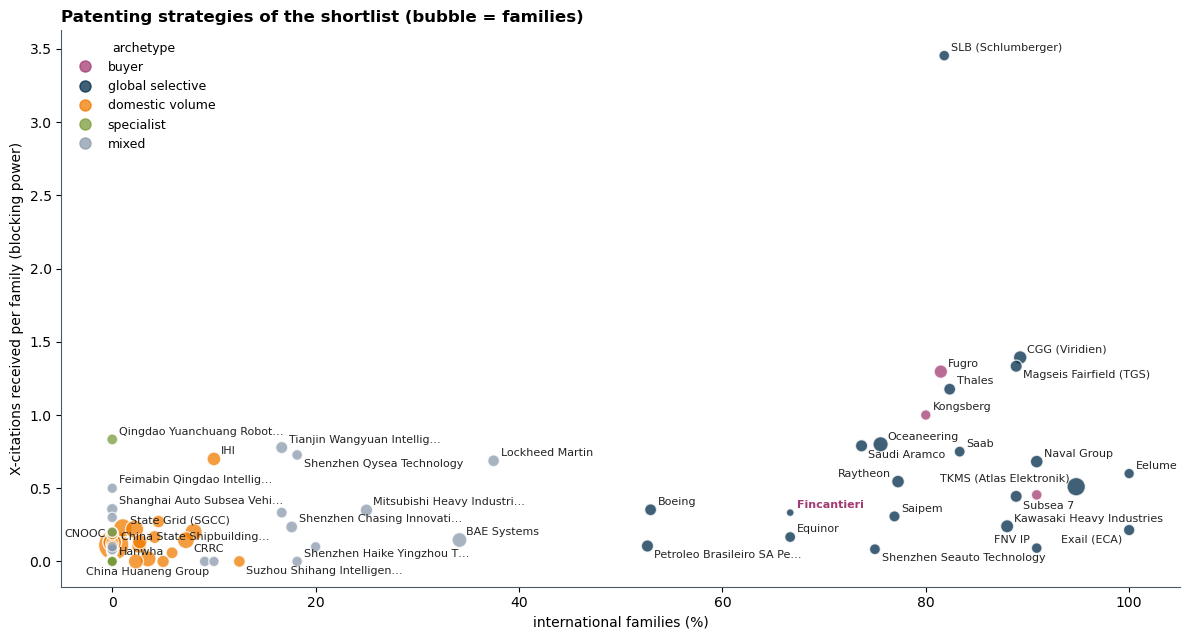

,country,families,families 2018-2022,momentum (pp),international,mean offices,PCT,EP,US,China only,granted (≤2019),alive,X-cits received / family,fwd cits 5y / family,cite science,co-assigned,CPC subclasses,focus (HH),acquired families,block-6-only share,archetype
CHINA STATE SHIPBUILDING (CSSC),CN,697,208,-0.12,0%,1.0,0%,0%,0%,100%,74%,81%,0.11,5.86,28%,11%,92,0.08,0,36%,domestic volume
CNOOC,CN,102,35,-0.30,0%,1.0,0%,0%,0%,100%,67%,73%,0.14,3.10,18%,36%,41,0.09,0,55%,domestic volume
HANWHA,KR,101,41,-0.61,0%,1.0,0%,0%,0%,0%,56%,72%,0.13,2.48,3%,6%,46,0.10,0,12%,domestic volume
TKMS (ATLAS ELEKTRONIK),DE,96,18,-0.57,95%,4.0,81%,75%,35%,0%,83%,66%,0.51,4.29,46%,25%,38,0.20,0,16%,global selective
STATE GRID (SGCC),CN,96,36,+0.04,1%,1.0,1%,0%,0%,99%,25%,62%,0.23,14.23,25%,34%,43,0.06,0,25%,domestic volume
SAMSUNG HEAVY INDUSTRIES,KR,91,1,-2.61,2%,1.1,2%,2%,2%,0%,66%,48%,0.22,1.58,2%,2%,42,0.12,0,60%,domestic volume
DEEPINFAR OCEAN TECHNOLOGY,CN,75,31,-0.40,8%,1.3,9%,5%,5%,91%,52%,71%,0.20,2.91,29%,11%,36,0.11,0,7%,domestic volume
CRRC,CN,69,48,+0.76,7%,1.1,7%,1%,1%,93%,73%,86%,0.14,–,23%,12%,43,0.06,0,19%,domestic volume
CHINA HUANENG GROUP,CN,57,16,+0.25,4%,1.0,2%,0%,0%,96%,–,88%,0.02,–,14%,58%,45,0.07,0,25%,domestic volume
OCEANEERING,US,45,10,-0.65,76%,2.6,84%,47%,84%,0%,72%,64%,0.80,5.73,33%,18%,38,0.11,0,2%,global selective


In [50]:
bench_set = list(shortlist.index)
bl = links[links.applicant.isin(bench_set)].merge(
    fam[["docdb_family_id", "family_year", "is_international", "n_offices", "via_pct", "has_ep", "offices", "granted_any",
         "active_proxy", "fwd_X_cits", "fwd_cits_5y", "fwd_window_complete", "cites_science", "co_assigned"]
        + [c for c in ["family_status"] if c in fam.columns]], on="docdb_family_id", suffixes=("", "_f"))
bl["family_year"] = bl["family_year_f"] if "family_year_f" in bl else bl["family_year"]
bl["co_assigned"] = bl["co_assigned"].astype(str).str.lower().eq("true")
bl["via_pct"] = bl["via_pct"].astype(bool); bl["has_ep"] = bl["has_ep"].astype(bool)
bl["has_us"] = bl["offices"].astype(str).str.split().apply(lambda s: "US" in s)
bl["cn_only"] = bl["offices"].astype(str).str.strip().eq("CN")
bl["alive"] = bl["family_status"].isin(["in force", "pending"]) if "family_status" in bl else bl["active_proxy"]

# technology focus: subclass mix of each player (fractional)
sx = links[links.applicant.isin(bench_set)][["docdb_family_id", "applicant"]].merge(fsub[["docdb_family_id", "subclass", "weight"]], on="docdb_family_id")
mix = sx.groupby(["applicant", "subclass"])["weight"].sum()
mix = mix / mix.groupby(level=0).transform("sum")
hh_focus = (mix ** 2).groupby(level=0).sum()
n_sub = sx.groupby("applicant")["subclass"].nunique()

# acquired families (Section 9.2 of 02_clean)
if fam_own is not None and "owner_changed" in fam_own.columns:
    filed = appl.groupby("docdb_family_id")["applicant"].agg(set).to_dict()
    acq = fam_own[fam_own.owner_changed.astype(bool)]
    acq = acq[[o not in filed.get(f, set()) for f, o in zip(acq.docdb_family_id, acq.current_owner)]]
    acquired = acq.groupby("current_owner")["docdb_family_id"].nunique()
else:
    acquired = pd.Series(dtype=float)

g2 = bl.groupby("applicant")
strat = pd.DataFrame({
    "families": g2["docdb_family_id"].nunique(),
    f"families {RECENT[0]}-{RECENT[1]}": players.reindex(bench_set)[f"families {RECENT[0]}-{RECENT[1]}"],
    "momentum (pp)": players.reindex(bench_set)["momentum (pp)"],
    "international": g2["is_international"].mean(), "mean offices": g2["n_offices"].mean(),
    "PCT": g2["via_pct"].mean(), "EP": g2["has_ep"].mean(), "US": g2["has_us"].mean(), "China only": g2["cn_only"].mean(),
    "granted (≤2019)": bl[bl.family_year <= 2019].groupby("applicant")["granted_any"].mean(),
    "alive": g2["alive"].mean(),
    "X-cits received / family": g2["fwd_X_cits"].mean(),
    "fwd cits 5y / family": bl[bl.fwd_window_complete].groupby("applicant")["fwd_cits_5y"].mean(),
    "cite science": g2["cites_science"].mean(), "co-assigned": g2["co_assigned"].mean(),
    "CPC subclasses": n_sub, "focus (HH)": hh_focus,
    "acquired families": acquired.reindex(bench_set).fillna(0) if len(acquired) else np.nan,
}).reindex(bench_set)
strat.insert(0, "country", shortlist["country"])
strat["block-6-only share"] = players["block-6-only share"].reindex(strat.index)


def archetype(r):
    acq_n = 0 if pd.isna(r["acquired families"]) else r["acquired families"]
    if acq_n >= 3 or acq_n >= 0.1 * r["families"]:
        return "buyer"
    if r["international"] >= 0.5:
        return "global selective"
    if r["international"] < 0.15 and r["families"] >= strat["families"].median():
        return "domestic volume"
    if r["focus (HH)"] >= 0.25:
        return "specialist"
    return "mixed"


strat["archetype"] = strat.apply(archetype, axis=1)
strat.to_csv(OUT / "competitor_strategies.csv")
KEY["archetypes"] = strat["archetype"].value_counts().to_dict()

fig, ax = plt.subplots(figsize=(12, 6.5))
arch_col = {"buyer": RED, "global selective": NAVY, "domestic volume": ORANGE, "specialist": GREEN, "mixed": MID}
for a, d in strat.groupby("archetype"):
    ax.scatter(d["international"] * 100, d["X-cits received / family"], s=np.sqrt(d["families"]) * 18, color=arch_col[a],
               alpha=0.75, edgecolor="white")
ax.set_xlabel("international families (%)"); ax.set_ylabel("X-citations received per family (blocking power)")
ax.set_title("Patenting strategies of the shortlist (bubble = families)")
from matplotlib.lines import Line2D
ax.legend([Line2D([], [], marker="o", ls="", ms=8, color=c, alpha=0.75) for c in arch_col.values()], list(arch_col),
          frameon=False, fontsize=9, title="archetype", title_fontsize=9, loc="upper left")
plt.tight_layout()
lab_order = strat.assign(_c=strat.index == CLIENT).sort_values(["_c", "families"], ascending=False)   # client first
label_points(ax, lab_order["international"] * 100, lab_order["X-cits received / family"],
             [nice_name(n, 26) for n in lab_order.index], fontsize=8,
             colors=[RED if n == CLIENT else "#222222" for n in lab_order.index],
             fontweights=["bold" if n == CLIENT else None for n in lab_order.index])
save(fig, "2_2_3_strategies"); plt.show()

pct_cols = ["international", "PCT", "EP", "US", "China only", "granted (≤2019)", "alive", "cite science", "co-assigned"]
short(strat.sort_values("families", ascending=False)).style.format(
    {**{c: "{:.0%}" for c in pct_cols}, "momentum (pp)": "{:+.2f}", "mean offices": "{:.1f}", "X-cits received / family": "{:.2f}",
     "fwd cits 5y / family": "{:.2f}", "focus (HH)": "{:.2f}", "families": "{:,.0f}", f"families {RECENT[0]}-{RECENT[1]}": "{:,.0f}",
     "CPC subclasses": "{:,.0f}", "acquired families": "{:,.0f}", "block-6-only share": "{:.0%}"}, na_rep="–")

### 2.2.4 Prosecution history and litigation: how strong and how contested are the portfolios?

High-value and high-risk patents leave traces in their **prosecution history** (IM_Theory_1 and 3): a patent
that survived an opposition is stronger, one amended or limited after grant (EP B2/B3) has a narrower scope, one
refused or withdrawn in some offices protects less than its family suggests, one kept out of the UPC (opt-out) is
valued by its owner. Litigation is the extreme signal of value, but PATSTAT records little of it (national court
cases are mostly missing): a zero here means "not recorded", not "never litigated". Per competitor:

| Indicator | Source |
|---|---|
| EP-granted families, opposed share | EP applications granted; EPO opposition events |
| survived opposition | opposed and still granted at the EPO (not revoked) |
| amended / limited after grant | EP B2 or B3 publication (`02_clean` §9.1; after the re-run) |
| refused or withdrawn somewhere | end of an application by refusal or withdrawal (§9.1). **Before the re-run** of `02_clean` the raw legal-event flag is used: it also catches office actions and "deemed withdrawn" PCT phases, so it overstates the share |
| UPC opt-out, litigation, revocation | refined flags of 1.5.4 |
| grant lag | years from filing to the first grant (median) |

In [51]:
ep_apps = apps[apps.appln_auth.eq("EP")]
fam_risk = pd.DataFrame(index=fam["docdb_family_id"])
fam_risk["EP granted"] = fam_risk.index.isin(ep_granted)
fam_risk["opposed (EP)"] = fam_risk.index.isin(ep_opp)
ev_flags = ev_fam.reindex(fam_risk.index).fillna(False).astype(bool)
fam_risk["revoked"] = ev_flags["ev_revocation"]
fam_risk["litigation recorded"] = ev_flags["ev_litigation"]
fam_risk["UPC opt-out"] = ev_flags["ev_upc_opt_out"]
fam_risk["survived opposition"] = fam_risk["opposed (EP)"] & fam_risk["EP granted"] & ~fam_risk["revoked"]
if HAS_LIFE and "end_type" in apps.columns:
    ended = apps[apps.end_type.astype(str).str.contains("refused|withdrawn", case=False, na=False)]
    fam_risk["refused or withdrawn somewhere"] = fam_risk.index.isin(set(ended.docdb_family_id))
else:
    wr = ev[ev["ev_withdrawal_refusal"].astype(str).str.lower().eq("true")]
    fam_risk["refused or withdrawn somewhere"] = fam_risk.index.isin(set(wr.docdb_family_id))
amend_cols = [c for c in ["amended_after_opposition_date", "limitation_date"] if c in apps.columns]
fam_risk["amended / limited after grant"] = (fam_risk.index.isin(set(ep_apps.loc[ep_apps[amend_cols].notna().any(axis=1), "docdb_family_id"]))
                                             if amend_cols else np.nan)
fam_risk["grant lag (yrs)"] = fam.set_index("docdb_family_id")["grant_lag"]
fam_risk = fam_risk.reset_index()

pros_set = list(dict.fromkeys(bench_set + [m for m in market_leaders if m in players.index]))
pl = links[links.applicant.isin(pros_set)][["docdb_family_id", "applicant"]].merge(fam_risk, on="docdb_family_id")
gp = pl.groupby("applicant")
pros = pd.DataFrame({
    "families": gp["docdb_family_id"].nunique(),
    "EP granted": gp["EP granted"].sum(),
    "opposed (share of EP granted)": gp.apply(lambda d: d.loc[d["EP granted"], "opposed (EP)"].mean() if d["EP granted"].any() else np.nan),
    "survived opposition": gp["survived opposition"].sum(),
    "amended / limited (share of EP granted)": gp.apply(lambda d: d.loc[d["EP granted"], "amended / limited after grant"].mean()
                                                       if d["EP granted"].any() and amend_cols else np.nan),
    "refused or withdrawn somewhere": gp["refused or withdrawn somewhere"].mean(),
    "UPC opt-out (share of EP granted)": gp.apply(lambda d: d.loc[d["EP granted"], "UPC opt-out"].mean() if d["EP granted"].any() else np.nan),
    "litigation recorded": gp["litigation recorded"].sum(), "revoked": gp["revoked"].sum(),
    "grant lag (median yrs)": gp["grant lag (yrs)"].median(),
}).reindex(pros_set)
pros.insert(0, "country", players["country"].reindex(pros_set))
pros = pros.sort_values("families", ascending=False)
pros.to_csv(OUT / "competitor_prosecution.csv")
KEY["ep_opposed_survived"] = int(fam_risk["survived opposition"].sum())

print(f"sector: EP-granted families {fam_risk['EP granted'].sum():,} | opposed {fam_risk['opposed (EP)'].sum():,} | survived "
      f"{fam_risk['survived opposition'].sum():,} | UPC opt-outs {fam_risk['UPC opt-out'].sum():,} | litigation recorded "
      f"{fam_risk['litigation recorded'].sum():,} | B2/B3 data: {'yes' if amend_cols else 'after the re-run of 02_clean'}")
short(pros).style.format({"families": "{:,.0f}", "EP granted": "{:,.0f}", "survived opposition": "{:,.0f}", "litigation recorded": "{:,.0f}",
                          "revoked": "{:,.0f}", "opposed (share of EP granted)": "{:.0%}", "amended / limited (share of EP granted)": "{:.0%}",
                          "refused or withdrawn somewhere": "{:.0%}", "UPC opt-out (share of EP granted)": "{:.0%}",
                          "grant lag (median yrs)": "{:.1f}"}, na_rep="–")

sector: EP-granted families 324 | opposed 8 | survived 5 | UPC opt-outs 124 | litigation recorded 4 | B2/B3 data: yes


,country,families,EP granted,opposed (share of EP granted),survived opposition,amended / limited (share of EP granted),refused or withdrawn somewhere,UPC opt-out (share of EP granted),litigation recorded,revoked,grant lag (median yrs)
applicant,,,,,,,,,,,
CHINA STATE SHIPBUILDING (CSSC),CN,697,0,–,0,–,13%,–,0,0,2.0
CNOOC,CN,102,0,–,0,–,23%,–,0,0,2.0
HANWHA,KR,101,0,–,0,–,13%,–,0,0,2.0
TKMS (ATLAS ELEKTRONIK),DE,96,46,4%,1,4%,70%,26%,1,4,3.0
STATE GRID (SGCC),CN,96,0,–,0,–,38%,–,0,0,2.0
SAMSUNG HEAVY INDUSTRIES,KR,91,2,0%,0,0%,34%,0%,0,0,2.0
DEEPINFAR OCEAN TECHNOLOGY,CN,75,1,0%,0,0%,29%,0%,0,0,1.0
CRRC,CN,69,0,–,0,–,16%,–,0,0,2.0
CHINA HUANENG GROUP,CN,57,0,–,0,–,12%,–,0,0,2.0


### 2.2.5 How big are the competitors, and how much of their R&D shows up in this sector?

Patent counts alone confuse *small specialists* with *giants for whom underwater drones are a side line*
(Step 3 asks to weigh the competitors). We link the harmonised groups to the **EU Industrial R&D Investment
Scoreboard** (JRC, panel 2003-2024: company-funded R&D, net sales and employees from the audited annual reports of
the world's top 2,000 R&D investors; crosswalk and notes in `external_data/firm_financials.csv`). Two measures:

- **R&D intensity** = R&D / net sales (latest year with data): how technology-driven the company is;
- **sector families per € bn of R&D**, families 2013-2022 over cumulative R&D 2013-2022 (constant 2024 euros):
  how much of the company's R&D effort becomes *underwater-drone patents*. A low value means the sector is a small
  part of a large R&D budget (a diversified giant), or that the company does not patent its underwater work.

**Source of the financial data.** All figures come from the **EU Industrial R&D Investment Scoreboard** (European
Commission, Joint Research Centre; panel 2003-2024 v2.0, open data, https://knowledge-for-policy.ec.europa.eu/data_en)
and, where the Scoreboard has no data, from the companies' **annual reports and 10-K filings**; they were *not* taken
from Orbis (Bureau van Dijk), the database suggested in the course. The Scoreboard is built from the same audited
annual accounts, is free and reproducible, and reports company-funded R&D with one definition for all firms.

Gaps filled by hand from annual reports / 10-K: Oceaneering (not in the Scoreboard), Kongsberg and TechnipFMC 2023-24,
LIG Nex1 2020-24 (sales and employees; their R&D is not disclosed separately, so no R&D ratios for them).
Limits: the Scoreboard covers only the top R&D investors (no Graal Tech, WSense, Chinese universities)
and reports group totals (thyssenkrupp, not TKMS alone; CSSC Holdings, not the whole state group). Company-funded
R&D excludes R&D paid by governments under contract, which matters for defence primes.

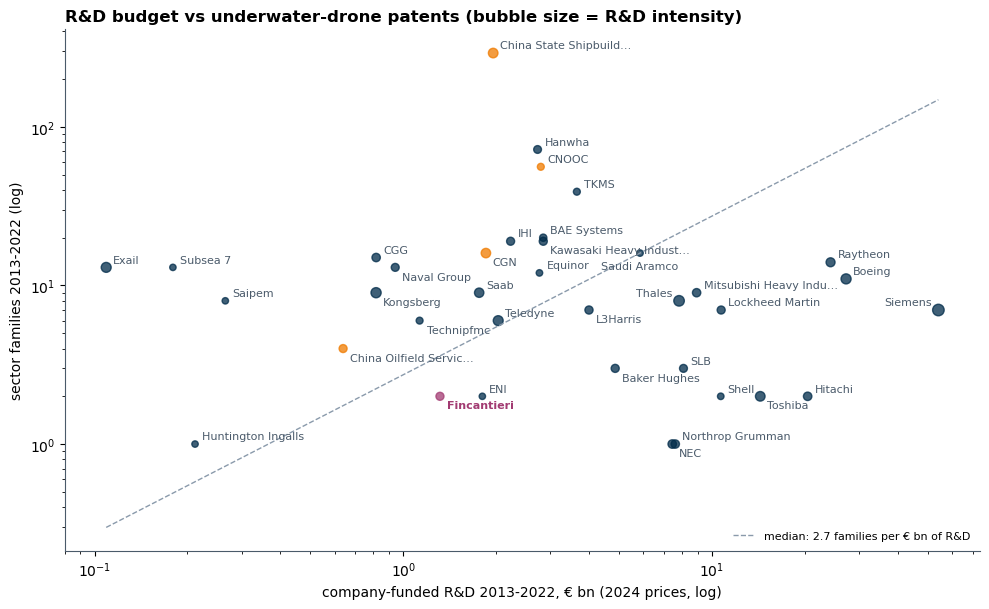

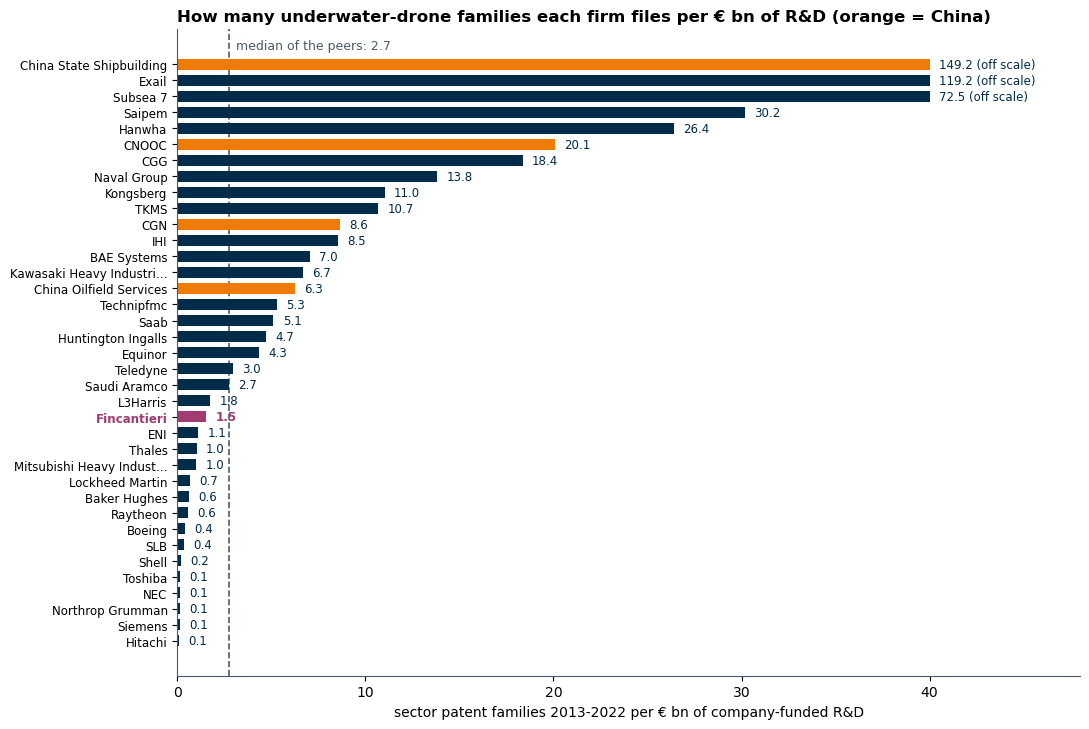

46 groups with financial data (Scoreboard, plus annual reports for Kongsberg 2023-24, TechnipFMC 2023-24, LIG Nex1, Oceaneering); median 2.7 sector families per € bn of R&D (2013-2022).
FINCANTIERI: R&D intensity 2.3%, 1.5 families per € bn of R&D


,country,latest year,data,net sales (€ bn),R&D (€ m),R&D intensity,employees,families 2013-2022,"families, all years","R&D 2013-2022 (€ bn, 2024 prices)",families per € bn R&D
patent_group,,,,,,,,,,,
CHINA STATE SHIPBUILDING (CSSC),CN,2024,Scoreboard,10.4,476,4.6%,"14,986",292,697,1.96,149.2
CNOOC,CN,2024,Scoreboard,55.5,453,0.8%,"22,181",56,102,2.79,20.1
HANWHA,KR,2024,Scoreboard,36.3,686,1.9%,–,72,101,2.73,26.4
TKMS (ATLAS ELEKTRONIK),DE,2024,Scoreboard,35.0,294,0.8%,"98,120",39,96,3.65,10.7
OCEANEERING,US,2024,annual report,2.6,–,–,"10,400",30,45,–,–
BAE SYSTEMS,GB,2024,Scoreboard,31.7,405,1.3%,"100,000",20,41,2.84,7.0
CHINA THREE GORGES,CN,2024,Scoreboard,3.9,6,0.1%,"6,584",7,37,0.00,–
LIG NEX1,KR,2024,annual report,2.1,–,–,"4,951",22,31,0.13,–
IHI,JP,2024,Scoreboard,10.0,223,2.2%,"27,990",19,30,2.23,8.5


In [52]:
if (EXT / "firm_financials.csv").exists():
    ff = pd.read_csv(EXT / "firm_financials.csv")
    WIN = (PAST[0], RECENT[1])
    fam_win = (appl[appl.family_year.between(*WIN)].groupby("applicant")["docdb_family_id"].nunique())
    fam_all = appl.groupby("applicant")["docdb_family_id"].nunique()
    ok = ff[ff.netsales_eur > 0]                     # latest year with sales; R&D may be missing (annual-report rows)
    latest = ok.sort_values("year").groupby("patent_group").tail(1).set_index("patent_group")
    cum_rnd = ff[ff.year.between(*WIN)].groupby("patent_group")["rnd_24_def"].sum(min_count=1) / 1000   # € bn, 2024 prices
    years_rnd = ff[ff.year.between(*WIN) & ff.rnd_24_def.notna()].groupby("patent_group")["year"].nunique()
    fin = pd.DataFrame({
        "country": latest["country"], "latest year": latest["year"],
        "data": latest["data_origin"].map({"EU R&D Scoreboard panel": "Scoreboard"}).fillna("annual report"),
        "net sales (€ bn)": latest["netsales_eur"] / 1000, "R&D (€ m)": latest["rnd_eur"],
        "R&D intensity": latest["rnd_org"] / latest["netsales_org"], "employees": latest["emp"],
        f"families {WIN[0]}-{WIN[1]}": fam_win.reindex(latest.index).fillna(0).astype(int),
        "families, all years": fam_all.reindex(latest.index).fillna(0).astype(int),
        f"R&D {WIN[0]}-{WIN[1]} (€ bn, 2024 prices)": cum_rnd.reindex(latest.index),
        "years of R&D data": years_rnd.reindex(latest.index).fillna(0).astype(int)})
    RND_COL = f"R&D {WIN[0]}-{WIN[1]} (€ bn, 2024 prices)"
    # families per € bn only where the R&D series covers most of the window (else the ratio is inflated)
    full = (fin["years of R&D data"] >= 7) & (fin[RND_COL] >= 0.1)   # also drop R&D totals under € 0.1 bn (e.g. Fugro reports almost none)
    fin["families per € bn R&D"] = np.where(full, fin[f"families {WIN[0]}-{WIN[1]}"] / fin[RND_COL], np.nan)
    fin = fin.sort_values("families, all years", ascending=False)
    save_table(fin, "competitors_rnd_scoreboard")
    if CLIENT in fin.index:
        KEY["client_rnd_intensity"] = float(fin.loc[CLIENT, "R&D intensity"])
        KEY["client_families_per_bn_rnd"] = float(fin.loc[CLIENT, "families per € bn R&D"])
    med = fin["families per € bn R&D"].median()
    KEY["median_families_per_bn_rnd"] = float(med)

    fig, ax = plt.subplots(figsize=(10, 6.2))
    pl = fin[(fin[f"families {WIN[0]}-{WIN[1]}"] > 0) & fin["families per € bn R&D"].notna()]   # same rows as the median
    colors = [RED if i == CLIENT else (ORANGE if c == "CN" else NAVY) for i, c in zip(pl.index, pl.country)]
    ax.scatter(pl[RND_COL], pl[f"families {WIN[0]}-{WIN[1]}"], s=20 + 600 * pl["R&D intensity"].clip(upper=0.15), c=colors, alpha=0.75)
    xs = np.logspace(np.log10(pl[RND_COL].min()), np.log10(pl[RND_COL].max()), 50)
    ax.plot(xs, med * xs, color=MID, ls="--", lw=1, label=f"median: {med:.1f} families per € bn of R&D")
    ax.set(xscale="log", yscale="log", xlabel=f"company-funded R&D {WIN[0]}-{WIN[1]}, € bn (2024 prices, log)",
           ylabel=f"sector families {WIN[0]}-{WIN[1]} (log)",
           title="R&D budget vs underwater-drone patents (bubble size = R&D intensity)")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    plt.tight_layout()
    pl_l = pl.assign(_c=pl.index == CLIENT).sort_values(["_c", f"families {WIN[0]}-{WIN[1]}"], ascending=False)
    label_points(ax, pl_l[RND_COL], pl_l[f"families {WIN[0]}-{WIN[1]}"], [nice_name(i.split(" (")[0], 22) for i in pl_l.index],
                 fontsize=8, colors=[RED if i == CLIENT else GREY for i in pl_l.index],
                 fontweights=["bold" if i == CLIENT else None for i in pl_l.index])
    save(fig, "s2_competitors_rnd"); plt.show()

    # Simple ranking for the deck: how many sector families each firm gets per € bn of R&D
    rk = pl.sort_values("families per € bn R&D", ascending=False)
    CAP = 40
    fig, ax = plt.subplots(figsize=(11, 7.4))
    ypos = np.arange(len(rk))[::-1]
    cols = [RED if i == CLIENT else (ORANGE if c == "CN" else NAVY) for i, c in zip(rk.index, rk.country)]
    ax.barh(ypos, rk["families per € bn R&D"].clip(upper=CAP), color=cols, height=0.7, zorder=2)
    for y_, (i, r) in zip(ypos, rk.iterrows()):
        v = r["families per € bn R&D"]
        ax.text(min(v, CAP) + 0.5, y_, f"{v:.1f}" + (" (off scale)" if v > CAP else ""), va="center", fontsize=8.5,
                color=RED if i == CLIENT else NAVY, fontweight="bold" if i == CLIENT else None)
    ax.set_yticks(ypos, [nice_name(i.split(" (")[0], 24) for i in rk.index], fontsize=8.5)
    for t, i in zip(ax.get_yticklabels(), rk.index):
        if i == CLIENT: t.set_color(RED); t.set_fontweight("bold")
    ax.axvline(med, color=GREY, ls="--", lw=1.2, zorder=1)
    ax.text(med + 0.4, len(rk) - 0.2, f"median of the peers: {med:.1f}", fontsize=9, color=GREY, va="bottom")
    ax.set_xlim(0, CAP + 8); ax.set_xlabel(f"sector patent families {WIN[0]}-{WIN[1]} per € bn of company-funded R&D")
    ax.set_title("How many underwater-drone families each firm files per € bn of R&D (orange = China)", loc="left", fontweight="bold")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    plt.tight_layout(); save(fig, "s2_competitors_rnd_ranking"); plt.show()
    KEY["client_rank_families_per_bn"] = int((rk["families per € bn R&D"] > rk.loc[CLIENT, "families per € bn R&D"]).sum() + 1) if CLIENT in rk.index else None
    KEY["n_firms_ranked_rnd"] = int(len(rk))
    print(f"{len(fin)} groups with financial data (Scoreboard, plus annual reports for Kongsberg 2023-24, TechnipFMC 2023-24, LIG Nex1, Oceaneering); median {med:.1f} sector families per € bn of R&D ({WIN[0]}-{WIN[1]}).")
    if CLIENT in fin.index:
        print(f"{CLIENT}: R&D intensity {KEY['client_rnd_intensity']:.1%}, {KEY['client_families_per_bn_rnd']:.1f} families per € bn of R&D")
    display(fin.drop(columns=["years of R&D data"]).style.format(
        {"net sales (€ bn)": "{:,.1f}", "R&D (€ m)": "{:,.0f}", "R&D intensity": "{:.1%}", "employees": "{:,.0f}",
         RND_COL: "{:,.2f}", "families per € bn R&D": "{:.1f}"}, na_rep="–"))
else:
    print(f"{EXT / 'firm_financials.csv'} not found: section skipped")

**Reading.** Three profiles, to confirm on the table after each re-run:

- **specialists** (far above the median line: CSSC, Exail, Hanwha, Naval Group, Kongsberg, TKMS, CGG and the
  offshore service firms Subsea 7, Saipem, CNOOC): underwater work is a large share of what their R&D produces; they are the direct competitors and,
  when small, the acquisition targets of Step 6;
- **diversified primes** (far below the line: Boeing, Lockheed Martin, RTX, Siemens, the oil majors): huge R&D
  budgets, a handful of families; underwater drones are a side line, or their defence work is classified and paid
  by governments (not in company-funded R&D);
- **the client**: Fincantieri spends little on R&D for its size (R&D intensity printed above) and files few families,
  so its underwater capabilities come from **acquisitions** (WASS 2025; NextGeo, WSense, Graal Tech, Defcomm 2026)
  rather than from internal R&D: a *buy* rather than *make* strategy that Step 3 and Step 6 should take as given.

## 2.3 Entry and exit, year by year

As in Tutorial 1 nb 11 §5.2: for each priority year, the active applicants, those **new to the sector** (first
family in the sector that year), the **entrants' share of families** (families with at least one applicant new to
the sector) and the **rate of disappearance** (share of the year's active applicants that never file again in the
sector; shown only up to `LAST − 3`, because an applicant silent in the last years may simply not be published yet).
In the first years almost everyone looks new (families before 2000 are not seen): read entry from about 2005.

,value
incumbents among the 30 largest applicants (all types),24
entrants among the 30 largest applicants (all types),6
incumbents among the 30 largest firms,18
entrants among the 30 largest firms,12
largest incumbent firms,"China State Shipbuilding (Cssc), Cnooc, Hanwha, Tkms (At..."
largest entrant firms (first family from 2015),"State Grid (Sgcc), Crrc, China Huaneng Group, China Yang..."
"entrants' share of families, last 5 complete years",33.2%


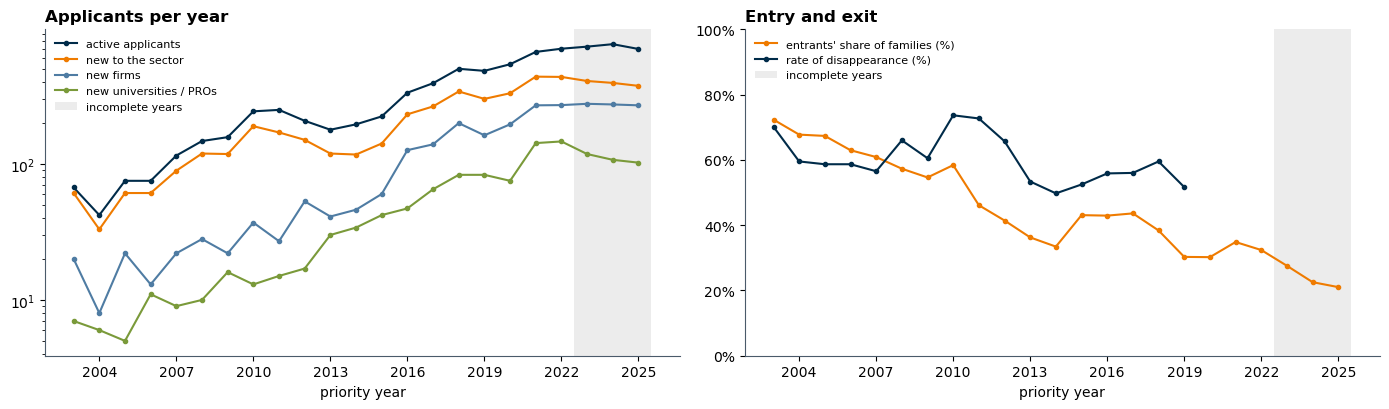

,active_applicants,new_to_sector,leaving,new_to_patenting,new firms,new universities / PROs,rate of disappearance (%),entrants' share of families (%)
year,,,,,,,,
2003,67,61,47,0,20,7,70.1,72.3
2004,42,33,25,0,8,6,59.5,67.7
2005,75,61,44,0,22,5,58.7,67.3
2006,75,61,44,0,13,11,58.7,63.0
2007,115,89,65,0,22,9,56.5,60.9
2008,147,119,97,0,28,10,66.0,57.3
2009,157,118,95,0,22,16,60.5,54.6
2010,243,189,179,0,37,13,73.7,58.4
2011,249,170,181,0,27,15,72.7,46.1


In [53]:
first_year = links.groupby("applicant")["family_year"].min(); last_year = links.groupby("applicant")["family_year"].max()
active = links[["applicant", "family_year", "type"]].rename(columns={"family_year": "year"}).drop_duplicates(["applicant", "year"])
active["new"] = active["year"] == active["applicant"].map(first_year)
active["leaving"] = active["year"] == active["applicant"].map(last_year)
ee = active.groupby("year").agg(active_applicants=("applicant", "size"), new_to_sector=("new", "sum"), leaving=("leaving", "sum"))
if "first patent ever" in players.columns:   # TIP only: new to patenting altogether, not only to the sector
    active["new_to_patenting"] = active["year"] == active["applicant"].map(players["first patent ever"].to_dict())
    ee["new_to_patenting"] = active.groupby("year")["new_to_patenting"].sum()
ee["new firms"] = active[active.type.isin(["firm", "unknown"])].groupby("year")["new"].sum()
ee["new universities / PROs"] = active[active.type.isin(["university", "government / non-profit"])].groupby("year")["new"].sum()
ee["rate of disappearance (%)"] = ee["leaving"] / ee["active_applicants"] * 100
ee.loc[ee.index > LAST - 3, "rate of disappearance (%)"] = np.nan
ln = links.assign(new=links["family_year"] == links["applicant"].map(first_year))
ee["entrants' share of families (%)"] = ln.groupby(["family_year", "docdb_family_id"])["new"].any().groupby("family_year").mean() * 100
ee = ee.loc[2003:YEAR_MAX]
KEY["entrants_share_last5"] = float(ee.loc[LAST - 4:LAST, "entrants' share of families (%)"].mean() / 100)
save_table(ee, "entry_exit")

# incumbents vs entrants among the largest players (Tutorial 1 nb 11 §5.2, LANDSCAPE.py)
top30_all, top30_firms = players.head(30), players[players.type.isin(["firm", "unknown"])].head(30)
inc_ent = pd.DataFrame({"value": {
    "incumbents among the 30 largest applicants (all types)": int(top30_all.status.eq("incumbent").sum()),
    "entrants among the 30 largest applicants (all types)": int(top30_all.status.eq("entrant").sum()),
    "incumbents among the 30 largest firms": int(top30_firms.status.eq("incumbent").sum()),
    "entrants among the 30 largest firms": int(top30_firms.status.eq("entrant").sum()),
    "largest incumbent firms": ", ".join(top30_firms[top30_firms.status.eq("incumbent")].index[:4].str.title()) or "none",
    f"largest entrant firms (first family from {SPLIT_YEAR})": ", ".join(top30_firms[top30_firms.status.eq("entrant")].index[:4].str.title()) or "none",
    "entrants' share of families, last 5 complete years": f"{KEY['entrants_share_last5']:.1%}"}})
save_table(inc_ent, "incumbents_and_entrants")
display(inc_ent)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
(ee[["active_applicants", "new_to_sector", "new firms", "new universities / PROs"]]
 .rename(columns={"active_applicants": "active applicants", "new_to_sector": "new to the sector"})
 .plot(ax=axes[0], marker="o", ms=3, color=[NAVY, ORANGE, BLUE, GREEN]))
axes[0].set(title="Applicants per year", xlabel="priority year"); axes[0].set_yscale("log")
ee[["entrants' share of families (%)", "rate of disappearance (%)"]].plot(ax=axes[1], marker="o", ms=3, color=[ORANGE, NAVY])
axes[1].set(title="Entry and exit", xlabel="priority year", ylim=(0, 100)); axes[1].yaxis.set_major_formatter(PercentFormatter(100))
for ax in axes: shade(ax); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); save(fig, "s2_entry_exit"); plt.show()
ee.round(1)

**Persistence.** Most applicants appear once and disappear. The share of applicants active in at least 3 distinct
years, by type, separates the *persistent* innovators (Patel & Pavitt, 1997: competences are path-dependent) from
occasional filers.

In [54]:
persist = links.groupby(["applicant"]).agg(type=("type", "first"), years_active=("family_year", "nunique"), families=("docdb_family_id", "nunique"))
pers = persist.groupby("type").agg(applicants=("years_active", "size"), share_active_3plus_years=("years_active", lambda s: (s >= 3).mean()),
                                   share_one_family=("families", lambda s: (s == 1).mean()))
save_table(pers, "persistence_by_type")
pers.style.format({"applicants": "{:,.0f}", "share_active_3plus_years": "{:.1%}", "share_one_family": "{:.1%}"})

,applicants,share_active_3plus_years,share_one_family
type,,,
firm,"2,216",8.7%,66.8%
government / non-profit,420,16.2%,59.8%
hospital,2,0.0%,50.0%
individual,"1,236",1.1%,86.7%
university,774,27.5%,50.3%
unknown,418,1.4%,87.8%


## 2.4 Subfields: which parts of the sector grow fastest?

Two independent definitions of a subfield, as the kick-off suggests (*"growth of CPC groups, or topics from
abstracts"*). If both point to the same growth areas, the result is robust to the definition.

### 2.4.1 CPC main groups: growth map and maturity matrix

A subfield = a CPC main group (e.g. `G05D1/`, `G06N3/`), allocation codes only (the Y and 2000-series indexing
codes are kept apart, except `B63G2008/` which names the unmanned vessels themselves). Families counted once per
subfield. Growth = families in 2018–2022 vs 2013–2017. Only subfields with at least 30 recent families are mapped,
so tiny groups with huge percentages do not win (Tutorial 1 nb 11 §5.3).

,title (verify),families 2013-2017,families 2018-2022,growth (%),maturity quadrant
main_group,,,,,
G06F17/,Digital computing / data processing (check),2,60,+2900%,emerging
G06F18/,Pattern recognition,4,73,+1725%,emerging
G06N3/,Neural networks / biological computing models,9,164,+1722%,current hot topic
B60L53/,,6,72,+1100%,emerging
G01N21/,,7,60,+757%,emerging


,title (verify),families 2018-2022
main_group,,
G01R33/,,17
G06T3/,,17
H02N2/,,16
F16M11/,,15
B60L58/,,13
G01V8/,,12
H02N11/,,11
E02F7/,,10


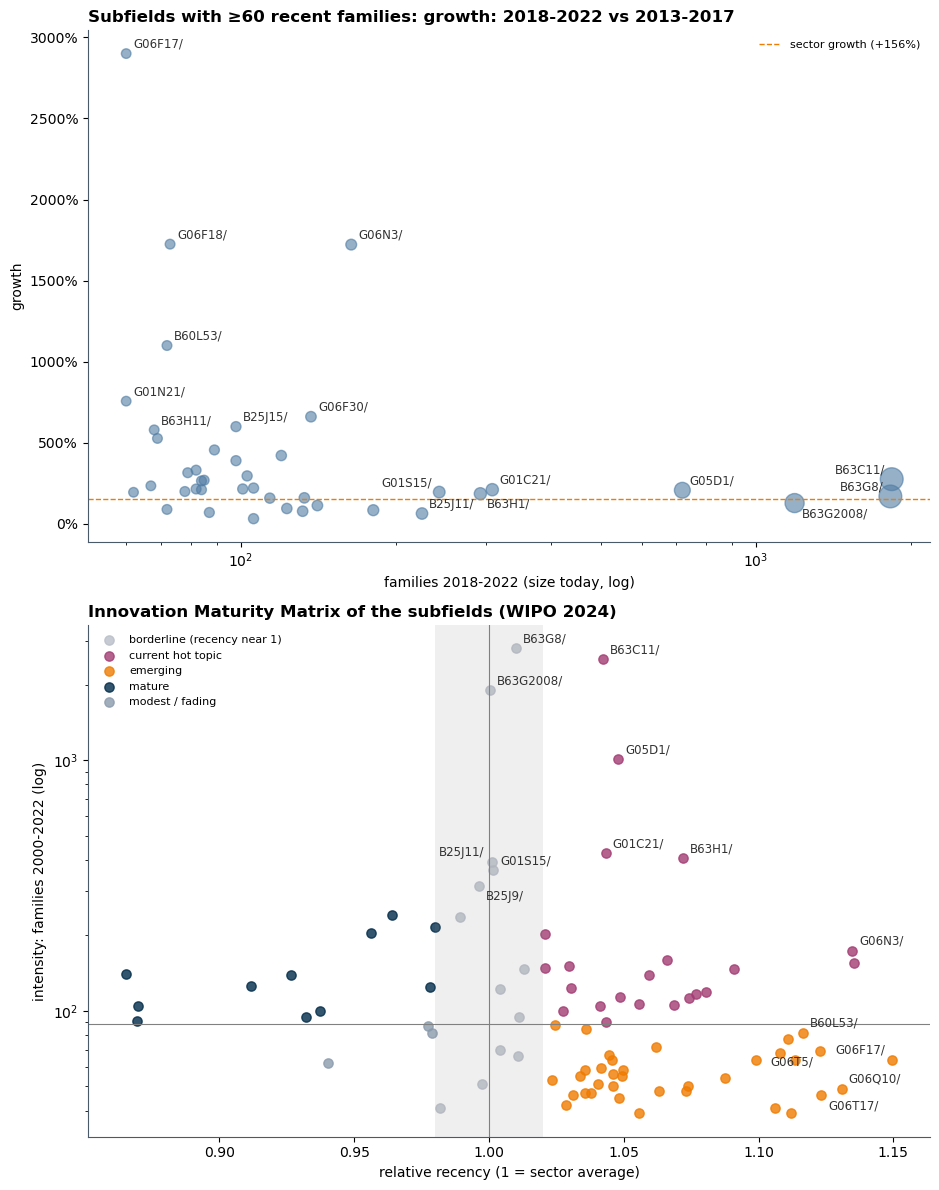

,families 2013-2017,families 2018-2022,growth (%),growth vs sector (pp),intensity (families ≤ 2022),relative recency,title (verify),maturity quadrant
main_group,,,,,,,,
B63C11/,488,"1,835",+276%,+120,"2,527",1.04,Equipment for working under water; searching for underwater objects,current hot topic
B63G8/,677,"1,824",+169%,+13,"2,792",1.01,"Underwater vessels, e.g. submarines",borderline (recency near 1)
B63G2008/,520,"1,189",+129%,-28,"1,909",1.00,Unmanned underwater vessels (indexing),borderline (recency near 1)
G05D1/,234,720,+208%,+51,"1,011",1.05,"Control of position, course, altitude or attitude of vehicles",current hot topic
G01C21/,99,308,+211%,+55,426,1.04,Navigation,current hot topic
B63H1/,102,292,+186%,+30,407,1.07,Propulsive elements (marine),current hot topic
G01S15/,82,243,+196%,+40,365,1.00,Sonar systems,borderline (recency near 1)
B25J11/,137,225,+64%,-92,392,1.00,Manipulators not otherwise provided for,borderline (recency near 1)
B25J9/,98,181,+85%,-72,315,1.00,Programme-controlled manipulators,borderline (recency near 1)


In [55]:
MAIN_GROUP_TITLES = {   # short titles: VERIFY on the CPC scheme
    "B63G8/": "Underwater vessels, e.g. submarines", "B63C11/": "Equipment for working under water; searching for underwater objects",
    "B63G2008/": "Unmanned underwater vessels (indexing)", "G05D1/": "Control of position, course, altitude or attitude of vehicles",
    "G01C21/": "Navigation", "G06N3/": "Neural networks / biological computing models", "G01S15/": "Sonar systems",
    "B25J9/": "Programme-controlled manipulators", "G06V10/": "Image or video recognition (general)", "B63H1/": "Propulsive elements (marine)",
    "G06F30/": "Computer-aided design / simulation", "G06T7/": "Image analysis", "B25J11/": "Manipulators not otherwise provided for",
    "B63B27/": "Ship-based loading / launching equipment (check)", "G06F18/": "Pattern recognition", "H02J7/": "Battery charging / supply",
    "B25J19/": "Manipulator accessories (sensors, safety)", "G01V1/": "Seismology / seismic prospecting", "B63B35/": "Vessels for special purposes",
    "H04N23/": "Cameras", "B63H21/": "Marine propulsion power plants", "H04B13/": "Transmission via water (acoustic/optical)",
    "H04B11/": "Underwater acoustic communication (check)", "G01S7/": "Details of sonar/radar systems", "G01S5/": "Position-fixing",
    "G05B13/": "Adaptive control systems", "G05B17/": "Systems involving models / simulation", "B08B1/": "Cleaning with tools",
    "B63B79/": "Monitoring properties or operating parameters of vessels", "G01N33/": "Investigating materials (water analysis…)",
    "B63B22/": "Buoys", "H01M50/": "Battery constructional details (check)", "H01M10/": "Secondary batteries", "F42B19/": "Marine torpedoes", "H01M6/": "Primary batteries", "G06F17/": "Digital computing / data processing (check)", "B63G9/": "Other offensive or defensive arrangements on vessels", "B63B21/": "Tying-up; towing; anchoring",
    "B63C7/": "Salvaging of disabled, stranded or sunken vessels", "B63H25/": "Steering; slowing-down", "B63B1/": "Hull shape",
}
# 2000-series indexing codes (e.g. G06F2119/) describe aspects, not technologies: out, except B63G2008/ (the UUVs themselves)
is_2000_indexing = fcpc["main_group"].astype(str).str.match(r"^[A-H]\d{2}[A-Z]2\d{3}/") & ~fcpc["main_group"].eq("B63G2008/")
mg = fcpc[((~fcpc.is_tagging.astype(str).str.lower().eq("true")) | fcpc.main_group.eq("B63G2008/")) & ~is_2000_indexing]
mg = mg[~mg.main_group.str.startswith("Y")].drop_duplicates(["docdb_family_id", "main_group"]).merge(fam[["docdb_family_id", "family_year"]], on="docdb_family_id")
past = mg[mg.family_year.between(*PAST)].groupby("main_group")["docdb_family_id"].nunique()
recent = mg[mg.family_year.between(*RECENT)].groupby("main_group")["docdb_family_id"].nunique()
sf = pd.DataFrame({f"families {PAST[0]}-{PAST[1]}": past, f"families {RECENT[0]}-{RECENT[1]}": recent}).fillna(0)
sf["growth (%)"] = (sf.iloc[:, 1] / sf.iloc[:, 0].replace(0, np.nan) - 1) * 100
sector_growth = (tot_rec / tot_past - 1) * 100
sf["growth vs sector (pp)"] = sf["growth (%)"] - sector_growth

# relative recency (WIPO maturity matrix), complete years 2000-LAST
def recency(yearly, start=YEAR_MIN, end=LAST):
    w = yearly.reindex(range(start, end + 1), fill_value=0).values.astype(float)
    i = np.arange(1, len(w) + 1); n = len(w)
    return (w * i).sum() / (n * w.sum()) if w.sum() else np.nan

R_sector = recency(fam.groupby("family_year").size())
mg_c = mg[mg.family_year <= LAST]
sf["intensity (families ≤ 2022)"] = mg_c.groupby("main_group")["docdb_family_id"].nunique()
sf["relative recency"] = mg_c.groupby("main_group").apply(lambda d: recency(d.groupby("family_year")["docdb_family_id"].nunique())) / R_sector
sf["title (verify)"] = [MAIN_GROUP_TITLES.get(i, "") for i in sf.index]
mapped = sf[sf.iloc[:, 1] >= 30].sort_values(sf.columns[1], ascending=False)

med_int = mapped["intensity (families ≤ 2022)"].median()
BORDER = 0.02          # |relative recency − 1| below this is too close to call (most subfields lie between 0.96 and 1.14)
BORDER_LABEL = "borderline (recency near 1)"
def quadrant(r):
    if abs(r["relative recency"] - 1) < BORDER:
        return BORDER_LABEL
    hi, rec_ = r["intensity (families ≤ 2022)"] >= med_int, r["relative recency"] >= 1
    return "current hot topic" if hi and rec_ else "emerging" if rec_ else "mature" if hi else "modest / fading"
mapped["maturity quadrant"] = mapped.apply(quadrant, axis=1)
mapped.to_csv(OUT / "subfields_cpc.csv")

# fastest growers among the subfields at least as large as the median today (Tutorial 1 nb 11 §5.3), and the NEW
# subfields (no family in the past window: growth undefined, so they are missing from the map, but they are the newest)
vg = mapped[mapped.iloc[:, 0] > 0]
fastest = vg[vg.iloc[:, 1] >= vg.iloc[:, 1].median()].sort_values("growth (%)", ascending=False).head(5)
tab_fastest = fastest[["title (verify)", fastest.columns[0], fastest.columns[1], "growth (%)", "maturity quadrant"]]
new_sf = sf[(sf.iloc[:, 0] == 0) & (sf.iloc[:, 1] >= 10)].sort_values(sf.columns[1], ascending=False)[["title (verify)", sf.columns[1]]]
save_table(tab_fastest, "fastest_growing_subfields"); save_table(new_sf, "new_subfields")
display(tab_fastest.style.format({tab_fastest.columns[1]: "{:,.0f}", tab_fastest.columns[2]: "{:,.0f}", "growth (%)": "{:+.0f}%"})
        .set_caption("Fastest-growing CPC subfields (at least median size today)"))
display(new_sf.head(10).style.format({new_sf.columns[1]: "{:,.0f}"}).set_caption(f"New subfields: no family in {PAST[0]}-{PAST[1]}, at least 10 in {RECENT[0]}-{RECENT[1]}"))

fig, axes = plt.subplots(2, 1, figsize=(9.5, 12))          # stacked for the deck
ax = axes[0]
gm = mapped[mapped.iloc[:, 1] >= 60]          # the map shows the subfields with at least 60 recent families
ax.scatter(gm.iloc[:, 1], gm["growth (%)"], s=40 + gm.iloc[:, 1] / 8, color=BLUE, alpha=0.6)
# label only the 8 largest and the 8 fastest-growing subfields: the others stay as points (names in the table)
gm_lab = pd.concat([gm.iloc[:, 1].nlargest(8), gm["growth (%)"].nlargest(8)]).index.unique()   # labelled first
ax.axhline(sector_growth, color=ORANGE, ls="--", lw=1, label=f"sector growth ({sector_growth:+.0f}%)")
ax.legend(frameon=False, fontsize=8, loc="upper right")
if len(gm):
    ax.set_xscale("log")
else:                                         # tiny samples (TEST): no subfield reaches 60 recent families
    ax.text(0.5, 0.5, "no subfield with ≥60 recent families", transform=ax.transAxes, ha="center", color=MID)
ax.set(title=f"Subfields with ≥60 recent families: growth: {RECENT[0]}-{RECENT[1]} vs {PAST[0]}-{PAST[1]}", xlabel="families 2018-2022 (size today, log)", ylabel="growth")
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax = axes[1]
qc = {"current hot topic": RED, "emerging": ORANGE, "mature": NAVY, "modest / fading": MID, BORDER_LABEL: "#B8BDC7"}
for qn, d in mapped.groupby("maturity quadrant"):
    ax.scatter(d["relative recency"], d["intensity (families ≤ 2022)"], color=qc[qn], label=qn, s=45, alpha=0.8)
lab = pd.concat([mapped.head(10), mapped[mapped["maturity quadrant"].eq("emerging")].sort_values("relative recency", ascending=False).head(5)])
lab = lab[~lab.index.duplicated()]
ax.axvline(1, color="grey", lw=0.8); ax.axvspan(1 - BORDER, 1 + BORDER, color="grey", alpha=0.12, lw=0)
ax.axhline(med_int, color="grey", lw=0.8)
if (mapped["intensity (families ≤ 2022)"] > 0).any():
    ax.set_yscale("log")                            # linear only if no subfield has families (tiny TEST samples)
ax.set(title="Innovation Maturity Matrix of the subfields (WIPO 2024)", xlabel="relative recency (1 = sector average)", ylabel="intensity: families 2000-2022 (log)")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
# labels without overlaps (the largest / fastest first); points that cannot be labelled are in the table below
if len(gm):
    label_points(axes[0], gm.loc[gm_lab].iloc[:, 1], gm.loc[gm_lab, "growth (%)"], list(gm_lab), fontsize=8.5)
label_points(axes[1], lab["relative recency"], lab["intensity (families ≤ 2022)"], list(lab.index), fontsize=8.5)
save(fig, "s2_subfield_growth_maturity"); plt.show()
mapped.head(25).style.format({mapped.columns[0]: "{:,.0f}", mapped.columns[1]: "{:,.0f}", "growth (%)": "{:+.0f}%", "growth vs sector (pp)": "{:+.0f}",
                              "intensity (families ≤ 2022)": "{:,.0f}", "relative recency": "{:.2f}"}, na_rep="–")

**Technology themes, then and now (deck).** The CPC subfields above are too many to read on a slide: here they are grouped into
ten plain-language themes (a family counts once per theme, even when it carries several codes of it). Same chart as for the
application areas: grey = 2013-2017, colour = 2018-2022, label = growth; blue = grows faster than the whole sector.

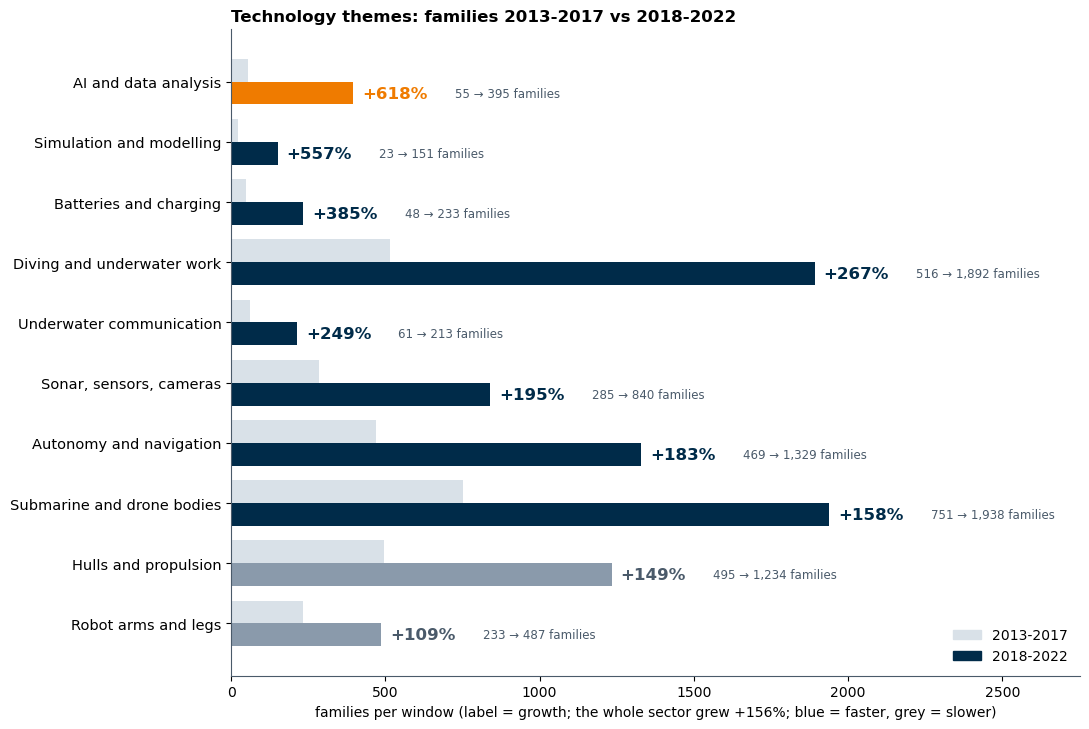

,families 2013-2017,families 2018-2022,growth (%)
theme,,,
AI and data analysis,55.0,395.0,618.0
Simulation and modelling,23.0,151.0,557.0
Batteries and charging,48.0,233.0,385.0
Diving and underwater work,516.0,1892.0,267.0
Underwater communication,61.0,213.0,249.0
"Sonar, sensors, cameras",285.0,840.0,195.0
Autonomy and navigation,469.0,1329.0,183.0
Submarine and drone bodies,751.0,1938.0,158.0
Hulls and propulsion,495.0,1234.0,149.0


In [56]:
THEMES = [("AI and data analysis", ("G06N", "G06F17", "G06F18", "G06V", "G06T")), ("Simulation and modelling", ("G06F30", "G05B17")),
          ("Autonomy and navigation", ("G05D", "G01C", "G05B", "G01S19", "G01S5")), ("Batteries and charging", ("B60L", "H02J", "H01M")),
          ("Sonar, sensors, cameras", ("G01S", "G01N", "G01D", "G01V", "H04N")), ("Underwater communication", ("H04B", "H04W", "H04L")),
          ("Robot arms and legs", ("B25J", "B62D")), ("Hulls and propulsion", ("B63B", "B63H")),
          ("Submarine and drone bodies", ("B63G",)), ("Diving and underwater work", ("B63C",))]
def _theme(g):
    return next((n_ for n_, pre_ in THEMES if str(g).startswith(pre_)), None)
th = mg[["docdb_family_id", "main_group", "family_year"]].assign(theme=lambda d: d.main_group.map(_theme)).dropna(subset=["theme"])
th = th.drop_duplicates(["docdb_family_id", "theme"])
th_rows = [(n_, float(((th.theme == n_) & th.family_year.between(*PAST)).sum()), float(((th.theme == n_) & th.family_year.between(*RECENT)).sum()))
           for n_, _ in THEMES]
then_now_chart(th_rows, f"Technology themes: families {PAST[0]}-{PAST[1]} vs {RECENT[0]}-{RECENT[1]}", "s2_tech_themes", sector_growth / 100, figsize=(11, 7.4))
tt = pd.DataFrame(th_rows, columns=["theme", f"families {PAST[0]}-{PAST[1]}", f"families {RECENT[0]}-{RECENT[1]}"]).set_index("theme")
tt["growth (%)"] = (tt.iloc[:, 1] / tt.iloc[:, 0].replace(0, np.nan) - 1) * 100
save_table(tt.sort_values("growth (%)", ascending=False), "tech_themes_growth")
KEY["tech_theme_fastest"] = tt["growth (%)"].idxmax() if tt["growth (%)"].notna().any() else None
tt.sort_values("growth (%)", ascending=False).round(0)

### 2.4.2 Topics from the abstracts

The CPC is the examiners' view and lags behind new technologies. Topics from the text are the applicants' view.
Offline version: **TF-IDF + NMF** (non-negative matrix factorisation) on the cleaned English abstracts of
`02_clean` (`clean_abstract`): transparent (each topic is a list of weighted words), fast on CPU, and in the family
of TF-IDF encodings of Tutorial 2 nb 21 §3. The TIP version with **Patent SBERT + BERTopic** (Tutorial 2 nb 21
§9.3) is in the optional cell further down: run it and compare the two sets of topics in the appendix.
Topics are named by hand from their words: **read 5 abstracts per topic before naming it.**

In [57]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

N_TOPICS = 14
SECTOR_WORDS = {"underwater", "vehicle", "vehicles", "robot", "unmanned", "body", "unit", "module", "provided", "connected",
                "end", "side", "plate", "fixedly", "fixed", "arranged", "mounted", "rod", "utility", "model", "shell", "connecting"}
PATENT_STOP = {"said", "wherein", "comprising", "comprises", "invention", "method", "device", "apparatus", "system", "according",
               "plurality", "includes", "including", "first", "second", "third", "present", "disclosed", "provides", "relates", "based"}
docs = fam.loc[fam.clean_abstract.notna() & (fam.clean_abstract.str.len() > 40)].copy()
tfidf = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | SECTOR_WORDS | PATENT_STOP), ngram_range=(1, 2), min_df=10, max_df=0.4, sublinear_tf=True)
X = tfidf.fit_transform(docs.clean_abstract)
nmf = NMF(n_components=N_TOPICS, random_state=42, init="nndsvda", max_iter=400)
Wd = nmf.fit_transform(X)
terms = np.array(tfidf.get_feature_names_out())
topic_words = {k: ", ".join(terms[nmf.components_[k].argsort()[::-1][:9]]) for k in range(N_TOPICS)}

def auto_topic_label(words_str):
    """DRAFT label from the top NMF terms, matched on WHOLE words (a substring test would match 'arm' in 'swarm').
    Verify on sample abstracts before using a name in the deck."""
    w_ = set(re.split(r"[,\s]+", words_str.lower())) - {""}
    rules = [({"docking", "recovery"}, None, "AUV docking & recovery"), (None, {"path", "planning"}, "Path planning & obstacle avoidance"),
             ({"image", "images", "target", "targets"}, None, "Underwater imaging & target detection"), ({"fish", "bionic"}, None, "Bionic robotic fish"),
             ({"charging", "battery", "batteries"}, {"power", "supply"}, "Power supply & battery charging"),
             ({"trajectory", "controller"}, None, "Motion & trajectory control"), ({"inertial", "navigation"}, None, "Inertial navigation & positioning"),
             ({"rov", "rovs", "umbilical", "remotely"}, None, "Tethered ROVs & umbilical systems"), ({"cleaning", "brush"}, None, "Hull & surface cleaning"),
             ({"arm", "arms", "manipulator", "manipulators", "grabbing"}, None, "Underwater manipulator arms"),
             ({"communication", "signal"}, None, "Underwater communication & monitoring"), ({"pressure", "valve", "pump"}, None, "Buoyancy, hydraulic & pressure systems"),
             ({"cabin", "propeller"}, None, "Hull, cabin & thruster layout"), ({"shaft", "driving", "mechanism"}, None, "Mechanical drive & actuation")]
    for any_of, all_of, label in rules:
        if (any_of and w_ & any_of) or (all_of and all_of <= w_):
            return label
    return "Unlabelled (" + ", ".join(t.strip() for t in words_str.split(",")[:2]) + ")"

topic_labels = {k: auto_topic_label(v) for k, v in topic_words.items()}
docs["topic"] = Wd.argmax(axis=1)
docs["topic_strength"] = Wd.max(axis=1)
docs.loc[docs.topic_strength < 1e-3, "topic"] = -1    # documents that load on no topic
print(f"{X.shape[0]:,} abstracts x {X.shape[1]:,} terms; {(docs.topic == -1).mean():.1%} without a topic")
topics = pd.DataFrame({"topic label (draft, verify)": topic_labels, "top words": topic_words, "families": docs[docs.topic >= 0].groupby("topic").size()})
topics

15,558 abstracts x 16,286 terms; 0.0% without a topic


,"topic label (draft, verify)",top words,families
0,AUV docking & recovery,"frame, guide, recovery, locking, butt, mechanism, suppor...",854
1,Underwater imaging & target detection,"image, target, detection, data, feature, sonar, processi...",1268
2,Bionic robotic fish,"fish, robotic, robotic fish, bionic, fin, tail, bionic r...",800
3,Power supply & battery charging,"power, supply, power supply, energy, charging, battery, ...",842
4,Motion & trajectory control,"control, tracking, controller, trajectory, state, error,...",1117
5,"Buoyancy, hydraulic & pressure systems","pressure, valve, oil, water, pump, air, tank, buoyancy, bag",1405
6,Path planning & obstacle avoidance,"path, planning, path planning, algorithm, obstacle, envi...",870
7,Inertial navigation & positioning,"navigation, positioning, position, information, measurem...",1164
8,Tethered ROVs & umbilical systems,"cable, rov, operated, remotely, remotely operated, subse...",1310
9,"Hull, cabin & thruster layout","cabin, main, propeller, adjusting, buoyancy, propellers,...",1407


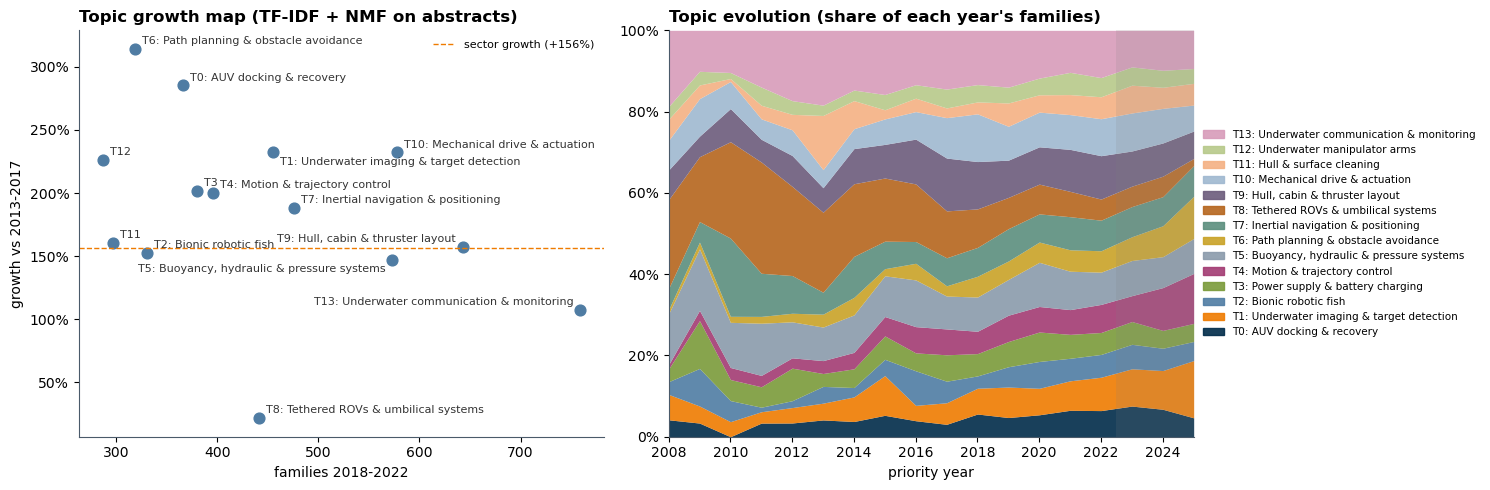

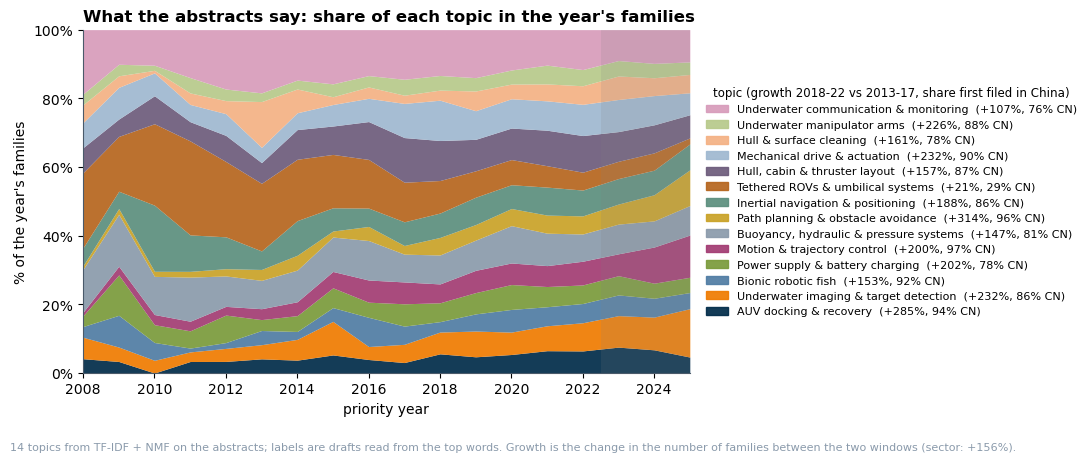

,topic label (draft),families past,families recent,growth (%),relative recency,international share,China share (first filing),top words
topic,,,,,,,,
6,Path planning & obstacle avoidance,77,319,+314%,1.07,3%,96%,"path, planning, path planning, algorithm, obstacle, environment, auv, avoidance, optimization"
0,AUV docking & recovery,95,366,+285%,1.04,2%,94%,"frame, guide, recovery, locking, butt, mechanism, supporting, butt joint, base"
10,Mechanical drive & actuation,174,578,+232%,1.03,5%,90%,"driving, shaft, motor, mechanism, rotating, gear, rotate, drive, transmission"
1,Underwater imaging & target detection,137,455,+232%,1.03,6%,86%,"image, target, detection, data, feature, sonar, processing, camera, obtain"
12,Underwater manipulator arms,88,287,+226%,1.03,7%,88%,"arm, mechanical, mechanical arm, operation, grabbing, joint, arms, manipulator, freedom"
3,Power supply & battery charging,126,380,+202%,1.02,9%,78%,"power, supply, power supply, energy, charging, battery, electric, circuit, voltage"
4,Motion & trajectory control,132,396,+200%,1.05,2%,97%,"control, tracking, controller, trajectory, state, error, trajectory tracking, motion, disturbance"
7,Inertial navigation & positioning,165,476,+188%,1.00,6%,86%,"navigation, positioning, position, information, measurement, inertial, inertial navigation, auv, precision"
11,Hull & surface cleaning,114,297,+161%,1.02,6%,78%,"cleaning, surface, cleaning cleaning, ship, water, cleaned, frame, brush, hull"


In [58]:
tp = docs[docs.topic >= 0]
tpast = tp[tp.family_year.between(*PAST)].groupby("topic").size(); trec = tp[tp.family_year.between(*RECENT)].groupby("topic").size()
tg = pd.DataFrame({"families past": tpast, "families recent": trec}).fillna(0)
tg["growth (%)"] = (tg["families recent"] / tg["families past"].replace(0, np.nan) - 1) * 100
tg["relative recency"] = tp[tp.family_year <= LAST].groupby("topic").apply(lambda d: recency(d.groupby("family_year").size())) / R_sector
tg["international share"] = tp.groupby("topic")["is_international"].mean()
tg["China share (first filing)"] = tp.groupby("topic")["first_office"].apply(lambda s: (s == "CN").mean())
tg["top words"] = tg.index.map(topic_words)
tg.insert(0, "topic label (draft)", tg.index.map(topic_labels))
topic_share = tp[tp.family_year.between(2008, YEAR_MAX)].pipe(lambda d: pd.crosstab(d.family_year, d.topic, normalize="index")) * 100
tg.to_csv(OUT / "subfields_topics.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.scatter(tg["families recent"], tg["growth (%)"], s=60, color=BLUE)
ax.axhline(sector_growth, color=ORANGE, ls="--", lw=1, label=f"sector growth ({sector_growth:+.0f}%)")
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.set(title="Topic growth map (TF-IDF + NMF on abstracts)", xlabel="families 2018-2022", ylabel="growth vs 2013-2017"); ax.yaxis.set_major_formatter(PercentFormatter(100))
ax = axes[1]
topic_share.plot.area(ax=ax, color=TOPIC_PALETTE[:topic_share.shape[1]], alpha=0.9, lw=0, legend=False)
shade(ax); ax.set(title="Topic evolution (share of each year's families)", xlabel="priority year", ylim=(0, 100), xlim=(2008, YEAR_MAX))
ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.margins(x=0)
from matplotlib.patches import Patch
h_ = [Patch(color=c, alpha=0.9) for c in TOPIC_PALETTE[:topic_share.shape[1]]]     # same colours as the bands
ax.legend(h_[::-1], [f"T{k}: {topic_labels[k]}" for k in topic_share.columns][::-1], ncol=1, fontsize=7.5, frameon=False,
          loc="center left", bbox_to_anchor=(1, 0.5))             # same order as the stack (top band first)
plt.tight_layout()
tg_l = tg.sort_values("families recent", ascending=False)
label_points(axes[0], tg_l["families recent"], tg_l["growth (%)"], [f"T{k}: {topic_labels[k]}" for k in tg_l.index], fontsize=8)
save(fig, "s2_topics"); plt.show()

# One clear panel for the deck: how the topics read from the abstracts evolve. The legend gives each topic's growth and the
# share first filed in China, the two facts that make the picture readable.
fig, ax = plt.subplots(figsize=(11, 4.6))
topic_share.plot.area(ax=ax, color=TOPIC_PALETTE[:topic_share.shape[1]], alpha=0.92, lw=0, legend=False)
shade(ax); ax.set(title="What the abstracts say: share of each topic in the year's families", xlabel="priority year",
                  ylabel="% of the year's families", ylim=(0, 100), xlim=(2008, YEAR_MAX))
ax.yaxis.set_major_formatter(PercentFormatter(100)); ax.margins(x=0)
h_ = [Patch(color=c, alpha=0.92) for c in TOPIC_PALETTE[:topic_share.shape[1]]]
ax.legend(h_[::-1], [f"{topic_labels[k]}  ({tg.loc[k, 'growth (%)']:+.0f}%, {tg.loc[k, 'China share (first filing)']:.0%} CN)"
                     for k in topic_share.columns][::-1], ncol=1, fontsize=8, frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5),
          title="topic (growth 2018-22 vs 2013-17, share first filed in China)", title_fontsize=8.5)
fig.text(0.01, 0.005, "14 topics from TF-IDF + NMF on the abstracts; labels are drafts read from the top words. Growth is the change in the number of "
         "families between the two windows (sector: " + f"{sector_growth:+.0f}%).", fontsize=8, color=MID, ha="left", va="bottom", wrap=True)
plt.tight_layout(rect=(0, 0.05, 1, 1)); save(fig, "s2_topic_evolution"); plt.show()
_lab2k = {v: k for k, v in topic_labels.items()}
for _name, _key in [("Path planning & obstacle avoidance", "path_planning"), ("AUV docking & recovery", "docking"),
                    ("Tethered ROVs & umbilical systems", "tethered_rov")]:
    if _name in _lab2k:
        KEY[f"topic_{_key}_growth_pct"] = float(tg.loc[_lab2k[_name], "growth (%)"])
        KEY[f"topic_{_key}_china_share"] = float(tg.loc[_lab2k[_name], "China share (first filing)"])
tg.sort_values("growth (%)", ascending=False).style.format({"families past": "{:,.0f}", "families recent": "{:,.0f}", "growth (%)": "{:+.0f}%",
                                                           "relative recency": "{:.2f}", "international share": "{:.0%}", "China share (first filing)": "{:.0%}"})

**Do CPC and text agree?** Cross-tabulate the topics with the largest CPC subclasses: a topic that spreads over many
CPC subclasses is a *cross-cutting* subfield the classification does not see (e.g. path planning: G05D, G01C, G06N).

In [59]:
top10_sub = share_by(sub_c, "subclass", top=10).index.drop("Other")
ct = tp[["docdb_family_id", "topic"]].merge(fsub[fsub.subclass.isin(top10_sub)], on="docdb_family_id")
ct = ct.pivot_table(index="topic", columns="subclass", values="weight", aggfunc="sum", fill_value=0)
ct = ct.div(ct.sum(axis=1), axis=0)[list(top10_sub)]
ct.index = [f"T{k}: {topic_words[k][:40]}" for k in ct.index]
ct.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None)

subclass,B63G,B63C,G05D,B63B,B63H,G01S,G01C,B25J,G05B,Y02A
"T0: frame, guide, recovery, locking, butt, m",22%,45%,0%,25%,1%,1%,0%,2%,0%,4%
"T1: image, target, detection, data, feature,",11%,12%,14%,3%,1%,25%,10%,3%,3%,19%
"T2: fish, robotic, robotic fish, bionic, fin",17%,24%,4%,3%,34%,1%,1%,6%,5%,5%
"T3: power, supply, power supply, energy, cha",32%,27%,5%,8%,10%,4%,2%,4%,6%,1%
"T4: control, tracking, controller, trajector",5%,3%,52%,1%,1%,1%,1%,2%,33%,1%
"T5: pressure, valve, oil, water, pump, air,",42%,28%,2%,12%,6%,1%,0%,3%,1%,4%
"T6: path, planning, path planning, algorithm",4%,2%,56%,1%,0%,3%,21%,1%,4%,7%
"T7: navigation, positioning, position, infor",6%,5%,9%,3%,0%,24%,43%,1%,1%,9%
"T8: cable, rov, operated, remotely, remotely",37%,23%,4%,24%,2%,2%,1%,3%,1%,3%
"T9: cabin, main, propeller, adjusting, buoya",44%,27%,4%,9%,10%,1%,1%,3%,0%,2%


### 2.4.2.1 Do the encodings agree? TF-IDF vs Patent SBERT

Tutorial 2 (nb 21 §8) shows that the choice of encoding changes which patents are "close": on its corpus TF-IDF and
the sentence transformers share at most 3 of 10 nearest neighbours, so the choice must be checked on the sector and
argued in the appendix. On a random sample of families with an English abstract we encode the text twice, with the
**TF-IDF** of the topics above and with **Patent SBERT-adapt-ub** (the course model, Ascione & Sterzi 2024), and
measure for each family its 10 nearest neighbours (cosine): (i) how many neighbours the two encodings share; (ii) for
each encoding, the share of neighbours that share at least one CPC main group with the family, our imperfect
"ground truth" of what a patent is about, against a random baseline. Needs `sentence-transformers` (installed on TIP
for `01_extract` §8); the embeddings are cached in `outputs/<env>/step2/text/` and reused by BERTopic below.

In [60]:
TEXT_DIR = OUT / "text"; TEXT_DIR.mkdir(exist_ok=True)
EMB_FILE = TEXT_DIR / "sbert_abstract_en.npz"
N_ENC_SAMPLE, K_NN = 3000, 10
try:
    from sentence_transformers import SentenceTransformer
    SBERT_AVAILABLE = True
except ImportError:
    SBERT_AVAILABLE = False


def sbert_embeddings(frame, text_col="abstract_en"):
    """Patent SBERT embeddings (normalised) of frame[text_col], aligned with its rows; cached by docdb_family_id."""
    cache = {}
    if EMB_FILE.exists():
        z = np.load(EMB_FILE); cache = dict(zip(z["ids"].tolist(), z["E"]))
    missing = frame.loc[~frame.docdb_family_id.isin(cache), ["docdb_family_id", text_col]]
    if len(missing):
        model = SentenceTransformer(C.SBERT_MODEL)
        E_new = model.encode(missing[text_col].tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
        cache.update(zip(missing.docdb_family_id.tolist(), E_new))
        np.savez_compressed(EMB_FILE, ids=np.array(list(cache)), E=np.stack(list(cache.values())))
    return np.stack([cache[i] for i in frame.docdb_family_id])


if SBERT_AVAILABLE:
    try:
        from sklearn.neighbors import NearestNeighbors
        enc = docs[docs.abstract_en.notna()].sample(min(N_ENC_SAMPLE, docs.abstract_en.notna().sum()), random_state=42)
        X_t = tfidf.transform(enc.clean_abstract)
        X_s = sbert_embeddings(enc)
        nn = {name: NearestNeighbors(n_neighbors=K_NN + 1, metric="cosine").fit(M).kneighbors(M, return_distance=False)[:, 1:]
              for name, M in [("TF-IDF", X_t), ("Patent SBERT", X_s)]}
        groups = mg.groupby("docdb_family_id")["main_group"].agg(set).reindex(enc.docdb_family_id).apply(lambda v: v if isinstance(v, set) else set()).tolist()

        def same_group_share(idx):
            return np.mean([np.mean([bool(groups[i] & groups[j]) for j in row]) for i, row in enumerate(idx)])

        rng_ = np.random.default_rng(42)
        rand_idx = np.array([rng_.choice(np.delete(np.arange(len(enc)), i), K_NN, replace=False) for i in range(len(enc))])
        shared = np.mean([len(set(a) & set(b)) for a, b in zip(nn["TF-IDF"], nn["Patent SBERT"])])
        enc_tab = pd.DataFrame({"neighbours sharing a CPC main group": {k: same_group_share(v) for k, v in nn.items()}
                                | {"random families (baseline)": same_group_share(rand_idx)}})
        KEY["encodings_shared_neighbours_of_10"] = float(shared)
        KEY.update({f"encoding_same_group_{k.replace(' ', '_').lower()}": float(v) for k, v in enc_tab.iloc[:, 0].items()})
        save_table(enc_tab, "encodings_comparison")
        print(f"{len(enc):,} families: TF-IDF and Patent SBERT share on average {shared:.1f} of their {K_NN} nearest neighbours")
        display(enc_tab.style.format("{:.1%}"))
    except Exception as e:      # an optional text-model cell must not stop the notebook
        print(f"Encoding comparison failed ({type(e).__name__}: {str(e)[:150]})")
else:
    print("sentence-transformers not installed: encoding comparison skipped (run on TIP)")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

3,000 families: TF-IDF and Patent SBERT share on average 1.1 of their 10 nearest neighbours


,neighbours sharing a CPC main group
TF-IDF,31.6%
Patent SBERT,32.6%
random families (baseline),14.3%


**Reading.** Few shared neighbours mean the two encodings see the sector differently: TF-IDF groups patents that
use the same words, SBERT patents that say similar things in other words (frequent with machine-translated Chinese
abstracts). The encoding whose neighbours share a CPC main group more often is closer to the examiners' view of the
technology; both far above the random baseline mean that text carries real technological information. We keep
TF-IDF + NMF for the topics (transparent, reproducible on any computer) and use SBERT, where available, as the check
(BERTopic below and the retrieval of `01_extract` §8).

**BERTopic with k-means.** BERTopic clusters the Patent SBERT embeddings (reduced with UMAP) and names each cluster
with class-based TF-IDF. Its default clustering, HDBSCAN, found almost a single topic on PROD (13,204 of 15,558
abstracts in one cluster): the abstracts of the sector are semantically very close, and density-based clustering
sees one dense cloud. We therefore use **k-means with the same number of topics as NMF** (BERTopic accepts any
clustering model; Grootendorst, 2022): every family gets a topic (no outliers) and the two topic sets can be compared
one to one (adjusted Rand index).

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,Topic,Count,Name,Representation,Representative_Docs
0,0,2551,0_cabin_water_mechanism_control,"[cabin, water, mechanism, control, structure, buoyancy, ...",[The invention relates to the technical field of unmanne...
1,1,1808,1_mechanism_driving_motor_propeller,"[mechanism, driving, motor, propeller, water, structure,...",[The invention discloses a propeller and an underwater r...
2,2,1628,2_control_auv_path_data,"[control, auv, path, data, uuv, planning, time, algorith...",[The invention relates to a DRL-based AUV (Autonomous Un...
3,3,1584,3_navigation_data_communication_information,"[navigation, data, communication, information, positioni...",[The invention discloses a non-contact communication dev...
4,4,1361,4_water_detection_sampling_pipeline,"[water, detection, sampling, pipeline, sensor, inspectio...",[The invention relates to the field of submarine pipelin...
5,5,1230,5_image_camera_target_optical,"[image, camera, target, optical, light, detection, infor...",[The invention discloses a super-resolution reconstructi...
6,6,1219,6_control_data_path_information,"[control, data, path, information, time, position, fault...",[The invention discloses a cable type underwater robot p...
7,7,1028,7_fish_robotic_robotic fish_bionic,"[fish, robotic, robotic fish, bionic, tail, fin, bionic ...","[The bionic robotic fish comprises a robotic fish body, ..."
8,8,843,8_detection_control_water_cabin,"[detection, control, water, cabin, mechanism, camera, ma...",[The invention discloses an underwater detection robot f...
9,9,673,9_power_charging_battery_energy,"[power, charging, battery, energy, supply, power supply,...",[The invention provides dual-power supply equipment in a...


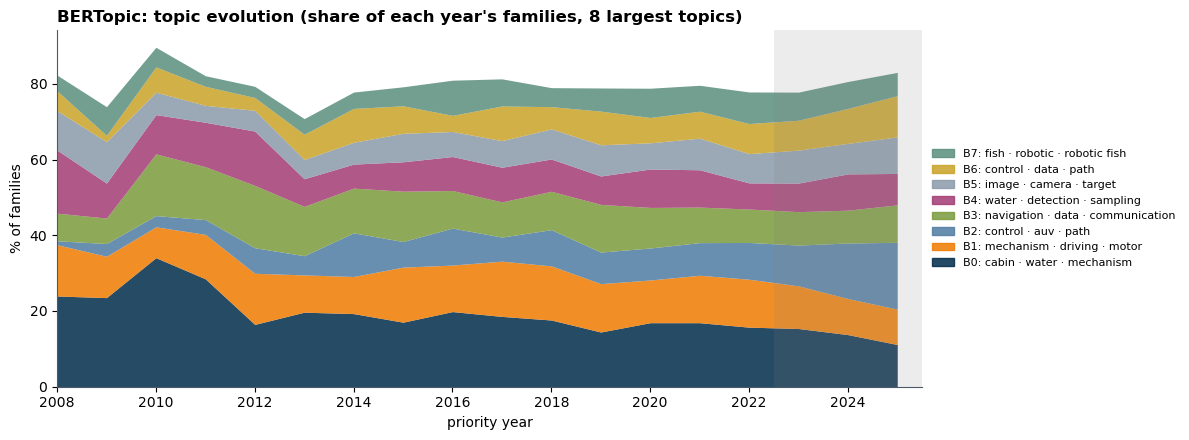

BERTopic: 14 topics, 0% outliers; agreement with the NMF topics (adjusted Rand index): 0.16


In [61]:
if RUN_BERTOPIC and SBERT_AVAILABLE:   # Patent SBERT + BERTopic (Tutorial 2 nb 21 §9.3); run_bertopic in config/sector.yaml
    try:
        from bertopic import BERTopic
        from sklearn.cluster import KMeans
        from sklearn.feature_extraction.text import CountVectorizer
        from umap import UMAP
        en = fam.loc[fam.abstract_en.notna()].copy()
        E = sbert_embeddings(en)                                   # cached: computed once
        bt = BERTopic(embedding_model=SentenceTransformer(C.SBERT_MODEL),
                      umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42),
                      hdbscan_model=KMeans(n_clusters=N_TOPICS, random_state=42, n_init=10),   # k-means, same k as NMF (see the note above)
                      vectorizer_model=CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | SECTOR_WORDS | PATENT_STOP), ngram_range=(1, 2)))
        en["bertopic"], _ = bt.fit_transform(en.abstract_en.tolist(), embeddings=E)
        bt_info = bt.get_topic_info()
        bt_info.to_csv(OUT / "bertopic_topics.csv", index=False)
        en[["docdb_family_id", "family_year", "bertopic"]].to_csv(OUT / "bertopic_assignments.csv", index=False)
        display(bt_info.head(20))
        # topic evolution: share of each year's families in the 8 largest topics (outliers, topic -1, removed)
        in_t = en[(en.bertopic >= 0) & en.family_year.between(2008, YEAR_MAX)]
        if in_t.empty:
            raise ValueError("no topic found: sample too small")
        largest = in_t.bertopic.value_counts().index[:8]
        share_bt = pd.crosstab(in_t.family_year, in_t.bertopic, normalize="index")[largest] * 100
        rep_bt = bt_info.set_index("Topic")["Representation"].to_dict()     # readable names: the first three words
        names_bt = {k: f"B{k}: " + " · ".join(list(v)[:3]) for k, v in rep_bt.items()}
        fig, ax = plt.subplots(figsize=(12, 4.5))
        share_bt.rename(columns=lambda k: names_bt.get(k, str(k))).plot.area(ax=ax, color=TOPIC_PALETTE[:share_bt.shape[1]],
                                                                            alpha=0.85, lw=0)
        shade(ax); ax.margins(x=0)
        ax.set(title="BERTopic: topic evolution (share of each year's families, 8 largest topics)", xlabel="priority year", ylabel="% of families")
        from matplotlib.patches import Patch
        h_ = [Patch(color=c, alpha=0.85) for c in TOPIC_PALETTE[:share_bt.shape[1]]]
        l_ = [names_bt.get(k, str(k)) for k in share_bt.columns]
        ax.legend(h_[::-1], l_[::-1], loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8, frameon=False)
        plt.tight_layout(); save(fig, "s2_bertopic_evolution"); plt.show()
        # agreement with the NMF topics (adjusted Rand index): low values = the two definitions disagree, discuss them
        from sklearn.metrics import adjusted_rand_score
        both_ = en.merge(docs[["docdb_family_id", "topic"]], on="docdb_family_id").query("bertopic >= 0 and topic >= 0")
        KEY["ari_nmf_bertopic"] = float(adjusted_rand_score(both_.topic, both_.bertopic))
        print(f"BERTopic: {(bt_info.Topic >= 0).sum()} topics, {(en.bertopic == -1).mean():.0%} outliers; "
              f"agreement with the NMF topics (adjusted Rand index): {KEY['ari_nmf_bertopic']:.2f}")
    except Exception as e:
        print(f"BERTopic skipped ({type(e).__name__}: {str(e)[:150]}). If a package is missing: "
              "pip install bertopic umap-learn; to switch it off: run_bertopic: false")
else:
    print("BERTopic not run: run_bertopic off in config/sector.yaml, or sentence-transformers missing")

### 2.4.3 The technology space: where is the field crowded, and where are the competitors?

The classic picture of a patent landscape (WIPO landscape reports): every family is a point placed by the similarity
of its abstract to the others (TF-IDF of 2.4.2 → 50 latent dimensions by truncated SVD → 2 dimensions by t-SNE), so
that families on similar technologies sit close. The **density** of points is the *patent density in the technology
space* (IM_Theory_3): peaks are crowded areas where freedom to operate is harder and returns from one more patent
lower; valleys are open space. Over the map: China vs the rest of the world, the main non-Chinese competitors and the
client. Each family also gets its **local density percentile** (100 = the most crowded spot of the map); the table
says in which kind of neighbourhood each player works. Axes have no meaning: only distances do.

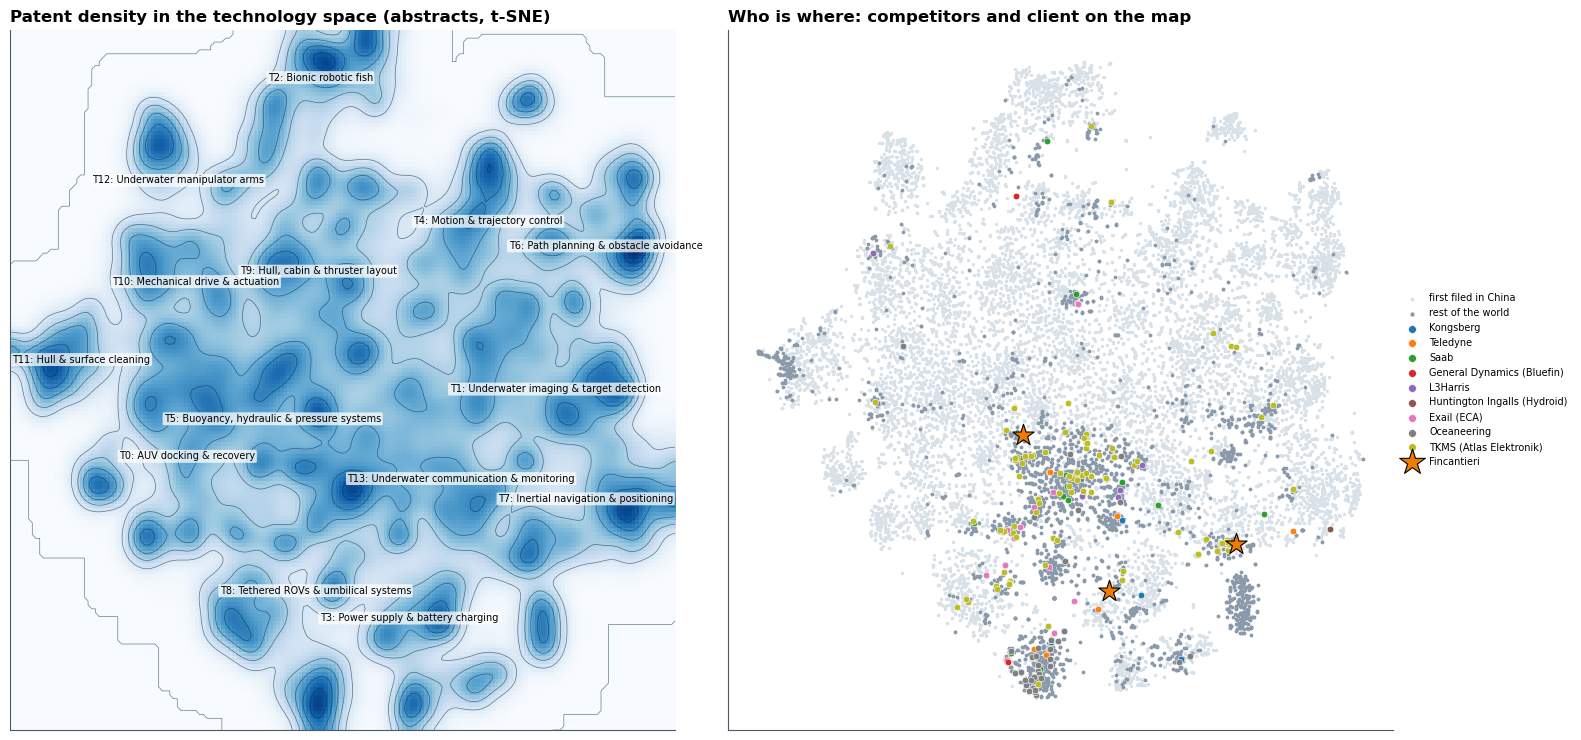

mean density percentile of the families: 2018-2022 50 vs 2013-2017 50 (higher = new families land in already crowded areas)


,families_on_map,mean_density_pct,share_in_crowded_top_quartile,country
applicant,,,,
TELEDYNE,9,73,78%,US
L3HARRIS,7,66,29%,US
OCEANEERING,45,66,56%,US
SAAB,12,61,42%,SE
NAVAL GROUP,19,60,37%,FR
TKMS (ATLAS ELEKTRONIK),95,58,36%,DE
SAMSUNG HEAVY INDUSTRIES,90,55,19%,KR
BAE SYSTEMS,33,51,27%,GB
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,223,50,25%,CN


In [62]:
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from scipy.ndimage import gaussian_filter

Z = TruncatedSVD(n_components=50, random_state=42).fit_transform(X)
XY = TSNE(n_components=2, perplexity=40, init="pca", learning_rate="auto", random_state=42).fit_transform(Z)
docs["x"], docs["y"] = XY[:, 0], XY[:, 1]
H, xe, ye = np.histogram2d(docs.x, docs.y, bins=180)
Hs = gaussian_filter(H, sigma=3)
ix = np.clip(np.searchsorted(xe, docs.x) - 1, 0, Hs.shape[0] - 1); iy = np.clip(np.searchsorted(ye, docs.y) - 1, 0, Hs.shape[1] - 1)
docs["density"] = Hs[ix, iy]
docs["density pct"] = docs["density"].rank(pct=True) * 100

dl = docs[["docdb_family_id", "x", "y", "density pct", "family_year"]].merge(links[["docdb_family_id", "applicant"]], on="docdb_family_id")
map_players = list(dict.fromkeys([m for m in market_leaders if m != CLIENT] + [p for p in bench_set if players.loc[p, "country"] != "CN"][:6]))
crowd = dl[dl.applicant.isin(map_players + [CLIENT] + list(players.head(6).index))].groupby("applicant").agg(
    families_on_map=("docdb_family_id", "nunique"), mean_density_pct=("density pct", "mean"),
    share_in_crowded_top_quartile=("density pct", lambda s: (s >= 75).mean()))
crowd["country"] = players["country"].reindex(crowd.index)
crowd = crowd.sort_values("mean_density_pct", ascending=False)
recent_shift = (docs[docs.family_year.between(*RECENT)]["density pct"].mean(), docs[docs.family_year.between(*PAST)]["density pct"].mean())
KEY["client_density_pct"] = float(crowd.loc[CLIENT, "mean_density_pct"]) if CLIENT in crowd.index else None
docs[["docdb_family_id", "x", "y", "density pct", "topic"]].to_csv(OUT / "technology_space_map.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
ext = [xe[0], xe[-1], ye[0], ye[-1]]
ax = axes[0]
ax.imshow(Hs.T, origin="lower", extent=ext, cmap="Blues", aspect="auto")
ax.contour(Hs.T, levels=6, extent=ext, colors=NAVY, linewidths=0.5, alpha=0.6)
for k in sorted(docs.topic[docs.topic >= 0].unique()):
    d = docs[docs.topic == k]
    ax.text(d.x.median(), d.y.median(), f"T{k}: {topic_labels[k]}", fontsize=7, ha="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
ax.set_title("Patent density in the technology space (abstracts, t-SNE)"); ax.set_xticks([]); ax.set_yticks([])
ax = axes[1]
cn = docs.first_office.eq("CN")
ax.scatter(docs.loc[cn, "x"], docs.loc[cn, "y"], s=2, color=LIGHT, label="first filed in China")
ax.scatter(docs.loc[~cn, "x"], docs.loc[~cn, "y"], s=3, color=MID, label="rest of the world")
for i, p in enumerate(map_players[:9]):
    d = dl[dl.applicant.eq(p)]
    ax.scatter(d.x, d.y, s=22, color=plt.cm.tab10(i % 10), edgecolor="white", lw=0.4, label=nice_name(p, 34))
d = dl[dl.applicant.eq(CLIENT)]
ax.scatter(d.x, d.y, s=260, marker="*", color=ORANGE, edgecolor="black", lw=0.8, label=CLIENT.title(), zorder=5)
ax.set_title("Who is where: competitors and client on the map"); ax.set_xticks([]); ax.set_yticks([])
ax.legend(frameon=False, fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5), markerscale=1.2)
plt.tight_layout(); save(fig, "s2_technology_space"); plt.show()
print(f"mean density percentile of the families: {RECENT[0]}-{RECENT[1]} {recent_shift[0]:.0f} vs {PAST[0]}-{PAST[1]} {recent_shift[1]:.0f} "
      "(higher = new families land in already crowded areas)")
short(crowd).style.format({"families_on_map": "{:,.0f}", "mean_density_pct": "{:.0f}", "share_in_crowded_top_quartile": "{:.0%}"})

## 2.5 Who leads where? Specialisation of players and countries

**Revealed Technological Advantage** (RTA, Patel & Pavitt, 1997; the Balassa index on patents):
$RTA_{i,s}=\dfrac{F_{i,s}/\sum_s F_{i,s}}{\sum_i F_{i,s}/\sum_{i,s}F_{i,s}}$, where $F_{i,s}$ are the families of actor
$i$ in subfield $s$. RTA > 1: the actor is specialised in that subfield relative to the sector. It tells *where* each
competitor is strong (a niche player can lead a subfield while being small overall), and later, in Step 6, whether
a target complements or duplicates the client (Teece, 1986). Read RTA only for actors with enough families: with 3
families (the client) one family moves the index a lot.

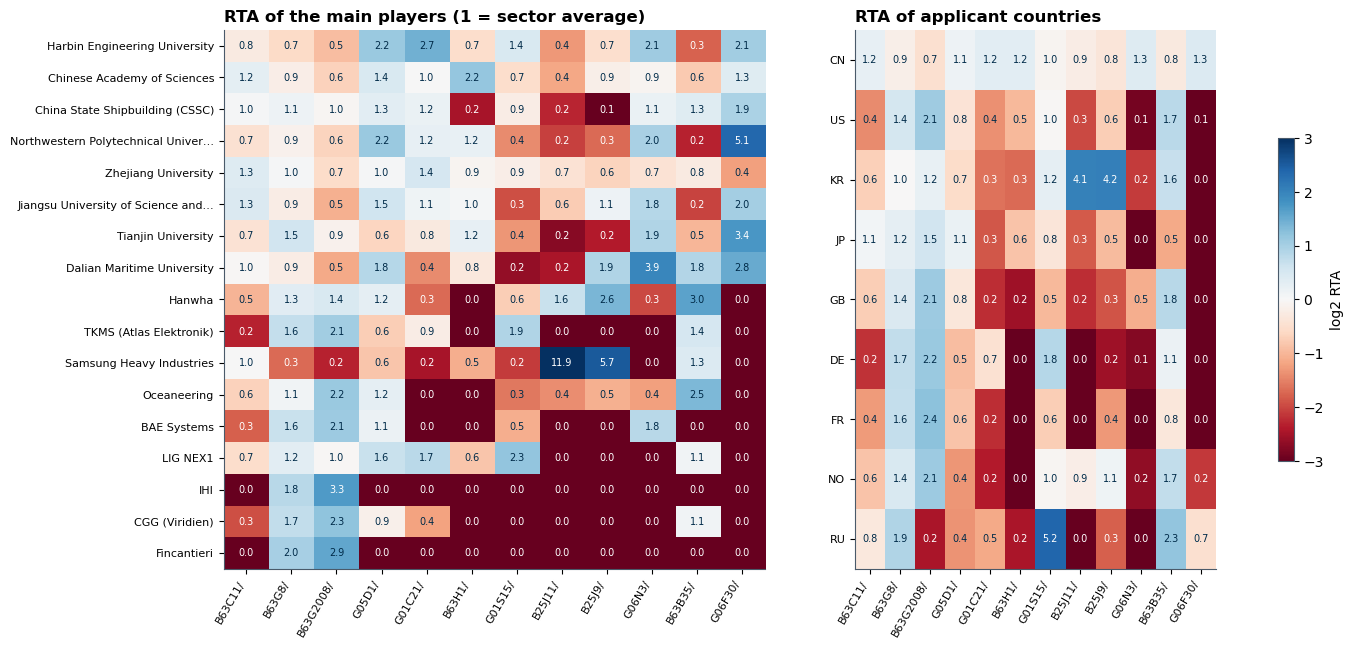

main_group,B63C11/,B63G8/,B63G2008/,G05D1/,G01C21/,B63H1/,G01S15/,B25J11/,B25J9/,G06N3/,B63B35/,G06F30/
country,,,,,,,,,,,,
CN,1.18,0.88,0.72,1.11,1.25,1.25,0.95,0.86,0.77,1.30,0.81,1.34
US,0.37,1.44,2.10,0.75,0.39,0.51,0.98,0.25,0.60,0.14,1.75,0.12
KR,0.61,1.00,1.17,0.68,0.32,0.31,1.20,4.08,4.15,0.24,1.63,0.00
JP,1.07,1.20,1.48,1.15,0.28,0.55,0.78,0.28,0.52,0.00,0.45,0.00
GB,0.60,1.35,2.12,0.78,0.22,0.17,0.51,0.22,0.27,0.47,1.77,0.00
DE,0.22,1.67,2.16,0.52,0.73,0.00,1.81,0.00,0.17,0.15,1.13,0.00
FR,0.41,1.63,2.36,0.55,0.21,0.00,0.60,0.00,0.40,0.00,0.79,0.00
NO,0.55,1.36,2.14,0.40,0.19,0.00,0.96,0.88,1.09,0.16,1.67,0.23
RU,0.81,1.87,0.18,0.40,0.46,0.18,5.16,0.00,0.29,0.00,2.25,0.72


In [63]:
key_sf = mapped.head(12).index.tolist()
mga = mg[mg.main_group.isin(key_sf)].merge(links[["docdb_family_id", "applicant", "country"]], on="docdb_family_id")
def rta_table(df, actor, actors):
    F = df.pivot_table(index=actor, columns="main_group", values="docdb_family_id", aggfunc="nunique", fill_value=0)
    rta = (F.div(F.sum(axis=1), axis=0)) / (F.sum(axis=0) / F.values.sum())
    return F.reindex(actors), rta.reindex(actors)[key_sf]

actors = list(players.index[:8]) + list(firms[firms.country != "CN"].index[:8]) + ([CLIENT] if CLIENT in players.index else [])
actors = list(dict.fromkeys(actors))
F_a, rta_a = rta_table(mga, "applicant", actors)
ctry_list = ["CN", "US", "KR", "JP", "GB", "DE", "FR", "NO", "RU"]
F_c, rta_c = rta_table(mga.drop_duplicates(["docdb_family_id", "main_group", "country"]), "country", ctry_list)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.5, 1]})
for ax, rta, title in [(axes[0], rta_a, "RTA of the main players (1 = sector average)"), (axes[1], rta_c, "RTA of applicant countries")]:
    im = ax.imshow(np.log2(rta.astype(float).clip(lower=0.125, upper=8)), cmap="RdBu", vmin=-3, vmax=3, aspect="auto")
    ax.set_xticks(range(len(key_sf)), key_sf, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(rta)), [str(i) if len(str(i)) <= 3 else nice_name(i, 34) for i in rta.index], fontsize=8)
    for i in range(rta.shape[0]):
        for j in range(rta.shape[1]):
            v = rta.iat[i, j]
            if pd.notna(v): ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if abs(np.log2(max(v, .125))) > 1.6 else NAVY)
    ax.set_title(title)
plt.colorbar(im, ax=axes, shrink=0.6, label="log2 RTA"); save(fig, "s2_rta_heatmaps"); plt.show()
rta_c.round(2)

**Simpler views for the deck.** (1) The five patenting strategies of the shortlist, in plain words, with the
number of firms, the typical international share and examples. (2) For each country (and for the client), the two
technologies where it is most specialised (RTA: 1 = the sector average, 2 = twice the average).

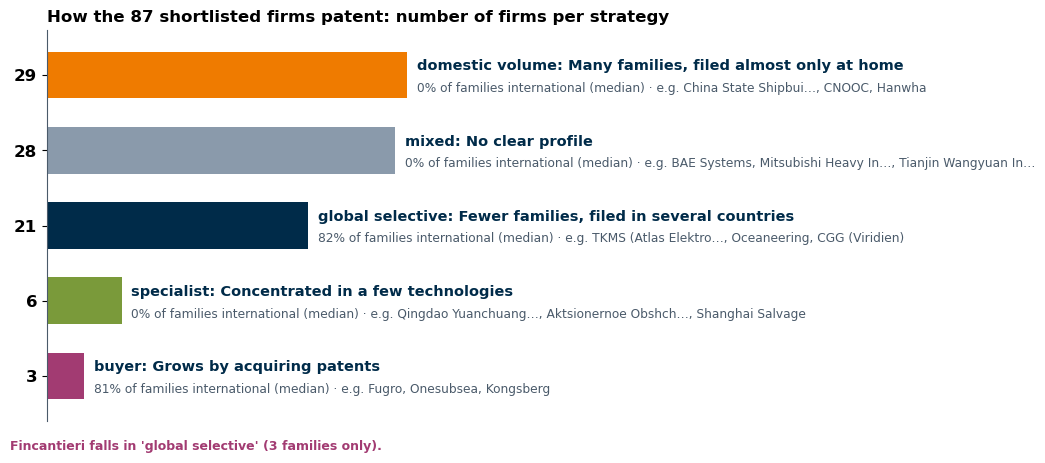

In [64]:
_arch = {"domestic volume": "Many families, filed almost only at home",
         "mixed": "No clear profile",
         "global selective": "Fewer families, filed in several countries",
         "specialist": "Concentrated in a few technologies",
         "buyer": "Grows by acquiring patents"}
_n = strat["archetype"].value_counts().reindex(list(_arch)).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(11, 4.6))
_cols = {"domestic volume": ORANGE, "mixed": MID, "global selective": NAVY, "specialist": GREEN, "buyer": RED}
ypos = np.arange(len(_arch))[::-1]
ax.barh(ypos, _n.values, color=[_cols[a] for a in _arch], height=0.62, zorder=2)
for y_, a in zip(ypos, _arch):
    d = strat[strat.archetype == a].sort_values("families", ascending=False)
    ex = ", ".join(nice_name(i, 20) for i in d.index[:3])
    ax.text(_n[a] + 0.8, y_ + 0.12, f"{a}: {_arch[a]}", va="center", fontsize=10.5, fontweight="bold", color=NAVY)
    ax.text(_n[a] + 0.8, y_ - 0.17, f"{d['international'].median():.0%} of families international (median) · e.g. {ex}", va="center", fontsize=8.8, color=GREY)
ax.set_yticks(ypos, [f"{v}" for v in _n.values], fontsize=12, fontweight="bold")
ax.set_xlim(0, 75); ax.set_xticks([]); ax.set_ylim(-0.6, len(_arch) - 0.4)
for sp in ("top", "right", "bottom"): ax.spines[sp].set_visible(False)
_fa = strat.loc[CLIENT, "archetype"] if CLIENT in strat.index else None
ax.set_title(f"How the {len(strat)} shortlisted firms patent: number of firms per strategy", loc="left", fontweight="bold")
if _fa: fig.text(0.01, 0.01, f"{CLIENT.title()} falls in '{_fa}' ({int(strat.loc[CLIENT, 'families'])} families only).", fontsize=9, color=RED, fontweight="bold")
plt.tight_layout(rect=(0, 0.04, 1, 1)); save(fig, "s2_strategies_simple"); plt.show()
KEY["client_archetype"] = _fa

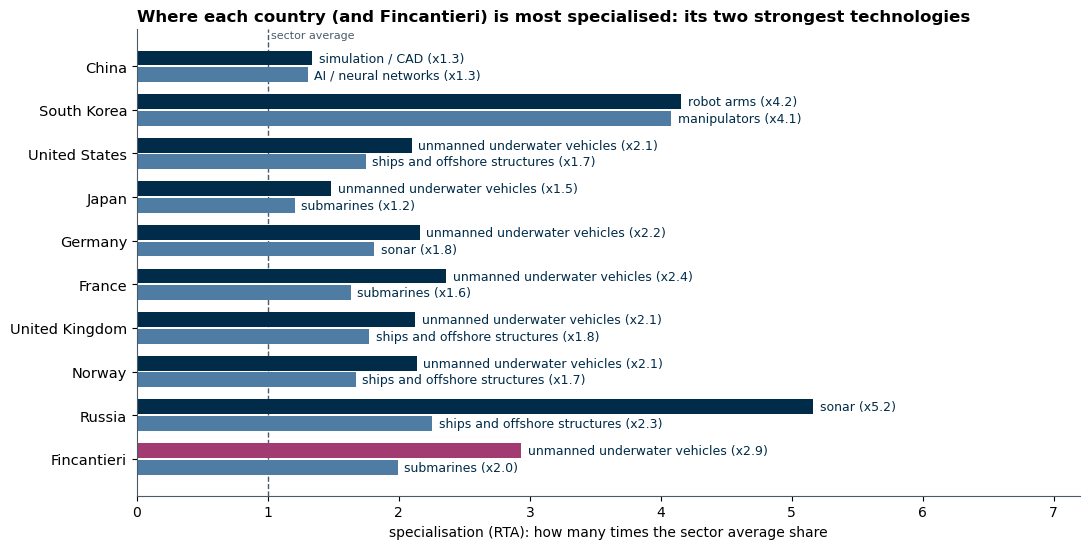

In [65]:
_tech = {"B63C11/": "diving / submersibles", "B63G8/": "submarines", "B63G2008/": "unmanned underwater vehicles", "G05D1/": "vehicle control",
         "G01C21/": "navigation", "B63H1/": "propulsion", "G01S15/": "sonar", "B25J11/": "manipulators", "B25J9/": "robot arms",
         "G06N3/": "AI / neural networks", "B63B35/": "ships and offshore structures", "G06F30/": "simulation / CAD"}
_rows = [(c, rta_c.loc[c]) for c in ["CN", "KR", "US", "JP", "DE", "FR", "GB", "NO", "RU"] if c in rta_c.index]
_fin = [(CLIENT.title(), rta_a.loc[i]) for i in rta_a.index if i.upper() == CLIENT.upper()]
_names = {"CN": "China", "KR": "South Korea", "US": "United States", "JP": "Japan", "DE": "Germany", "FR": "France", "GB": "United Kingdom", "NO": "Norway", "RU": "Russia"}
fig, ax = plt.subplots(figsize=(11, 5.6))
data = [(_names.get(n, n), r.sort_values(ascending=False).head(2)) for n, r in _rows + _fin]
for k, (name, top) in enumerate(data):
    y_ = len(data) - 1 - k
    col = RED if name == CLIENT.title() else NAVY
    for j, (t, v) in enumerate(top.items()):
        ax.barh(y_ + 0.19 - 0.38 * j, v, height=0.34, color=col if j == 0 else BLUE, zorder=2)
        ax.text(v + 0.05, y_ + 0.19 - 0.38 * j, f"{_tech.get(t, t)} (x{v:.1f})", va="center", fontsize=9, color=NAVY)
ax.axvline(1, color=GREY, ls="--", lw=1, zorder=1); ax.text(1.02, len(data) - 0.35, "sector average", fontsize=8, color=GREY)
ax.set_yticks(range(len(data)), [d[0] for d in data][::-1], fontsize=10.5)
ax.set_xlim(0, 7.2); ax.set_xlabel("specialisation (RTA): how many times the sector average share")
ax.set_title("Where each country (and Fincantieri) is most specialised: its two strongest technologies", loc="left", fontweight="bold")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
plt.tight_layout(); save(fig, "s2_specialisation_simple"); plt.show()

## 2.6 Collaboration: who works with whom?

Co-applications (a family filed by two or more applicant groups) are a trace of R&D alliances, of firm–university
collaboration and of public programmes (IM_Theory_2: universities transfer knowledge through licences, spin-offs
and industry partners). The network of co-applicants among the 60 largest applicants shows the alliances; node size
= families, colour = type. Betweenness centrality identifies the *brokers* (IM_Theory_2, intermediation), which are
natural partners for an entrant such as the client.

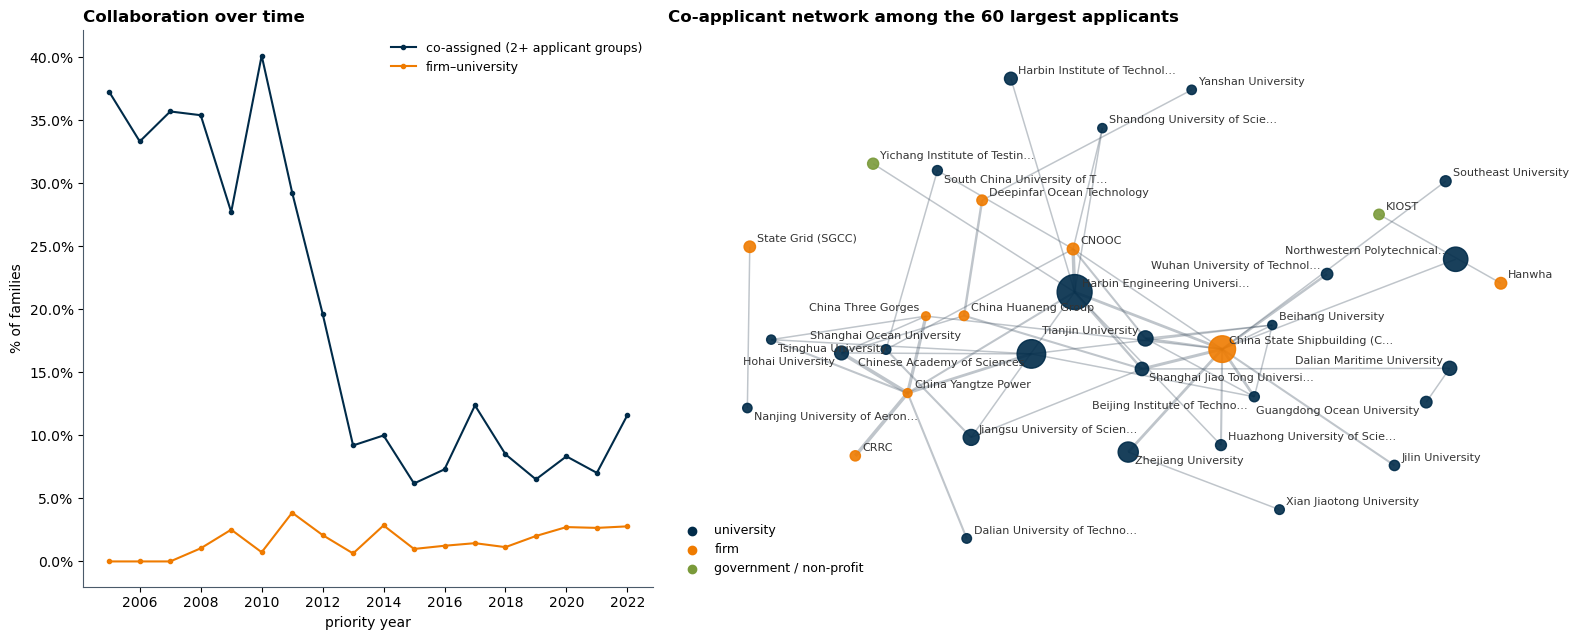

,partners (degree),betweenness,families,type
CHINA STATE SHIPBUILDING (CSSC),31,0.009,697,firm
SHANGHAI JIAO TONG UNIVERSITY,25,0.008,144,university
CHINESE ACADEMY OF SCIENCES,28,0.006,804,university
ZHEJIANG UNIVERSITY,29,0.005,381,university
HARBIN ENGINEERING UNIVERSITY,29,0.005,1226,university
CNOOC,26,0.004,102,firm
NANJING HYDRAULIC RESEARCH INSTITUTE,9,0.004,15,government / non-profit
NANJING UNIVERSITY OF AERONAUTICS AND ASTRON…,6,0.003,51,university
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,21,0.003,223,university
STATE GRID (SGCC),16,0.003,96,firm


In [66]:
co = fam[fam.family_year.between(2005, LAST)].groupby("family_year")[["co_assigned", "firm_univ_collab"]].agg(lambda s: s.astype(str).str.lower().eq("true").mean()) * 100
multi = links.groupby("docdb_family_id").filter(lambda d: len(d) > 1)
edges = (multi.merge(multi, on="docdb_family_id").query("applicant_x < applicant_y")
              .groupby(["applicant_x", "applicant_y"]).size().rename("weight").reset_index())
G = nx.Graph(); G.add_weighted_edges_from(edges.itertuples(index=False, name=None))
TOPNET = list(players.index[:60])
H = G.subgraph([n for n in TOPNET if n in G]).copy()
H.remove_nodes_from([n for n in list(H) if H.degree(n) == 0])
btw = pd.Series(nx.betweenness_centrality(G, weight=None, k=min(500, len(G)), seed=42)).sort_values(ascending=False)
deg = pd.Series(dict(G.degree())).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.6]})
co.plot(ax=axes[0], marker="o", ms=3, color=[NAVY, ORANGE]); axes[0].yaxis.set_major_formatter(PercentFormatter(100))
axes[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True)); axes[0].set(title="Collaboration over time", xlabel="priority year", ylabel="% of families"); axes[0].legend(["co-assigned (2+ applicant groups)", "firm–university"], frameon=False, fontsize=9)
pos = nx.spring_layout(H, seed=3, k=0.9, weight="weight")
tcol = {"university": NAVY, "firm": ORANGE, "government / non-profit": GREEN, "unknown": MID, "individual": BLUE}
nx.draw_networkx_edges(H, pos, ax=axes[1], width=[0.4 + np.log1p(H[u][v]["weight"]) for u, v in H.edges], alpha=0.35, edge_color=GREY)
nx.draw_networkx_nodes(H, pos, ax=axes[1], node_size=[20 + players.loc[n, "families"] / 2 for n in H], node_color=[tcol.get(players.loc[n, "type"], MID) for n in H], alpha=0.9)
present_types = {players.loc[n, "type"] for n in H}
for t, c in tcol.items():
    if t in present_types: axes[1].scatter([], [], color=c, label=t)        # legend: only the types on the map
axes[1].legend(frameon=False, fontsize=9, loc="lower left"); axes[1].axis("off"); axes[1].set_title("Co-applicant network among the 60 largest applicants")
plt.tight_layout()
order_h = sorted(H, key=lambda n: -players.loc[n, "families"])
label_points(axes[1], [pos[n][0] for n in order_h], [pos[n][1] for n in order_h], [nice_name(n, 28) for n in order_h],
             fontsize=8)
save(fig, "s2_collaboration"); plt.show()
short(pd.DataFrame({"partners (degree)": deg, "betweenness": btw, "families": players["families"], "type": players["type"]}).dropna(subset=["partners (degree)"]).sort_values("betweenness", ascending=False).head(12)).style.format({"betweenness": "{:.3f}", "partners (degree)": "{:.0f}", "families": "{:.0f}"})

### 2.6.1 The market for technology: who sells, who buys?

From the ownership changes of `02_clean` §9.2 (transfers classified, security interests and renamings excluded,
a change counted only when the new owner is a different group from the applicants at filing). Patents are traded
on a secondary market (IM_Theory_2, choice 4): buyers that accumulate patents of the sector are potential
consolidators or competitors of the client; sellers show where technology flows out (for universities, technology
transfer). New owners are often not recorded (almost all Chinese transfers): the share of changes is reliable, the
list of buyers is complete only for US, EP and DE records.

In [67]:
own_file = IN / "ownership_events.csv"
if own_file.exists() and "owner_changed" in fam.columns:
    oe = pd.read_csv(own_file, low_memory=False)
    real_ = oe[oe["is_real_change"].astype(str).str.lower().eq("true")]
    fam["owner_changed"] = fam["owner_changed"].astype(str).str.lower().eq("true")
    by_type = fam_c.assign(owner_changed=fam.loc[fam_c.index, "owner_changed"]).groupby("main_type")["owner_changed"].mean()
    by_origin = fam_c.assign(owner_changed=fam.loc[fam_c.index, "owner_changed"]).groupby("origin_group")["owner_changed"].mean()
    KEY["share_families_owner_changed"] = float(fam["owner_changed"].mean())
    display(pd.DataFrame({"families whose owner changed": pd.concat([by_type, by_origin])}).style.format("{:.1%}"))
    buyers = real_[real_.new_owner.ne("UNKNOWN (not recorded)")].drop_duplicates(["docdb_family_id", "new_owner"]).groupby("new_owner").size().sort_values(ascending=False).head(12)
    sellers = real_.drop_duplicates(["docdb_family_id", "filed_by"]).groupby("filed_by").size().sort_values(ascending=False).head(12)
    display(short(buyers.to_frame("families bought")))
    short(sellers.to_frame("families sold / transferred"))
else:
    print("Ownership changes not in this edition of the step1 tables: re-run 02_clean (Section 9.2) and then this notebook.")

,families whose owner changed
firm,14.6%
government / non-profit,10.9%
individual,23.1%
university,6.0%
unknown,9.9%
China,8.6%
EP / PCT first,23.0%
Europe & rest of world,9.2%
Korea & Japan,9.8%
United States,32.4%


,families bought
new_owner,
UNITED STATES OF AMERICA AS REPRESENTED BY T…,18
PXGEO UK,18
FAIRFIELD SEISMIC TECHNOLOGIES,15
FUGRO,13
MASSACHUSETTS INSTITUTE OF TECHNOLOGY MASSAC…,7
KONGSBERG,6
L3HARRIS,6
HITACHI ENERGY,4
WOODS HOLE OCEANOGRAPHIC INSTITUTION MASSACH…,4


### 2.6.2 Citation network: who builds on whose knowledge?

The *how* of IM_Theory_3 (*"citation networks, family links, ownership changes"*). Each backward citation inside the
sector becomes an arrow from the citing group to the cited group, split fractionally over the owners of both families;
self-citations are left out. On the network of all groups:

- **citations received from other players** (weighted in-degree): who is a source of knowledge;
- **PageRank**: a source is more important if it is cited by players that are themselves cited (Google's measure,
  used for patents e.g. by Bruck et al., 2016);
- **betweenness** (on the undirected network of the players drawn): who connects otherwise separate groups, a
  *knowledge broker*;
- **communities** (Louvain): groups of players that cite each other more than they cite the rest, i.e. technological
  clusters or national systems of innovation.

The figure draws the 40 players with most families plus the market leaders of 1.5.1 and the client.

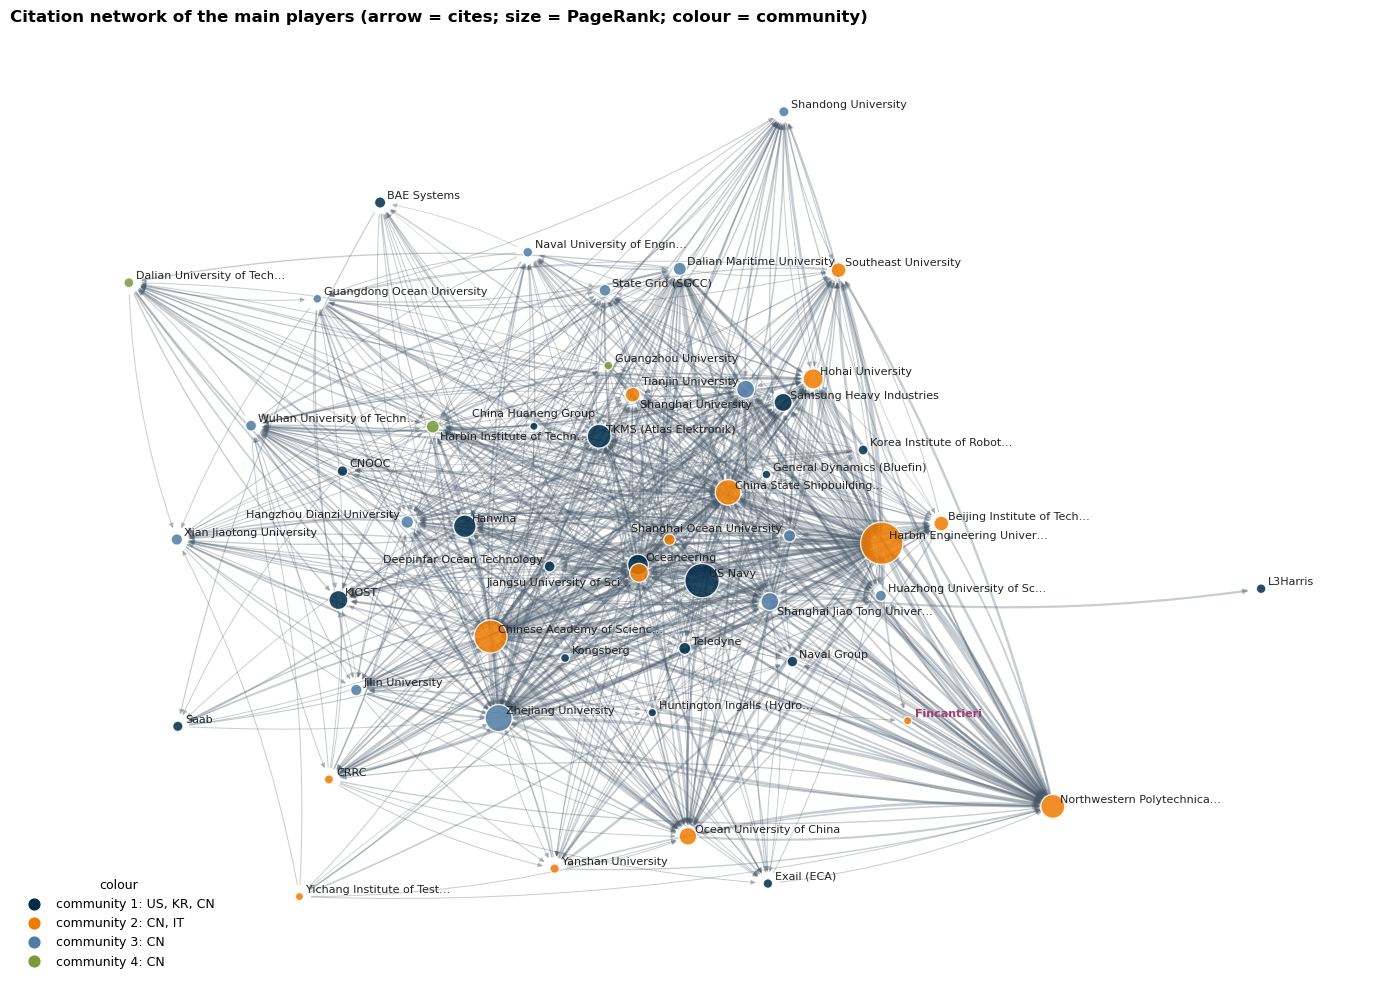

,players,main countries,members (by PageRank)
community,,,
1,19,"US, KR, CN",Us Navy; Tkms (Atlas Elektronik); Hanwha; Oceaneering; K...
2,15,"CN, IT",Harbin Engineering Univers; Chinese Academy Of Science; ...
3,14,CN,Zhejiang University; Tianjin University; Shanghai Jiao T...
4,3,CN,Harbin Institute Of Techno; Dalian University Of Techn; ...


,families,country,type,citations received from players,citations made to players,PageRank (×1000),betweenness,community,received / made
HARBIN ENGINEERING UNIVERSITY,"1,226",CN,university,1641.3,1067.0,37.76,0.085,2,1.54
US NAVY,97,US,government / non-profit,220.1,247.2,24.31,0.068,1,0.89
CHINESE ACADEMY OF SCIENCES,804,CN,university,934.7,881.5,22.41,0.073,2,1.06
ZHEJIANG UNIVERSITY,381,CN,university,567.8,417.8,14.73,0.028,3,1.36
CHINA STATE SHIPBUILDING (CSSC),697,CN,firm,526.8,596.5,12.93,0.054,2,0.88
NORTHWESTERN POLYTECHNICAL UNIVERSITY,575,CN,university,495.0,801.5,11.19,0.028,2,0.62
TKMS (ATLAS ELEKTRONIK),96,DE,firm,186.5,127.8,11.02,0.025,1,1.46
HANWHA,101,KR,firm,163.5,48.2,9.74,0.012,1,3.39
OCEANEERING,45,US,firm,93.6,91.1,8.14,0.006,1,1.03
HOHAI UNIVERSITY,158,CN,university,262.0,151.0,7.61,0.008,2,1.74


In [68]:
own_w = appl[["docdb_family_id", "applicant", "weight"]]
e = (ins[["docdb_family_id", "cited_family_id"]]
     .merge(own_w.rename(columns={"applicant": "citing", "weight": "w1"}), on="docdb_family_id")
     .merge(own_w.rename(columns={"docdb_family_id": "cited_family_id", "applicant": "cited", "weight": "w2"}), on="cited_family_id"))
e = e[e.citing != e.cited].assign(w=lambda d: d.w1 * d.w2).groupby(["citing", "cited"], as_index=False)["w"].sum()
DG = nx.DiGraph(); DG.add_weighted_edges_from(e.itertuples(index=False, name=None))
pr = pd.Series(nx.pagerank(DG, weight="weight"))
in_s = pd.Series(dict(DG.in_degree(weight="weight"))); out_s = pd.Series(dict(DG.out_degree(weight="weight")))

draw = list(dict.fromkeys(list(players.head(40).index) + [m for m in market_leaders if m in DG] + ([CLIENT] if CLIENT in DG else [])))
draw = [n for n in draw if n in DG]
SG = DG.subgraph(draw).copy()
UG = nx.Graph()
for u, v, d in SG.edges(data=True):
    UG.add_edge(u, v, weight=UG[u][v]["weight"] + d["weight"] if UG.has_edge(u, v) else d["weight"])
comm = nx.community.louvain_communities(UG, weight="weight", seed=42) if len(UG) else []
comm_of = {n: i + 1 for i, c in enumerate(sorted(comm, key=len, reverse=True)) for n in c}
btw_c = pd.Series(nx.betweenness_centrality(UG, weight=None)) if len(UG) else pd.Series(dtype=float)

cit_net = pd.DataFrame({"families": players["families"].reindex(draw), "country": players["country"].reindex(draw),
                        "type": players["type"].reindex(draw), "citations received from players": in_s.reindex(draw),
                        "citations made to players": out_s.reindex(draw), "PageRank (×1000)": pr.reindex(draw) * 1000,
                        "betweenness": btw_c.reindex(draw), "community": pd.Series(comm_of).reindex(draw)})
cit_net["received / made"] = cit_net["citations received from players"] / cit_net["citations made to players"].replace(0, np.nan)
cit_net = cit_net.sort_values("PageRank (×1000)", ascending=False)
cit_net.to_csv(OUT / "citation_network_players.csv")
comm_tab = (cit_net.groupby("community").apply(lambda d: pd.Series({
    "players": len(d), "main countries": ", ".join(d["country"].value_counts().head(3).index.astype(str)),
    "members (by PageRank)": "; ".join(str(n)[:26].title() for n in d.index[:7])})))
KEY["top_pagerank"] = [str(n) for n in cit_net.index[:5]]
KEY["citation_communities"] = int(len(comm))

fig, ax = plt.subplots(figsize=(14, 10))
# Kamada-Kawai spreads the dense Chinese core more evenly than a spring layout (labels can then be placed)
pos = nx.kamada_kawai_layout(UG) if nx.is_connected(UG) else nx.spring_layout(UG, seed=7, k=1.6, weight="weight")
if pos:   # a player linked by one thin edge can sit far away and squeeze the rest: pull outliers in (direction kept)
    P_ = np.array(list(pos.values())); c_ = np.median(P_, axis=0); r_ = np.linalg.norm(P_ - c_, axis=1)
    cap_ = np.quantile(r_, 0.9) * 1.15
    pos = {n: c_ + (p_ - c_) * min(1, cap_ / max(np.linalg.norm(p_ - c_), 1e-9)) for n, p_ in pos.items()}
ccol = {i: PALETTE[(i - 1) % len(PALETTE)] for i in set(comm_of.values())}
nx.draw_networkx_edges(SG, pos, ax=ax, width=[0.3 + 0.6 * np.log1p(SG[u][v]["weight"]) for u, v in SG.edges],
                       alpha=0.3, edge_color=GREY, arrows=True, arrowsize=7, connectionstyle="arc3,rad=0.08")
pr_draw = pd.Series({n: pr.get(n, 0) for n in SG})
nx.draw_networkx_nodes(SG, pos, ax=ax, node_size=[30 + 900 * v / pr_draw.max() for v in pr_draw],
                       node_color=[ccol.get(comm_of.get(n), MID) for n in SG], alpha=0.85, edgecolors="white")
for i, row in comm_tab.iterrows():                 # legend: the communities and their main countries
    ax.scatter([], [], s=60, color=ccol.get(i, MID), label=f"community {i}: {row['main countries']}")
ax.legend(frameon=False, fontsize=9, loc="lower left", title="colour", title_fontsize=9)
ax.set_title("Citation network of the main players (arrow = cites; size = PageRank; colour = community)"); ax.axis("off")
plt.tight_layout()
# labels: client and market leaders first, then by PageRank; a name with no free place is left out (table below)
lab_order = list(dict.fromkeys(([CLIENT] if CLIENT in SG else []) + [m for m in market_leaders if m in SG]
                               + list(pr_draw.sort_values(ascending=False).index)))
label_points(ax, [pos[n][0] for n in lab_order], [pos[n][1] for n in lab_order], [nice_name(n, 26) for n in lab_order],
             fontsize=8, colors=[RED if n == CLIENT else "#222222" for n in lab_order],
             fontweights=["bold" if n == CLIENT else None for n in lab_order])
save(fig, "s2_citation_network"); plt.show()
display(comm_tab)
short(cit_net.head(20)).style.format({"families": "{:,.0f}", "citations received from players": "{:.1f}", "citations made to players": "{:.1f}",
                                      "PageRank (×1000)": "{:.2f}", "betweenness": "{:.3f}", "community": "{:.0f}", "received / made": "{:.2f}"}, na_rep="–")

## 2.7 Where does the client stand?

Fincantieri (with WASS, Graal Tech, WSense, NextGeo, Defcomm: `GROUP_ALIASES`) against the sector: its families,
their subfields and what they look like. A tiny portfolio is itself the finding: the client has the
complementary assets (shipyards, naval programmes, customers) but not the technology portfolio, which is the
classic setting for an acquisition or a partnership (Teece, 1986): Step 6.

In [69]:
cl_ids = set(appl.loc[appl.applicant == CLIENT, "docdb_family_id"])
cl = fam[fam.docdb_family_id.isin(cl_ids)][["docdb_family_id", "family_year", "first_office", "offices", "granted_any", "fwd_cits_5y", "title_en"]]
cl_sub = mg[mg.docdb_family_id.isin(cl_ids)].groupby("main_group")["docdb_family_id"].nunique().sort_values(ascending=False)
KEY["client_families"] = int(len(cl_ids))
print(f"{CLIENT}: {len(cl_ids)} families; subfields: {cl_sub.to_dict()}")
cl.sort_values("family_year")

FINCANTIERI: 3 families; subfields: {'F42B19/': 2, 'H01M10/': 2, 'H01M50/': 2, 'B63G2008/': 1, 'B63H21/': 1, 'B63G8/': 1, 'G01S5/': 1, 'H01M6/': 1}


,docdb_family_id,family_year,first_office,offices,granted_any,fwd_cits_5y,title_en
354,40433835,2008,EP,EP,True,3,System and method for acoustic tracking an underwater ve...
1192,50513984,2014,US,EP US,True,1,Underwater vehicle provided with heat exchanger
4497,66867675,2019,IT,EP FI IT US,True,0,"VALVE SYSTEM FOR AN ELECTROCHEMICAL POWER SOURCE, IN PAR..."


**Who is strong where the client is (or wants to be)?** For the subfields of the client's families, and for the
fastest-growing large subfields, the top non-university owners: the first list of *partners or targets* to score in
Steps 3–5.

In [70]:
cl_main = [s for s in cl_sub.index if mg[mg.main_group == s].docdb_family_id.nunique() >= 15]   # client subfields large enough to read
focus = list(dict.fromkeys(cl_main + list(mapped.sort_values("growth vs sector (pp)", ascending=False).head(4).index)))
rows = []
for s in focus:
    d = mg[(mg.main_group == s) & mg.family_year.between(2013, LAST)].merge(links[["docdb_family_id", "applicant", "type", "country"]], on="docdb_family_id")
    d = d[d.type.isin(["firm", "unknown", "government / non-profit"])]
    top = d.groupby("applicant")["docdb_family_id"].nunique().sort_values(ascending=False).head(5)
    rows.append({"subfield": s, "title (verify)": MAIN_GROUP_TITLES.get(s, ""), "families 2013-2022": mg[(mg.main_group == s) & mg.family_year.between(2013, LAST)].docdb_family_id.nunique(),
                 "top non-university owners (families)": "; ".join(f"{a.title()[:28]} ({n})" for a, n in top.items())})
pd.DataFrame(rows).style.hide(axis="index")

subfield,title (verify),families 2013-2022,top non-university owners (families)
F42B19/,Marine torpedoes,37,Hamilton Sundstrand (5); Tkms (Atlas Elektronik) (4); Hanwha (3); Agency For Defense Developme (2); Us Navy (2)
H01M10/,Secondary batteries,28,Hanwha (2); Fincantieri (2); 7Th O 5 Research Institute O (1); Aktsionernoe Obshchestvo Tse (1); Federalnoe Gosudarstvennoe U (1)
H01M50/,Battery constructional details (check),23,Fincantieri (2); Bae Systems (1); Agency For Defense Developme (1); China State Shipbuilding (Cs (1); Eelume (1)
B63G2008/,Unmanned underwater vessels (indexing),1709,China State Shipbuilding (Cs (46); Us Navy (37); Tkms (Atlas Elektronik) (25); Oceaneering (23); Hanwha (23)
B63H21/,Marine propulsion power plants,184,China State Shipbuilding (Cs (5); Suzhou Yijijie Electronic Te (4); Mitsubishi Heavy Industries (4); Suzhou Huibei Electronic Tec (3); Kiost (2)
B63G8/,"Underwater vessels, e.g. submarines",2501,China State Shipbuilding (Cs (82); Us Navy (33); Hanwha (28); Tkms (Atlas Elektronik) (25); Hangzhou Changdong Intellige (20)
G01S5/,Position-fixing,133,China State Shipbuilding (Cs (7); Electronic Science Research (3); State Grid (Sgcc) (2); Tkms (Atlas Elektronik) (2); Kawasaki Heavy Industries (2)
G06F17/,Digital computing / data processing (check),62,Peoples Liberation Army 6154 (2); Xian Aerospace Tianhui Data (2); China Construction Third Eng (1); Hangzhou Duyuan Information (1); Hunan Aerospace Electromecha (1)
G06F18/,Pattern recognition,77,Qingdao Pengpai Ocean Explor (4); Xian Aerospace Tianhui Data (2); China Institute Of Water Res (1); Fisheries Research Institute (1); Guangzhou Huitong Technology (1)
G06N3/,Neural networks / biological computing models,173,Qingdao Pengpai Ocean Explor (4); China State Shipbuilding (Cs (3); Bae Systems (3); Hunan Guotian Electronic Tec (2); Abyssal (1)


### 2.7.1 Potentially blocking patents: a first freedom-to-operate screen

A **freedom-to-operate (FTO)** search asks whether a product can be made and sold without infringing patents in force
in the markets where it will be sold (IM_Theory_2–3). A real FTO needs claim-by-claim reading by a patent attorney;
the landscape can only **shortlist the families to read**. A family is a candidate when it is:

1. **alive** (in force or pending: `family_status` of 02_clean §9.1; before the re-run, the `active_proxy`);
2. **protected where the client sells**: at least one office in common with the client's own families (WO excluded,
   it is not a market), plus `FTO_EXTRA_MARKETS`;
3. **in the technologies the client works on or wants to enter**: the client's subfields and the fastest-growing ones
   (`focus`, Section 2.7);
4. not owned by the client.

Candidates are ranked by **X-citations received** (the number of later families whose novelty an examiner challenged
with this patent: a direct sign that it covers ground others try to enter), then by forward citations and by
residual life. The flag *cited by the client* marks families already cited against the client's own applications.

In [71]:
FTO_EXTRA_MARKETS = {"EP", "US", "IT", "GB", "DE", "FR", "NO"}     # client's markets beyond its own filings: a design choice
client_markets = set(fam.loc[fam.docdb_family_id.isin(cl_ids), "offices"].astype(str).str.split().explode()) - {"WO", "nan"}
client_markets |= FTO_EXTRA_MARKETS
target_sf = list(dict.fromkeys(list(cl_sub.index) + focus))
in_target = mg[mg.main_group.isin(target_sf)].groupby("docdb_family_id")["main_group"].agg(lambda s: " ".join(sorted(set(s))))

cand = fam[fam.docdb_family_id.isin(in_target.index) & ~fam.docdb_family_id.isin(cl_ids)].copy()
cand["alive"] = cand["family_status"].isin(["in force", "pending"]) if "family_status" in cand else cand["active_proxy"]
cand["markets hit"] = cand["offices"].astype(str).str.split().apply(lambda s: " ".join(sorted(set(s) & client_markets)))
cand = cand[cand["alive"] & cand["markets hit"].ne("")]
cand["subfields hit"] = cand["docdb_family_id"].map(in_target)
cited_by_client = set(bwd.loc[bwd.docdb_family_id.isin(cl_ids), "cited_family_id"])
cand["cited by the client"] = cand["docdb_family_id"].isin(cited_by_client)
cand["block 6 only"] = cand["b6_only"].astype(bool)          # strict precision 48%: read these titles first
owners_now = (fam_own.groupby("docdb_family_id")["current_owner"].agg(lambda s: " | ".join(map(str, s))) if fam_own is not None
              else appl.groupby("docdb_family_id").apply(
                  lambda d: " | ".join(sorted(set(d.loc[d.type.ne("individual"), "applicant"]) or set(d["applicant"])))))
# (inventors who are also applicants are dropped from the owner label when an organisation owns the family)
cand["owner"] = cand["docdb_family_id"].map(owners_now)
cand["fwd_X_cits"] = pd.to_numeric(cand["fwd_X_cits"], errors="coerce").fillna(0)
sort_cols = ["cited by the client", "fwd_X_cits", "fwd_cits"] + (["family_residual_life_years"] if "family_residual_life_years" in cand else [])
cand = cand.sort_values(sort_cols, ascending=False)
fto_cols = ["docdb_family_id", "owner", "family_year", "title_en", "markets hit", "subfields hit", "fwd_X_cits", "fwd_cits",
            "cited by the client", "block 6 only"] + [c for c in ["family_status", "family_expiry_date", "family_residual_life_years"] if c in cand.columns]
cand[fto_cols].to_csv(OUT / "fto_candidates.csv", index=False)
fto_owners = cand.groupby("owner").agg(families=("docdb_family_id", "size"), x_cits=("fwd_X_cits", "sum"),
                                       block6_only_share=("block 6 only", "mean")).sort_values(["x_cits", "families"], ascending=False)
print(f"FTO candidates found only by block 6: {cand['block 6 only'].mean():.0%}")
KEY["fto_candidates"] = int(len(cand)); KEY["fto_candidates_x_cited"] = int((cand.fwd_X_cits > 0).sum())

print(f"client markets: {' '.join(sorted(client_markets))} | target subfields: {' '.join(target_sf)}")
print(f"alive families of others in those markets and subfields: {len(cand):,} | cited as X at least once: {(cand.fwd_X_cits > 0).sum():,} "
      f"| already cited against the client: {cand['cited by the client'].sum():,}  → full list in fto_candidates.csv")
display(short(fto_owners.head(12)).rename(columns={"x_cits": "X-citations received"}))
cand[fto_cols].head(20).style.hide(axis="index").format({"fwd_X_cits": "{:.0f}", "fwd_cits": "{:.0f}", "family_residual_life_years": "{:.1f}"}, na_rep="–")

FTO candidates found only by block 6: 3%
client markets: DE EP FI FR GB IT NO US | target subfields: F42B19/ H01M10/ H01M50/ B63G2008/ B63H21/ B63G8/ G01S5/ H01M6/ G06F17/ G06F18/ G06N3/ B62D55/
alive families of others in those markets and subfields: 956 | cited as X at least once: 264 | already cited against the client: 0  → full list in fto_candidates.csv


,families,X-citations received,block6_only_share
owner,,,
UNKNOWN (not recorded),27,26.0,0.000000
PXGEO UK,12,14.0,0.000000
FAIRFIELD SEISMIC TECHNOLOGIES,7,14.0,0.000000
IHI,3,14.0,0.000000
TKMS (ATLAS ELEKTRONIK),39,13.0,0.102564
SAUDI ARAMCO,12,13.0,0.000000
RAYTHEON,12,11.0,0.000000
THALES,11,11.0,0.090909
AEROVIRONMENT | BELIK PAVEL | FISHER CHRISTO…,1,11.0,0.000000


docdb_family_id,owner,family_year,title_en,markets hit,subfields hit,fwd_X_cits,fwd_cits,cited by the client,block 6 only,family_status,family_expiry_date,family_residual_life_years
45004252,AEROVIRONMENT | BELIK PAVEL | FISHER CHRISTOPHER E | MCALLISTER JUSTIN B | SCHMALZEL MARC L | TOKUMARU PHILLIP T | TORRES GABRIEL | TYLER JEREMY D | ZWAAN JOHN PETER,2010,RECONFIGURABLE BATTERY-OPERATED VEHICLE SYSTEM,EP US,B63G2008/ B63G8/ B63H21/,11,128,False,False,in force,2040-07-01 00:00:00,13.9
50273129,RAYTHEON,2012,Autonomous Hull Navigation,US,B62D55/ B63G8/,9,69,False,False,in force,2033-02-17 00:00:00,6.5
45437685,DARLING DONALD T | HERTEL III WILLIAM M | HERTEL III WILLIAM MARTIN | HOLAPPA KENNETH WALTER | SEAROBOTICS,2009,Robotic Submersible Cleaning System,US,B63G2008/,9,55,False,False,in force,2030-11-23 00:00:00,4.3
48574383,IHI,2011,POWER TRANSMISSION APPARATUS,EP US,B63G2008/ B63G8/,8,51,False,False,in force,2034-10-23 00:00:00,8.2
50436406,AMIT FARBER | EHUD ERELL | ISRAEL AEROSPACE INDUSTRIES (ELTA),2013,UNDERWATER SYSTEM AND METHOD,EP US,B63G2008/ B63G8/,8,39,False,False,in force,2038-07-18 00:00:00,11.9
36684055,FAIRFIELD SEISMIC TECHNOLOGIES,2005,Apparatus for deployment of ocean bottom seismometers,EP US,B63G2008/ B63G8/,7,131,False,False,in force,2040-02-05 00:00:00,13.5
54700887,CALIFORNIA INSTITUTE OF TECHNOLOGY,2014,CONTROLLABLE BUOYS AND NETWORKED BUOY SYSTEMS,US,B63G2008/ B63G8/,6,123,False,False,in force,2035-06-02 00:00:00,8.8
39030569,DSNS | FOURNIER JEAN CLAUDE | NAVAL GROUP,2007,SUBMARINE PROVIDED WITH A DEVICE FOR RELEASING AND RECOVERING A SECONDARY UNDERWATER VEHICLE,EP FR US,B63G2008/ B63G8/,6,37,False,False,in force,2028-06-09 00:00:00,1.8
88806094,XINGMAI INNOVATION TECHNOLOGY SUZHOU,2023,"MOVING APPARATUS FOR USE IN LIQUID, AND SWIMMING POOL CLEANING ROBOT",EP US,B63G2008/ B63G8/,6,30,False,False,in force,2043-07-17 00:00:00,16.9
61829535,UNKNOWN (not recorded),2016,UNDERWATER MOVING BODY AND UNDERWATER COMMUNICATION SYSTEM,US,B63G2008/ B63G8/,6,27,False,False,in force,2037-05-25 00:00:00,10.8


**Risk flags on the FTO candidates.** The prosecution history of 2.2.4 qualifies each candidate: *survived
opposition* (stronger, read first), *amended / limited* (narrower scope: read the amended claims), *opted out of the
UPC* (the owner values it and wants national courts), *refused or withdrawn somewhere* (check that it is in force
in the client's markets), *litigation recorded*.

In [72]:
flag_cols = ["survived opposition", "amended / limited after grant", "UPC opt-out", "refused or withdrawn somewhere", "litigation recorded"]
cand = cand.drop(columns=[c for c in flag_cols if c in cand.columns]).merge(fam_risk[["docdb_family_id"] + flag_cols], on="docdb_family_id", how="left")
cand[fto_cols + flag_cols].to_csv(OUT / "fto_candidates.csv", index=False)
flag_summary = pd.DataFrame({"candidates with the flag": cand[flag_cols].fillna(False).astype(bool).sum(),
                             "of which cited as X": cand.loc[cand.fwd_X_cits > 0, flag_cols].fillna(False).astype(bool).sum()})
display(flag_summary)
strong = cand[cand["survived opposition"].fillna(False).astype(bool) | cand["UPC opt-out"].fillna(False).astype(bool)]
strong[["docdb_family_id", "owner", "family_year", "title_en", "markets hit", "fwd_X_cits"] + flag_cols].head(12).style.hide(axis="index")

,candidates with the flag,of which cited as X
survived opposition,3,3
amended / limited after grant,0,0
UPC opt-out,94,38
refused or withdrawn somewhere,192,84
litigation recorded,1,0


docdb_family_id,owner,family_year,title_en,markets hit,fwd_X_cits,survived opposition,amended / limited after grant,UPC opt-out,refused or withdrawn somewhere,litigation recorded
88806094,XINGMAI INNOVATION TECHNOLOGY SUZHOU,2023,"MOVING APPARATUS FOR USE IN LIQUID, AND SWIMMING POOL CLEANING ROBOT",EP US,6.000000,True,False,False,False,False
47049129,FRAUNHOFER GESELLSCHAFT ZUR FOERDERUNG DER ANG,2011,UNMANNED UNDERWATER VEHICLE AND METHOD FOR LOCALIZING AND EXAMINING AN OBJECT ARRANGED AT THE BOTTOM OF A BODY OF WATER AND SYSTEM HAVING THE UNMANNED UNDERWATER VEHICLE,DE EP US,5.000000,False,False,True,True,False
49111240,THALES,2013,SYSTEM AND METHOD FOR RECOVERING AN AUTONOMOUS UNDERWATER VEHICLE,EP FR US,5.000000,False,False,True,False,False
45390158,HULLWIPER,2010,A SURFACE CLEANING DEVICE,EP NO US,5.000000,False,False,True,False,False
50065728,EAGLEPICHER TECHNLOGIES | EAGLEPICHER TECHNOLOGIES,2012,UNDERWATER CHARGING STATION,EP US,3.000000,False,False,True,True,False
43877255,BARTHOLOMAEUS RALF | TKMS (ATLAS ELEKTRONIK),2010,METHOD AND SYSTEM FOR RECONNOITERING A REGION UNDER WATER,EP,3.000000,False,False,True,False,False
67299678,OCEANEERING,2018,ADAPTIVE TOOLING INTERFACE,EP US,3.000000,False,False,True,False,False
48290636,EXXONMOBIL TECHNOLOGY AND ENGINEERING,2011,EXPLORATION METHOD AND SYSTEM FOR DETECTION OF HYDROCARBONS,EP US,2.000000,False,False,True,True,False
45444160,7 | SABSI 7 | SUBSEA 7,2011,LAUNCH AND RECOVERY TECHNIQUES FOR SUBMERSIBLE VEHICLES AND OTHER PAYLOADS,EP GB US,2.000000,False,False,True,True,False
49553308,SAAB,2013,A SYSTEM FOR MONITORING A REMOTE UNDERWATER LOCATION,EP GB US,2.000000,False,False,True,False,False


### 2.7.2 Partners, licensors and licensees

Three screens on the client's target subfields (`target_sf`), families 2013–2022, each a ranked list to discuss in
Steps 3–6 (IM_Theory_2: universities and public labs are non-practising entities, so they *license* rather than
compete; IM_Theory_4: partners with complementary knowledge):

- **Licensors / research partners**: universities and public bodies; ranked by families in the target subfields,
  citations received from others per family (1.6.3), international share, and openness (licences recorded,
  co-assignments with firms).
- **Industrial R&D partners**: firms with families in the target subfields that already co-patent with others
  (openness), excluding the client.
- **Licensees**: owners of families that **cite the client's families** (they build on its technology).

The score is the mean of the percentile ranks of the indicators: simple, transparent and easy to change.

In [73]:
tw = mg[mg.main_group.isin(target_sf) & mg.family_year.between(2013, LAST)][["docdb_family_id"]].drop_duplicates()
tl = tw.merge(links[["docdb_family_id", "applicant", "type", "country"]], on="docdb_family_id").merge(
    fam[["docdb_family_id", "is_international", "co_assigned", "firm_univ_collab", "b6_only"]], on="docdb_family_id")
for c in ["co_assigned", "firm_univ_collab"]:
    tl[c] = tl[c].astype(str).str.lower().eq("true")
lic_fams = set(legal.loc[legal.ev_licence.astype(str).str.lower().eq("true"), "docdb_family_id"])
tl["licence recorded"] = tl["docdb_family_id"].isin(lic_fams)
cits_recv = src if "src" in globals() else pd.Series(dtype=float)


def screen(d, min_fam=5):
    g = d.groupby("applicant")
    t = pd.DataFrame({"type": g["type"].first(), "country": g["country"].agg(lambda s: s.mode().iat[0] if s.notna().any() else None),
                      "families in target subfields": g["docdb_family_id"].nunique(), "international": g["is_international"].mean(),
                      "co-assigned": g["co_assigned"].mean(), "with a firm": g["firm_univ_collab"].mean(),
                      "licence recorded": g["licence recorded"].mean(), "block-6-only share": g["b6_only"].mean()})
    t = t[t["families in target subfields"] >= min_fam]
    t["cits received / family"] = (cits_recv.reindex(t.index).fillna(0) / fam_n.reindex(t.index)).fillna(0)
    ind = ["families in target subfields", "international", "cits received / family", "co-assigned", "licence recorded"]
    t["score"] = t[ind].rank(pct=True).mean(axis=1)
    return t.sort_values("score", ascending=False)


licensors = screen(tl[tl.type.isin(["university", "government / non-profit"])])
partners = screen(tl[tl.type.isin(["firm", "unknown"]) & tl.applicant.ne(CLIENT)])
partners = partners[partners["co-assigned"] > 0]
licensors.to_csv(OUT / "screen_licensors.csv"); partners.to_csv(OUT / "screen_rd_partners.csv")

cit_client = fwd[fwd.docdb_family_id.isin(cl_ids) & fwd.citing_in_sector.astype(str).str.lower().eq("true")]
licensees = (cit_client.merge(links[["docdb_family_id", "applicant", "type", "country"]].rename(columns={"docdb_family_id": "citing_family_id"}),
                              on="citing_family_id").query("applicant != @CLIENT")
             .groupby(["applicant", "type", "country"])["citing_family_id"].nunique().rename("families citing the client")
             .sort_values(ascending=False).reset_index())
KEY["n_licensor_candidates"] = int(len(licensors)); KEY["n_licensee_candidates"] = int(len(licensees))

fmt = {"international": "{:.0%}", "co-assigned": "{:.0%}", "with a firm": "{:.0%}", "licence recorded": "{:.0%}", "block-6-only share": "{:.0%}",
       "cits received / family": "{:.2f}", "score": "{:.2f}"}
print("Licensors / research partners: top 12, and top 8 outside China")
display(short(licensors.head(12)).style.format(fmt, na_rep="–"))
display(short(licensors[licensors.country.ne("CN")].head(8)).style.format(fmt, na_rep="–"))
print("Industrial R&D partners (firms that already co-patent): top 12, and top 8 outside China")
display(short(partners.head(12)).style.format(fmt, na_rep="–"))
display(short(partners[partners.country.ne("CN")].head(8)).style.format(fmt, na_rep="–"))
print(f"Licensees: owners of sector families citing the client ({len(cit_client)} citations)")
licensees.head(15)

Licensors / research partners: top 12, and top 8 outside China


,type,country,families in target subfields,international,co-assigned,with a firm,licence recorded,block-6-only share,cits received / family,score
applicant,,,,,,,,,,
FRAUNHOFER,government / non-profit,DE,10,80%,10%,0%,0%,0%,2.29,0.72
ZHEJIANG UNIVERSITY,university,CN,72,14%,8%,4%,0%,6%,1.59,0.71
HARBIN ENGINEERING UNIVERSITY,university,CN,161,1%,2%,1%,4%,12%,1.35,0.71
NATIONAL INSTITUTE OF MARITIME PORT AND AVIA…,government / non-profit,JP,5,100%,60%,0%,0%,0%,4.50,0.71
US NAVY,government / non-profit,US,38,0%,32%,5%,0%,3%,2.87,0.70
HOHAI UNIVERSITY,university,CN,24,17%,4%,4%,0%,8%,1.73,0.69
OCEAN UNIVERSITY OF CHINA,university,CN,26,8%,12%,8%,0%,8%,1.51,0.69
ZHEJIANG OCEAN UNIVERSITY,university,CN,11,9%,18%,9%,0%,18%,1.79,0.67
MIT MASSACHUSETTS INSTITUTE OF TECHNOLOGY,university,US,5,40%,20%,20%,0%,20%,3.02,0.66


,type,country,families in target subfields,international,co-assigned,with a firm,licence recorded,block-6-only share,cits received / family,score
applicant,,,,,,,,,,
FRAUNHOFER,government / non-profit,DE,10,80%,10%,0%,0%,0%,2.29,0.72
NATIONAL INSTITUTE OF MARITIME PORT AND AVIA…,government / non-profit,JP,5,100%,60%,0%,0%,0%,4.50,0.71
US NAVY,government / non-profit,US,38,0%,32%,5%,0%,3%,2.87,0.70
MIT MASSACHUSETTS INSTITUTE OF TECHNOLOGY,university,US,5,40%,20%,20%,0%,20%,3.02,0.66
WOODS HOLE OCEANOGRAPHIC INSTITUTION,government / non-profit,US,8,25%,12%,12%,0%,0%,1.59,0.66
KIOST,government / non-profit,KR,17,35%,0%,0%,0%,0%,1.98,0.64
AGENCY FOR DEFENSE DEVELOPMENT,government / non-profit,KR,9,11%,11%,0%,0%,22%,0.33,0.51
KOREA INSTITUTE OF ROBOT AND CONVERGENCE,government / non-profit,KR,18,6%,0%,0%,0%,6%,0.33,0.44


Industrial R&D partners (firms that already co-patent): top 12, and top 8 outside China


,type,country,families in target subfields,international,co-assigned,with a firm,licence recorded,block-6-only share,cits received / family,score
applicant,,,,,,,,,,
TKMS (ATLAS ELEKTRONIK),firm,DE,32,100%,3%,0%,31%,9%,2.27,0.82
CGG (VIRIDIEN),firm,FR,11,82%,27%,0%,18%,0%,7.15,0.81
FUGRO,firm,NL,21,81%,52%,0%,0%,0%,7.03,0.76
MAGSEIS FAIRFIELD (TGS),firm,US,10,90%,50%,0%,0%,0%,4.22,0.70
SUBSEA 7,firm,GB,10,90%,20%,0%,0%,0%,4.24,0.69
KONGSBERG,firm,NO,8,100%,75%,0%,0%,0%,1.49,0.69
OCEANEERING,firm,US,23,78%,13%,0%,0%,0%,2.40,0.68
RAYTHEON,firm,US,13,77%,23%,0%,0%,0%,2.89,0.66
BOEING,firm,US,11,55%,18%,0%,0%,0%,2.60,0.62


,type,country,families in target subfields,international,co-assigned,with a firm,licence recorded,block-6-only share,cits received / family,score
applicant,,,,,,,,,,
TKMS (ATLAS ELEKTRONIK),firm,DE,32,100%,3%,0%,31%,9%,2.27,0.82
CGG (VIRIDIEN),firm,FR,11,82%,27%,0%,18%,0%,7.15,0.81
FUGRO,firm,NL,21,81%,52%,0%,0%,0%,7.03,0.76
MAGSEIS FAIRFIELD (TGS),firm,US,10,90%,50%,0%,0%,0%,4.22,0.70
SUBSEA 7,firm,GB,10,90%,20%,0%,0%,0%,4.24,0.69
KONGSBERG,firm,NO,8,100%,75%,0%,0%,0%,1.49,0.69
OCEANEERING,firm,US,23,78%,13%,0%,0%,0%,2.40,0.68
RAYTHEON,firm,US,13,77%,23%,0%,0%,0%,2.89,0.66


Licensees: owners of sector families citing the client (4 citations)


,applicant,type,country,families citing the client
0,HARBIN ENGINEERING UNIVERSITY,university,CN,3
1,CHINESE ACADEMY OF SCIENCES,university,CN,1


### 2.7.3 White spaces: growing subfields where the client has nothing

Subfields (CPC main groups with at least 30 recent families, Section 2.4.1) that grow faster than the sector and where
the client has **no family**: new areas for its R&D, or for an acquisition. For each, who holds it today (overall and
outside China), and its maturity quadrant.

In [74]:
ws = mapped[(mapped["growth vs sector (pp)"] > 0) & ~mapped.index.isin(cl_sub.index)].copy()
ws_rows = []
for s in ws.index:
    d = mg[(mg.main_group == s) & mg.family_year.between(2013, LAST)].merge(links[["docdb_family_id", "applicant", "country", "type"]], on="docdb_family_id")
    top_all = d.groupby("applicant")["docdb_family_id"].nunique().sort_values(ascending=False).head(3)
    top_out = d[d.country.ne("CN") & d.type.ne("individual")].groupby("applicant")["docdb_family_id"].nunique().sort_values(ascending=False).head(3)
    ws_rows.append({"top owners": "; ".join(f"{str(a)[:24].title()} ({n})" for a, n in top_all.items()),
                    "top owners outside China": "; ".join(f"{str(a)[:24].title()} ({n})" for a, n in top_out.items())})
ws = pd.concat([ws[["title (verify)", sf.columns[1], "growth vs sector (pp)", "maturity quadrant"]],
                pd.DataFrame(ws_rows, index=ws.index)], axis=1).sort_values("growth vs sector (pp)", ascending=False)
ws.to_csv(OUT / "white_spaces.csv")
KEY["white_spaces"] = list(ws.index[:5])
ws.head(12).style.format({sf.columns[1]: "{:,.0f}", "growth vs sector (pp)": "{:+.0f}"})

,title (verify),families 2018-2022,growth vs sector (pp),maturity quadrant,top owners,top owners outside China
main_group,,,,,,
G06F17/,Digital computing / data processing (check),60,+2744,emerging,Harbin Engineering Unive (12); Northwestern Polytechnic (10); Jiangsu University Of Sc (4),Korea Institute Of Robot (1)
G06F18/,Pattern recognition,73,+1569,emerging,Harbin Engineering Unive (14); Northwestern Polytechnic (5); Ocean University Of Chin (5),Onesubsea (1); Us Navy (1)
G06N3/,Neural networks / biological computing models,164,+1566,current hot topic,Harbin Engineering Unive (29); Northwestern Polytechnic (11); Chinese Academy Of Scien (6),Bae Systems (3); Abyssal (1); Avathon (1)
B62D55/,,36,+1544,emerging,Dalian Maritime Universi (4); Chinese Academy Of Scien (2); Shanghai Jiao Tong Unive (2),Kystvagen Slip And Mek (1); Luis Henoch Perez Barrer (1); Perez Barrera Luis Henoc (1)
B60L53/,,72,+944,emerging,Zhejiang University (8); Crrc (3); Harbin Engineering Unive (3),Agency For Defense Devel (1); Aros Project (1); Artificial Intelligence (1)
G06T17/,,42,+794,emerging,Harbin Engineering Unive (5); Zhejiang University (4); Tongmyong University Ind (3),Tongmyong University Ind (3); Postech Research And Bus (2); Continental Automotive (1)
B63B71/,,30,+744,emerging,Northwestern Polytechnic (7); Aktsionernoe Obshchestvo (2); China State Shipbuilding (2),Aktsionernoe Obshchestvo (2); Beyonc (1); Meridian Ocean Services (1)
G06Q10/,,44,+624,emerging,Harbin Engineering Unive (9); Northwestern Polytechnic (6); Yanshan University (3),Boeing (1); Jeong Hyun Je (1); Kmcp (1)
G01N21/,,60,+601,emerging,Chinese Academy Of Scien (3); Guangzhou University (3); Harbin Engineering Unive (3),Tkms (Atlas Elektronik) (2); Federalnoe Gosudarstvenn (1); Fulldepth (1)


## 2.8 PEST analysis (mandatory table)

Patent data say *who, what, where*; not *why*. The PEST table needs sources outside PATSTAT (Tutorial 1 nb 11
§5.4): identify the factors, analyse their effects, classify them as opportunities or threats, prioritise, derive
strategic actions. Below, the factors we expect, each paired with the **patent evidence from this notebook** that
supports or questions it. Every factor must be backed by a cited source before it goes in the deck (defence
budgets, NATO / EU seabed-infrastructure plans, export controls, offshore-energy investment, etc.): the sources
are in `external_data/pest_sources.csv` and listed in Section 4.
The table (2.8.2) covers all five stages: the last two columns give the **priority** and the **strategic action**
for the client.

### 2.8.1 Political factor in numbers: defence spending vs patenting by country

Defence is the largest application of AUVs (MarketsandMarkets) and navies are both buyers and inventors (US Navy
among the top sources of knowledge, 2.6.2). We compare, country by country, military expenditure (SIPRI Military
Expenditure Database, constant 2024 USD, `external_data/defence_spending.csv`) with the sector's families owned by
applicants of that country (fractional, priority years 2013-2022). Two counts of families: all, and **international**
only, because the domestic Chinese boom would otherwise dominate any comparison (1.4). The ratio *families per bn USD
of military spending* is a rough intensity: how much patenting in underwater drones a country produces per dollar of
defence budget. It is a descriptive comparison: military budgets also pay for personnel and conventional weapons,
and much defence R&D is secret and never patented (1.5).

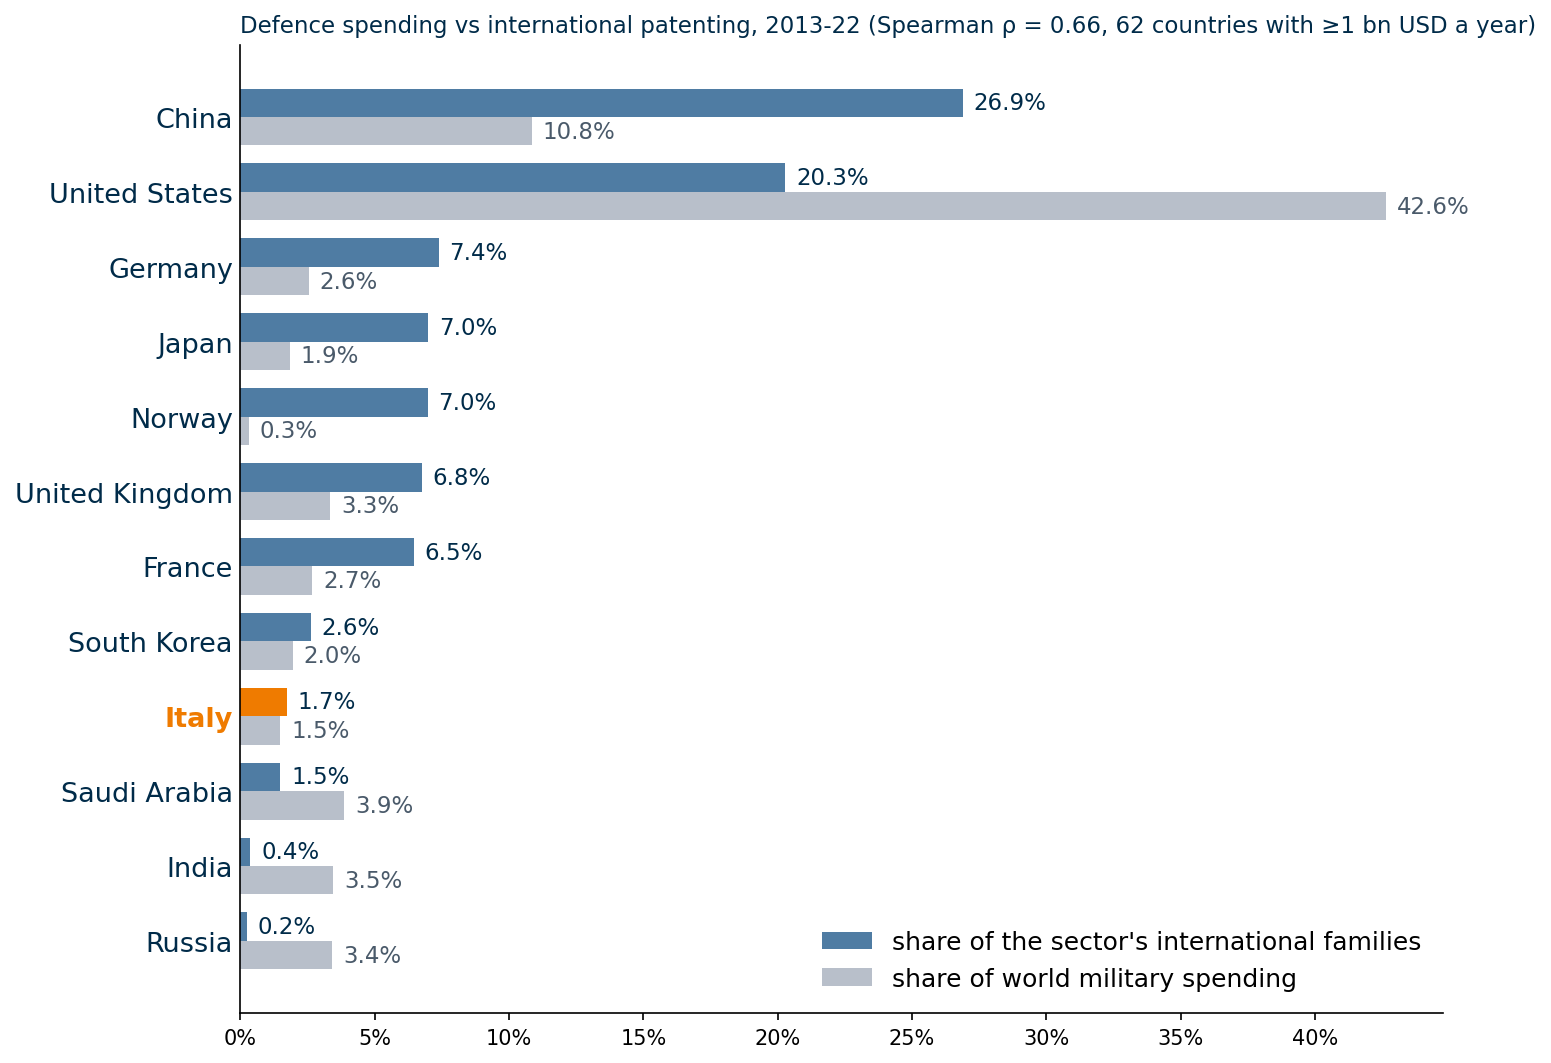

World military expenditure: 2,771 bn USD in 2025 (constant 2024 prices), +2.9% on 2024, +41% on 2015 [SIPRI].
Countries with ≥1 bn USD a year (62): Spearman correlation between military spending and the share of families 0.70 (all), 0.66 (international only).
Highest international families per bn USD: NO 0.82, PT 0.16, JP 0.15, NZ 0.12, NL 0.12


,military spending 2013-22 (bn USD 2024),share of world military spending,share of sector families,share of international families,families per bn USD,international families per bn USD,military spending growth 2015-2025,share of GDP 2025
US,"8,829",42.6%,4.3%,20.3%,0.04,0.018,10.8%,3.1%
CN,"2,244",10.8%,80.0%,26.9%,3.14,0.096,70.9%,1.7%
SA,801,3.9%,0.2%,1.5%,0.02,0.015,-19.7%,6.5%
IN,715,3.5%,0.2%,0.4%,0.02,0.004,52.9%,2.3%
RU,708,3.4%,2.3%,0.2%,0.28,0.003,110.6%,7.5%
GB,693,3.3%,0.9%,6.8%,0.11,0.078,32.0%,2.4%
FR,554,2.7%,0.7%,6.5%,0.11,0.094,20.9%,2.0%
DE,529,2.6%,0.8%,7.4%,0.13,0.112,127.7%,2.3%
KR,404,2.0%,6.2%,2.6%,1.34,0.052,33.8%,2.6%
JP,383,1.9%,1.4%,7.0%,0.33,0.147,60.0%,1.4%


In [75]:
if (EXT / "defence_spending.csv").exists():
    ms = pd.read_csv(EXT / "defence_spending.csv")
    WIN = (PAST[0], RECENT[1])                                    # 2013-2022: the complete years of the last decade
    w_ = ms[ms.iso2.eq("WORLD")].set_index("year")["milex_const2024_usd_m"] / 1000
    KEY["milex_world_2025_bn"] = float(w_.get(2025, np.nan)); KEY["milex_world_2024_bn"] = float(w_.get(2024, np.nan))
    KEY["milex_world_growth_2015_2025"] = float(w_.get(2025) / w_.get(2015) - 1)
    KEY["milex_world_growth_2024_2025"] = float(w_.get(2025) / w_.get(2024) - 1)
    mc = ms[ms.iso2.notna() & ms.iso2.ne("WORLD")]
    mil = mc[mc.year.between(*WIN)].groupby("iso2")["milex_const2024_usd_m"].sum() / 1000
    by_year = mc.pivot_table(index="iso2", columns="year", values="milex_const2024_usd_m")
    intl_ids = set(fam.loc[fam.is_international.astype(bool), "docdb_family_id"])
    a_win = appl[appl.family_year.between(*WIN)]
    f_all = a_win.groupby("country")["country_weight"].sum()
    f_int = a_win[a_win.docdb_family_id.isin(intl_ids)].groupby("country")["country_weight"].sum()
    dv = pd.DataFrame({f"military spending {WIN[0]}-{str(WIN[1])[2:]} (bn USD 2024)": mil,
                       "share of world military spending": mil / w_.loc[WIN[0]:WIN[1]].sum(),
                       "share of sector families": f_all / f_all.sum(),
                       "share of international families": f_int / f_int.sum(),
                       "families per bn USD": f_all.reindex(mil.index).fillna(0) / mil,
                       "international families per bn USD": f_int.reindex(mil.index).fillna(0) / mil,
                       "military spending growth 2015-2025": by_year.get(2025) / by_year.get(2015) - 1,
                       "share of GDP 2025": mc[mc.year.eq(2025)].set_index("iso2")["share_gdp"]}).dropna(subset=[f"military spending {WIN[0]}-{str(WIN[1])[2:]} (bn USD 2024)"])
    dv = dv.fillna({"share of sector families": 0, "share of international families": 0})
    dv = dv.sort_values(dv.columns[0], ascending=False)
    save_table(dv, "defence_spending_vs_patents")
    big = dv[dv.iloc[:, 0] >= 10]                                 # countries with at least 1 bn USD a year
    rho_all = big.iloc[:, 0].corr(big["share of sector families"], method="spearman")
    rho_int = big.iloc[:, 0].corr(big["share of international families"], method="spearman")
    KEY["spearman_milex_intl_families"] = float(rho_int)

    # bar chart: for each country, its share of world military spending next to its share of the sector's international
    # families (readable at a glance: bars of different length = a country patents more / less than it spends)
    NAMES = {"US": "United States", "CN": "China", "NO": "Norway", "JP": "Japan", "DE": "Germany", "FR": "France",
             "GB": "United Kingdom", "KR": "South Korea", "IT": "Italy", "IN": "India", "RU": "Russia", "SA": "Saudi Arabia",
             "NL": "Netherlands", "TW": "Taiwan", "AU": "Australia", "CA": "Canada", "TR": "Türkiye", "ES": "Spain",
             "IL": "Israel", "BR": "Brazil", "PL": "Poland", "UA": "Ukraine"}
    m_ = big["share of world military spending"] * 100
    p_ = big["share of international families"] * 100
    keep = list(dict.fromkeys(list(m_.sort_values(ascending=False).index[:6]) + list(p_.sort_values(ascending=False).index[:8])
                              + ["IT"] * ("IT" in big.index)))
    sel = pd.DataFrame({"m": m_[keep], "p": p_[keep]}).sort_values("p")
    fig, ax = plt.subplots(figsize=(10, 7.2))
    yy, hh = np.arange(len(sel)), 0.38
    ax.barh(yy + hh / 2, sel["p"], hh, color=[ORANGE if i == "IT" else BLUE for i in sel.index],
            label="share of the sector's international families")
    ax.barh(yy - hh / 2, sel["m"], hh, color="#b8bfca", label="share of world military spending")
    for k_, (a_, b_) in enumerate(zip(sel["p"], sel["m"])):
        ax.text(a_ + 0.4, k_ + hh / 2, f"{a_:.1f}%", va="center", fontsize=11, color=NAVY)
        ax.text(b_ + 0.4, k_ - hh / 2, f"{b_:.1f}%", va="center", fontsize=11, color=GREY)
    ax.set_yticks(yy)
    ax.set_yticklabels([NAMES.get(i, i) for i in sel.index], fontsize=13, color=NAVY)
    for t_, i in zip(ax.get_yticklabels(), sel.index):
        if i == "IT":
            t_.set_fontweight("bold"); t_.set_color(ORANGE)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.tick_params(axis="y", length=0)
    for sp_ in ("top", "right"):
        ax.spines[sp_].set_visible(False)
    ax.set_title(f"Defence spending vs international patenting, {WIN[0]}-{str(WIN[1])[2:]} (Spearman ρ = {rho_int:.2f}, "
                 f"{len(big)} countries with ≥1 bn USD a year)", fontsize=11, color=NAVY, loc="left")
    ax.legend(frameon=False, fontsize=12, loc="lower right")
    plt.tight_layout()
    save(fig, "s2_defence_vs_patents"); plt.show()
    print(f"World military expenditure: {KEY['milex_world_2025_bn']:,.0f} bn USD in 2025 (constant 2024 prices), "
          f"{KEY['milex_world_growth_2024_2025']:+.1%} on 2024, {KEY['milex_world_growth_2015_2025']:+.0%} on 2015 [SIPRI].")
    print(f"Countries with ≥1 bn USD a year ({len(big)}): Spearman correlation between military spending and the share of "
          f"families {rho_all:.2f} (all), {rho_int:.2f} (international only).")
    hi = big[big["international families per bn USD"] > 0].sort_values("international families per bn USD", ascending=False)
    print("Highest international families per bn USD:", ", ".join(f"{i} {v:.2f}" for i, v in hi["international families per bn USD"].head(5).items()))
    cols_pct = [c for c in dv.columns if "share" in c or "growth" in c]
    display(dv.head(18).style.format({c: "{:.1%}" for c in cols_pct} | {dv.columns[0]: "{:,.0f}", "families per bn USD": "{:.2f}",
                                                                          "international families per bn USD": "{:.3f}"}, na_rep="–"))
else:
    print(f"{EXT / 'defence_spending.csv'} not found: section skipped")

**Reading.** Bigger defence budgets go with more patenting in the sector (Spearman ρ printed above, on all and on
international families), but the intensity differs a lot and tells two stories:

- **inventor-exporters** have a patent bar longer than their spending bar: Norway (Kongsberg), Japan, Germany, France and the UK have a share of
  international families well above their share of military spending; China too, once only its international
  families are counted;
- **buyers** have a patent bar shorter than their spending bar: Saudi Arabia, India, Israel, Russia and, notably, the **United States**, with about 43% of
  world military spending but about a fifth of the international families. US defence R&D in this field is largely
  classified or done in-house by the Navy (secrecy, 1.5), so patent counts understate it.

For the client, **Italy** has a share of international families in line with its share of military spending, and a
budget that grew strongly over 2015-2025: a domestic demand driver for Fincantieri's underwater segment. Check the
numbers on the table after each re-run.

### 2.8.2 The PEST table

In [76]:
ai_share = (sub_t[sub_t.subclass.isin(["G06N", "G06V", "G06T", "G06F"])].groupby("family_year")["weight_tech"].sum()
            / sub_t.groupby("family_year")["weight_tech"].sum()).fillna(0)          # technologies only (no Y tags)
y02e = (sub[sub.subclass.eq("Y02E")].groupby("family_year")["weight"].sum() / sub.groupby("family_year")["weight"].sum()).fillna(0)
diversifiers = ", ".join(a.title()[:28] for a in players[players.status.eq("entrant") & players.index.str.contains("GRID|CNOOC|ARAMCO|THREE GORGES|HUANENG|CRRC|POWER")].index[:5]) or "none flagged"

def g_(key):
    """growth (%) of a CPC main group between the two windows (table of 2.4.1), or 'n/a'."""
    v = mapped["growth (%)"].get(key, np.nan)
    return f"{v:+.0f}%" if pd.notna(v) else "n/a"

def tg_(part):
    """growth (%) of the topic whose draft label contains `part` (table of 2.4.2), or 'n/a'."""
    k = next((i for i, n in topic_labels.items() if part.lower() in n.lower()), None)
    return f"{topic_labels[k]}: {tg.loc[k, 'growth (%)']:+.0f}%" if k is not None and pd.notna(tg.loc[k, "growth (%)"]) else "n/a"

ev_signal = {"AI / vision / computing share of the CPC mix (no Y), 2013-17 → 2018-22":
             f"{ai_share.loc[PAST[0]:PAST[1]].mean():.1%} → {ai_share.loc[RECENT[0]:RECENT[1]].mean():.1%}",
             "Energy (Y02E) tagging share, 2013-17 → 2018-22": f"{y02e.loc[PAST[0]:PAST[1]].mean():.1%} → {y02e.loc[RECENT[0]:RECENT[1]].mean():.1%}",
             "Oil & gas share (E21B, G01V, F16L), 2011-13 → 2020-22": f"{KEY['oil_gas_share_2011_2013']:.1%} → {KEY['oil_gas_share_2020_2022']:.1%}",
             "Families first filed in China": pct(KEY["share_first_filed_CN"]),
             "Share owned by universities (fractional)": pct(KEY["share_university"]),
             "SEP-exposed families (standardised telecom groups)": pct(KEY["sep_exposed_share"]),
             "US Navy / defence bodies among top owners": ", ".join([a.title()[:40] for a in players.index[:40] if re.search("NAVY|DEFEN|MILITARY|VOENN|DIRECTION GENERALE DE L ARMEMENT", a)])}
pest = pd.DataFrame([
    ("Political", f"Defence and naval spending; seabed-warfare and critical-infrastructure protection programmes (Nord Stream 2022); world military spending {KEY.get('milex_world_2025_bn', float('nan')):,.0f} bn USD in 2025, {KEY.get('milex_world_growth_2015_2025', float('nan')):+.0%} on 2015 (constant 2024 USD) [SIPRI Milex 2026]", "opportunity",
     f"US Navy second source of knowledge by PageRank (2.6.2); defence bodies among owners; Spearman ρ military spending vs international families {KEY.get('spearman_milex_intl_families', float('nan')):.2f} (2.8.1); secrecy limits patent visibility (1.5)"),
    ("Political", "Chinese industrial policy and patent subsidies; subsidies for filings ended in 2021 [Dang & Motohashi 2015; CNIPA]", "threat (competition) / bias (data)",
     "share first filed in China; low internationalisation of CN families (1.4); growth around the policy dates (1.1.1); no CN family granted at the EPO (2.2.4)"),
    ("Political", "Export controls and dual-use rules on UUVs (cat. 8A, EU Reg. 2021/821, Wassenaar) [EUR-Lex]", "threat", "few cross-bloc filings (1.4); home bias of knowledge flows and two separate citation communities (1.6.3, 2.6.2)"),
    ("Economic", f"Market of {KEY.get('market_2024_min', float('nan')):.1f}-{KEY.get('market_2024_max', float('nan')):.1f} bn USD (2024), forecast CAGR {KEY.get('market_cagr_min', float('nan')):.0%}-{KEY.get('market_cagr_max', float('nan')):.0%} [market reports, external_data]", "opportunity",
     "patent CAGR vs market forecasts (1.1.2)"),
    ("Economic", "Offshore energy (oil & gas decommissioning, offshore wind O&M) demand for inspection [Kanashiro et al. 2025]", "opportunity / shifting",
     f"oil & gas share falling after 2014 (1.1.1); Y02E share; diversifying energy entrants: {diversifiers}"),
    ("Economic", "Consolidation of the market: acquisitions of UUV makers by defence primes: Fincantieri–WASS 2025, NextGeo/WSense/Graal Tech/Defcomm 2026 [Fincantieri, Naval News]", "opportunity / threat",
     "group aliases in config; concentration trend (2.1.1); patent transactions (2.6.1)"),
    ("Social", "Safety: replacing divers in hazardous subsea work; ocean science and environmental monitoring [AAU review on subsea IMR automation]", "opportunity", f"B63C11/ underwater work and monitoring topics (2.4); SDG 14 {pct(KEY['sdg14_share'])}, any SDG {pct(KEY['sdg_any_share'])} of the families (1.7)"),
    ("Technological", "Autonomy and AI (navigation, path planning, perception); AUV the fastest-growing segment [BCC, MarketsandMarkets]", "opportunity",
     f"G05D1/ {g_('G05D1/')}, G06N3/ {g_('G06N3/')}; topic {tg_('path planning')}; white spaces of the client (2.7.3)"),
    ("Technological", "Underwater communication and energy (docking, charging, batteries) as bottlenecks; JANUS open standard since 2017 [NATO]", "opportunity",
     f"H02J7/ {g_('H02J7/')}; topic {tg_('docking')}; open standards, low SEP exposure (1.5.7)"),
], columns=["factor", "change [source: external_data/pest_sources.csv]", "opportunity / threat", "patent evidence in this notebook"])
# Stages 4 and 5 of the PEST analysis (Tutorial 1 nb 11 §5.4): prioritise the factors and derive the strategic action
# for the client. Priorities are the team's judgement (impact on Fincantieri's underwater business x evidence): discuss them.
PRIORITY_ACTION = [   # same order as the rows above
    ("high", "Position the underwater segment on navy and seabed-security programmes; partners and targets among the defence specialists with international patents (2.2.5, 2.7.2)"),
    ("medium", "Read Chinese volumes as domestic filing; watch only the internationalised Chinese players; CN-only families are no FTO risk in Europe"),
    ("high", "Prefer EU / NATO partners and targets; plan dual-use export licences for UUVs and their technology"),
    ("high", f"Size the investment on the {KEY.get('market_cagr_min', float('nan')):.0%}-{KEY.get('market_cagr_max', float('nan')):.0%} yearly market growth; give priority to the AUV segment, the fastest-growing"),
    ("medium", "Use NextGeo and offshore-wind inspection as the civil channel; follow the shift from oil & gas to offshore wind"),
    ("high", "Move on the remaining targets before the other primes; integrate the IP of WASS, Graal Tech and WSense (2.7.3)"),
    ("low", "Use safety and ocean-monitoring (SDG 14) arguments in dual-use positioning and public funding calls"),
    ("high", "Fill the white spaces in AI and data processing (G06N3/, G06F18/) through licences, partners or acquisitions (2.7.3)"),
    ("medium", "Build on WSense (underwater communication) and the open JANUS standard; low SEP exposure (1.5.7)"),
]
assert len(PRIORITY_ACTION) == len(pest), "one priority / action per PEST row"
pest["priority"] = [p_ for p_, _ in PRIORITY_ACTION]
pest["strategic action for the client"] = [a_ for _, a_ in PRIORITY_ACTION]
pest = pest.sort_values("priority", key=lambda s_: s_.map({"high": 0, "medium": 1, "low": 2}), kind="stable")
save_table(pest, "pest", index=False)
display(pd.Series(ev_signal, name="patent signals for the PEST").to_frame())
pest.style.hide(axis="index")

,patent signals for the PEST
"AI / vision / computing share of the CPC mix (no Y), 2013-17 → 2018-22",2.4% → 6.0%
"Energy (Y02E) tagging share, 2013-17 → 2018-22",1.0% → 1.2%
"Oil & gas share (E21B, G01V, F16L), 2011-13 → 2020-22",8.9% → 3.6%
Families first filed in China,73.5%
Share owned by universities (fractional),48.2%
SEP-exposed families (standardised telecom groups),2.2%
US Navy / defence bodies among top owners,Us Navy


factor,change [source: external_data/pest_sources.csv],opportunity / threat,patent evidence in this notebook,priority,strategic action for the client
Political,"Defence and naval spending; seabed-warfare and critical-infrastructure protection programmes (Nord Stream 2022); world military spending 2,771 bn USD in 2025, +41% on 2015 (constant 2024 USD) [SIPRI Milex 2026]",opportunity,US Navy second source of knowledge by PageRank (2.6.2); defence bodies among owners; Spearman ρ military spending vs international families 0.66 (2.8.1); secrecy limits patent visibility (1.5),high,"Position the underwater segment on navy and seabed-security programmes; partners and targets among the defence specialists with international patents (2.2.5, 2.7.2)"
Political,"Export controls and dual-use rules on UUVs (cat. 8A, EU Reg. 2021/821, Wassenaar) [EUR-Lex]",threat,"few cross-bloc filings (1.4); home bias of knowledge flows and two separate citation communities (1.6.3, 2.6.2)",high,Prefer EU / NATO partners and targets; plan dual-use export licences for UUVs and their technology
Economic,"Market of 4.2-5.1 bn USD (2024), forecast CAGR 8%-16% [market reports, external_data]",opportunity,patent CAGR vs market forecasts (1.1.2),high,"Size the investment on the 8%-16% yearly market growth; give priority to the AUV segment, the fastest-growing"
Economic,"Consolidation of the market: acquisitions of UUV makers by defence primes: Fincantieri–WASS 2025, NextGeo/WSense/Graal Tech/Defcomm 2026 [Fincantieri, Naval News]",opportunity / threat,group aliases in config; concentration trend (2.1.1); patent transactions (2.6.1),high,"Move on the remaining targets before the other primes; integrate the IP of WASS, Graal Tech and WSense (2.7.3)"
Technological,"Autonomy and AI (navigation, path planning, perception); AUV the fastest-growing segment [BCC, MarketsandMarkets]",opportunity,"G05D1/ +208%, G06N3/ +1722%; topic Path planning & obstacle avoidance: +314%; white spaces of the client (2.7.3)",high,"Fill the white spaces in AI and data processing (G06N3/, G06F18/) through licences, partners or acquisitions (2.7.3)"
Political,Chinese industrial policy and patent subsidies; subsidies for filings ended in 2021 [Dang & Motohashi 2015; CNIPA],threat (competition) / bias (data),share first filed in China; low internationalisation of CN families (1.4); growth around the policy dates (1.1.1); no CN family granted at the EPO (2.2.4),medium,Read Chinese volumes as domestic filing; watch only the internationalised Chinese players; CN-only families are no FTO risk in Europe
Economic,"Offshore energy (oil & gas decommissioning, offshore wind O&M) demand for inspection [Kanashiro et al. 2025]",opportunity / shifting,"oil & gas share falling after 2014 (1.1.1); Y02E share; diversifying energy entrants: State Grid (Sgcc), Crrc, China Huaneng Group, China Yangtze Power, Guangdong Power Grid",medium,Use NextGeo and offshore-wind inspection as the civil channel; follow the shift from oil & gas to offshore wind
Technological,"Underwater communication and energy (docking, charging, batteries) as bottlenecks; JANUS open standard since 2017 [NATO]",opportunity,"H02J7/ +296%; topic AUV docking & recovery: +285%; open standards, low SEP exposure (1.5.7)",medium,Build on WSense (underwater communication) and the open JANUS standard; low SEP exposure (1.5.7)
Social,Safety: replacing divers in hazardous subsea work; ocean science and environmental monitoring [AAU review on subsea IMR automation],opportunity,"B63C11/ underwater work and monitoring topics (2.4); SDG 14 4.7%, any SDG 26.9% of the families (1.7)",low,Use safety and ocean-monitoring (SDG 14) arguments in dual-use positioning and public funding calls


**The PEST table for the deck.** The same nine rows, as four columns of cards (colour = opportunity / threat for the client,
order = priority): the long table stays in `pest.csv`, the cards are what the audience reads.

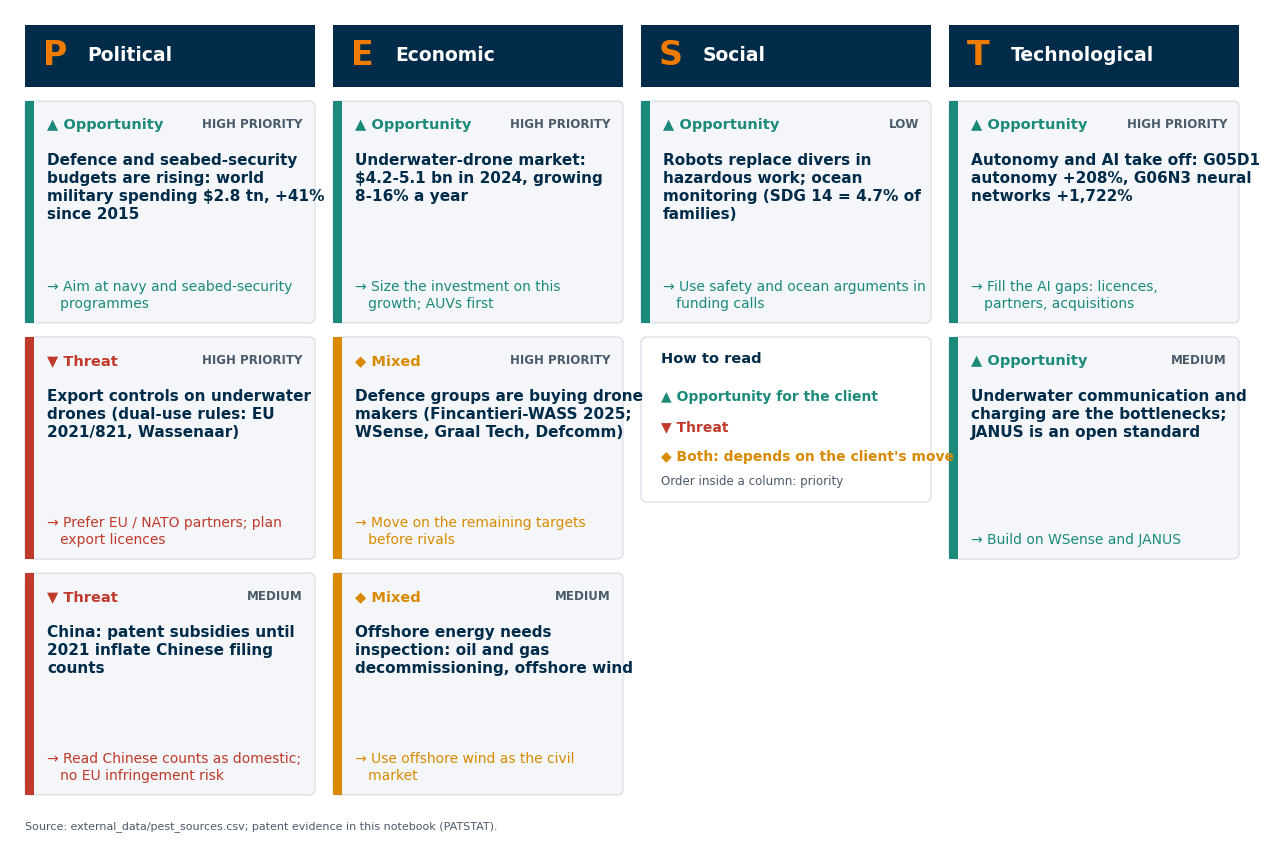

In [77]:
# Deck version of the PEST table: four columns, one card per factor (same rows, same order as the table above)
import textwrap
from matplotlib.patches import FancyBboxPatch, Rectangle
_short = [  # (headline, action) - plain-language version of the nine rows of the table, same order
    ("Defence and seabed-security budgets are rising: world military spending $2.8 tn, +41% since 2015",
     "Aim at navy and seabed-security programmes"),
    ("Export controls on underwater drones (dual-use rules: EU 2021/821, Wassenaar)",
     "Prefer EU / NATO partners; plan export licences"),
    ("Underwater-drone market: $4.2-5.1 bn in 2024, growing 8-16% a year",
     "Size the investment on this growth; AUVs first"),
    ("Defence groups are buying drone makers (Fincantieri-WASS 2025; WSense, Graal Tech, Defcomm)",
     "Move on the remaining targets before rivals"),
    ("Autonomy and AI take off: G05D1 autonomy +208%, G06N3 neural networks +1,722%",
     "Fill the AI gaps: licences, partners, acquisitions"),
    ("China: patent subsidies until 2021 inflate Chinese filing counts",
     "Read Chinese counts as domestic; no EU infringement risk"),
    ("Offshore energy needs inspection: oil and gas decommissioning, offshore wind",
     "Use offshore wind as the civil market"),
    ("Underwater communication and charging are the bottlenecks; JANUS is an open standard",
     "Build on WSense and JANUS"),
    ("Robots replace divers in hazardous work; ocean monitoring (SDG 14 = 4.7% of families)",
     "Use safety and ocean arguments in funding calls"),
]
assert list(pest["factor"]) == ["Political", "Political", "Economic", "Economic", "Technological", "Political", "Economic", "Technological", "Social"], \
    "the short texts follow the order of the table (sorted by priority): check them if the PEST rows change"
_col = {"Political": "P", "Economic": "E", "Social": "S", "Technological": "T"}
_full = {"Political": "Political", "Economic": "Economic", "Social": "Social", "Technological": "Technological"}
_c_opp, _c_thr, _c_mix = "#1B8A7A", "#C0392B", "#D98A00"
def _kind(s):
    s = str(s).lower()
    return ("Opportunity", _c_opp, "▲") if s.startswith("opportunity") and "/" not in s else \
           ("Threat", _c_thr, "▼") if s.startswith("threat") and "/" not in s.split("(")[0] else ("Mixed", _c_mix, "◆")
_pr = {"high": "HIGH PRIORITY", "medium": "MEDIUM", "low": "LOW"}
W, H = 12.4, 8.3
fig = plt.figure(figsize=(W, H)); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, W); ax.set_ylim(0, H); ax.axis("off")
colw, gap, x0, ytop = 2.9, 0.18, 0.15, H - 0.15
hh, ch, cg = 0.62, 2.22, 0.14
for j, f in enumerate(["Political", "Economic", "Social", "Technological"]):
    x = x0 + j * (colw + gap)
    ax.add_patch(Rectangle((x, ytop - hh), colw, hh, color=NAVY, lw=0))
    ax.text(x + 0.18, ytop - hh / 2, f[0], color=ORANGE, fontsize=24, fontweight="bold", va="center")
    ax.text(x + 0.62, ytop - hh / 2, f, color="white", fontsize=13.5, fontweight="bold", va="center")
    rows = [i for i in range(len(pest)) if pest["factor"].iloc[i] == f]
    rows.sort(key=lambda i: {"high": 0, "medium": 1, "low": 2}[str(pest["priority"].iloc[i]).lower()])
    for k, i in enumerate(rows):
        y = ytop - hh - cg - (k + 1) * ch - k * cg
        lab, c, sym = _kind(pest["opportunity / threat"].iloc[i])
        ax.add_patch(FancyBboxPatch((x, y), colw, ch, boxstyle="round,pad=0,rounding_size=0.06", fc="#F4F6F9", ec="#D5DAE2", lw=0.8))
        ax.add_patch(Rectangle((x, y), 0.09, ch, color=c, lw=0))
        ax.text(x + 0.22, y + ch - 0.17, f"{sym} {lab}", color=c, fontsize=10.5, fontweight="bold", va="top")
        ax.text(x + colw - 0.12, y + ch - 0.17, _pr[str(pest["priority"].iloc[i]).lower()], color=GREY, fontsize=8.5, fontweight="bold", va="top", ha="right")
        head, act = _short[i]
        ax.text(x + 0.22, y + ch - 0.52, "\n".join(textwrap.wrap(head, 27)), color=NAVY, fontsize=11, fontweight="bold", va="top", linespacing=1.25)
        ax.text(x + 0.22, y + 0.12, "→ " + "\n   ".join(textwrap.wrap(act, 30)), color=c, fontsize=10, va="bottom", linespacing=1.25)
_lx = x0 + 2 * (colw + gap); _ly = ytop - hh - cg - ch - cg - 1.65
ax.add_patch(FancyBboxPatch((_lx, _ly), colw, 1.65, boxstyle="round,pad=0,rounding_size=0.06", fc="white", ec="#D5DAE2", lw=0.8))
ax.text(_lx + 0.2, _ly + 1.5, "How to read", color=NAVY, fontsize=10.5, fontweight="bold", va="top")
for _n, (_t, _cc, _s) in enumerate([("Opportunity for the client", _c_opp, "▲"), ("Threat", _c_thr, "▼"), ("Both: depends on the client's move", _c_mix, "◆")]):
    ax.text(_lx + 0.2, _ly + 1.05 - _n * 0.3, f"{_s} {_t}", color=_cc, fontsize=10, fontweight="bold", va="center")
ax.text(_lx + 0.2, _ly + 0.14, "Order inside a column: priority", color=GREY, fontsize=8.5, va="bottom")
ax.text(x0, 0.08, "Source: external_data/pest_sources.csv; patent evidence in this notebook (PATSTAT).",
        fontsize=8, color=GREY, va="bottom")
save(fig, "s2_pest_cards"); plt.show()

## 3 · Robustness summary and exports

Every headline number on the three samples. If a conclusion holds on *all*, *without block-6-only* and
*international*, it does not depend on block 6 nor on domestic Chinese filing; if it changes, say so on the slide.

In [78]:
def headline(name, ids):
    f = fam[fam.docdb_family_id.isin(ids)]
    fc = f[f.family_year <= LAST]
    y = fc.groupby("family_year").size()
    l = links_c[links_c.docdb_family_id.isin(ids)]
    x = l.groupby("applicant")["docdb_family_id"].nunique()
    top = x.sort_values(ascending=False)
    t = l.groupby("type")["weight"].sum() / l["weight"].sum()
    return pd.Series({"families (≤2022)": len(fc), f"CAGR 2012-{LAST}": cagr(y.get(2012, np.nan), y.get(LAST, np.nan), LAST - 2012),
                      "first filed in CN": (fc.first_office == "CN").mean(), "university share": t.get("university", 0),
                      "firm share (incl. unclassified)": t.get("firm", 0) + t.get("unknown", 0),
                      "HH": herfindahl(x), "CR4": concentration_ratio(x, 4), "top applicant": top.index[0].title(),
                      "top non-CN firm": next((a.title() for a in top.index if a in firms.index and firms.loc[a, "country"] != "CN"), "–"),
                      "S-curve inflection": life.loc[name, "t0 (inflection year)"] if name in life.index else np.nan})
robust = pd.DataFrame({name: headline(name, ids) for name, ids in SAMPLES.items()}).T
robust.to_csv(OUT / "robustness_summary.csv")
robust.style.format({"families (≤2022)": "{:,.0f}", f"CAGR 2012-{LAST}": "{:.1%}", "first filed in CN": "{:.0%}", "university share": "{:.0%}",
                     "firm share (incl. unclassified)": "{:.0%}", "HH": "{:.4f}", "CR4": "{:.1%}", "S-curve inflection": "{:.1f}"})

,families (≤2022),CAGR 2012-2022,first filed in CN,university share,firm share (incl. unclassified),HH,CR4,top applicant,top non-CN firm,S-curve inflection
all,"9,934",19.9%,74%,48%,36%,0.0103,17.3%,Harbin Engineering University,Hanwha,2024.2
without block-6-only,"7,720",20.0%,72%,49%,36%,0.0111,17.7%,Harbin Engineering University,Hanwha,2023.4
international,"1,076",8.0%,17%,15%,63%,0.0036,7.7%,Tkms (Atlas Elektronik),Tkms (Atlas Elektronik),2020.9


In [79]:
for k, v in list(KEY.items()):
    KEY[k] = float(v) if isinstance(v, (np.floating, np.integer)) else v
(OUT / "key_numbers.json").write_text(json.dumps(KEY, indent=2))
for name, t in {"growth": growth, "life_cycle": life, "cpc_mix": cpc_mix, "cpc_shift": shift, "geography_owners_inventors": geo,
                "protection_profile": prot, "post_grant_events": post, "concentration": conc, "concentration_over_time": cons,
                "concentration_by_country": by_ctry, "entry_exit": ee, "rta_countries": rta_c, "rta_players": rta_a, "pest": pest}.items():
    t.to_csv(OUT / f"{name}.csv")
print(f"Saved {len(list(OUT.glob('*.csv')))} tables and {len(list(FIG.glob('*.png')))} figures in {OUT}")
pd.Series(KEY).to_frame("value")

Saved 30 tables and 45 figures in /home/jovyan/team-10-underwater-drones/outputs/prod/step2


,value
main_sample,all
families_block6_only,3786
growth_2000_last_pct_families_sector,3776.315789
families_total,15694
families_complete_years,9934
...,...
milex_world_2025_bn,2771.294151
milex_world_2024_bn,2692.307562
milex_world_growth_2015_2025,0.413269
milex_world_growth_2024_2025,0.029338


**Consistency checks** between the inputs, the configuration and the results: every line must be True, otherwise the
notebook stops here.

In [80]:
checks = {
    "one row per family": fam["docdb_family_id"].is_unique,
    "truncated flag matches LAST_COMPLETE_YEAR": bool((fam["family_year"] > LAST).eq(fam["is_truncated"]).all()),
    "every application belongs to a listed family": bool(apps["docdb_family_id"].isin(fam["docdb_family_id"]).all()),
    "applicant weights sum to 1 per family": bool(np.allclose(appl.groupby("docdb_family_id")["weight"].sum(), 1)),
    "CPC mix (families) sums to 100%": bool(np.isclose(cpc_mix["families · all"].sum(), 1)),
    "first-office shares sum to 100%": bool(np.isclose(office_tab.loc["Total", "% of families, by first office"], 100)),
    "application-level office shares sum to 100%": bool(np.isclose(office_tab.loc["Total", "% of applications"], 100)),
    "sample sizes are nested": SAMPLES["without block-6-only"] <= SAMPLES["all"] and SAMPLES["international"] <= SAMPLES["all"],
    "HH and CR4 in (0, 1]": 0 < KEY["HH_all"] <= 1 and 0 < KEY["CR4_all"] <= 1,
    "all concentration windows are full": bool(cons["window"].map(lambda w_: int(w_.split("-")[1]) - int(w_.split("-")[0]) + 1).eq(WINDOW).all()),
    "one row per applicant group in players": bool(players.index.is_unique),
    "shortlist includes the client (when it patents in the sector)": CLIENT in shortlist.index or CLIENT not in players.index,
    "shortlist firms meet the volume gate (or client)": bool(((shortlist["families"] >= MIN_FAMILIES_SCORE) | shortlist["is client"]).all()),
    "entrants' share in [0, 100]": bool(ee["entrants' share of families (%)"].dropna().between(0, 100).all()),
}
display(pd.Series(checks, name="ok").to_frame())
assert all(checks.values()), "a check failed: see the table above"
print(f"tables for the appendix: {len(list(TAB.glob('*.csv')))} in {TAB}; figures: {len(list(FIG.glob('*.png')))} in {FIG}")

,ok
one row per family,True
truncated flag matches LAST_COMPLETE_YEAR,True
every application belongs to a listed family,True
applicant weights sum to 1 per family,True
CPC mix (families) sums to 100%,True
first-office shares sum to 100%,True
application-level office shares sum to 100%,True
sample sizes are nested,True
"HH and CR4 in (0, 1]",True
all concentration windows are full,True


tables for the appendix: 40 in /home/jovyan/team-10-underwater-drones/outputs/prod/step2/tables; figures: 45 in /home/jovyan/team-10-underwater-drones/outputs/prod/step2/figures


### Which figures go in the deck (≤ 10 figures and tables in the whole main deck)

A suggestion for Steps 1–2 (four or five slots, the rest of the deck needs the others); everything else goes in the
technical appendix.

| Slot | Figure / table | File |
|---|---|---|
| Step 1 · size and growth | families per year with truncation shaded + growth index vs all patents and B63 | `s1_volume.png`, `s1_growth_vs_benchmarks.png` (one combined panel) |
| Step 1 · technology | CPC mix over time + table of top subclasses with official titles | `s1_cpc_mix_over_time.png`, `cpc_mix.csv` |
| Step 1 · appropriability | origin & internationalisation + market leaders vs patent leaders (in the argued paragraph) | `s1_origin_internationalisation.png` |
| Step 2 · competition | top players table (firms outside China + universities) + concentration and entry over time | `players_all.csv`, `s2_concentration_over_time.png`, `s2_entry_exit.png` |
| Step 2 · subfields | growth map / maturity matrix | `s2_subfield_growth_maturity.png` |
| Step 2 · PEST | the PEST table (mandatory) | `pest.csv` |
| Step 1 · SDG | technologies inside each goal (bubbles) + Innovation Maturity Matrix | `s1_sdg_technologies.png`, `s1_sdg_maturity_matrix.png` |
| Step 1 · spillovers | country localisation test (observed vs JTH control vs chance) + who cites whom | `s1_spillovers_country.png`, `1_6_knowledge_flows.png` |

Growth, origin and subfield figures are drawn with stacked panels so they fit the half-slide frame of the deck.

## 4 · To state in the technical appendix

- *Unit*: DOCDB family (one invention = one count), dated by its earliest priority year; the application level counts
  every filing at its office by filing year. Every figure and table says which level it shows.
- *Truncation*: the years after `LAST_COMPLETE_YEAR` (2022) are incomplete (18-month publication lag plus the delay
  in PATSTAT): shaded in every figure and excluded from every growth figure and share. The sector, dominated by Chinese
  filings, is truncated less than the benchmarks, so its share of all patents in those years is inflated. The
  *international* flag needs the second filing: its last years are certainly incomplete.
- *Fractional counting*: CPC subclasses, WIPO fields, applicants and inventors split a family equally, so each family
  sums to 1 (countries: only entities with a known country).
- *Benchmarks*: all patents and CPC B63, same rules (patents of invention only, dummy applications excluded).
- *Y tagging section* left out of the technology mix (`weight_tech`); 2000-series indexing codes left out of the
  subfields, except B63G2008/.
- *Country*: filled with the filing office when missing; applicant and inventor countries are therefore not
  independent (1.4); "stated only" columns use only declared countries.
- *Applicant type*: the profile of `02_clean`, else the most frequent known type of each harmonised group; the client
  group is a firm. Corporate groups: `config.GROUP_ALIASES`, re-applied in Section 0.1.
- *Sector*: Step 0 definition (rule blocks 1-6, exclusions, hand-label corrections); precision and recall with their
  intervals are in the Step 0 appendix. Block 6 is kept and tested in the *without block-6-only* sample.
- *S-curve*: logistic fit on cumulative complete years; fit quality on annual counts; `K` is not interpreted.
- *Patents vs secrecy*: triangulation (owner types, protection sought, opposition with its confidence interval, market
  leaders) plus the literature; not directly measurable from patent data.
- *Legal events*: INPADOC coverage differs by office (almost no renewals or transfers for China): post-grant counts are
  lower bounds; renewal fees are not compared across origins.
- *Not available in PATSTAT*: full text of claims and description, SEP declarations, regions and cities for Chinese
  applicants, most national litigation.
- *Company financials*: EU Industrial R&D Investment Scoreboard (JRC, panel 2003-2024, open data) plus annual reports
  and 10-K filings for the firms it does not cover, used **instead of Orbis** (Bureau van Dijk); see 2.2.5.
- *Known-item recall*: computed in PATSTAT (Step 0, `01_extract` §7.7) on the market leaders' own underwater families,
  used **instead of Orbit** for the recall check on flagship products.
- *External data* (not PATSTAT): market size and forecasts, market players, event dates, PEST sources, IP-system facts
  and group ownership are in `external_data/*.csv`, each row with source, link and access date; the cell below lists
  them for the appendix. Market reports are commercial estimates (free summaries only): we report ranges.

In [81]:
if EXT.exists():
    src_list = []
    for f_ in sorted(EXT.glob("*.csv")):
        d_ = pd.read_csv(f_)
        if {"source", "url"} <= set(d_.columns):
            src_list.append(d_[["source", "url"]].assign(file=f_.name, accessed=d_.get("accessed")))
    if src_list:
        src_list = pd.concat(src_list).dropna(subset=["source"]).drop_duplicates(["source", "url"])
        save_table(src_list, "external_sources", index=False)
        print(f"{len(src_list)} external sources in {EXT}")
        display(src_list.reset_index(drop=True))

55 external sources in /home/jovyan/team-10-underwater-drones/external_data


,source,url,file,accessed
0,"SIPRI Military Expenditure Database, v1.2 (2026 release)",https://www.sipri.org/databases/milex,defence_spending.csv,2026-11-22
1,"State Council of the PRC, Outline of the National Intell...",https://www.wipo.int/wipolex/en/legislation/details/859,events.csv,2026-11-23
2,"Ball (2016), The Fed and Lehman Brothers, NBER WP 22410",https://www.nber.org/papers/w22410,events.csv,2026-11-23
3,"U.S. EIA, Today in Energy",https://www.eia.gov/todayinenergy/detail.php?id=19451,events.csv,2026-11-23
4,IEA policy database,https://www.iea.org/policies/15670-made-in-china-2025,events.csv,2026-11-22
5,NATO,https://www.nato.int/cps/en/natohq/news_143247.htm,events.csv,2026-11-22
6,Fugro,https://fugro.com/news/press-releases/2019/fugro-becomes...,events.csv,2026-11-22
7,"WHO Director-General, media briefing 11 March 2020",https://www.who.int/news-room/speeches/item/who-director...,events.csv,2026-11-23
8,CNIPA (via CSET translation),https://cset.georgetown.edu/publication/notice-of-the-ch...,events.csv,2026-11-22
9,SEC prospectus Technip Energies,https://www.sec.gov/Archives/edgar/data/1792045/00011403...,events.csv,2026-11-22
